In [16]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import os
from matplotlib.lines import Line2D
from matplotlib.backends.backend_pdf import PdfPages

In [2]:
# ── Short label helper ──────────────────────────────────────────────────────
def short(col):
    return (col.replace("rating_", "").replace("tight_", "t:")
            .replace("pain_", "p:").replace("med_", "m:")
            .replace("min_cat_", "").replace("flag_", "f:")
            .replace("_", " ").title())

In [3]:
# ── Disease-specific configurations ─────────────────────────────────────────
ASTHMA_CONFIG = {
    "disease": "Asthma",
    "rating_cols": [
        "rating_sleep_quality", "rating_breathlessness", "rating_cough",
        "rating_chest_tightness", "rating_pain", "rating_allergies", "rating_mood",
    ],
    "severity_col": "tight_severity_wmean",
    "severity_label": "Chest Tightness (weighted severity)",
    "minutes_col": "tight_minutes_moderate_plus",
    "minutes_label": "Minutes at Moderate+ Tightness",
    "ts_panels": [
        ("tight_severity_wmean", "Chest Tightness (wtd)", "#D9534F"),
        ("rating_mood", "Mood Rating", "#5B6ABF"),
        ("med_ventolin", "Ventolin Puffs", "#5CB85C"),
        ("rating_allergies", "Allergies Rating", "#F0AD4E"),
    ],
    "episode_metrics": [
        ("tight_severity_wmean", "Chest Tightness (weighted)"),
        ("rating_breathlessness", "Breathlessness Rating"),
        ("rating_cough", "Cough Rating"),
        ("rating_allergies", "Allergies Rating"),
    ],
    "med_cols": ["med_ventolin", "med_seretide", "med_piriton", "med_avamys"],
    "wearable_cols": ["m_steps", "sleep_hours", "rhr"],
    "colors": ['#4A90D9', '#D9534F', '#5CB85C', '#F0AD4E',
               '#9B59B6', '#E67E22', '#1ABC9C'],
}

In [4]:
IBD_CONFIG = {
    "disease": "IBD",
    "rating_cols": [
        "rating_abdominal_pain", "rating_ability_to_function", "rating_diet",
        "rating_fatigue", "rating_sleep", "rating_stress", "rating_toilet_use",
    ],
    "severity_col": "pain_severity_wmean",
    "severity_label": "Pain Severity (weighted)",
    "minutes_col": "pain_minutes_symptomatic",
    "minutes_label": "Minutes Symptomatic",
    "ts_panels": [
        ("pain_severity_wmean", "Pain Severity (wtd)", "#D9534F"),
        ("rating_abdominal_pain", "Abdominal Pain", "#5B6ABF"),
        ("rating_fatigue", "Fatigue Rating", "#F0AD4E"),
        ("rating_toilet_use", "Toilet Use Rating", "#5CB85C"),
    ],
    "episode_metrics": [
        ("pain_severity_wmean", "Pain Severity (weighted)"),
        ("rating_abdominal_pain", "Abdominal Pain Rating"),
        ("rating_toilet_use", "Toilet Use Rating"),
        ("rating_fatigue", "Fatigue Rating"),
    ],
    "med_cols": ["med_biological", "med_steroids", "med_otc_pain_medication",
                 "med_hot_water_bottle"],
    "wearable_cols": [],
    "colors": ['#4A90D9', '#D9534F', '#5CB85C', '#F0AD4E',
               '#9B59B6', '#E67E22', '#1ABC9C'],
}

In [12]:
def check_data_sufficiency(m, rating_cols, med_cols, act_cols, config):
    """Check what sections can be generated and what needs more data."""
    n_days = len(m)
    rating_completeness = m[rating_cols].notna().mean().mean() * 100
    n_rated_days = m[rating_cols[0]].notna().sum()
    n_notes = int(m["n_notes"].sum()) if "n_notes" in m.columns else 0
    active_meds = [c for c in med_cols if m[c].sum() > 0]
    sev_days = m[config["severity_col"]].notna().sum()

    print("\n  DATA SUFFICIENCY CHECK:")
    print("  " + "─" * 50)

    sections = {}

    # Symptom scores — need at least 7 rated days
    if n_rated_days >= 7:
        sections["symptoms"] = True
        print(f"    ✓ Symptom scores: {n_rated_days} rated days (minimum 7)")
    else:
        sections["symptoms"] = False
        print(f"    ✗ Symptom scores: only {n_rated_days} rated days — "
              f"need at least 7 for a meaningful summary. "
              f"Try to rate your symptoms every evening, even briefly.")

    # Episode detection — need at least 14 days with severity data
    if sev_days >= 14:
        sections["episodes"] = True
        print(f"    ✓ Episode detection: {sev_days} days with severity data (minimum 14)")
    else:
        sections["episodes"] = False
        print(f"    ✗ Episode detection: only {sev_days} days — "
              f"need at least 14 to distinguish episodes from normal variation.")

    # Correlations — need at least 15 complete days
    complete_days = m[rating_cols].dropna().shape[0]
    if complete_days >= 15:
        sections["correlations"] = True
        print(f"    ✓ Symptom correlations: {complete_days} complete days (minimum 15)")
    else:
        sections["correlations"] = False
        print(f"    ✗ Symptom correlations: only {complete_days} complete days — "
              f"need at least 15. Completing all ratings each day helps most here.")

    # Lag analysis — need at least 20 days
    if n_rated_days >= 20:
        sections["lags"] = True
        print(f"    ✓ Time-lagged effects: {n_rated_days} days (minimum 20)")
    else:
        sections["lags"] = False
        print(f"    ✗ Time-lagged effects: only {n_rated_days} days — "
              f"need at least 20 to detect delayed patterns.")

    # Intervention effectiveness — need at least 2 interventions used on 3+ days
    meds_with_data = [c for c in active_meds if (m[c] > 0).sum() >= 3]
    if len(meds_with_data) >= 1:
        sections["interventions"] = True
        print(f"    ✓ Intervention analysis: {len(meds_with_data)} interventions "
              f"used on 3+ days")
    else:
        sections["interventions"] = False
        print(f"    ✗ Intervention analysis: not enough intervention data — "
              f"log each medication, hot water bottle, or remedy when you use it.")

    # Free text — just informational
    if n_notes >= 5:
        print(f"    ✓ Free-text notes: {n_notes} notes logged")
    else:
        print(f"    ℹ Free-text notes: only {n_notes} this period. Adding short notes "
              f"about what you tried and how you felt helps identify what works for you.")

    # Overall guidance
    if rating_completeness < 50:
        print(f"\n    ⚠ OVERALL: Rating completeness is only {rating_completeness:.0f}%. "
              f"You get the most useful report when you rate symptoms on at least "
              f"70% of days. Even a 30-second rating on a bad day is valuable.")

    print("  " + "─" * 50)
    return sections

Necessity for data sufficiency checks:
- Symptom scores (minimum 7 days): Since we are computing a mean its important that I compute for at least a week in order to avoid the chances of an outlier from dramatically shifting the average. For example, if only 3 days are logged and one is a flare-up, it appears that for 33% of the days in the month the symptom was severe, which is not accurate and can be misinterpreted. 7 days shows a full week's variation capturing both the weekdays and the weekend, showing a more meaningful average.
- Episode detection (minimum 14 days): Episodes have been defined as days exceeding the user's baseline by 1.5 standard deviations. To use this method we require enough data points so that the standard deviation does not drastically change when a day is added or removed. 14 days is roughly enough to ensure that this change does not occur.
- Correlations (minimum 15 days): Spearman correlation with fewer than 15 paired observations does not have strong statistical power. It is a good idea for the
researcher to have at least ten pairs of data to use for the analysis: any fewer than this and the result will be highly insignificant and more likely to be as a result of chance than of true correlation ref: https://www.rgs.org/media/armb00er/a-guide-to-spearmans-rank.pdf. For this reason a minimum of 15 days was chosen so that the correlations have stronger statistical power.
- Lag analysis (minimum 20 days): Since each lag causes us to lose data points (ie. lag-1 drops one day, lag-2 drops 2 etc.), starting from 20 days means that our lag-3 analysis runs on 17 observations. This sample size is sufficient for detecting strong associations, however it must be noted that this is not very powerful for detecting effects below $ρ≈0.5$
- Interventions (minimum 3-days of use): The Mann-Whitney U test compares two groups. If someone used a hot water bottle on only 1 or 2 days, there's no way to tell whether the symptom score on those days was different by chance or because of the intervention. Three is the absolute minimum for a comparison to have any meaning at all — and even then the results should be treated as preliminary. (rewrite interventions)


In [22]:
# MONTHLY REPORT GENERATOR
# =========================================================================
def generate_monthly_report(master, month_str, config, output_dir="outputs",
                            full_master=None):
    """
    Generate a full set of report plots for a single month.

    Parameters:
        master:      full daily master DataFrame
        month_str:   e.g. "2016-05" or "2020-07"
        config:      ASTHMA_CONFIG or IBD_CONFIG
        output_dir:  where to save PNGs
        full_master: if provided, used to calculate overall baselines for
                     comparison (defaults to master)
    """
    os.makedirs(output_dir, exist_ok=True)
    if full_master is None:
        full_master = master

    disease = config["disease"]
    rating_cols = [c for c in config["rating_cols"] if c in master.columns]
    med_cols = [c for c in config["med_cols"] if c in master.columns]
    act_cols = [c for c in master.columns if c.startswith("min_cat_")]

    start_date = master["date"].min().normalize()
    end_date = master["date"].max().normalize()

    n_periods = ((end_date - start_date).days // 30) + 1

    for period_num in range(n_periods):
        window_start = start_date + pd.Timedelta(days=30 * period_num)
        window_end = window_start + pd.Timedelta(days=30)

        m = master[(master["date"] >= window_start) &
               (master["date"] < window_end)].copy()

        if m.empty:
            continue

        period_label = f"{window_start:%d %b %Y} - {(window_end - pd.Timedelta(days=1)):%d %b %Y}"
        prefix = f"{disease.lower()}_period_{period_num:02d}"

        print("=" * 70)
        print(f"30-DAY REPORT — {disease}")
        print(f"This report is for the period - {window_start.strftime('%d %b %Y')} to {window_end.strftime('%d %b %Y')}")
        print(f"Rating completeness: {m[rating_cols].notna().mean().mean()*100:.0f}%")
        print("=" * 70)

        sufficiency = check_data_sufficiency(m, rating_cols, med_cols, act_cols, config)


        # ── 2. SYMPTOM SCORES BAR CHART ─────────────────────────────────────
        means = m[rating_cols].mean().sort_values(ascending=False)

        fig, ax = plt.subplots(figsize=(10, 6))
        
        colors_bar = [config["colors"][i % len(config["colors"])]
                      for i in range(len(means))]
        
        bars = ax.bar(
            range(len(means)),
            means.values,
            color=colors_bar,
            edgecolor="white"
        )
        
        ax.set_xticks(range(len(means)))
        ax.set_xticklabels(
            [short(c) for c in means.index],
            rotation=45,
            ha="right",
            fontsize=10
        )
        
        ax.set_ylabel("Mean Score (0 = best, 10 = worst)")
        ax.set_title(f"{disease} — Symptom Scores for {period_label}", fontsize=14)
        ax.set_ylim(0, 10)

        
        plt.tight_layout()
        plt.savefig(f"{output_dir}/{prefix}_symptoms.png", dpi=150)
        plt.show()

        print("=" * 70)
        top3 = means.head(3)

        items = [f"{short(symptom)} ({score:.1f})"
                 for symptom, score in top3.items()]
        
        summary = ", ".join(items[:-1]) + f", and {items[-1]}"
        print(f"Symptoms with the highest scores in this period were {summary}.")
        print("=" * 70)
        

        # ── 3. EPISODE DETECTION ────────────────────────────────────────────
        if sufficiency["episodes"]:
        
            episode_metrics = [(c, l) for c, l in config["episode_metrics"]
                               if c in m.columns]
        
            if episode_metrics:
                fig, axes = plt.subplots(len(episode_metrics), 1,
                                         figsize=(12, 3.5 * len(episode_metrics)),
                                         sharex=True)
                if len(episode_metrics) == 1:
                    axes = [axes]
                fig.suptitle(f"{disease} — Episode Detection for {period_label}",
                             fontsize=14, y=1.01)
        
                total_episodes = 0
                for ax, (col, title) in zip(axes, episode_metrics):
                    # Thresholds from FULL dataset (the person's overall baseline)
                    full_vals = full_master[col].dropna()
                    mean = full_vals.mean()
                    std = full_vals.std()
                    threshold = mean + 1.5 * std
        
                    ax.plot(m["date"], m[col], color="#4A90D9", linewidth=1, alpha=0.7,
                            label="Daily value")
                    ax.axhline(mean, color="green", linestyle="-", linewidth=1,
                               label=f"Mean: {mean:.2f}")
                    ax.axhline(threshold, color="red", linestyle="--", linewidth=1,
                               label=f"Threshold: {threshold:.2f}")
        
                    episodes = m[m[col] > threshold]
                    total_episodes += len(episodes)
                    ax.scatter(episodes["date"], episodes[col], color="red", s=50,
                               zorder=5, label=f"Episodes: {len(episodes)} days")
        
                    ax.set_ylabel(title, fontsize=9)
                    ax.legend(loc="upper right", fontsize=8)
                    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
        
                plt.xlabel("Date")
                plt.tight_layout()
                plt.savefig(f"{output_dir}/{prefix}_episodes.png", dpi=150)
                plt.show()
        
                print(f"  Total episode days this month: {total_episodes}")
    
            # Print flare dates
                all_episode_days = set()
                for col, title in episode_metrics:
                    full_vals = full_master[col].dropna()
                    th = full_vals.mean() + 1.5 * full_vals.std()
                    ep = m[m[col] > th]
                    for _, row in ep.iterrows():
                        all_episode_days.add((row["date"], row["weekday"]))
    
                if all_episode_days:
                    sorted_eps = sorted(all_episode_days, key=lambda x: x[0])
                    dates_str = ", ".join(f"{d.strftime('%d %b')} ({wd})" for d, wd in sorted_eps)
                    print(f"\n  FLARES OCCURRED ON: {dates_str}")
                else:
                    print(f"\n  No flares detected in this period")
            
            composite_month = m[rating_cols].mean(axis=1)
            worst_day = m.loc[composite_month.idxmax(), "date"] if composite_month.notna().any() else None
            best_day = m.loc[composite_month.idxmin(), "date"] if composite_month.notna().any() else None
            print(f"Worst day in this period: {worst_day.strftime('%d %b') if worst_day is not None else 'N/A'} (composite {composite_month.max():.1f}/10)")
            print(f"Best day in this period:  {best_day.strftime('%d %b') if best_day is not None else 'N/A'} (composite {composite_month.min():.1f}/10)")
        
        else:
            print(f"\n  Episode detection skipped — not enough data this period.")
    
        # ── 3. DAILY TIME SERIES ────────────────────────────────────────────
        ts_panels = [(c, l, clr) for c, l, clr in config["ts_panels"]
                     if c in m.columns]
    
        if ts_panels:
            fig, axes = plt.subplots(len(ts_panels), 1,
                                     figsize=(12, 3.5 * len(ts_panels)), sharex=True)
            if len(ts_panels) == 1:
                axes = [axes]
            fig.suptitle(f"{disease} — Daily Trends for {period_label}",
                         fontsize=14, y=1.01)
    
            for ax, (col, title, color) in zip(axes, ts_panels):
                vals = m[col].dropna()
                ax.bar(m.loc[vals.index, "date"], vals, alpha=0.4, color=color, width=1)
                # Rolling average (3-day for monthly view)
                rolling = m[col].rolling(3, min_periods=2).mean()
                ax.plot(m["date"], rolling, color=color, linewidth=2, label="3-day avg")
                # Overall baseline
                overall = full_master[col].mean()
                ax.axhline(overall, color="grey", linestyle="--", linewidth=1,
                           label=f"Overall avg: {overall:.2f}")
                ax.set_ylabel(title, fontsize=9)
                ax.legend(loc="upper right", fontsize=8)
                ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

            plt.xlabel("Date")
            plt.tight_layout()
            plt.savefig(f"{output_dir}/{prefix}_timeseries.png", dpi=150)
            plt.show()

        print("")
    


        # ── 4. ACTIVITY BREAKDOWN (this period vs overall) ──────────────────
        if act_cols:
            fig, axes = plt.subplots(1, 2, figsize=(16, 7))
            fig.suptitle(f"{disease} — Activity Breakdown: This Period vs Overall",
                         fontsize=14)

            for ax, (data, label) in zip(axes, [
                (m, f"This Period ({period_label})"),
                (full_master, "Overall Average"),
            ]):
                cat_hours = data[act_cols].mean().div(60)
                cat_hours.index = [c.replace("min_cat_", "").replace("_", " ").title()
                                   for c in act_cols]
                cat_hours = cat_hours[cat_hours > 0.1]

                wedges, texts, autotexts = ax.pie(
                    cat_hours.values,
                    labels=cat_hours.index,
                    autopct=lambda pct: f"{pct:.1f}%\n({pct/100 * cat_hours.sum():.1f}h)" if pct > 3 else "",
                    colors=config["colors"][:len(cat_hours)],
                    startangle=90,
                    wedgeprops={"edgecolor": "white", "linewidth": 1.5},
                )
                for text in autotexts:
                    text.set_fontsize(8)
                ax.set_title(label, fontsize=11)

            plt.tight_layout()
            plt.savefig(f"{output_dir}/{prefix}_activity.png", dpi=150)
            plt.show()
    
    
        # ── 5. CORRELATION HEATMAP ──────────────────────────────────────────
        if sufficiency["correlations"]:
            corr_cols = rating_cols.copy()
            if config["severity_col"] in m.columns:
                corr_cols.append(config["severity_col"])
    
            corr_data = m[corr_cols].dropna()
            if len(corr_data) >= 10:
                corr = corr_data.corr(method="spearman")
                labels = [short(c) for c in corr_cols]
    
                fig, ax = plt.subplots(figsize=(9, 8))
                im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
                ax.set_xticks(range(len(labels)))
                ax.set_yticks(range(len(labels)))
                ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=9)
                ax.set_yticklabels(labels, fontsize=9)
                for i in range(len(corr)):
                    for j in range(len(corr)):
                        val = corr.iloc[i, j]
                        ax.text(j, i, f"{val:.2f}", ha="center", va="center",
                                fontsize=7, color="white" if abs(val) > 0.4 else "black")
                ax.set_title(f"{disease} — Symptom Correlations for {period_label}",
                             fontsize=13)
                plt.colorbar(im, shrink=0.8)
                plt.tight_layout()
                plt.savefig(f"{output_dir}/{prefix}_correlations.png", dpi=150)
                plt.show()
    
                # Highlight strongest correlations
                pairs = []
                for i in range(len(corr_cols)):
                    for j in range(i + 1, len(corr_cols)):
                        pairs.append({
                            "symptom_1": corr_cols[i],
                            "symptom_2": corr_cols[j],
                            "rho": corr.iloc[i, j],
                        })
                pairs_df = pd.DataFrame(pairs).sort_values("rho", key=abs, ascending=False)
    
                print(f"\n  STRONGEST SYMPTOM CORRELATIONS THIS PERIOD:")
                top_pairs = pairs_df.head(5)
                for _, row in top_pairs.iterrows():
                    direction = "move together" if row["rho"] > 0 else "move inversely"
                    strength = "strongly" if abs(row["rho"]) > 0.5 else "moderately"
                    print(f"    {short(row['symptom_1']):20s} ↔ {short(row['symptom_2']):20s}  "
                          f"ρ={row['rho']:+.3f}  ({strength} {direction})")
    
                # Check if any pairs are notably different from overall
                overall_corr = full_master[corr_cols].dropna().corr(method="spearman")
                print(f"\n  NOTABLE CHANGES FROM OVERALL PATTERN:")
                changed = False
                for _, row in pairs_df.iterrows():
                    i = corr_cols.index(row["symptom_1"])
                    j = corr_cols.index(row["symptom_2"])
                    overall_val = overall_corr.iloc[i, j]
                    diff = row["rho"] - overall_val
                    if abs(diff) > 0.25:
                        changed = True
                        direction = "stronger" if abs(row["rho"]) > abs(overall_val) else "weaker"
                        print(f"    {short(row['symptom_1']):20s} ↔ {short(row['symptom_2']):20s}  "
                              f"this period={row['rho']:+.3f}  overall={overall_val:+.3f}  "
                              f"({direction} this period)")
                if not changed:
                    print(f"    Symptom relationships were consistent with the overall pattern")
            else:
                print(f"  Insufficient data for correlation heatmap ({len(corr_data)} days)")


        # ── 6. MEDICATION USAGE ─────────────────────────────────────────────
        active_meds = [c for c in med_cols if m[c].sum() > 0]
        if active_meds:
            fig, ax = plt.subplots(figsize=(10, 5))
            med_means = m[active_meds].mean().sort_values(ascending=False)
            overall_med = full_master[active_meds].mean()

            colors_med = [config["colors"][i % len(config["colors"])]
                          for i in range(len(med_means))]

            ax.bar(range(len(med_means)), med_means.values, color=colors_med,
                   edgecolor="white", label="This period")

            for i, col in enumerate(med_means.index):
                ax.plot(i, overall_med[col], marker="_", color="black",
                        markersize=20, markeredgewidth=2.5)

            ax.set_xticks(range(len(med_means)))
            ax.set_xticklabels([short(c) for c in med_means.index],
                               rotation=45, ha="right", fontsize=10)
            ax.set_ylabel("Mean daily count")
            ax.set_title(f"{disease} — Medication Usage for {period_label}", fontsize=14)
            ax.set_ylim(0, med_means.max() * 1.3)
            ax.plot([], [], marker="_", color="black", markersize=10,
                    markeredgewidth=2.5, linestyle="None", label="Overall average")
            ax.legend(loc="upper right")
            plt.tight_layout()
            plt.savefig(f"{output_dir}/{prefix}_medication.png", dpi=150)
            plt.show()

        # ── 6b. DID WHAT YOU TRIED WORK? ────────────────────────────────────
        print(f"\n  WHAT YOU TRIED AND WHETHER IT HELPED:")
        print("  " + "─" * 50)

        # Rename framing: medications → interventions
        active_interventions = [c for c in med_cols if m[c].sum() > 0]
        sev_col = config["severity_col"]

        for int_col in active_interventions:
            int_name = short(int_col)
            days_used = (m[int_col] > 0).sum()
            days_not_used = (m[int_col] == 0).sum()

            if days_used < 3:
                print(f"\n    {int_name}: used on only {days_used} day(s) — "
                      f"not enough usage data to assess effectiveness yet. "
                      f"Keep logging when you use it.")
                continue
            if days_not_used < 3:
                print(f"\n    {int_name}: used on {days_used} of {len(m)} days — "
                      f"taken too consistently to compare with/without. "
                      f"This is typical for routine preventers and means "
                      f"the medication's effect can't be isolated from daily data alone.")
                continue

            print(f"\n    {int_name} (used on {days_used} of {len(m)} days):")

            # Same-day comparison
            for sym_col in rating_cols + [sev_col]:
                if sym_col not in m.columns:
                    continue
                with_int = m.loc[m[int_col] > 0, sym_col].dropna()
                without_int = m.loc[m[int_col] == 0, sym_col].dropna()
                if len(with_int) < 3 or len(without_int) < 3:
                    continue
                diff = with_int.mean() - without_int.mean()
                _, p = stats.mannwhitneyu(with_int, without_int, alternative="two-sided")
                if p < 0.1:
                    if diff > 0:
                        print(f"      {short(sym_col):22s} was higher on days you used it "
                              f"({with_int.mean():.1f} vs {without_int.mean():.1f}) — "
                              f"but this likely means you reached for it on worse days, "
                              f"not that it made things worse.")
                    else:
                        print(f"      {short(sym_col):22s} was lower on days you used it "
                              f"({with_int.mean():.1f} vs {without_int.mean():.1f}, p={p:.3f}) — "
                              f"this suggests it may have helped.")

            # Next-day effect
            for sym_col in rating_cols[:3]:
                if sym_col not in m.columns:
                    continue
                tomorrow = m[sym_col].shift(-1)
                valid = pd.DataFrame({"used": m[int_col], "tomorrow": tomorrow}).dropna()
                if len(valid) < 10:
                    continue
                with_next = valid.loc[valid["used"] > 0, "tomorrow"]
                without_next = valid.loc[valid["used"] == 0, "tomorrow"]
                if len(with_next) < 3 or len(without_next) < 3:
                    continue
                diff = with_next.mean() - without_next.mean()
                _, p = stats.mannwhitneyu(with_next, without_next, alternative="two-sided")
                if p < 0.1:
                    if diff < 0:
                        print(f"      Next-day {short(sym_col):18s} was better after using it "
                              f"({with_next.mean():.1f} vs {without_next.mean():.1f}) — "
                              f"suggests a delayed benefit.")
                    else:
                        print(f"      Next-day {short(sym_col):18s} was still elevated after use "
                              f"({with_next.mean():.1f} vs {without_next.mean():.1f})")

        # ── 6c. WHAT DID THE FREE TEXT REVEAL? ──────────────────────────────
        flag_cols_active = [c for c in m.columns
                           if c.startswith("flag_") and m[c].sum() > 0]
        if flag_cols_active and "n_notes" in m.columns and m["n_notes"].sum() > 0:
            print(f"\n  WHAT YOUR NOTES TELL US:")
            print("  " + "─" * 50)
            total_notes = int(m["n_notes"].sum())
            print(f"    You wrote {total_notes} notes this period.")

            flag_sums = m[flag_cols_active].sum().sort_values(ascending=False)
            for flag, count in flag_sums.items():
                if count > 0:
                    flag_name = flag.replace("flag_", "").replace("_", " ")
                    print(f"    • Mentioned '{flag_name}' on {int(count)} day(s)")

            # Check if flagged days had worse symptoms
            if "n_symptom_notes" in m.columns:
                sym_note_days = m[m["n_symptom_notes"] > 0]
                no_note_days = m[m["n_symptom_notes"] == 0]
                if len(sym_note_days) >= 3 and len(no_note_days) >= 3:
                    note_sev = sym_note_days[sev_col].mean()
                    no_note_sev = no_note_days[sev_col].mean()
                    if note_sev > no_note_sev:
                        print(f"    Days when you mentioned symptoms in your notes had "
                              f"higher {config['severity_label'].lower()} "
                              f"({note_sev:.2f} vs {no_note_sev:.2f}), confirming your "
                              f"notes reflect how you were genuinely feeling.")
    
    
        # ── 7. DAY-OF-WEEK PATTERNS ─────────────────────────────────────────
        day_order = ["Monday", "Tuesday", "Wednesday", "Thursday",
                     "Friday", "Saturday", "Sunday"]
        m["weekday"] = pd.Categorical(m["weekday"], categories=day_order, ordered=True)
    
        composite = m[rating_cols].mean(axis=1)
    
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))
        fig.suptitle(f"{disease} — Day-of-Week Patterns for {period_label}", fontsize=14)
    
        ax = axes[0]
        dow_means = composite.groupby(m["weekday"], observed=True).mean()
        dow_stds = composite.groupby(m["weekday"], observed=True).std()
        ax.bar(range(len(dow_means)), dow_means.values, yerr=dow_stds.values,
               capsize=4, alpha=0.7, color="#4A90D9", edgecolor="white")
        ax.set_xticks(range(len(dow_means)))
        ax.set_xticklabels([d[:3] for d in day_order[:len(dow_means)]], fontsize=9)
        ax.set_title("Composite Symptom Score")
        ax.set_ylabel("Mean Score")

        sev_col = config["severity_col"]
        if sev_col in m.columns:
            ax = axes[1]
            sev_means = m.groupby("weekday", observed=True)[sev_col].mean()
            sev_stds = m.groupby("weekday", observed=True)[sev_col].std()
            ax.bar(range(len(sev_means)), sev_means.values, yerr=sev_stds.values,
                   capsize=4, alpha=0.7, color="#D9534F", edgecolor="white")
            ax.set_xticks(range(len(sev_means)))
            ax.set_xticklabels([d[:3] for d in day_order[:len(sev_means)]], fontsize=9)
            ax.set_title(config["severity_label"])
            ax.set_ylabel("Mean")
    
        plt.tight_layout()
        plt.savefig(f"{output_dir}/{prefix}_dayofweek.png", dpi=150)
        plt.show()

        # ── 7b. ACTIVITIES AT PEAK vs BEST ─────────────────────────────────
        sev_vals = m[config["severity_col"]].dropna()
        if len(sev_vals) >= 10:
            threshold_85 = full_master[config["severity_col"]].dropna().quantile(0.85)
            median_sev = full_master[config["severity_col"]].dropna().quantile(0.5)

            worst_days = m[m[config["severity_col"]] > threshold_85]
            best_days = m[m[config["severity_col"]] <= median_sev]

            if len(worst_days) >= 3 and len(best_days) >= 3:
                # Difference chart
                act_results = []
                for c in act_cols:
                    w_val = worst_days[c].mean() / 60
                    b_val = best_days[c].mean() / 60
                    diff = w_val - b_val
                    w_vals = worst_days[c].dropna()
                    b_vals = best_days[c].dropna()
                    if len(w_vals) >= 3 and len(b_vals) >= 3:
                        _, p = stats.mannwhitneyu(w_vals, b_vals, alternative="two-sided")
                    else:
                        p = 1.0
                    act_results.append({
                        "activity": c, "worst_hrs": w_val,
                        "best_hrs": b_val, "diff_hrs": diff, "p_value": p,
                    })

                act_df = pd.DataFrame(act_results).sort_values("diff_hrs")

                fig, ax = plt.subplots(figsize=(10, 6))
                colors_act = ["#D9534F" if d > 0 else "#5CB85C"
                              for d in act_df["diff_hrs"]]
                ax.barh(range(len(act_df)), act_df["diff_hrs"].values,
                        color=colors_act, edgecolor="white")
                ax.set_yticks(range(len(act_df)))
                ax.set_yticklabels([short(c) for c in act_df["activity"]], fontsize=9)
                ax.set_xlabel("Difference in hours (worst days minus best days)")
                ax.set_title(f"{disease} — Activities: Worst vs Best Days ({period_label})\n"
                             f"(red = more on worst days, green = less on worst days)",
                             fontsize=11)
                ax.axvline(0, color="black", linewidth=0.5)

                for i, (_, row) in enumerate(act_df.iterrows()):
                    if row["p_value"] < 0.05:
                        ax.text(row["diff_hrs"] + 0.05 * np.sign(row["diff_hrs"]), i,
                                f"p={row['p_value']:.3f} *", va="center", fontsize=8,
                                color="red")

                plt.tight_layout()
                plt.savefig(f"{output_dir}/{prefix}_activities_at_peak.png", dpi=150)
                plt.show()

                # Print summary
                print(f"\n  ACTIVITIES ON WORST vs BEST DAYS:")
                worse_acts = act_df[act_df["diff_hrs"] > 0.1].sort_values("diff_hrs", ascending=False)
                better_acts = act_df[act_df["diff_hrs"] < -0.1].sort_values("diff_hrs")

                if len(worse_acts) > 0:
                    print("  Activities associated with HIGHEST symptom scores:")
                    for _, row in worse_acts.iterrows():
                        sig = " *" if row["p_value"] < 0.05 else ""
                        print(f"    {short(row['activity']):20s}  +{row['diff_hrs']:.1f}h on worst days  "
                              f"p={row['p_value']:.3f}{sig}")

                if len(better_acts) > 0:
                    print("  Activities associated with LOWEST symptom scores:")
                    for _, row in better_acts.iterrows():
                        sig = " *" if row["p_value"] < 0.05 else ""
                        print(f"    {short(row['activity']):20s}  {row['diff_hrs']:.1f}h on worst days  "
                              f"p={row['p_value']:.3f}{sig}")
            else:
                print(f"\n  Insufficient worst/best days for activity comparison "
                      f"(worst={len(worst_days)}, best={len(best_days)})")
        else:
            print(f"\n  Insufficient severity data for activity-at-peak analysis")


        # ── 7c. TIME-LAGGED EFFECTS ─────────────────────────────────────────
        lag_predictors = [c for c in act_cols if m[c].sum() > 0]
        lag_predictors += [c for c in med_cols if m[c].sum() > 0]
        lag_outcomes = [c for c in rating_cols if m[c].notna().sum() >= 10]

        if lag_predictors and lag_outcomes and len(m) >= 20:
            lag_results = []
            for pred in lag_predictors:
                for out in lag_outcomes:
                    best_lag = 0
                    best_rho = 0
                    best_p = 1.0
                    for lag in range(4):
                        shifted = m[out].shift(-lag)
                        valid = pd.DataFrame({"p": m[pred], "o": shifted}).dropna()
                        if len(valid) < 10:
                            continue
                        rho, p = stats.spearmanr(valid["p"], valid["o"])
                        if abs(rho) > abs(best_rho):
                            best_rho = rho
                            best_lag = lag
                            best_p = p
                    if best_p < 0.1:
                        lag_results.append({
                            "predictor": pred, "outcome": out,
                            "best_lag": best_lag, "rho": round(best_rho, 3),
                            "p_value": round(best_p, 4),
                        })

            if lag_results:
                lag_df = pd.DataFrame(lag_results).sort_values("rho", key=abs,
                                                                ascending=False)
                top_lags = lag_df.head(6)

                fig, axes = plt.subplots(2, 3, figsize=(15, 9))
                fig.suptitle(f"{disease} — Time-Lagged Effects ({period_label})",
                             fontsize=13)

                for idx, (ax, (_, row)) in enumerate(zip(axes.flat, top_lags.iterrows())):
                    pred, out = row["predictor"], row["outcome"]
                    lags = range(4)
                    rhos = []
                    ps = []
                    for lag in lags:
                        shifted = m[out].shift(-lag)
                        valid = pd.DataFrame({"p": m[pred], "o": shifted}).dropna()
                        if len(valid) < 10:
                            rhos.append(0)
                            ps.append(1)
                            continue
                        rho, p = stats.spearmanr(valid["p"], valid["o"])
                        rhos.append(rho)
                        ps.append(p)
                    bar_colors = ["#D9534F" if p < 0.05 else "#AED6F1" for p in ps]
                    ax.bar(lags, rhos, color=bar_colors, edgecolor="white", width=0.6)
                    ax.axhline(0, color="black", linewidth=0.5)
                    ax.set_xticks(lags)
                    ax.set_xticklabels(["Same day", "+1 day", "+2 days", "+3 days"],
                                       fontsize=7)
                    ax.set_ylabel("Spearman ρ")
                    ax.set_title(f"{short(pred)} → {short(out)}", fontsize=9)
                    ax.set_ylim(-0.7, 0.7)

                for idx in range(len(top_lags), len(axes.flat)):
                    axes.flat[idx].axis("off")

                plt.tight_layout()
                plt.savefig(f"{output_dir}/{prefix}_lag_effects.png", dpi=150)
                plt.show()

                # Print summary
                print(f"\n  TIME-LAGGED EFFECTS (strongest associations, p<0.1):")
                for _, row in lag_df.iterrows():
                    direction = "worse" if row["rho"] > 0 else "better"
                    lag_label = "same-day" if row["best_lag"] == 0 else f"after {row['best_lag']} day(s)"
                    sig = " *" if row["p_value"] < 0.05 else ""
                    print(f"    {short(row['predictor']):20s} → {short(row['outcome']):20s}  "
                          f"ρ={row['rho']:+.3f}  {lag_label}  ({direction}){sig}")

                # Lag narrative
                delayed = [r for r in lag_results if r["best_lag"] > 0 and r["p_value"] < 0.05]
                if delayed:
                    print(f"\n  TIME LAGS OBSERVED:")
                    for r in sorted(delayed, key=lambda x: abs(x["rho"]), reverse=True)[:3]:
                        direction = "worse" if r["rho"] > 0 else "better"
                        print(f"    A time lag of {r['best_lag']} day(s) was observed between "
                              f"{short(r['predictor'])} and {short(r['outcome'])} "
                              f"(ρ={r['rho']:+.3f}, symptoms {direction} after delay)")
                else:
                    print(f"\n  No significant delayed effects detected in this period")

            else:
                print(f"\n  No significant lagged effects found in this period")
        else:
            print(f"\n  Insufficient data for lag analysis in this period")

            # ── 7d. TRIGGERS, RELIEVERS, AND NO-EFFECT ACTIVITIES ───────────────
        sev_col = config["severity_col"]
        trigger_results = []
        for c in act_cols + med_cols:
            valid = pd.DataFrame({"x": m[c], "y": m[sev_col]}).dropna()
            if len(valid) < 10:
                continue
            rho, p = stats.spearmanr(valid["x"], valid["y"])
            trigger_results.append({
                "variable": c, "rho": rho, "p_value": p,
            })

        if trigger_results:
            trig_df = pd.DataFrame(trigger_results)

            # Triggers (significantly correlated with WORSE severity)
            triggers = trig_df[(trig_df["p_value"] < 0.05) & (trig_df["rho"] > 0)]
            triggers = triggers.sort_values("rho", ascending=False)

            # Relievers (significantly correlated with BETTER severity)
            relievers = trig_df[(trig_df["p_value"] < 0.05) & (trig_df["rho"] < 0)]
            relievers = relievers.sort_values("rho")

            # No significant effect
            no_effect = trig_df[trig_df["p_value"] > 0.3]

            # Strongest exacerbation factor
            if len(triggers) > 0:
                top_trigger = triggers.iloc[0]

            print(f"\n  TRIGGERS OF {config['severity_label'].upper()}:")
            if len(triggers) > 0:
                # Separate reactive meds from genuine triggers
                reactive_meds = [c for c in med_cols
                                 if any(term in c for term in
                                        ["ventolin", "piriton", "hot_water", "otc_pain",
                                         "prescribed_pain"])]
                genuine_triggers = triggers[~triggers["variable"].isin(reactive_meds)]
                reactive_triggers = triggers[triggers["variable"].isin(reactive_meds)]

                if len(genuine_triggers) > 0:
                    for _, row in genuine_triggers.iterrows():
                        print(f"    {short(row['variable']):25s}  ρ={row['rho']:+.3f}  p={row['p_value']:.4f}")
                else:
                    print("    No activities significantly associated with triggering symptoms")

                if len(reactive_triggers) > 0:
                    reactive_names = ", ".join(short(r["variable"]) for _, r in reactive_triggers.iterrows())
                    print(f"    (Note: {reactive_names} also correlated with worse symptoms,")
                    print(f"     but this reflects reactive use during flares, not causation)")
            else:
                print("    No significant triggers identified in this period")

            print(f"\n  RELIEVERS:")
            if len(relievers) > 0:
                for _, row in relievers.iterrows():
                    print(f"    {short(row['variable']):25s}  ρ={row['rho']:+.3f}  p={row['p_value']:.4f}")
            else:
                print("    No significant relievers identified in this period")

            print(f"\n  APPEARED TO HAVE NO SIGNIFICANT EFFECT ON SYMPTOMS:")
            if len(no_effect) > 0:
                no_effect_names = ", ".join(short(c) for c in no_effect["variable"])
                print(f"    {no_effect_names}")
                print(f"    (all p>0.3)")
            else:
                print("    All variables showed at least a trend-level association")

            print(f"\n  WITH REGARD TO {config['severity_label'].upper()}:")
            all_sev = trig_df.sort_values("rho", ascending=False)
            worst_exacerbator = all_sev.iloc[0]
            best_reliever = all_sev.iloc[-1]
            print(f"    {short(worst_exacerbator['variable'])} appeared to have most effect "
                  f"in exacerbation (ρ={worst_exacerbator['rho']:+.3f}, p={worst_exacerbator['p_value']:.4f})")
            if best_reliever["rho"] < 0:
                print(f"    {short(best_reliever['variable'])} appeared to have most effect "
                      f"in relief (ρ={best_reliever['rho']:+.3f}, p={best_reliever['p_value']:.4f})")
    
    
        # ── 8. COMPARED TO PREVIOUS 30-DAY WINDOW ──────────────────────────
        prev_start = window_start - pd.Timedelta(days=30)
        prev_end = window_start
        prev = full_master[(full_master["date"] >= prev_start) &
                           (full_master["date"] < prev_end)]

        if len(prev) > 0:
            print(f"\n  COMPARED TO PREVIOUS 30-DAY WINDOW "
                  f"({prev_start.strftime('%d %b')} – {(prev_end - pd.Timedelta(days=1)).strftime('%d %b')}):")
            compare_cols = rating_cols + [config["severity_col"]]
            compare_cols = [c for c in compare_cols if c in m.columns]

            for c in compare_cols:
                curr_val = m[c].mean()
                prev_val = prev[c].mean()
                diff = curr_val - prev_val
                direction = "worse" if diff > 0 else "better" if diff < 0 else "stable"
                print(f"    {short(c):25s}  prev={prev_val:.2f}  now={curr_val:.2f}  "
                      f"({diff:+.2f}, {direction})")

            for c in med_cols:
                if c in m.columns:
                    curr_val = m[c].mean()
                    prev_val = prev[c].mean()
                    diff = curr_val - prev_val
                    print(f"    {short(c):25s}  prev={prev_val:.2f}  now={curr_val:.2f}  "
                          f"({diff:+.2f})")
        else:
            print(f"\n  No previous 30-day window data available for comparison")


        # ── 9. WRITTEN SUMMARY WITH FOOD FOR THOUGHT ───────────────────────
        rating_means = {c: m[c].mean() for c in rating_cols if m[c].notna().any()}
        if rating_means:
            sorted_r = sorted(rating_means.items(), key=lambda x: x[1], reverse=True)
            highest = sorted_r[0]
            lowest = sorted_r[-1]
        else:
            highest = lowest = ("N/A", 0)

        print(f"""
  REPORT SUMMARY — {period_label}
  ─────────────────────────────────
  This report covers {len(m)} days ({m['date'].min().strftime('%d %b')} to {m['date'].max().strftime('%d %b')})
  Rating completeness: {m[rating_cols].notna().mean().mean()*100:.0f}%

  Highest symptom: {short(highest[0])} (mean {highest[1]:.1f}/10)
  Lowest symptom:  {short(lowest[0])} (mean {lowest[1]:.1f}/10)

  Worst day: {worst_day.strftime('%d %b') if worst_day is not None else 'N/A'} (composite {composite_month.max():.1f}/10)
  Best day:  {best_day.strftime('%d %b') if best_day is not None else 'N/A'} (composite {composite_month.min():.1f}/10)
""")

        # Food for thought — automatically generated insights
        print("  FOOD FOR THOUGHT:")

        # Insight 1: Compare this month's highest symptom to overall
        if rating_means:
            overall_highest_val = full_master[highest[0]].mean()
            diff_from_overall = highest[1] - overall_highest_val
            if diff_from_overall > 0.5:
                print(f"    • {short(highest[0])} was notably worse this period than your "
                      f"overall average ({highest[1]:.1f} vs {overall_highest_val:.1f}). "
                      f"Consider what may have changed.")
            elif diff_from_overall < -0.5:
                print(f"    • {short(highest[0])} was better this period than your overall "
                      f"average ({highest[1]:.1f} vs {overall_highest_val:.1f}). "
                      f"Worth noting what you did differently.")
            else:
                print(f"    • {short(highest[0])} remained consistent with your overall "
                      f"average this period.")

        # Insight 2: Episode clustering
        if all_episode_days:
            ep_dates = sorted([d for d, _ in all_episode_days])
            if len(ep_dates) >= 2:
                gaps = [(ep_dates[i+1] - ep_dates[i]).days for i in range(len(ep_dates)-1)]
                if min(gaps) <= 2:
                    print(f"    • Some flare days occurred in clusters (consecutive or near-consecutive "
                          f"days), suggesting sustained episodes rather than isolated bad days. "
                          f"Early intervention at the first sign may help prevent multi-day flares.")
                else:
                    print(f"    • Flare days were spread out across the period rather than "
                          f"clustering together, suggesting isolated triggers rather than "
                          f"sustained episodes.")
            elif len(ep_dates) == 1:
                print(f"    • Only one flare day this period — generally well-controlled.")
        else:
            print(f"    • No flare days detected — this was a stable period.")

        # Insight 3: Compliance trend
        completeness = m[rating_cols].notna().mean().mean() * 100
        if completeness < 70:
            print(f"    • Rating completeness was {completeness:.0f}% this period. "
                  f"Logging is often hardest when symptoms are worst, but that's "
                  f"when the data matters most. Even a quick rating on bad days "
                  f"helps build a more accurate picture.")
        elif completeness >= 95:
            print(f"    • Excellent logging consistency at {completeness:.0f}% — "
                  f"this makes the findings from this period particularly reliable.")

        # Insight 4: Severity trend within the period
        first_half = composite_month.iloc[:len(m)//2].mean()
        second_half = composite_month.iloc[len(m)//2:].mean()
        half_diff = second_half - first_half
        if half_diff > 0.5:
            print(f"    • Symptoms trended worse through this period "
                  f"(first half avg {first_half:.1f} → second half avg {second_half:.1f}). "
                  f"Monitor whether this continues into the next period.")
        elif half_diff < -0.5:
            print(f"    • Symptoms improved through this period "
                  f"(first half avg {first_half:.1f} → second half avg {second_half:.1f}).")
        else:
            print(f"    • Symptoms remained relatively stable throughout this period.")

        # Insight 5: Interventions tried only a few times
        brief_interventions = [c for c in med_cols
                              if 1 <= (m[c] > 0).sum() <= 3 and c in m.columns]
        if brief_interventions:
            names = ", ".join(short(c) for c in brief_interventions)
            print(f"    • You tried {names} only a few times this period. "
                  f"That's not enough to judge whether they helped — "
                  f"if you try them again, keep logging so a pattern can emerge.")

        print(f"\n  Plots saved with prefix: {prefix}_\n")

In [20]:
# GENERATE ALL MONTHS AT ONCE
def generate_all_reports(master, config, output_dir="outputs"):
    """Generate a report for every month in the dataset."""
    months = sorted(master["date"].dt.to_period("M").unique())
    for month in months:
        month_str = str(month)
        generate_monthly_report(master, month_str, config,
                                output_dir=output_dir, full_master=master)



>>> ASTHMA MONTHLY REPORTS <<<

30-DAY REPORT — Asthma
This report is for the period - 14 Apr 2016 to 14 May 2016
Rating completeness: 100%

  DATA SUFFICIENCY CHECK:
  ──────────────────────────────────────────────────
    ✓ Symptom scores: 30 rated days (minimum 7)
    ✓ Episode detection: 30 days with severity data (minimum 14)
    ✓ Symptom correlations: 30 complete days (minimum 15)
    ✓ Time-lagged effects: 30 days (minimum 20)
    ✓ Intervention analysis: 4 interventions used on 3+ days
    ✓ Free-text notes: 148 notes logged
  ──────────────────────────────────────────────────


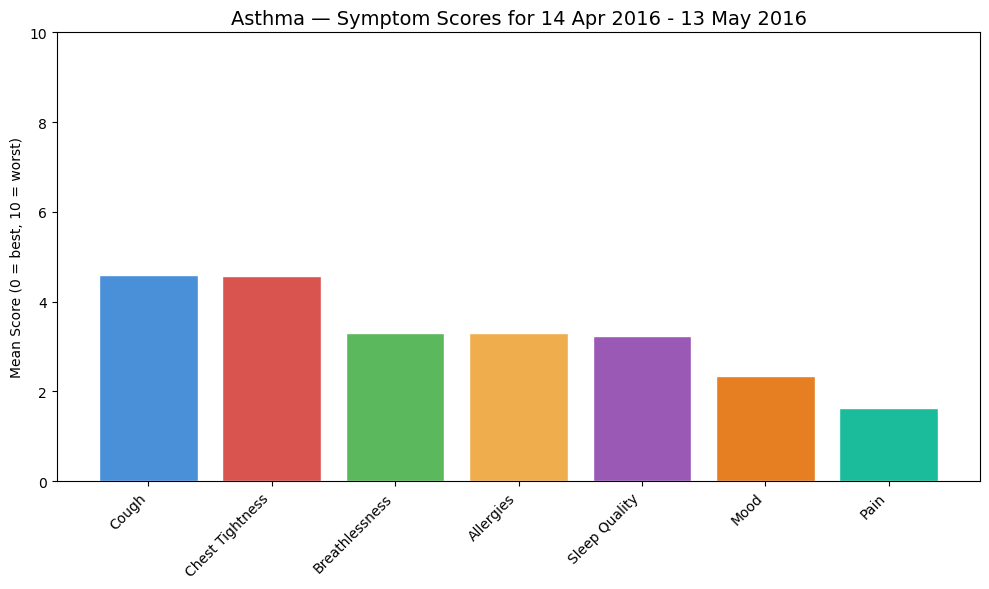

Symptoms with the highest scores in this period were Cough (4.6), Chest Tightness (4.6), and Breathlessness (3.3).


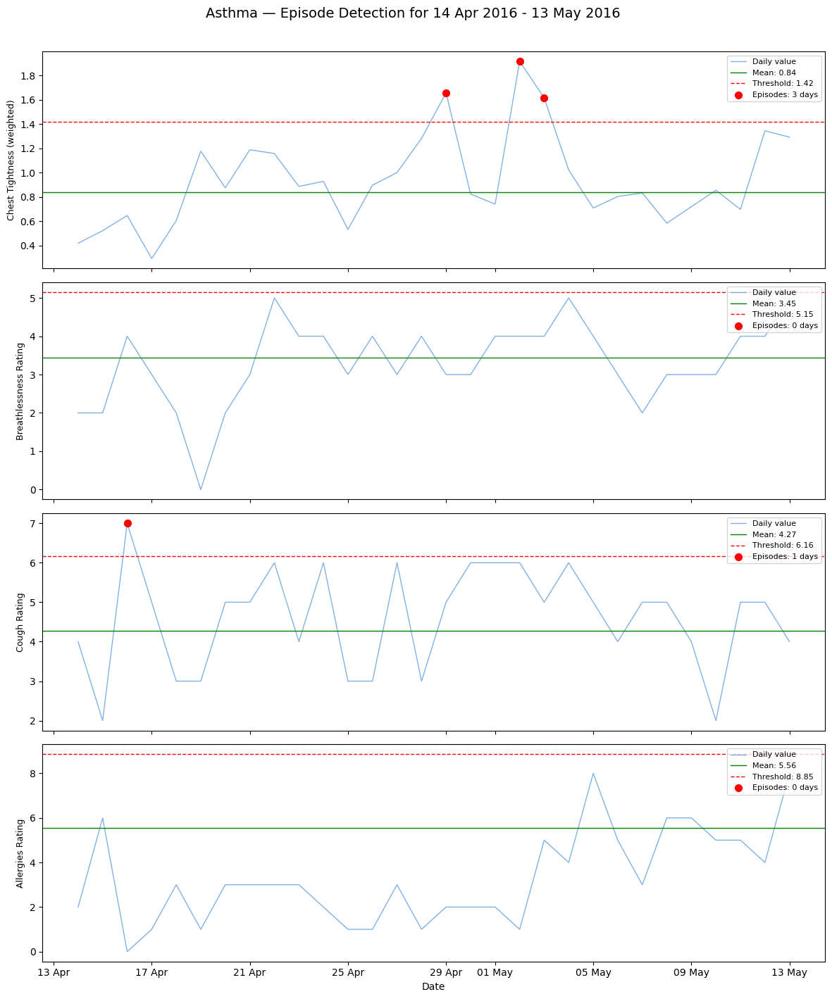

  Total episode days this month: 4

  FLARES OCCURRED ON: 16 Apr (Saturday), 29 Apr (Friday), 02 May (Monday), 03 May (Tuesday)
Worst day in this period: 05 May (composite 5.0/10)
Best day in this period:  19 Apr (composite 1.7/10)


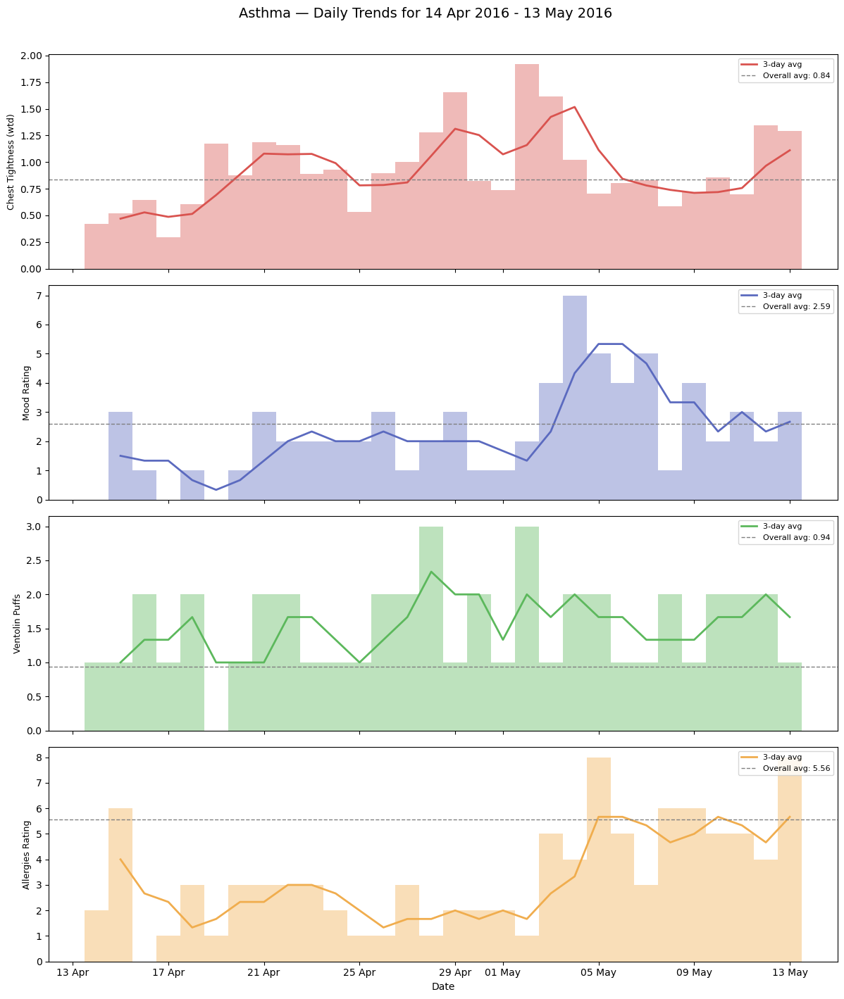

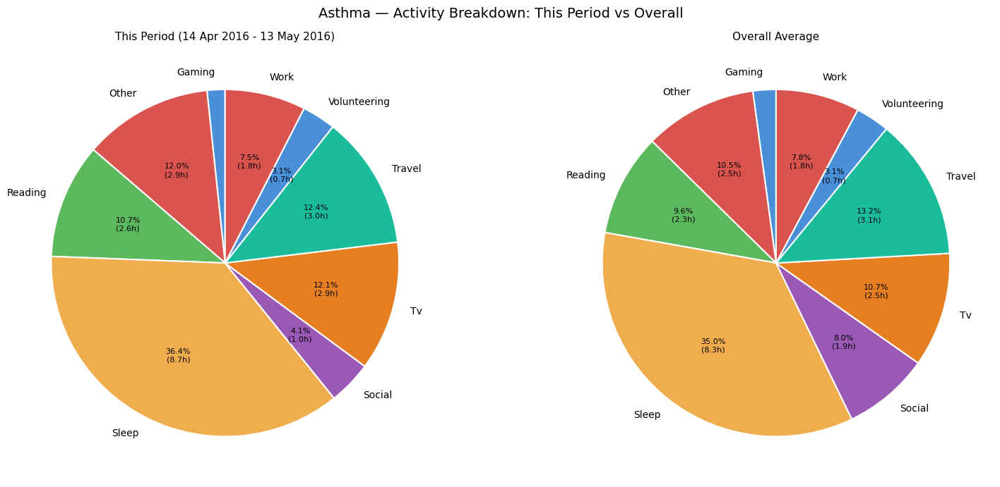

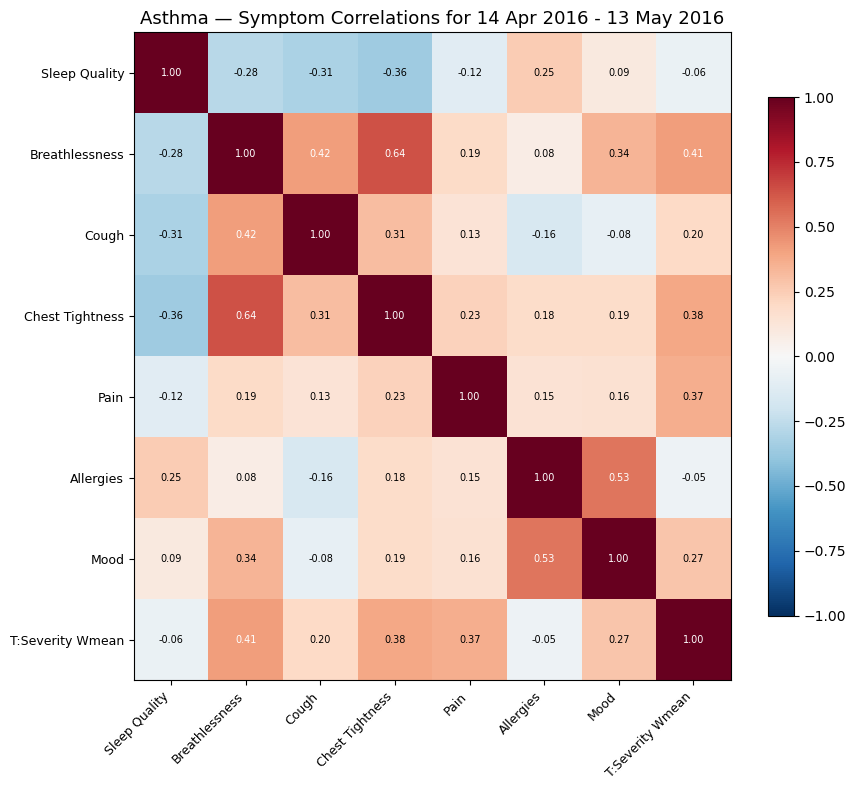


  STRONGEST SYMPTOM CORRELATIONS THIS PERIOD:
    Breathlessness       ↔ Chest Tightness       ρ=+0.638  (strongly move together)
    Allergies            ↔ Mood                  ρ=+0.533  (strongly move together)
    Breathlessness       ↔ Cough                 ρ=+0.416  (moderately move together)
    Breathlessness       ↔ T:Severity Wmean      ρ=+0.414  (moderately move together)
    Chest Tightness      ↔ T:Severity Wmean      ρ=+0.384  (moderately move together)

  NOTABLE CHANGES FROM OVERALL PATTERN:
    Allergies            ↔ Mood                  this period=+0.533  overall=+0.131  (stronger this period)
    Sleep Quality        ↔ Chest Tightness       this period=-0.358  overall=+0.066  (stronger this period)
    Sleep Quality        ↔ Cough                 this period=-0.313  overall=+0.132  (stronger this period)
    Sleep Quality        ↔ Breathlessness        this period=-0.279  overall=+0.067  (stronger this period)
    Sleep Quality        ↔ Allergies             this 

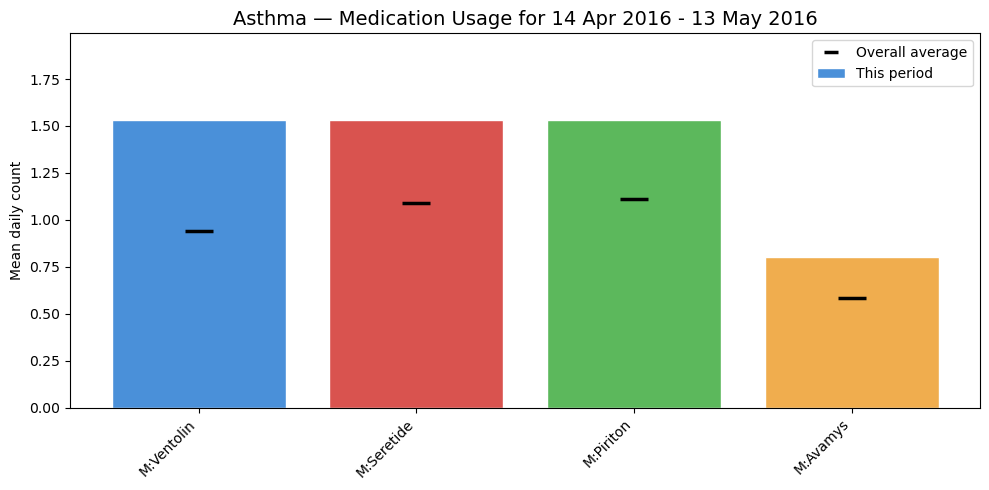


  WHAT YOU TRIED AND WHETHER IT HELPED:
  ──────────────────────────────────────────────────

    M:Ventolin: used on 29 of 30 days — taken too consistently to compare with/without. This is typical for routine preventers and means the medication's effect can't be isolated from daily data alone.

    M:Seretide: used on 29 of 30 days — taken too consistently to compare with/without. This is typical for routine preventers and means the medication's effect can't be isolated from daily data alone.

    M:Piriton: used on 28 of 30 days — taken too consistently to compare with/without. This is typical for routine preventers and means the medication's effect can't be isolated from daily data alone.

    M:Avamys (used on 24 of 30 days):
      Breathlessness         was higher on days you used it (3.5 vs 2.5) — but this likely means you reached for it on worse days, not that it made things worse.
      Chest Tightness        was higher on days you used it (4.9 vs 3.2) — but this likely means 

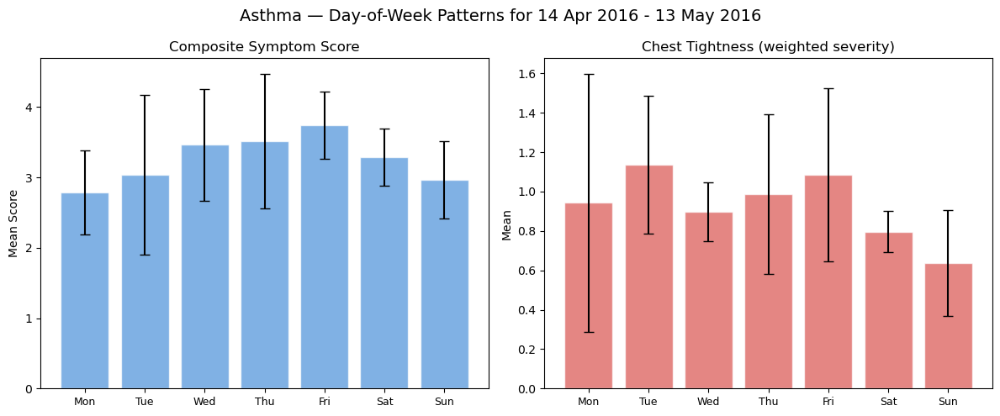

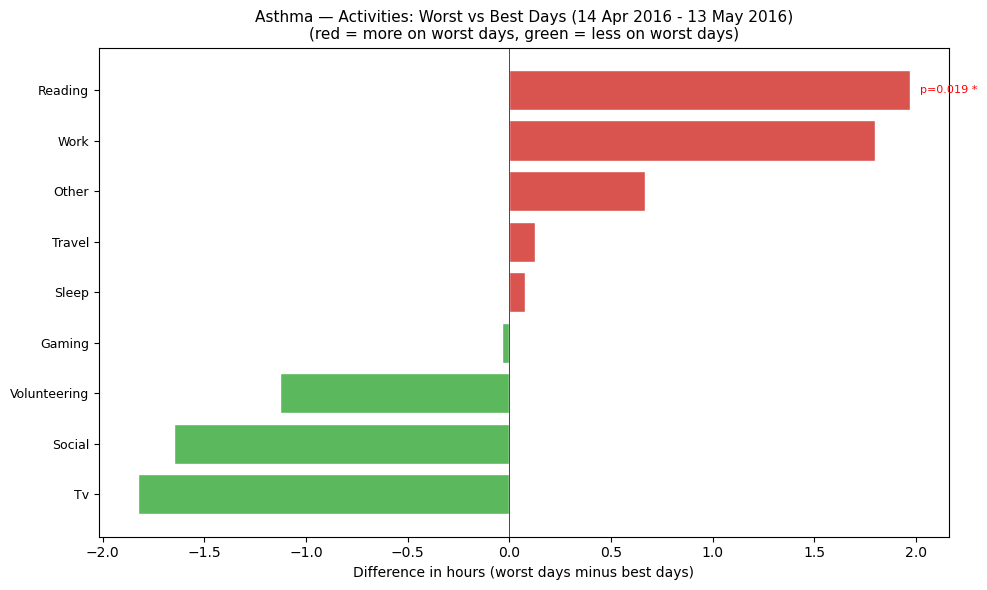


  ACTIVITIES ON WORST vs BEST DAYS:
  Activities associated with HIGHEST symptom scores:
    Reading               +2.0h on worst days  p=0.019 *
    Work                  +1.8h on worst days  p=0.321
    Other                 +0.7h on worst days  p=1.000
    Travel                +0.1h on worst days  p=0.569
  Activities associated with LOWEST symptom scores:
    Tv                    -1.8h on worst days  p=0.286
    Social                -1.6h on worst days  p=0.117
    Volunteering          -1.1h on worst days  p=0.508


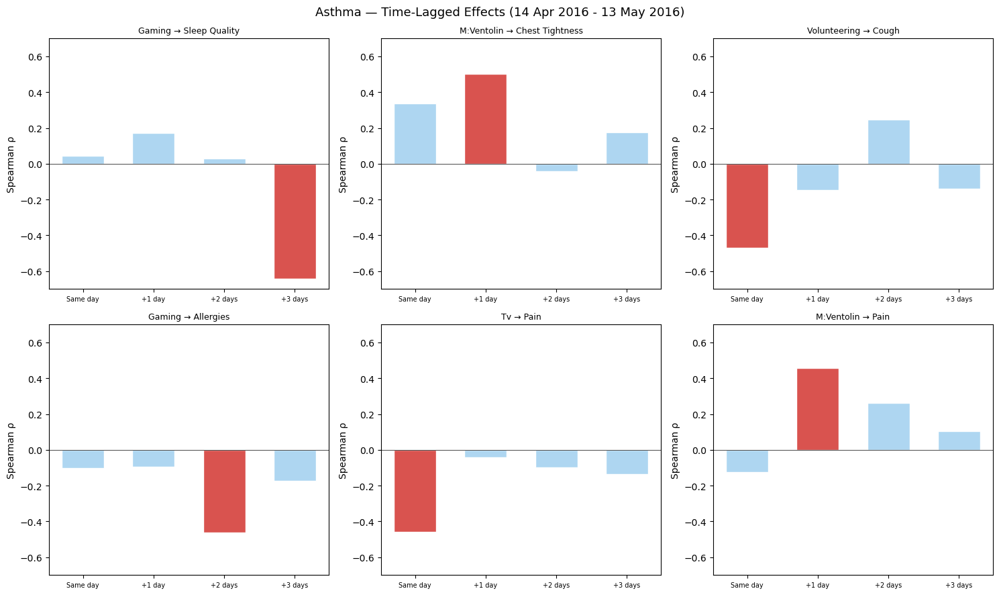


  TIME-LAGGED EFFECTS (strongest associations, p<0.1):
    Gaming               → Sleep Quality         ρ=-0.642  after 3 day(s)  (better) *
    M:Ventolin           → Chest Tightness       ρ=+0.501  after 1 day(s)  (worse) *
    Volunteering         → Cough                 ρ=-0.469  same-day  (better) *
    Gaming               → Allergies             ρ=-0.463  after 2 day(s)  (better) *
    Tv                   → Pain                  ρ=-0.459  same-day  (better) *
    M:Ventolin           → Pain                  ρ=+0.459  after 1 day(s)  (worse) *
    M:Avamys             → Chest Tightness       ρ=+0.446  same-day  (worse) *
    Tv                   → Allergies             ρ=-0.446  after 3 day(s)  (better) *
    Volunteering         → Mood                  ρ=-0.427  after 2 day(s)  (better) *
    Volunteering         → Pain                  ρ=-0.413  after 2 day(s)  (better) *
    Social               → Chest Tightness       ρ=+0.412  after 3 day(s)  (worse) *
    Tv              

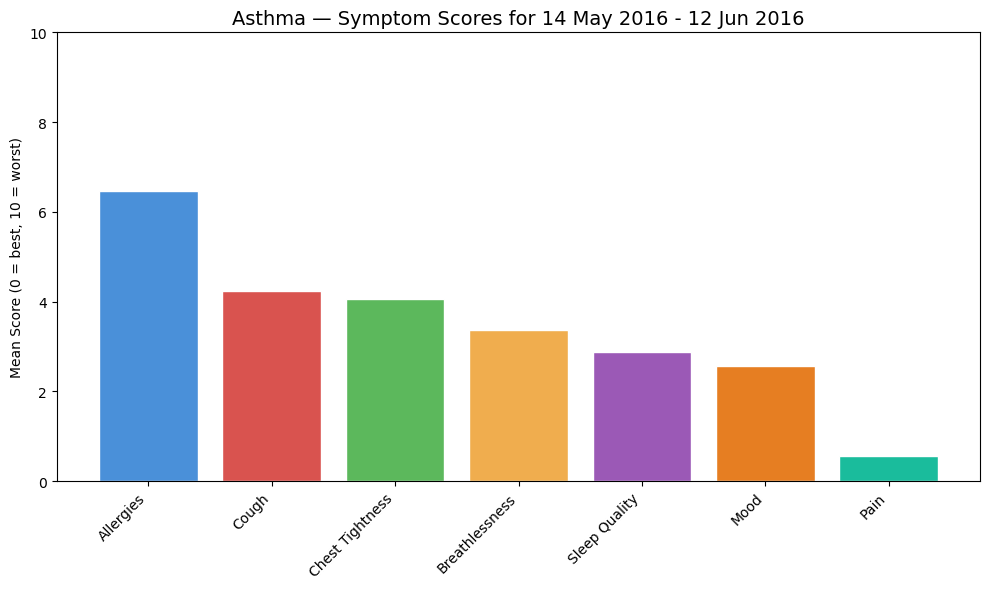

Symptoms with the highest scores in this period were Allergies (6.5), Cough (4.2), and Chest Tightness (4.1).


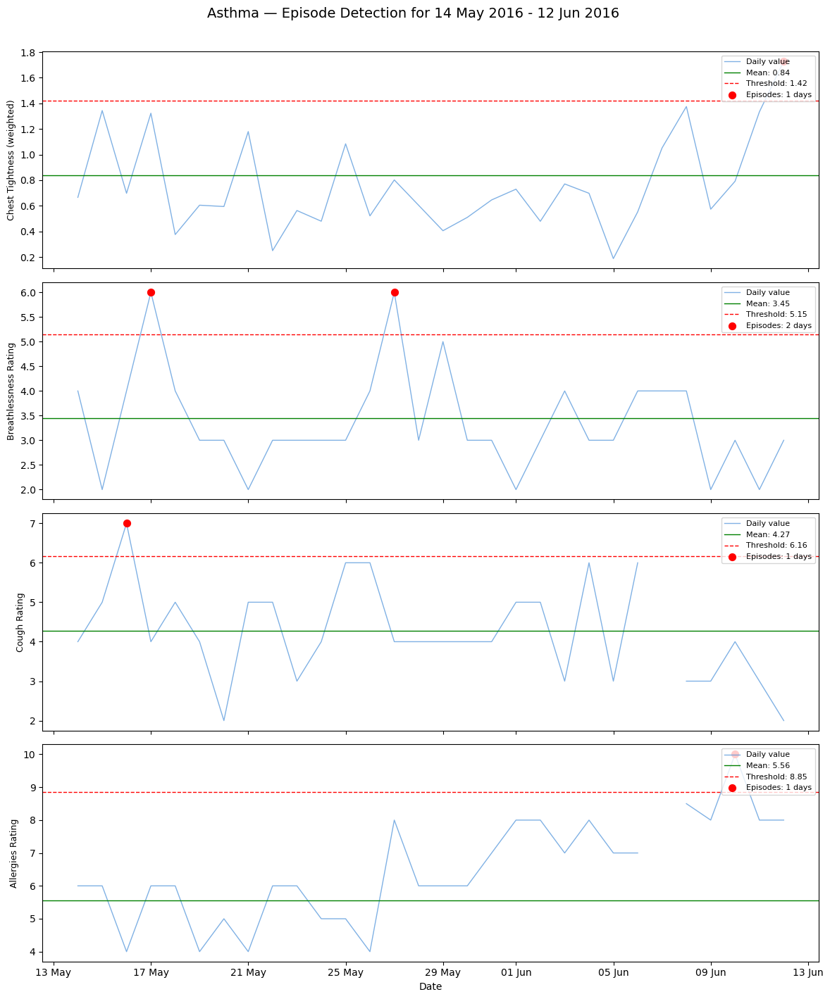

  Total episode days this month: 5

  FLARES OCCURRED ON: 16 May (Monday), 17 May (Tuesday), 27 May (Friday), 10 Jun (Friday), 12 Jun (Sunday)
Worst day in this period: 17 May (composite 5.0/10)
Best day in this period:  11 Jun (composite 2.3/10)


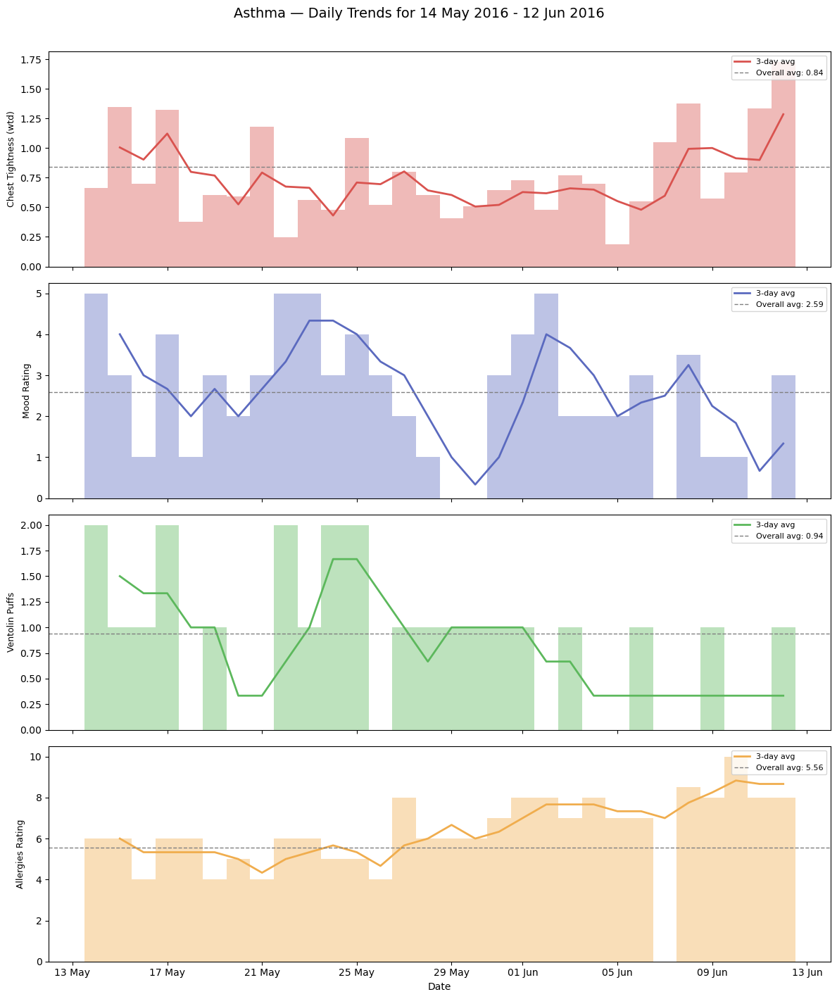

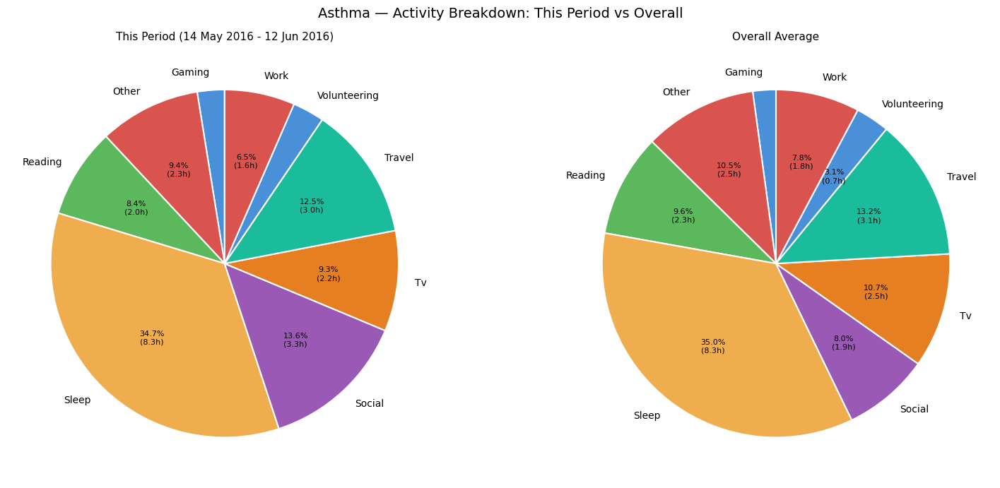

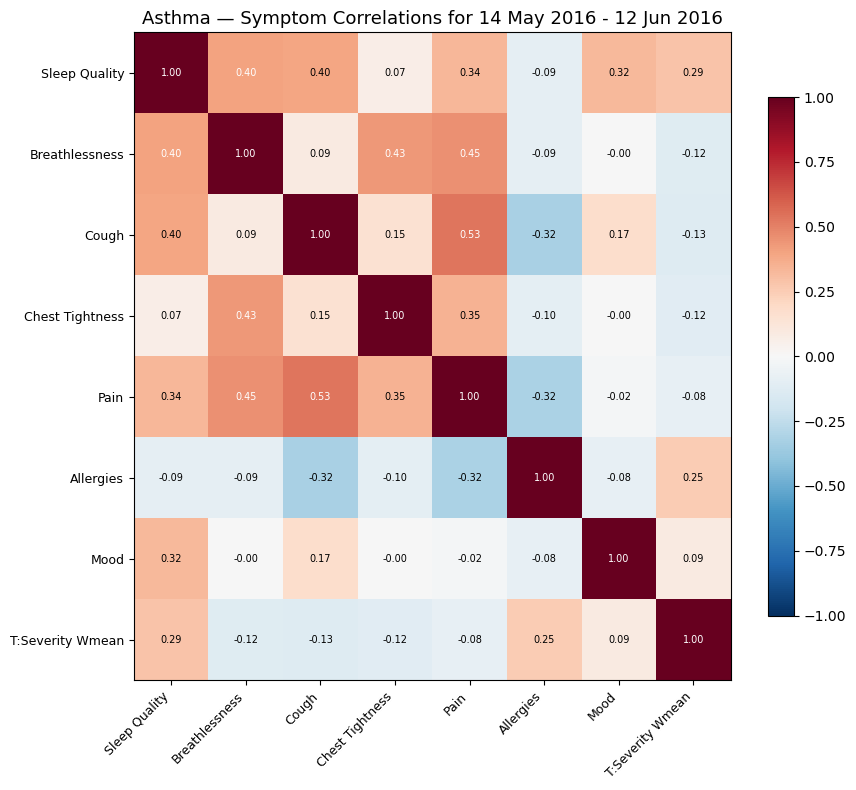


  STRONGEST SYMPTOM CORRELATIONS THIS PERIOD:
    Cough                ↔ Pain                  ρ=+0.532  (strongly move together)
    Breathlessness       ↔ Pain                  ρ=+0.454  (moderately move together)
    Breathlessness       ↔ Chest Tightness       ρ=+0.432  (moderately move together)
    Sleep Quality        ↔ Breathlessness        ρ=+0.403  (moderately move together)
    Sleep Quality        ↔ Cough                 ρ=+0.396  (moderately move together)

  NOTABLE CHANGES FROM OVERALL PATTERN:
    Cough                ↔ Pain                  this period=+0.532  overall=+0.082  (stronger this period)
    Sleep Quality        ↔ Breathlessness        this period=+0.403  overall=+0.067  (stronger this period)
    Sleep Quality        ↔ Cough                 this period=+0.396  overall=+0.132  (stronger this period)
    Pain                 ↔ Allergies             this period=-0.317  overall=+0.056  (stronger this period)
    Allergies            ↔ T:Severity Wmean      thi

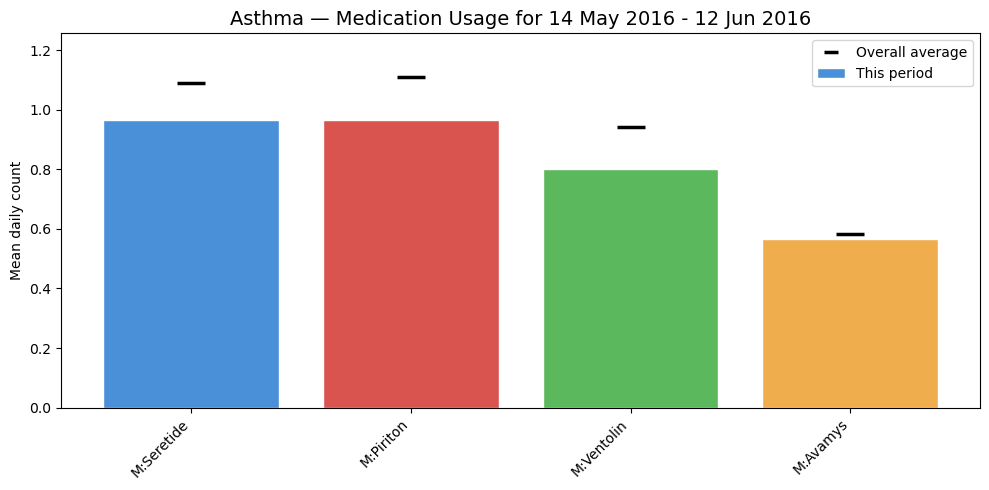


  WHAT YOU TRIED AND WHETHER IT HELPED:
  ──────────────────────────────────────────────────

    M:Ventolin (used on 19 of 30 days):
      Next-day Cough              was still elevated after use (4.6 vs 3.7)

    M:Seretide (used on 23 of 30 days):
      Allergies              was higher on days you used it (6.8 vs 5.2) — but this likely means you reached for it on worse days, not that it made things worse.

    M:Piriton (used on 23 of 30 days):
      Allergies              was higher on days you used it (6.8 vs 5.2) — but this likely means you reached for it on worse days, not that it made things worse.

    M:Avamys (used on 17 of 30 days):
      Sleep Quality          was higher on days you used it (3.4 vs 2.2) — but this likely means you reached for it on worse days, not that it made things worse.
      Allergies              was higher on days you used it (7.1 vs 5.5) — but this likely means you reached for it on worse days, not that it made things worse.
      Mood           

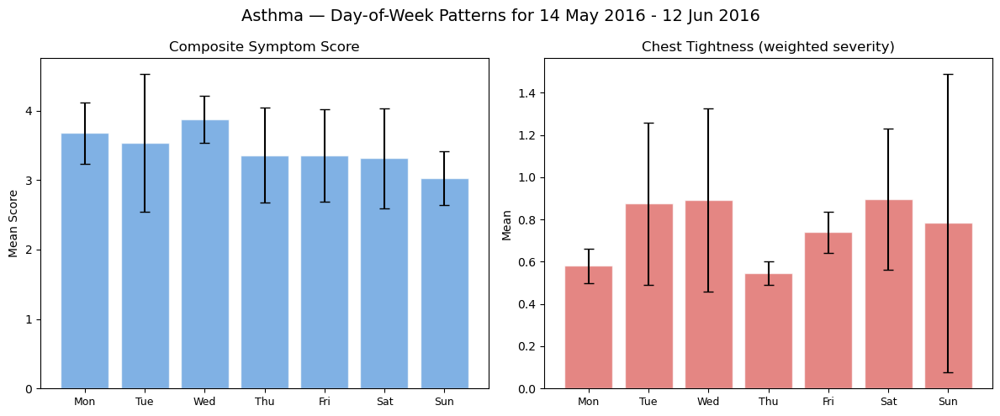

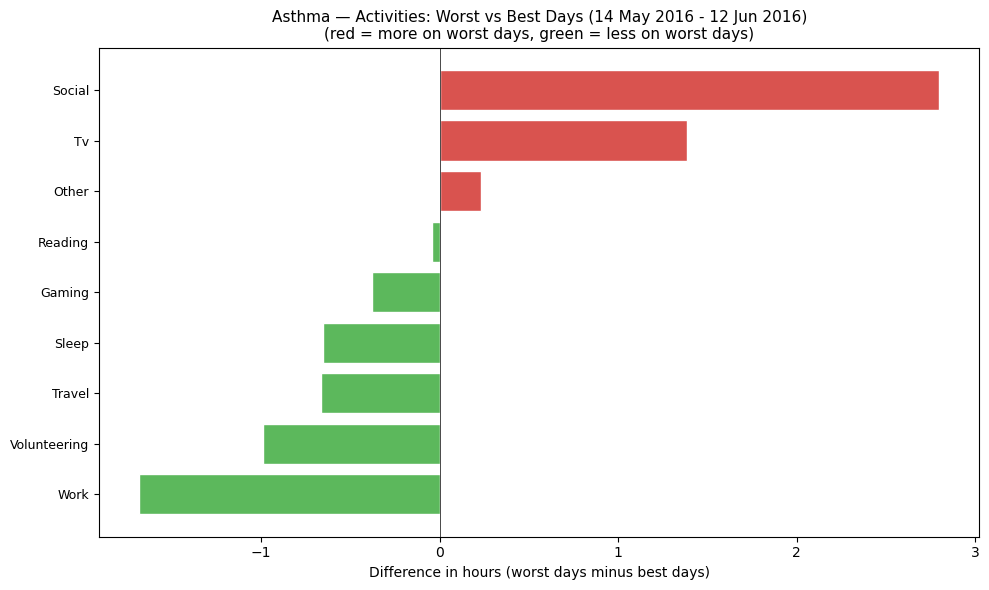


  ACTIVITIES ON WORST vs BEST DAYS:
  Activities associated with HIGHEST symptom scores:
    Social                +2.8h on worst days  p=0.525
    Tv                    +1.4h on worst days  p=0.538
    Other                 +0.2h on worst days  p=1.000
  Activities associated with LOWEST symptom scores:
    Work                  -1.7h on worst days  p=0.285
    Volunteering          -1.0h on worst days  p=0.356
    Travel                -0.7h on worst days  p=0.371
    Sleep                 -0.7h on worst days  p=0.390
    Gaming                -0.4h on worst days  p=0.600


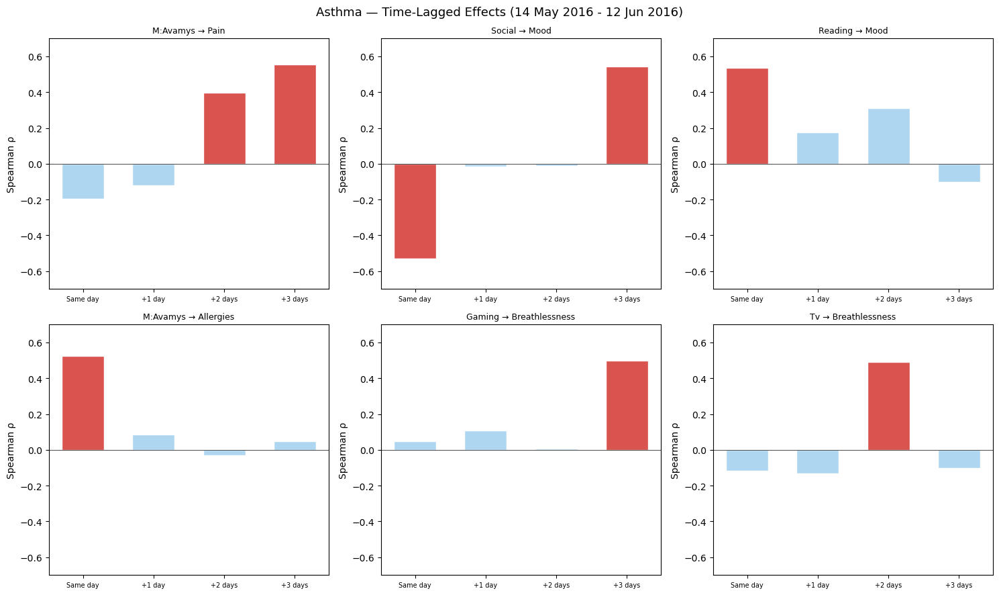


  TIME-LAGGED EFFECTS (strongest associations, p<0.1):
    M:Avamys             → Pain                  ρ=+0.554  after 3 day(s)  (worse) *
    Social               → Mood                  ρ=+0.543  after 3 day(s)  (worse) *
    Reading              → Mood                  ρ=+0.537  same-day  (worse) *
    M:Avamys             → Allergies             ρ=+0.524  same-day  (worse) *
    Gaming               → Breathlessness        ρ=+0.497  after 3 day(s)  (worse) *
    Tv                   → Breathlessness        ρ=+0.489  after 2 day(s)  (worse) *
    M:Piriton            → Mood                  ρ=+0.434  same-day  (worse) *
    M:Seretide           → Mood                  ρ=+0.434  same-day  (worse) *
    Gaming               → Pain                  ρ=+0.426  after 2 day(s)  (worse) *
    Reading              → Sleep Quality         ρ=+0.425  after 2 day(s)  (worse) *
    Social               → Sleep Quality         ρ=-0.412  after 2 day(s)  (better) *
    Tv                   → Mood 

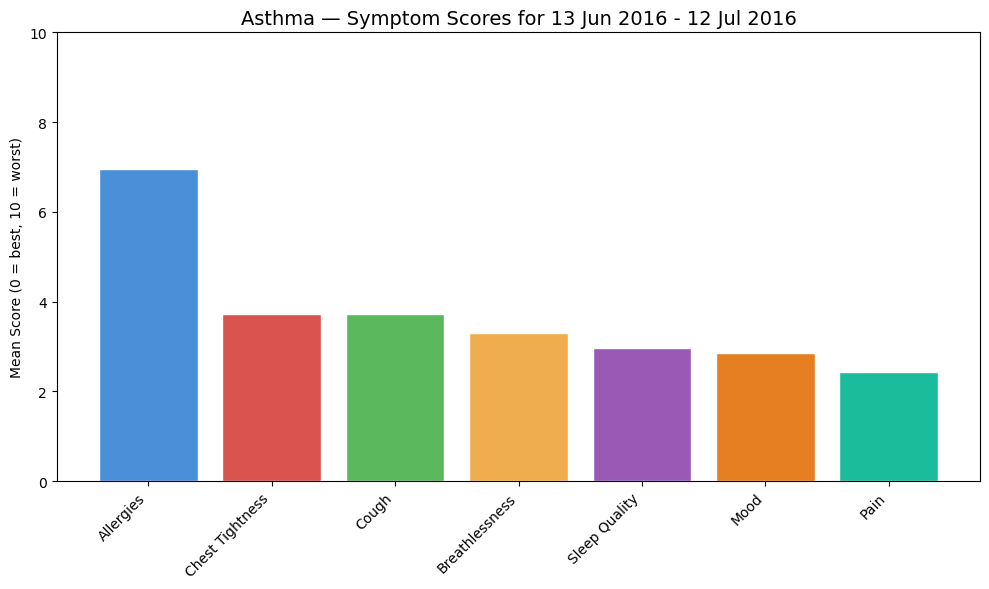

Symptoms with the highest scores in this period were Allergies (7.0), Chest Tightness (3.7), and Cough (3.7).


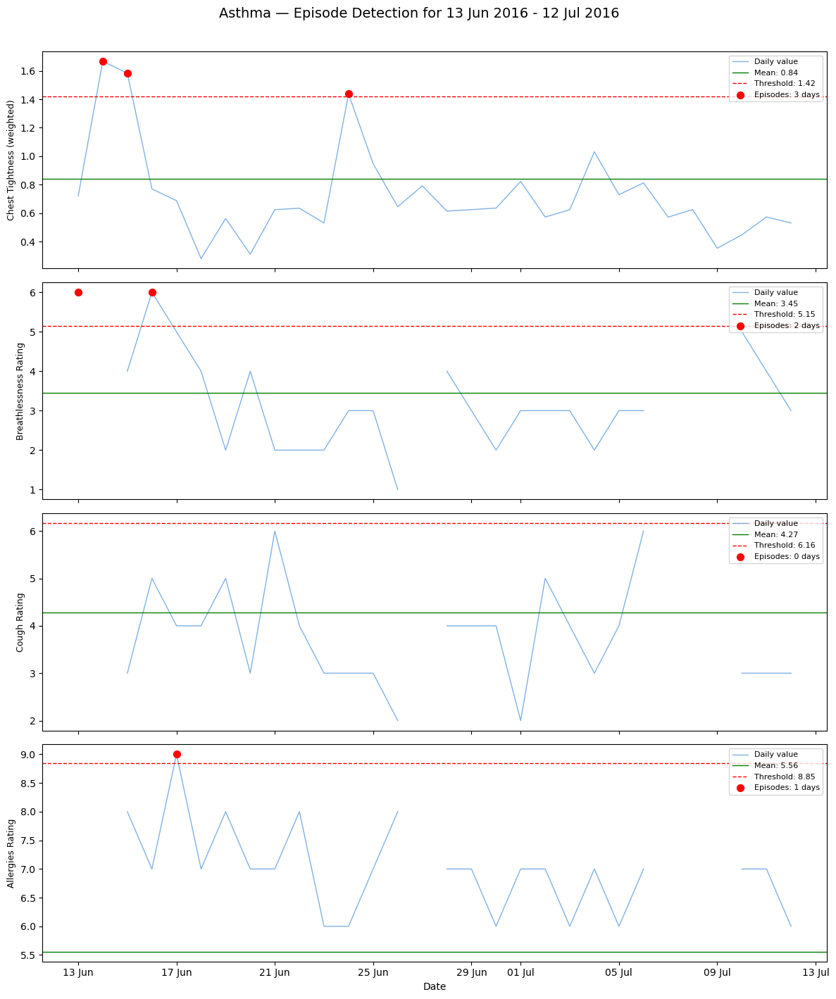

  Total episode days this month: 6

  FLARES OCCURRED ON: 13 Jun (Monday), 14 Jun (Tuesday), 15 Jun (Wednesday), 16 Jun (Thursday), 17 Jun (Friday), 24 Jun (Friday)
Worst day in this period: 10 Jul (composite 6.0/10)
Best day in this period:  23 Jun (composite 2.7/10)


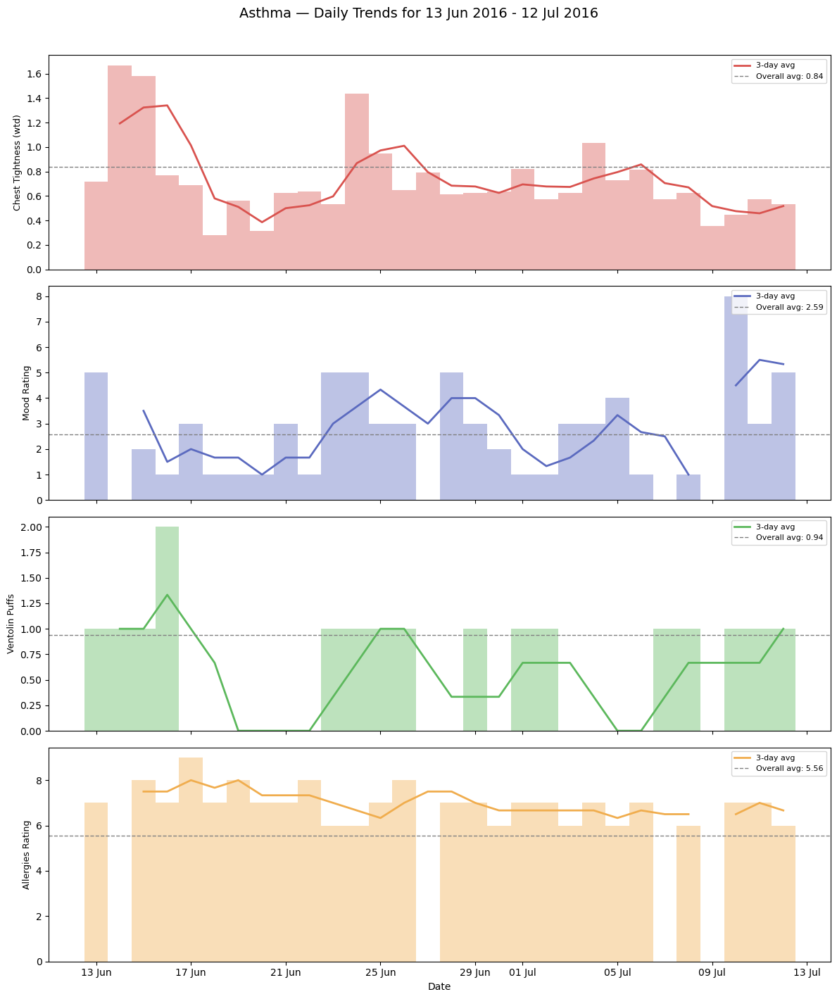

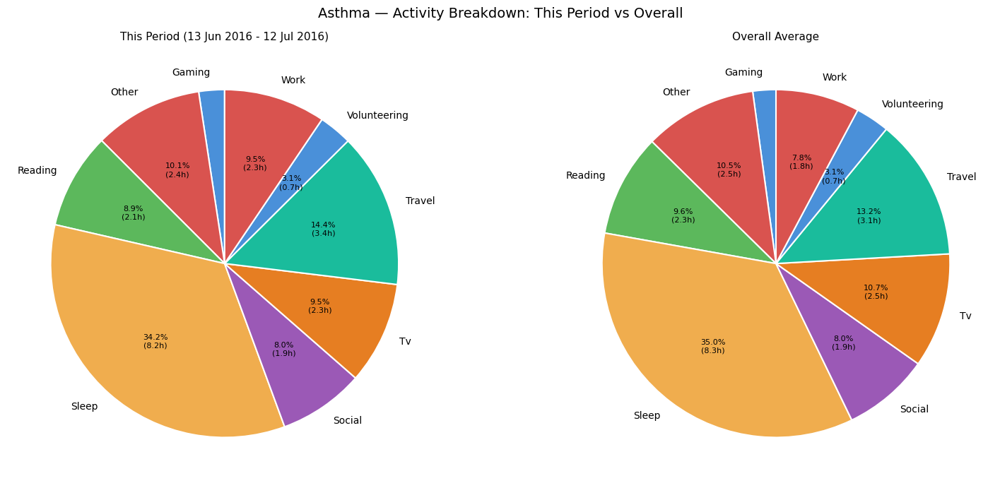

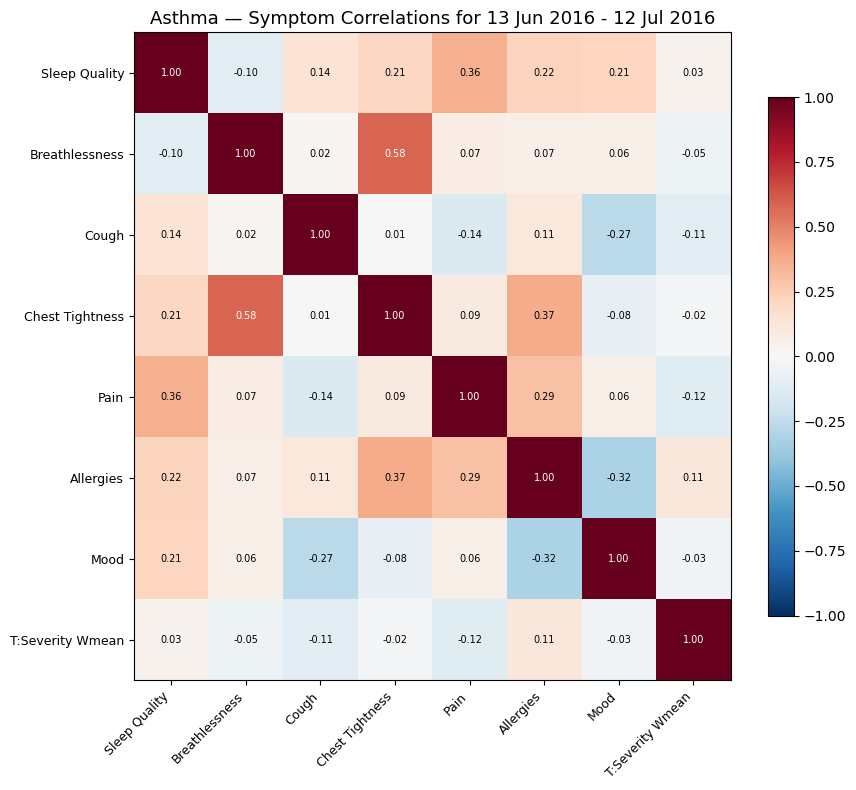


  STRONGEST SYMPTOM CORRELATIONS THIS PERIOD:
    Breathlessness       ↔ Chest Tightness       ρ=+0.582  (strongly move together)
    Chest Tightness      ↔ Allergies             ρ=+0.372  (moderately move together)
    Sleep Quality        ↔ Pain                  ρ=+0.358  (moderately move together)
    Allergies            ↔ Mood                  ρ=-0.319  (moderately move inversely)
    Pain                 ↔ Allergies             ρ=+0.290  (moderately move together)

  NOTABLE CHANGES FROM OVERALL PATTERN:
    Chest Tightness      ↔ Allergies             this period=+0.372  overall=-0.071  (stronger this period)
    Allergies            ↔ Mood                  this period=-0.319  overall=+0.131  (stronger this period)
    Sleep Quality        ↔ Allergies             this period=+0.222  overall=-0.037  (stronger this period)
    Cough                ↔ Allergies             this period=+0.109  overall=-0.283  (weaker this period)
    Breathlessness       ↔ T:Severity Wmean      this

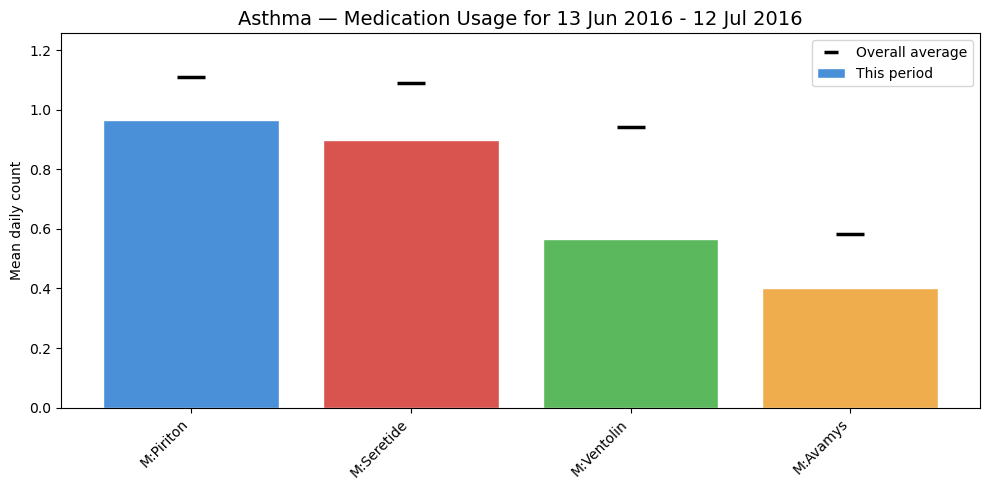


  WHAT YOU TRIED AND WHETHER IT HELPED:
  ──────────────────────────────────────────────────

    M:Ventolin (used on 16 of 30 days):
      Cough                  was lower on days you used it (3.3 vs 4.2, p=0.014) — this suggests it may have helped.

    M:Seretide (used on 23 of 30 days):

    M:Piriton (used on 24 of 30 days):

    M:Avamys (used on 12 of 30 days):
      Cough                  was lower on days you used it (3.4 vs 4.0, p=0.061) — this suggests it may have helped.


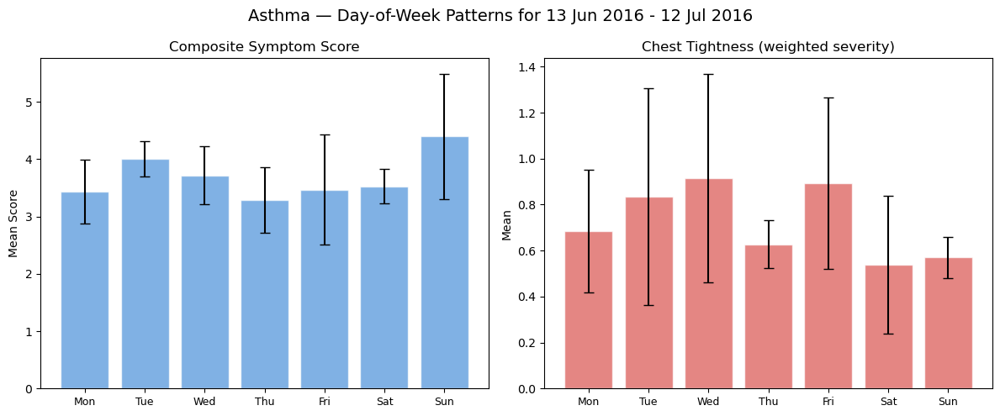

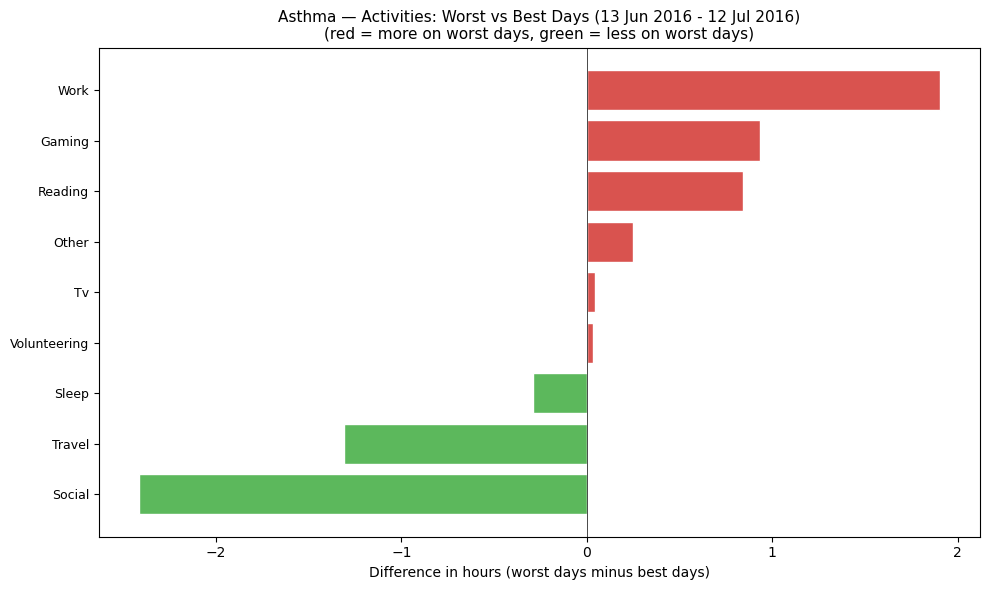


  ACTIVITIES ON WORST vs BEST DAYS:
  Activities associated with HIGHEST symptom scores:
    Work                  +1.9h on worst days  p=0.388
    Gaming                +0.9h on worst days  p=0.108
    Reading               +0.8h on worst days  p=0.273
    Other                 +0.3h on worst days  p=0.930
  Activities associated with LOWEST symptom scores:
    Social                -2.4h on worst days  p=0.158
    Travel                -1.3h on worst days  p=0.189
    Sleep                 -0.3h on worst days  p=0.662


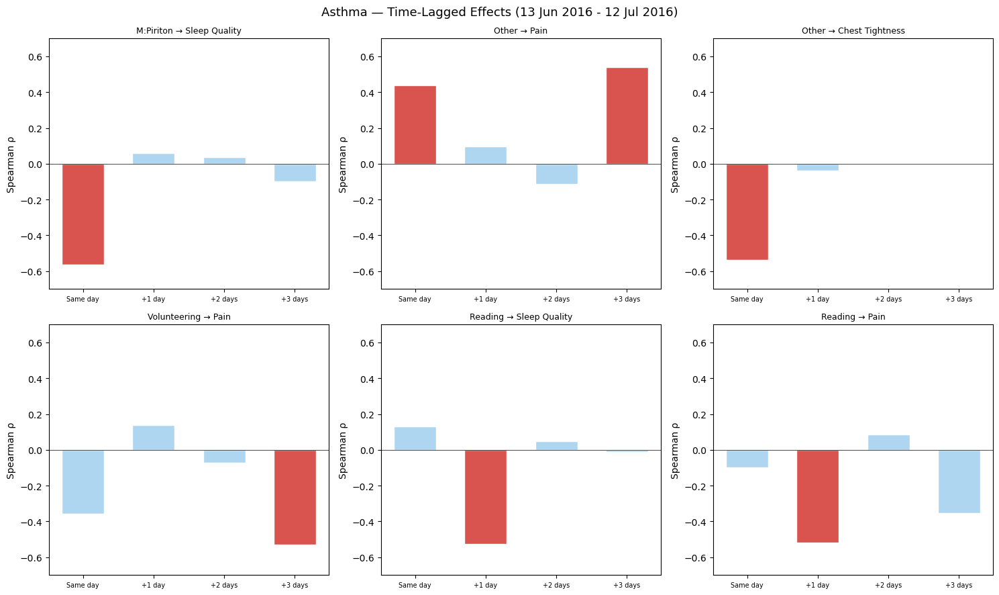


  TIME-LAGGED EFFECTS (strongest associations, p<0.1):
    M:Piriton            → Sleep Quality         ρ=-0.564  same-day  (better) *
    Other                → Pain                  ρ=+0.540  after 3 day(s)  (worse) *
    Other                → Chest Tightness       ρ=-0.536  same-day  (better) *
    Volunteering         → Pain                  ρ=-0.531  after 3 day(s)  (better) *
    Reading              → Sleep Quality         ρ=-0.527  after 1 day(s)  (better) *
    Reading              → Pain                  ρ=-0.520  after 1 day(s)  (better) *
    Sleep                → Mood                  ρ=-0.512  same-day  (better) *
    Gaming               → Pain                  ρ=-0.494  after 3 day(s)  (better) *
    M:Seretide           → Sleep Quality         ρ=-0.492  same-day  (better) *
    M:Ventolin           → Allergies             ρ=+0.488  after 3 day(s)  (worse) *
    Reading              → Mood                  ρ=-0.470  after 3 day(s)  (better) *
    Volunteering        

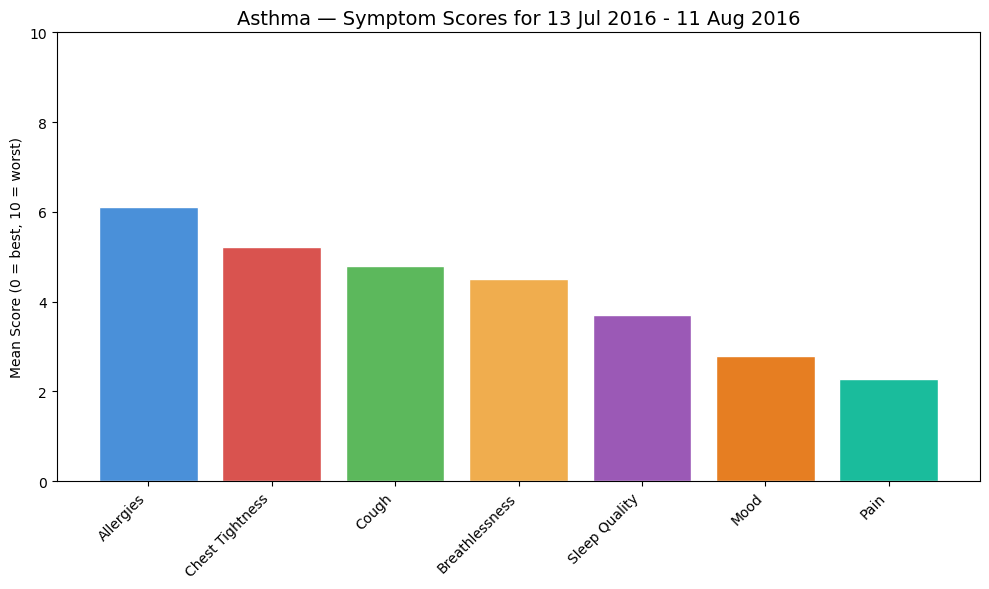

Symptoms with the highest scores in this period were Allergies (6.1), Chest Tightness (5.2), and Cough (4.8).

  Episode detection skipped — not enough data this period.


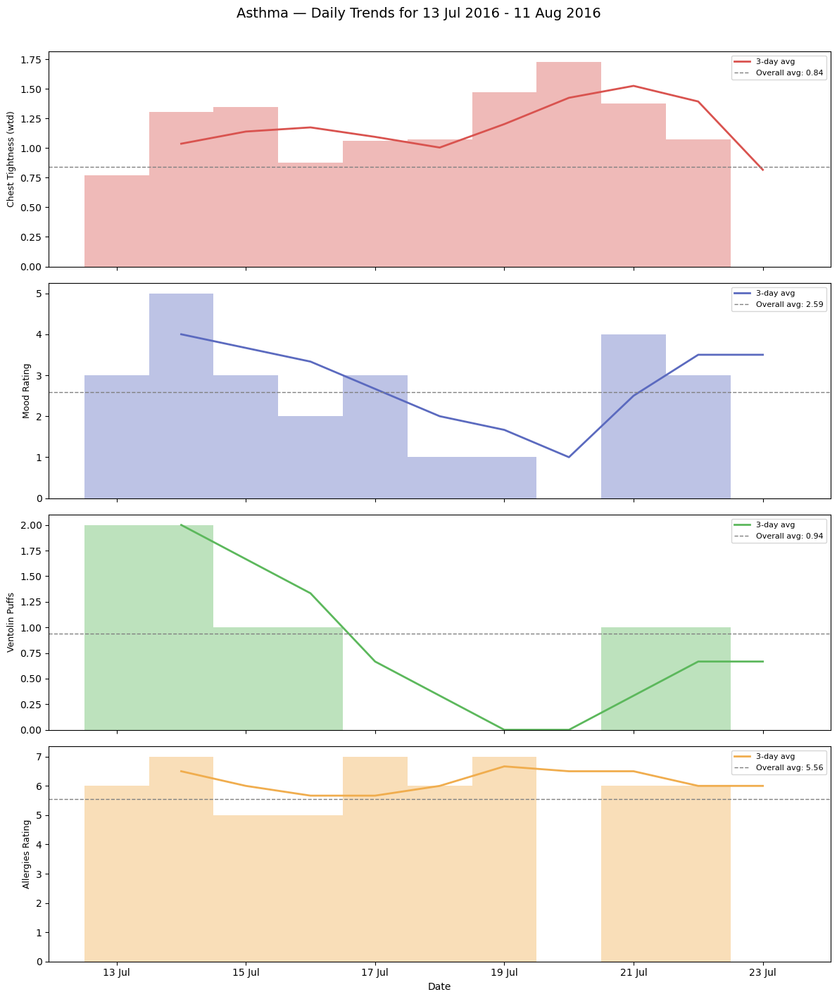

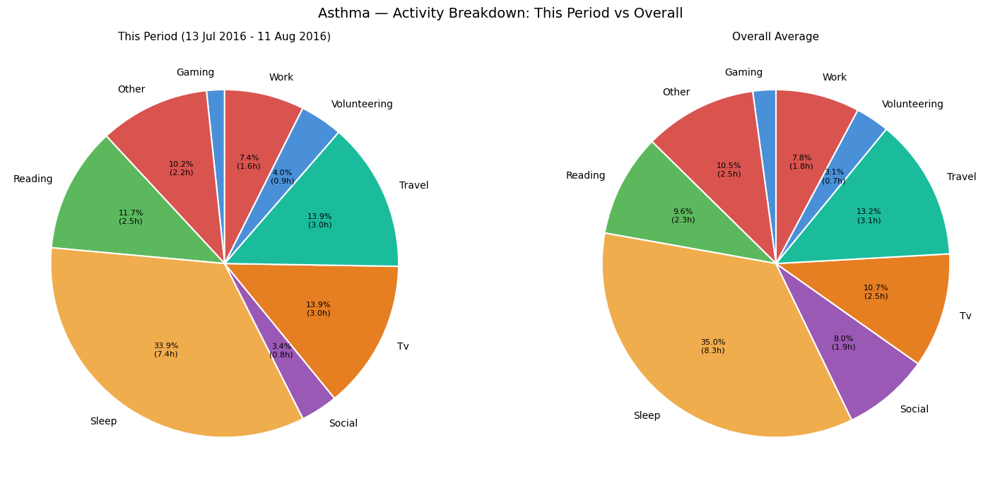

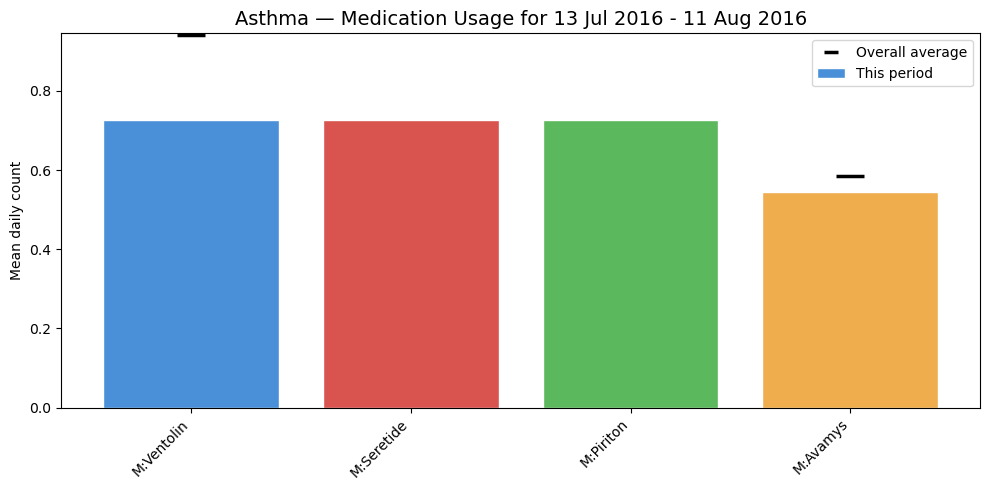


  WHAT YOU TRIED AND WHETHER IT HELPED:
  ──────────────────────────────────────────────────

    M:Ventolin (used on 6 of 11 days):

    M:Seretide (used on 6 of 11 days):

    M:Piriton (used on 6 of 11 days):

    M:Avamys (used on 6 of 11 days):


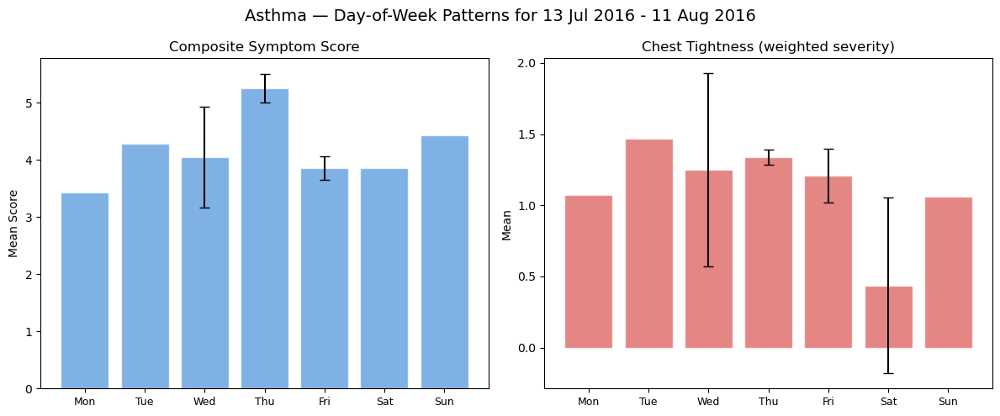


  Insufficient worst/best days for activity comparison (worst=4, best=1)

  Insufficient data for lag analysis in this period

  TRIGGERS OF CHEST TIGHTNESS (WEIGHTED SEVERITY):
    No significant triggers identified in this period

  RELIEVERS:
    No significant relievers identified in this period

  APPEARED TO HAVE NO SIGNIFICANT EFFECT ON SYMPTOMS:
    Gaming, Other, Sleep, Travel, Volunteering, M:Ventolin, M:Seretide, M:Piriton, M:Avamys
    (all p>0.3)

  WITH REGARD TO CHEST TIGHTNESS (WEIGHTED SEVERITY):
    Work appeared to have most effect in exacerbation (ρ=+0.540, p=0.0866)
    Social appeared to have most effect in relief (ρ=-0.476, p=0.1391)

  COMPARED TO PREVIOUS 30-DAY WINDOW (13 Jun – 12 Jul):
    Sleep Quality              prev=2.96  now=3.70  (+0.74, worse)
    Breathlessness             prev=3.31  now=4.50  (+1.19, worse)
    Cough                      prev=3.73  now=4.80  (+1.07, worse)
    Chest Tightness            prev=3.73  now=5.22  (+1.49, worse)
    Pain 

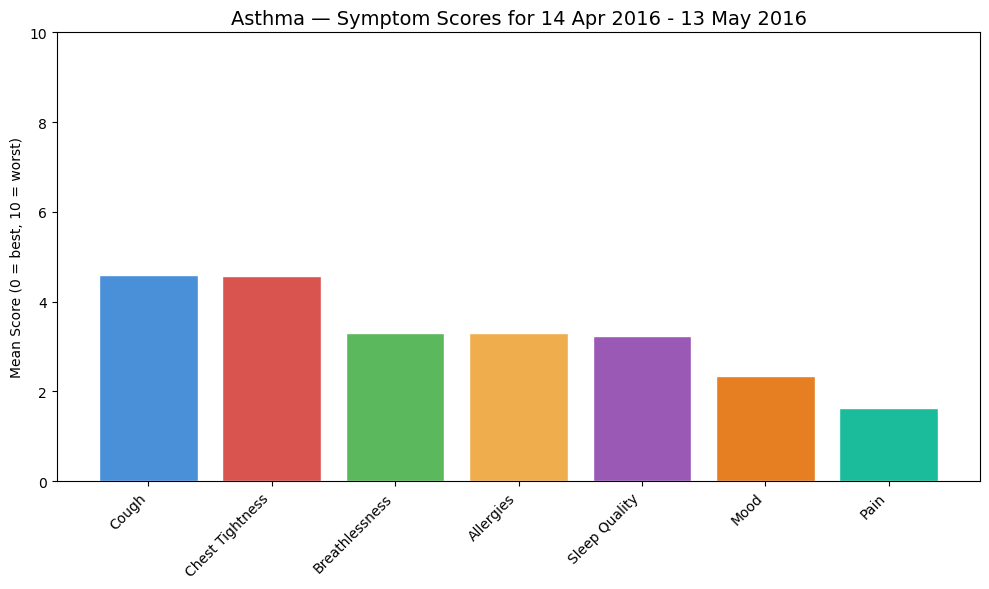

Symptoms with the highest scores in this period were Cough (4.6), Chest Tightness (4.6), and Breathlessness (3.3).


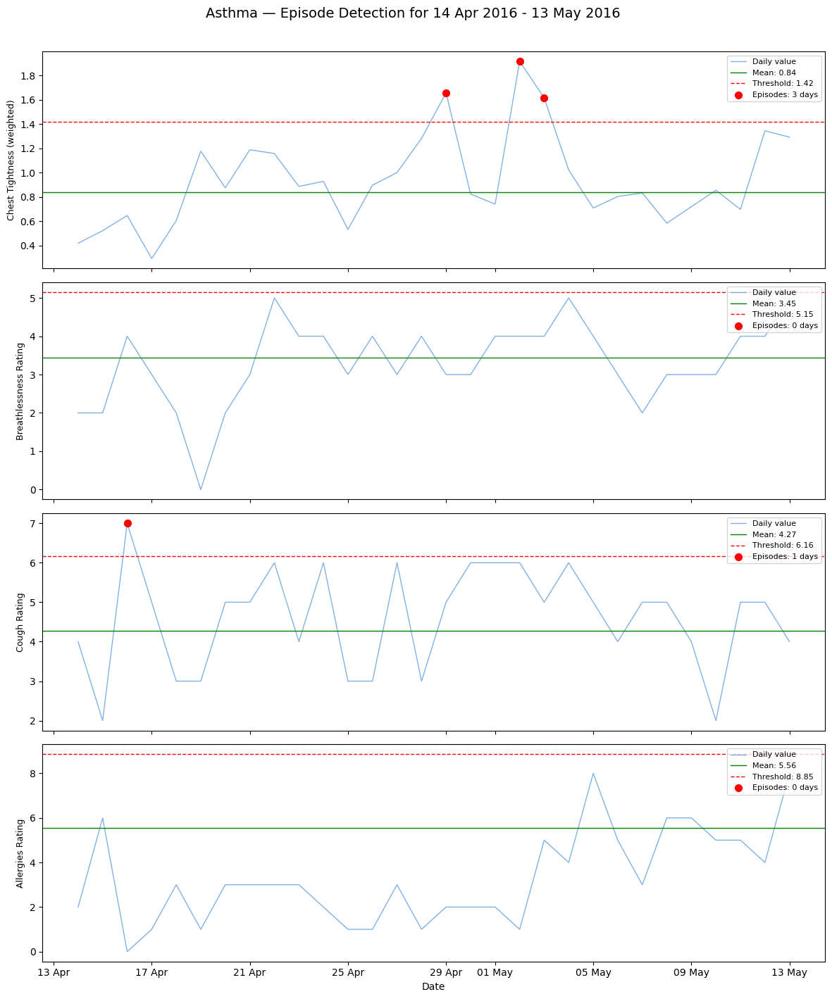

  Total episode days this month: 4

  FLARES OCCURRED ON: 16 Apr (Saturday), 29 Apr (Friday), 02 May (Monday), 03 May (Tuesday)
Worst day in this period: 05 May (composite 5.0/10)
Best day in this period:  19 Apr (composite 1.7/10)


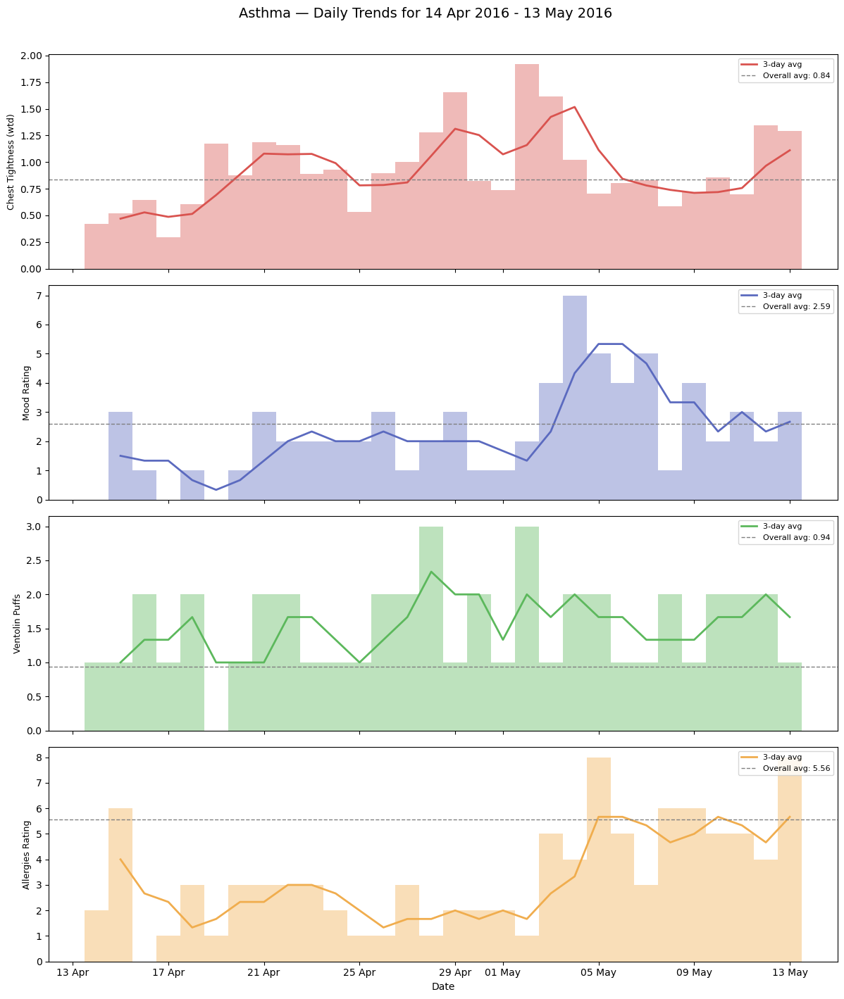

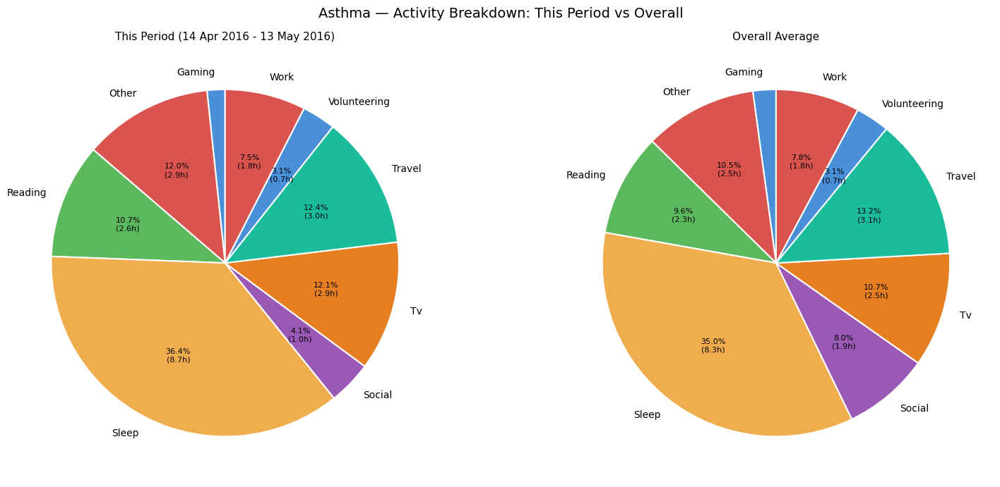

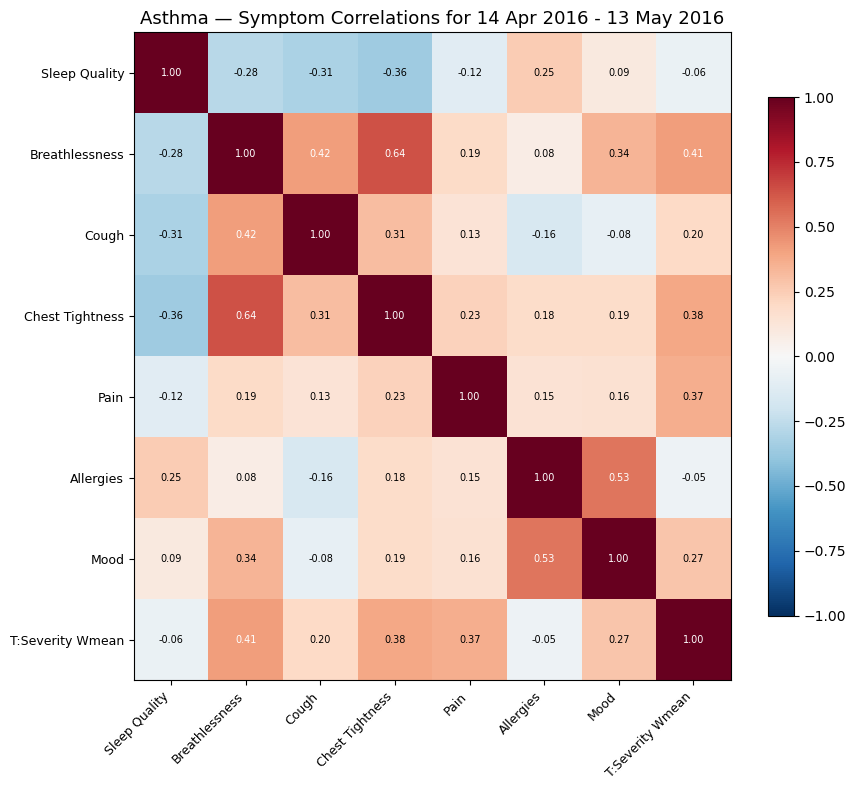


  STRONGEST SYMPTOM CORRELATIONS THIS PERIOD:
    Breathlessness       ↔ Chest Tightness       ρ=+0.638  (strongly move together)
    Allergies            ↔ Mood                  ρ=+0.533  (strongly move together)
    Breathlessness       ↔ Cough                 ρ=+0.416  (moderately move together)
    Breathlessness       ↔ T:Severity Wmean      ρ=+0.414  (moderately move together)
    Chest Tightness      ↔ T:Severity Wmean      ρ=+0.384  (moderately move together)

  NOTABLE CHANGES FROM OVERALL PATTERN:
    Allergies            ↔ Mood                  this period=+0.533  overall=+0.131  (stronger this period)
    Sleep Quality        ↔ Chest Tightness       this period=-0.358  overall=+0.066  (stronger this period)
    Sleep Quality        ↔ Cough                 this period=-0.313  overall=+0.132  (stronger this period)
    Sleep Quality        ↔ Breathlessness        this period=-0.279  overall=+0.067  (stronger this period)
    Sleep Quality        ↔ Allergies             this 

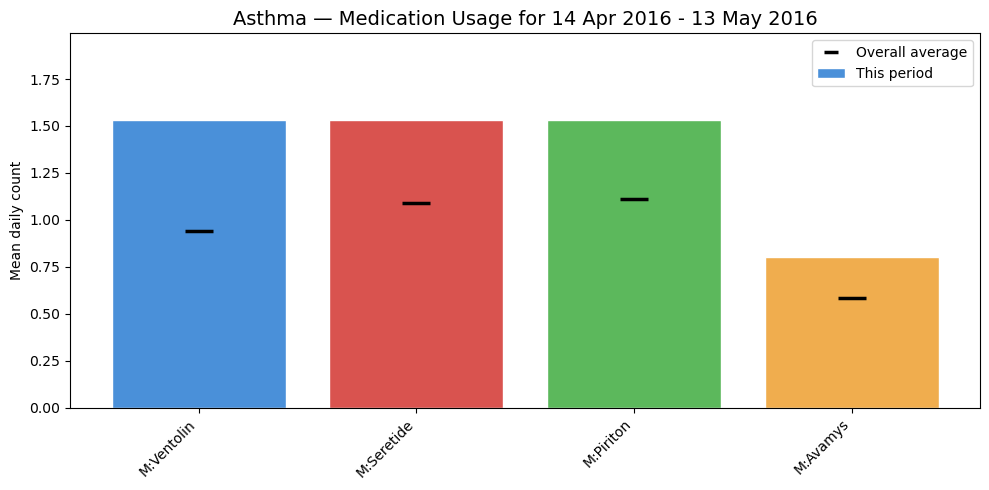


  WHAT YOU TRIED AND WHETHER IT HELPED:
  ──────────────────────────────────────────────────

    M:Ventolin: used on 29 of 30 days — taken too consistently to compare with/without. This is typical for routine preventers and means the medication's effect can't be isolated from daily data alone.

    M:Seretide: used on 29 of 30 days — taken too consistently to compare with/without. This is typical for routine preventers and means the medication's effect can't be isolated from daily data alone.

    M:Piriton: used on 28 of 30 days — taken too consistently to compare with/without. This is typical for routine preventers and means the medication's effect can't be isolated from daily data alone.

    M:Avamys (used on 24 of 30 days):
      Breathlessness         was higher on days you used it (3.5 vs 2.5) — but this likely means you reached for it on worse days, not that it made things worse.
      Chest Tightness        was higher on days you used it (4.9 vs 3.2) — but this likely means 

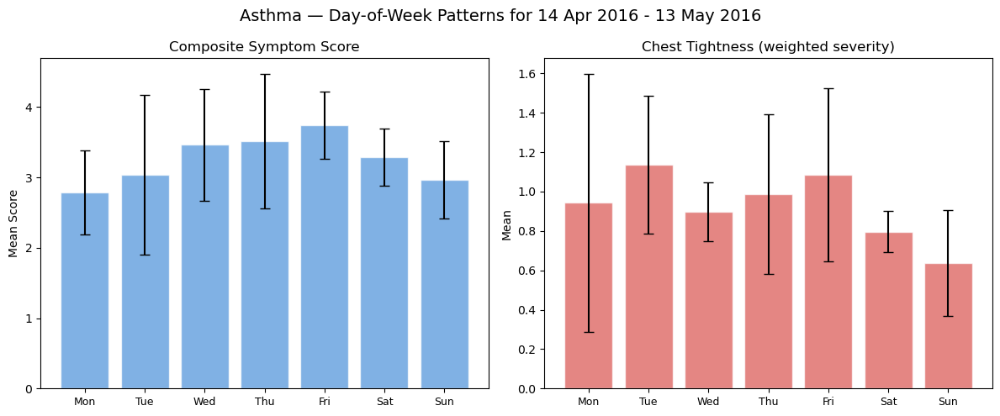

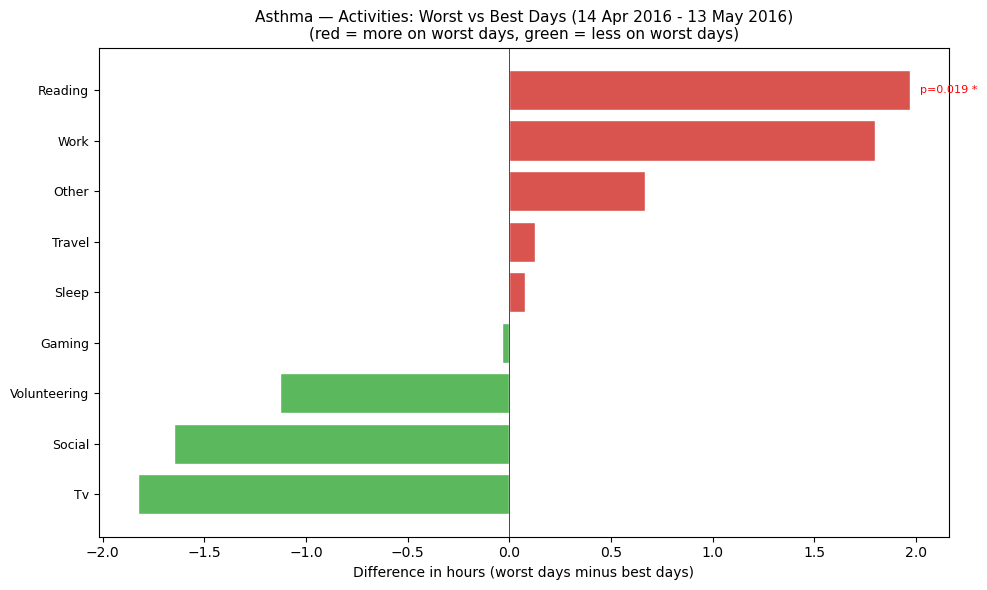


  ACTIVITIES ON WORST vs BEST DAYS:
  Activities associated with HIGHEST symptom scores:
    Reading               +2.0h on worst days  p=0.019 *
    Work                  +1.8h on worst days  p=0.321
    Other                 +0.7h on worst days  p=1.000
    Travel                +0.1h on worst days  p=0.569
  Activities associated with LOWEST symptom scores:
    Tv                    -1.8h on worst days  p=0.286
    Social                -1.6h on worst days  p=0.117
    Volunteering          -1.1h on worst days  p=0.508


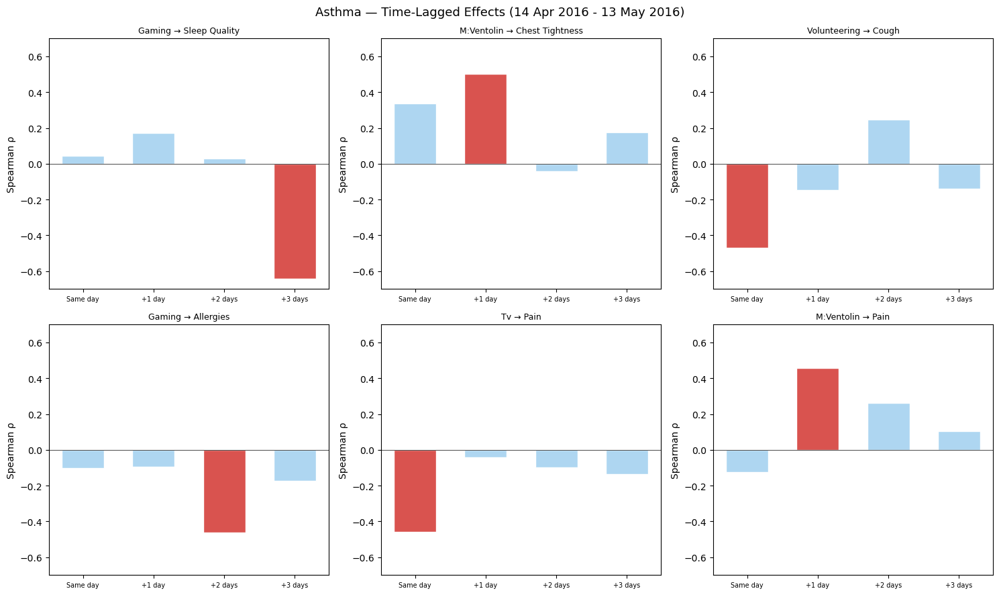


  TIME-LAGGED EFFECTS (strongest associations, p<0.1):
    Gaming               → Sleep Quality         ρ=-0.642  after 3 day(s)  (better) *
    M:Ventolin           → Chest Tightness       ρ=+0.501  after 1 day(s)  (worse) *
    Volunteering         → Cough                 ρ=-0.469  same-day  (better) *
    Gaming               → Allergies             ρ=-0.463  after 2 day(s)  (better) *
    Tv                   → Pain                  ρ=-0.459  same-day  (better) *
    M:Ventolin           → Pain                  ρ=+0.459  after 1 day(s)  (worse) *
    M:Avamys             → Chest Tightness       ρ=+0.446  same-day  (worse) *
    Tv                   → Allergies             ρ=-0.446  after 3 day(s)  (better) *
    Volunteering         → Mood                  ρ=-0.427  after 2 day(s)  (better) *
    Volunteering         → Pain                  ρ=-0.413  after 2 day(s)  (better) *
    Social               → Chest Tightness       ρ=+0.412  after 3 day(s)  (worse) *
    Tv              

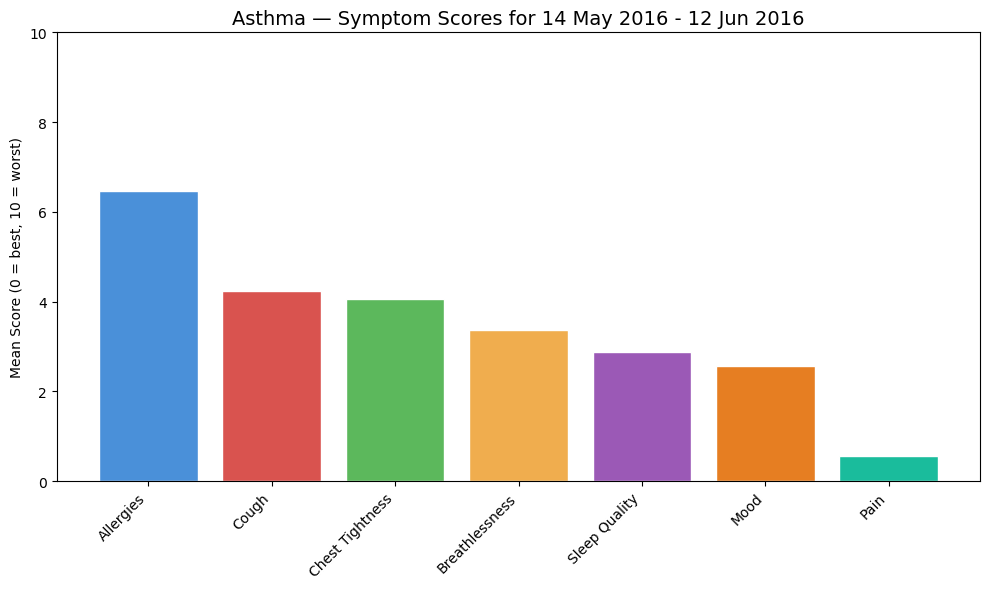

Symptoms with the highest scores in this period were Allergies (6.5), Cough (4.2), and Chest Tightness (4.1).


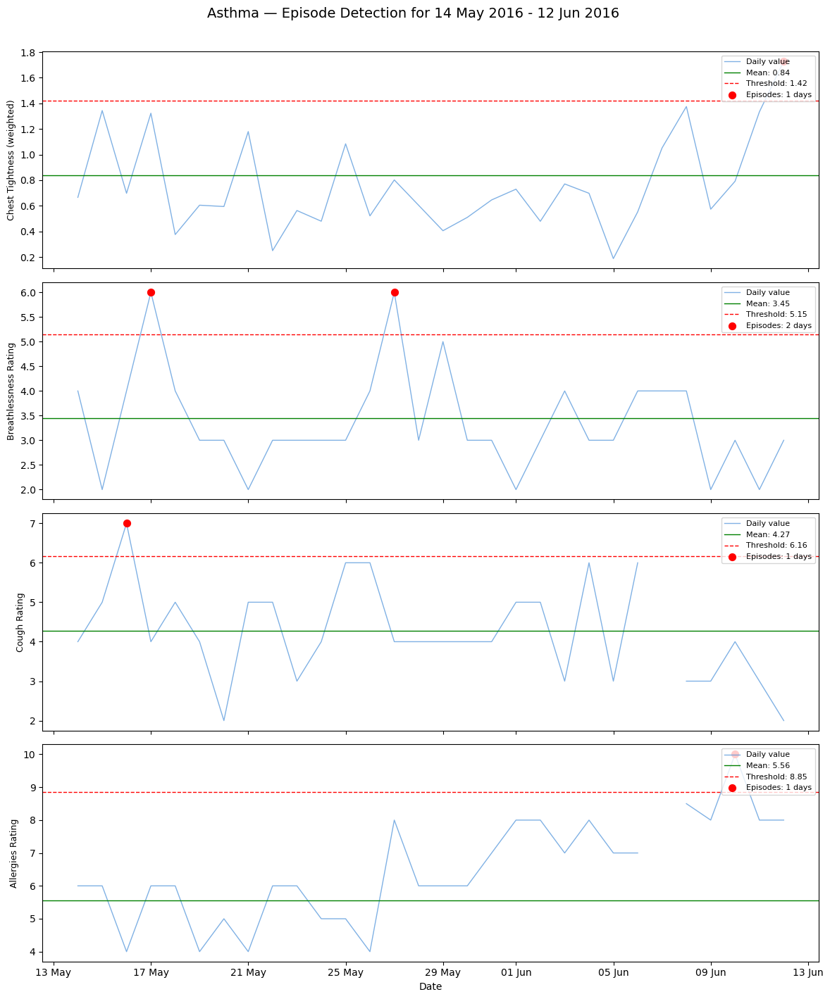

  Total episode days this month: 5

  FLARES OCCURRED ON: 16 May (Monday), 17 May (Tuesday), 27 May (Friday), 10 Jun (Friday), 12 Jun (Sunday)
Worst day in this period: 17 May (composite 5.0/10)
Best day in this period:  11 Jun (composite 2.3/10)


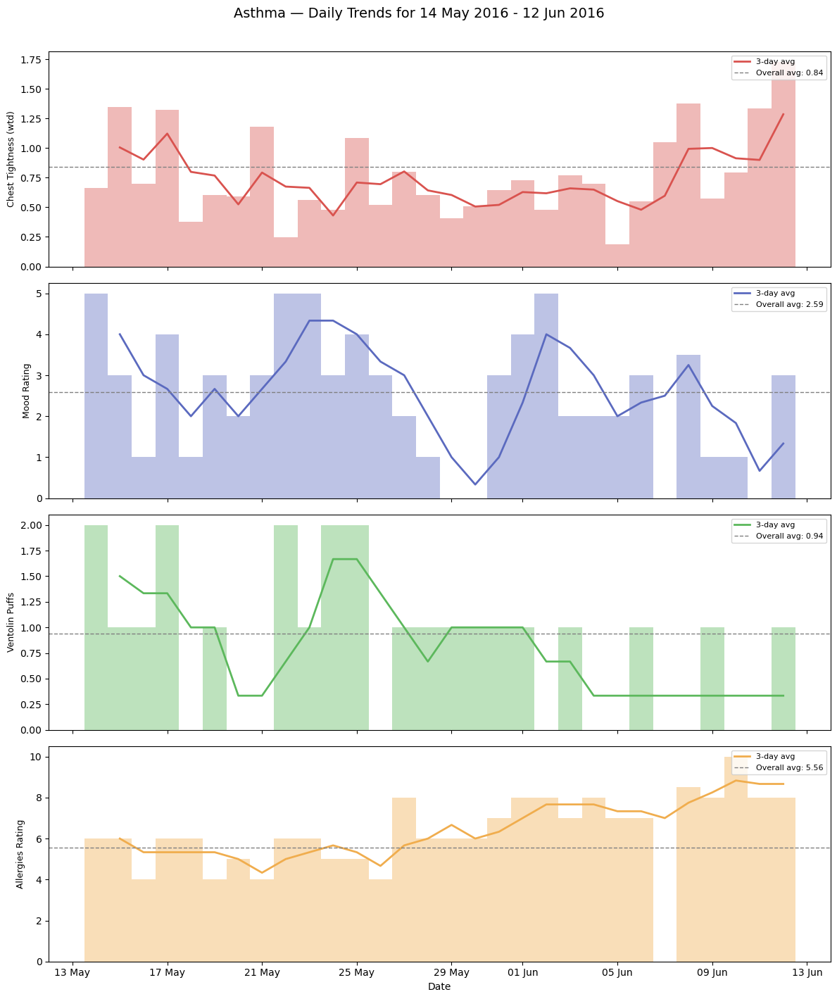

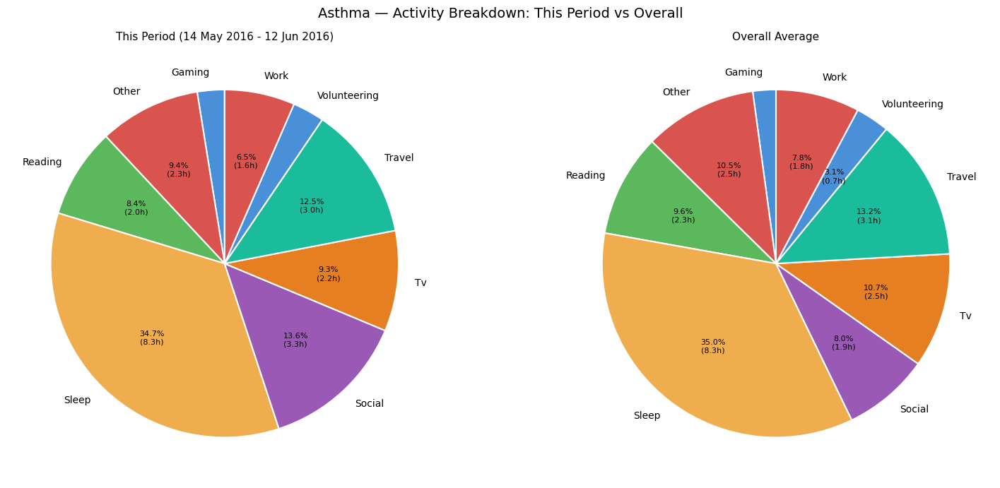

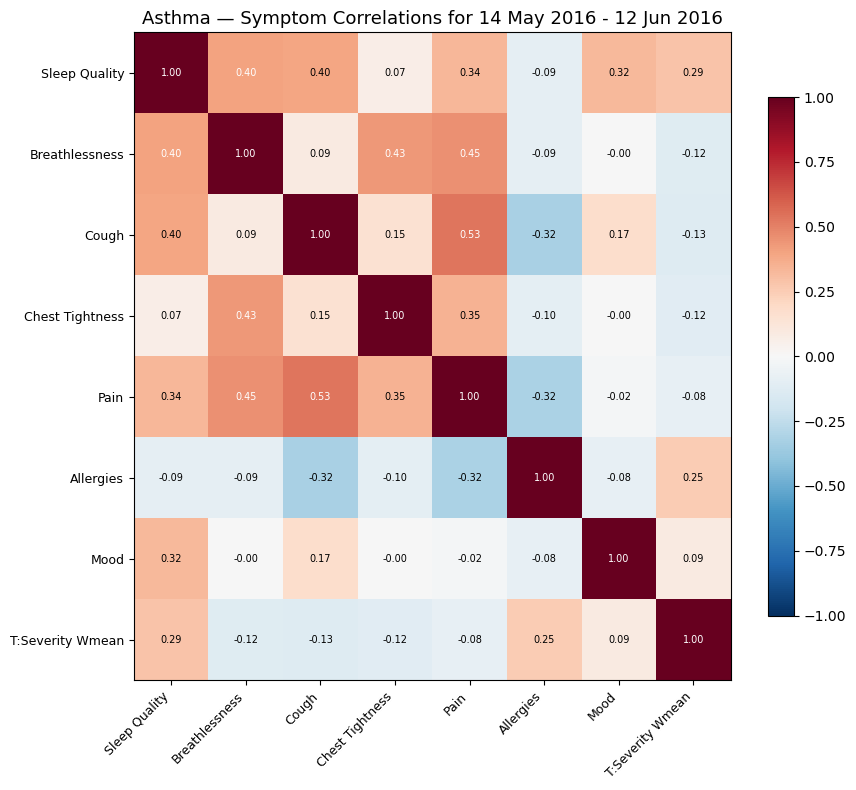


  STRONGEST SYMPTOM CORRELATIONS THIS PERIOD:
    Cough                ↔ Pain                  ρ=+0.532  (strongly move together)
    Breathlessness       ↔ Pain                  ρ=+0.454  (moderately move together)
    Breathlessness       ↔ Chest Tightness       ρ=+0.432  (moderately move together)
    Sleep Quality        ↔ Breathlessness        ρ=+0.403  (moderately move together)
    Sleep Quality        ↔ Cough                 ρ=+0.396  (moderately move together)

  NOTABLE CHANGES FROM OVERALL PATTERN:
    Cough                ↔ Pain                  this period=+0.532  overall=+0.082  (stronger this period)
    Sleep Quality        ↔ Breathlessness        this period=+0.403  overall=+0.067  (stronger this period)
    Sleep Quality        ↔ Cough                 this period=+0.396  overall=+0.132  (stronger this period)
    Pain                 ↔ Allergies             this period=-0.317  overall=+0.056  (stronger this period)
    Allergies            ↔ T:Severity Wmean      thi

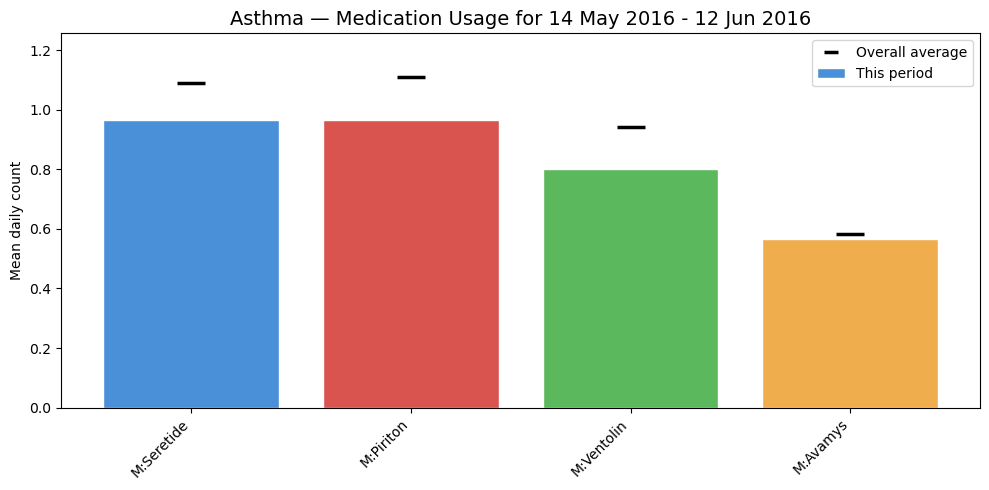


  WHAT YOU TRIED AND WHETHER IT HELPED:
  ──────────────────────────────────────────────────

    M:Ventolin (used on 19 of 30 days):
      Next-day Cough              was still elevated after use (4.6 vs 3.7)

    M:Seretide (used on 23 of 30 days):
      Allergies              was higher on days you used it (6.8 vs 5.2) — but this likely means you reached for it on worse days, not that it made things worse.

    M:Piriton (used on 23 of 30 days):
      Allergies              was higher on days you used it (6.8 vs 5.2) — but this likely means you reached for it on worse days, not that it made things worse.

    M:Avamys (used on 17 of 30 days):
      Sleep Quality          was higher on days you used it (3.4 vs 2.2) — but this likely means you reached for it on worse days, not that it made things worse.
      Allergies              was higher on days you used it (7.1 vs 5.5) — but this likely means you reached for it on worse days, not that it made things worse.
      Mood           

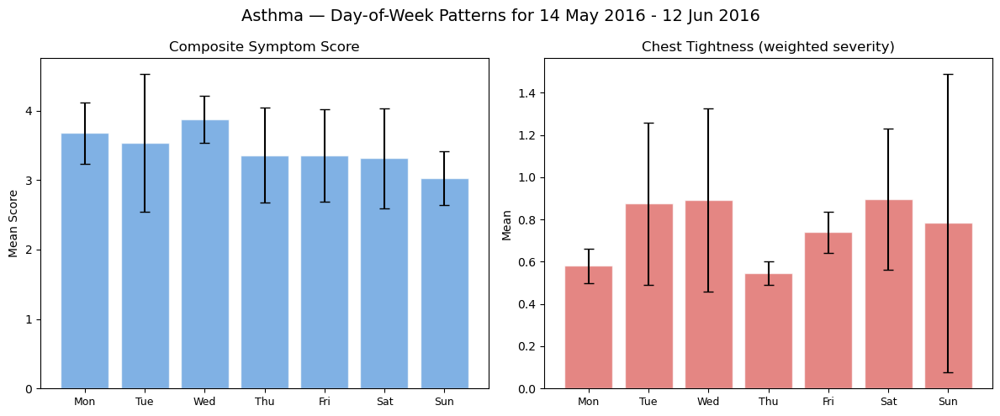

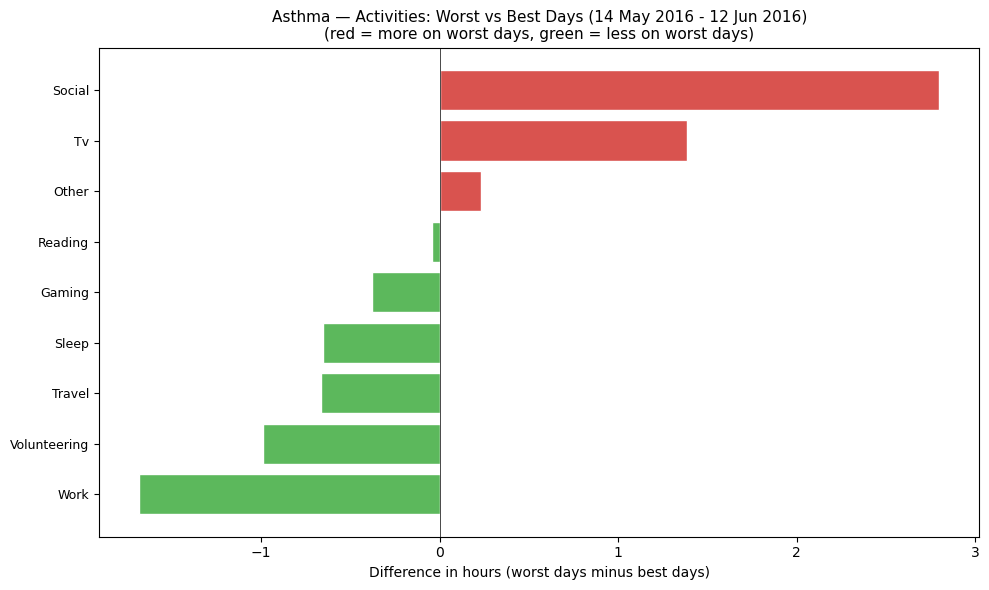


  ACTIVITIES ON WORST vs BEST DAYS:
  Activities associated with HIGHEST symptom scores:
    Social                +2.8h on worst days  p=0.525
    Tv                    +1.4h on worst days  p=0.538
    Other                 +0.2h on worst days  p=1.000
  Activities associated with LOWEST symptom scores:
    Work                  -1.7h on worst days  p=0.285
    Volunteering          -1.0h on worst days  p=0.356
    Travel                -0.7h on worst days  p=0.371
    Sleep                 -0.7h on worst days  p=0.390
    Gaming                -0.4h on worst days  p=0.600


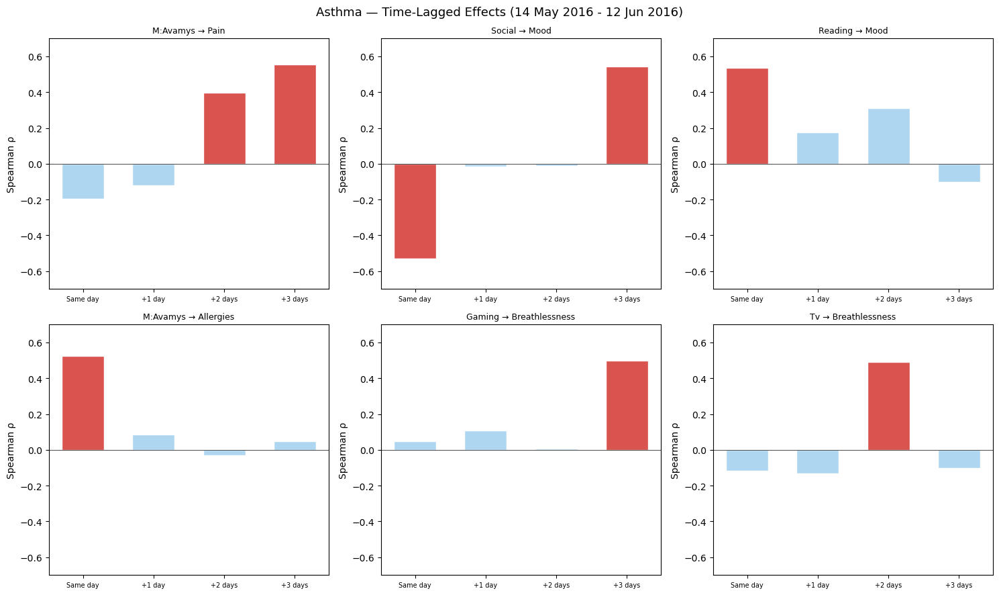


  TIME-LAGGED EFFECTS (strongest associations, p<0.1):
    M:Avamys             → Pain                  ρ=+0.554  after 3 day(s)  (worse) *
    Social               → Mood                  ρ=+0.543  after 3 day(s)  (worse) *
    Reading              → Mood                  ρ=+0.537  same-day  (worse) *
    M:Avamys             → Allergies             ρ=+0.524  same-day  (worse) *
    Gaming               → Breathlessness        ρ=+0.497  after 3 day(s)  (worse) *
    Tv                   → Breathlessness        ρ=+0.489  after 2 day(s)  (worse) *
    M:Piriton            → Mood                  ρ=+0.434  same-day  (worse) *
    M:Seretide           → Mood                  ρ=+0.434  same-day  (worse) *
    Gaming               → Pain                  ρ=+0.426  after 2 day(s)  (worse) *
    Reading              → Sleep Quality         ρ=+0.425  after 2 day(s)  (worse) *
    Social               → Sleep Quality         ρ=-0.412  after 2 day(s)  (better) *
    Tv                   → Mood 

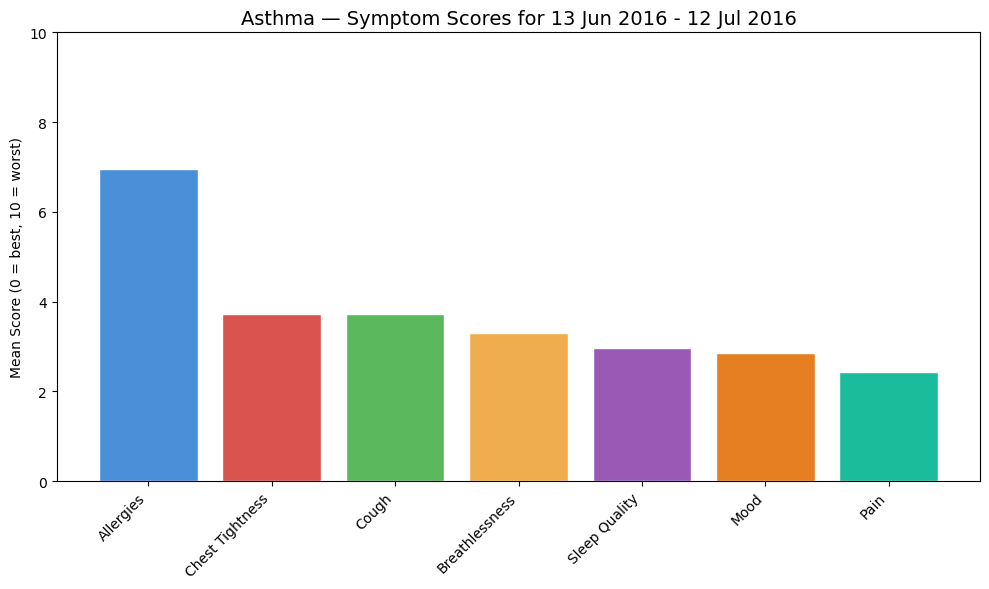

Symptoms with the highest scores in this period were Allergies (7.0), Chest Tightness (3.7), and Cough (3.7).


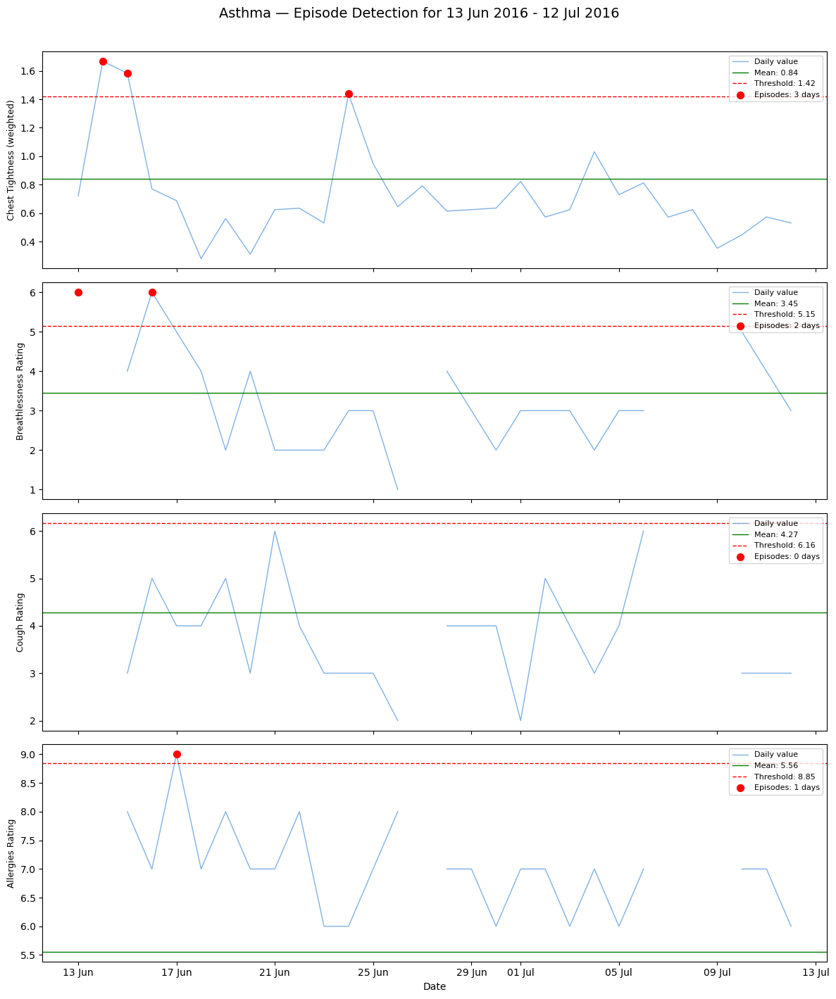

  Total episode days this month: 6

  FLARES OCCURRED ON: 13 Jun (Monday), 14 Jun (Tuesday), 15 Jun (Wednesday), 16 Jun (Thursday), 17 Jun (Friday), 24 Jun (Friday)
Worst day in this period: 10 Jul (composite 6.0/10)
Best day in this period:  23 Jun (composite 2.7/10)


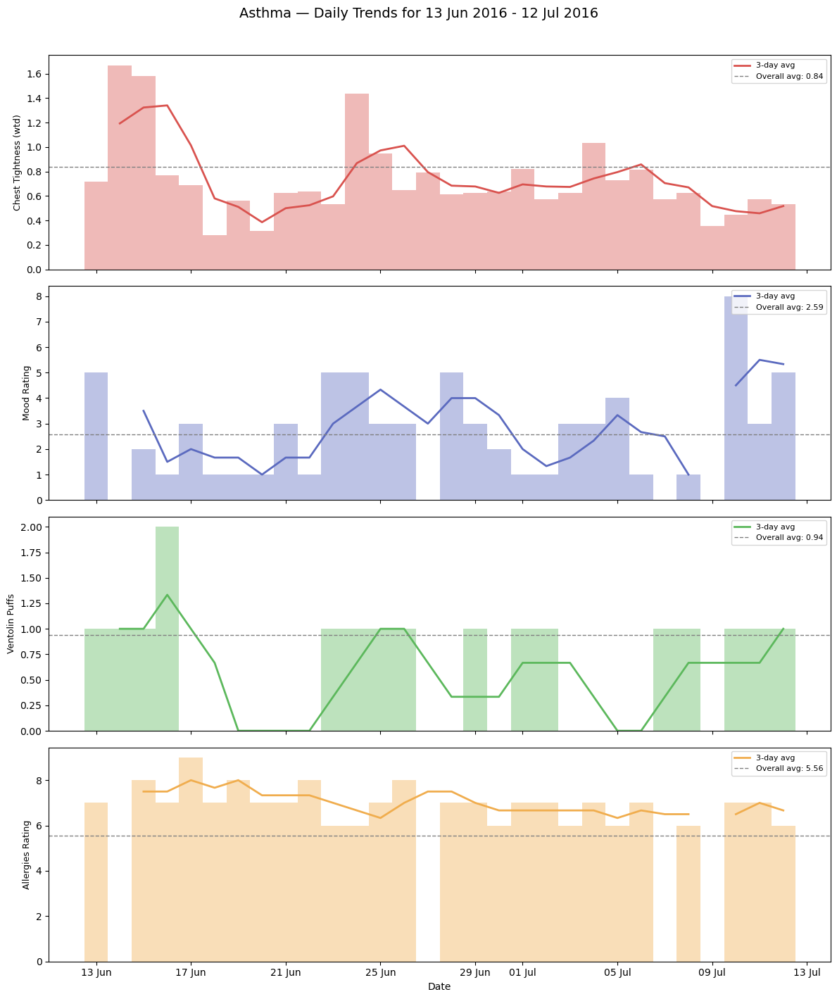

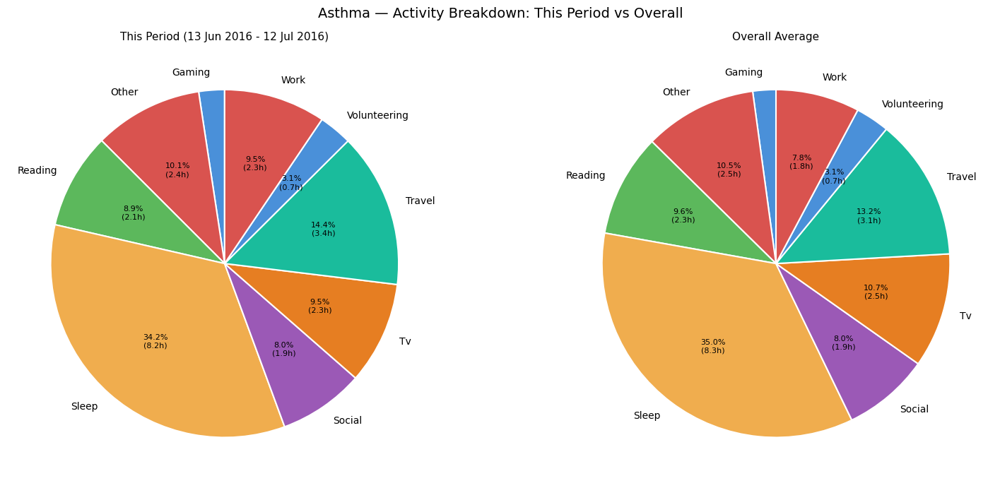

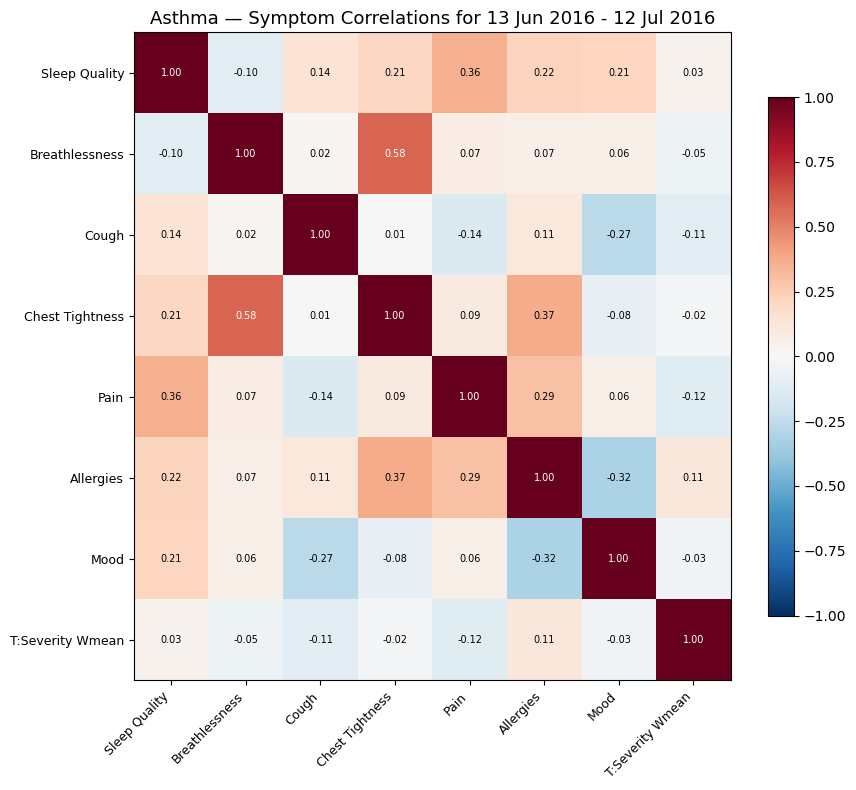


  STRONGEST SYMPTOM CORRELATIONS THIS PERIOD:
    Breathlessness       ↔ Chest Tightness       ρ=+0.582  (strongly move together)
    Chest Tightness      ↔ Allergies             ρ=+0.372  (moderately move together)
    Sleep Quality        ↔ Pain                  ρ=+0.358  (moderately move together)
    Allergies            ↔ Mood                  ρ=-0.319  (moderately move inversely)
    Pain                 ↔ Allergies             ρ=+0.290  (moderately move together)

  NOTABLE CHANGES FROM OVERALL PATTERN:
    Chest Tightness      ↔ Allergies             this period=+0.372  overall=-0.071  (stronger this period)
    Allergies            ↔ Mood                  this period=-0.319  overall=+0.131  (stronger this period)
    Sleep Quality        ↔ Allergies             this period=+0.222  overall=-0.037  (stronger this period)
    Cough                ↔ Allergies             this period=+0.109  overall=-0.283  (weaker this period)
    Breathlessness       ↔ T:Severity Wmean      this

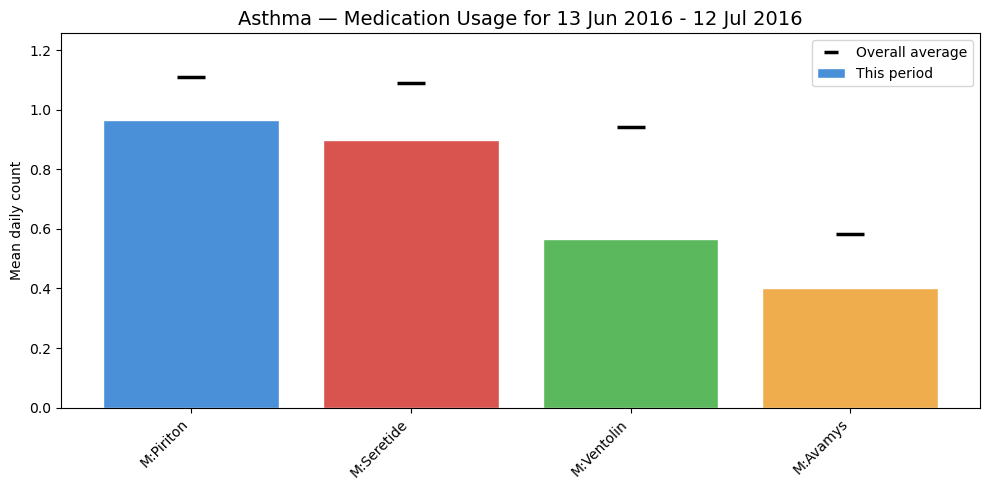


  WHAT YOU TRIED AND WHETHER IT HELPED:
  ──────────────────────────────────────────────────

    M:Ventolin (used on 16 of 30 days):
      Cough                  was lower on days you used it (3.3 vs 4.2, p=0.014) — this suggests it may have helped.

    M:Seretide (used on 23 of 30 days):

    M:Piriton (used on 24 of 30 days):

    M:Avamys (used on 12 of 30 days):
      Cough                  was lower on days you used it (3.4 vs 4.0, p=0.061) — this suggests it may have helped.


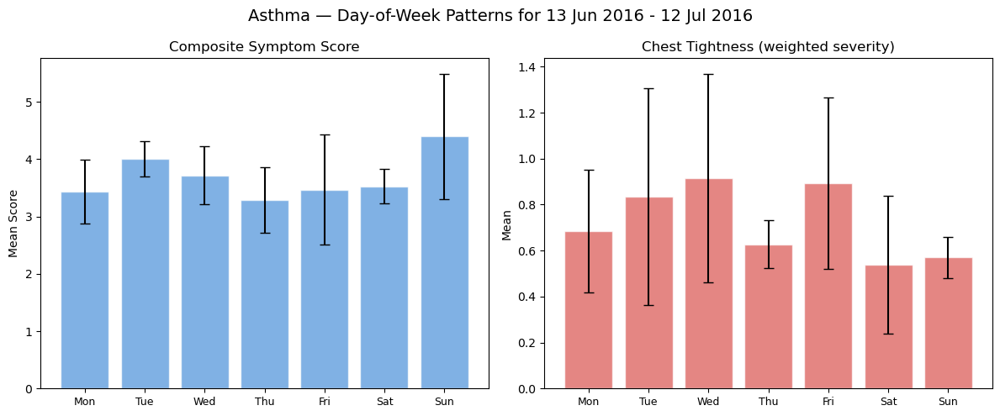

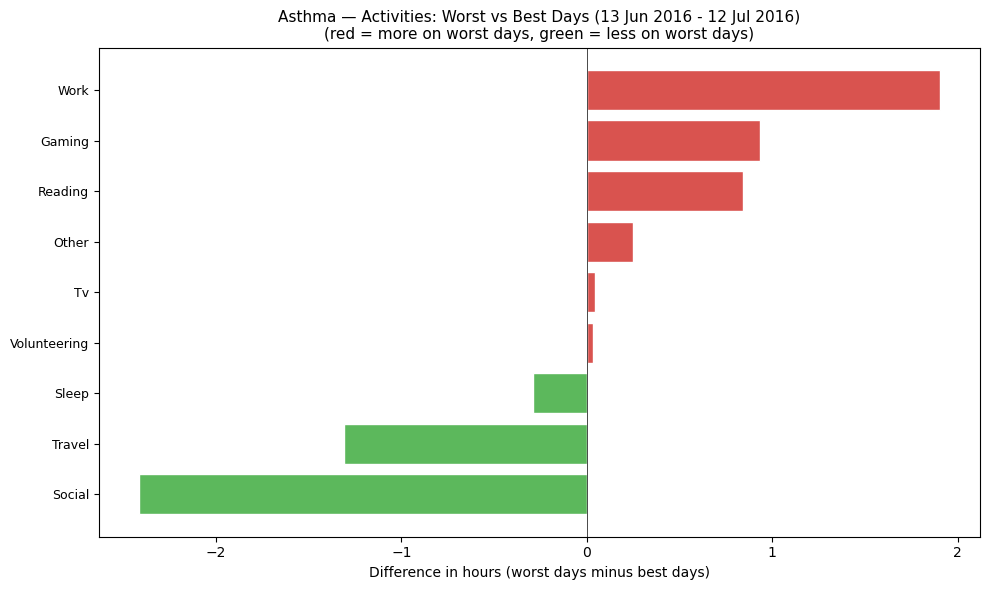


  ACTIVITIES ON WORST vs BEST DAYS:
  Activities associated with HIGHEST symptom scores:
    Work                  +1.9h on worst days  p=0.388
    Gaming                +0.9h on worst days  p=0.108
    Reading               +0.8h on worst days  p=0.273
    Other                 +0.3h on worst days  p=0.930
  Activities associated with LOWEST symptom scores:
    Social                -2.4h on worst days  p=0.158
    Travel                -1.3h on worst days  p=0.189
    Sleep                 -0.3h on worst days  p=0.662


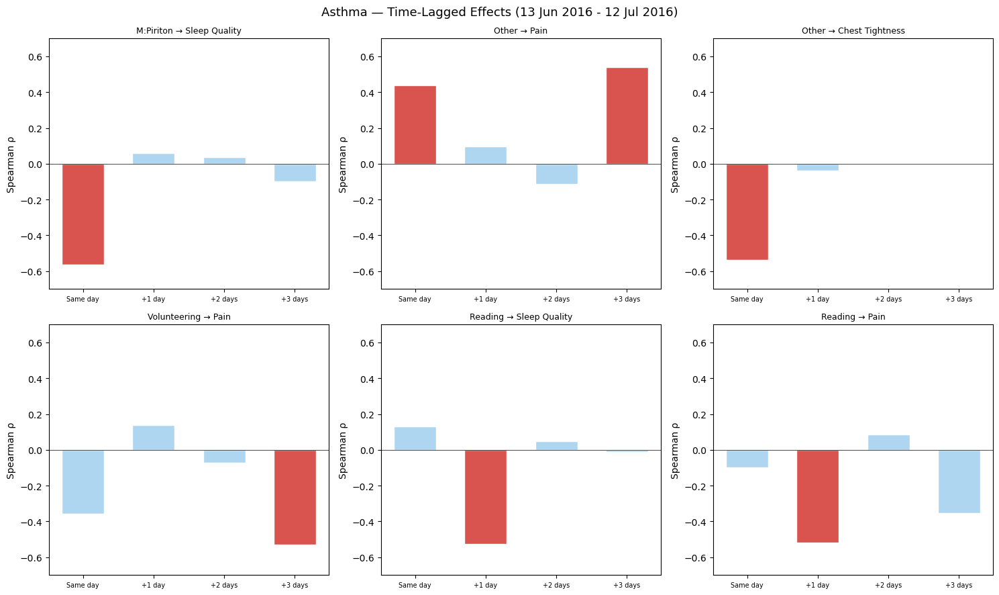


  TIME-LAGGED EFFECTS (strongest associations, p<0.1):
    M:Piriton            → Sleep Quality         ρ=-0.564  same-day  (better) *
    Other                → Pain                  ρ=+0.540  after 3 day(s)  (worse) *
    Other                → Chest Tightness       ρ=-0.536  same-day  (better) *
    Volunteering         → Pain                  ρ=-0.531  after 3 day(s)  (better) *
    Reading              → Sleep Quality         ρ=-0.527  after 1 day(s)  (better) *
    Reading              → Pain                  ρ=-0.520  after 1 day(s)  (better) *
    Sleep                → Mood                  ρ=-0.512  same-day  (better) *
    Gaming               → Pain                  ρ=-0.494  after 3 day(s)  (better) *
    M:Seretide           → Sleep Quality         ρ=-0.492  same-day  (better) *
    M:Ventolin           → Allergies             ρ=+0.488  after 3 day(s)  (worse) *
    Reading              → Mood                  ρ=-0.470  after 3 day(s)  (better) *
    Volunteering        

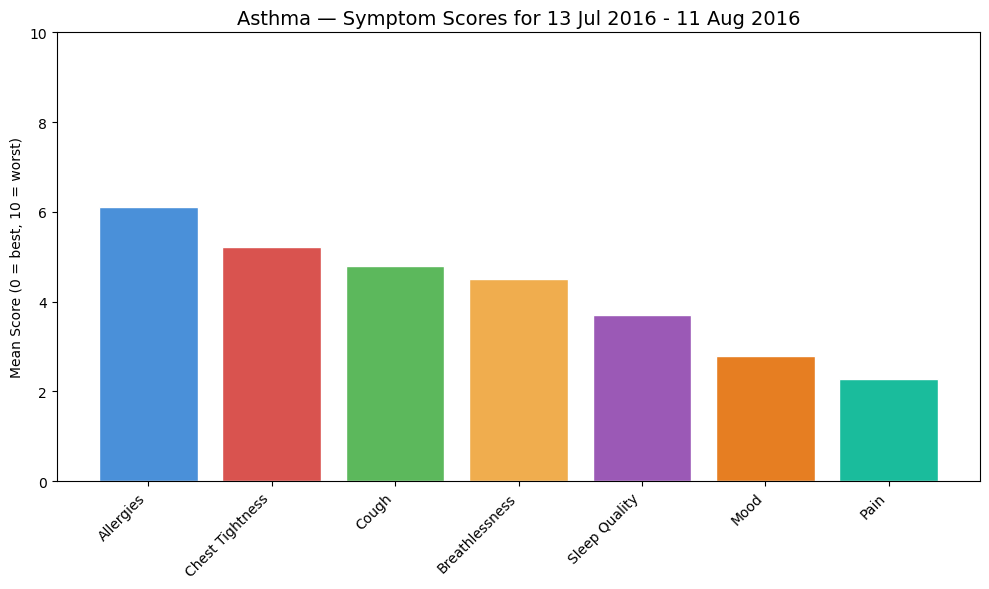

Symptoms with the highest scores in this period were Allergies (6.1), Chest Tightness (5.2), and Cough (4.8).

  Episode detection skipped — not enough data this period.


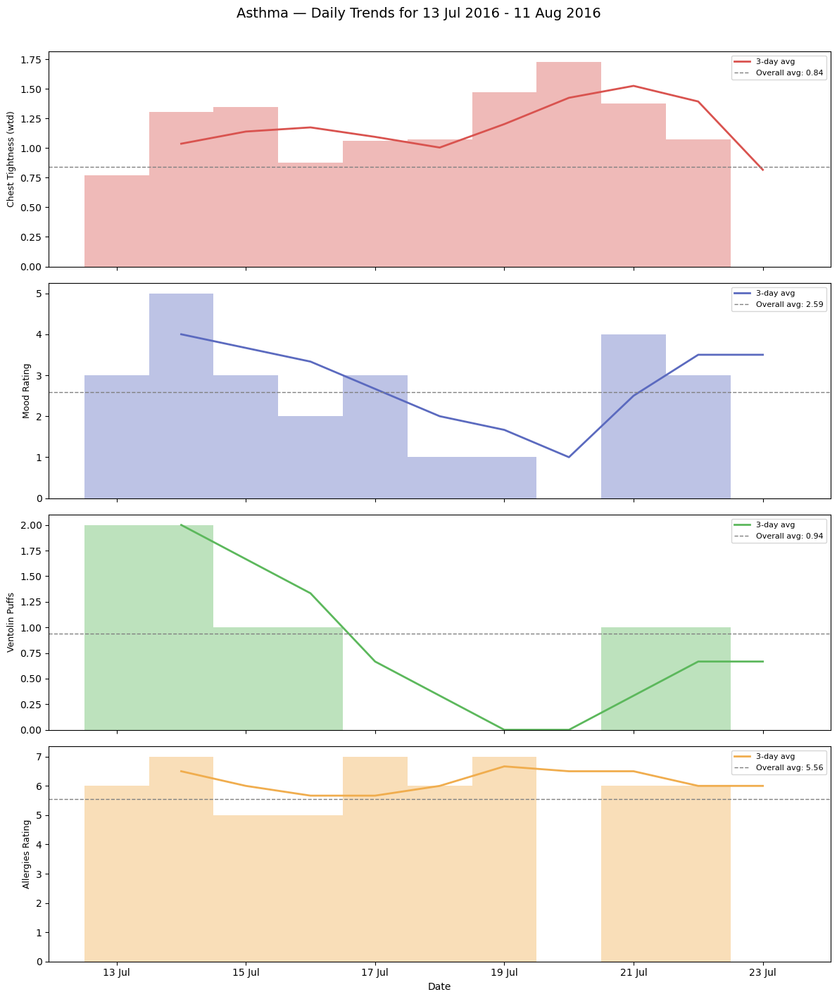

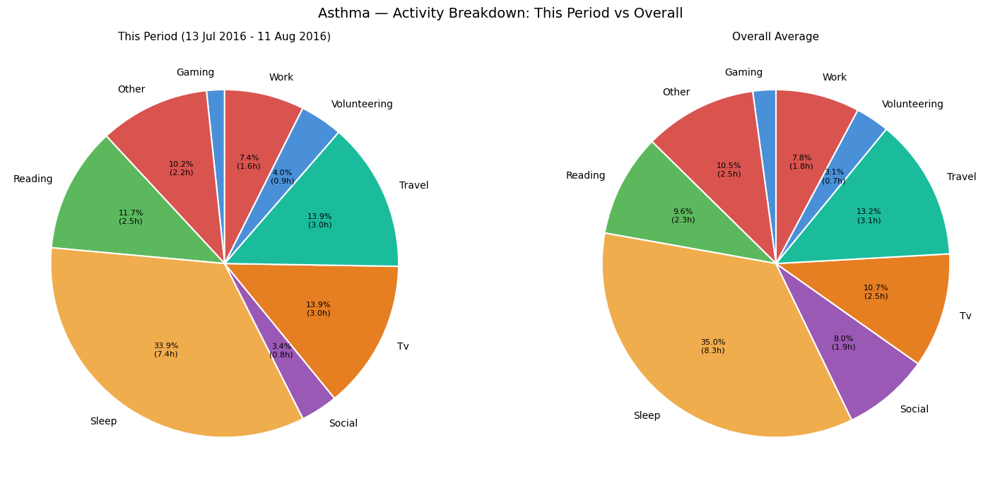

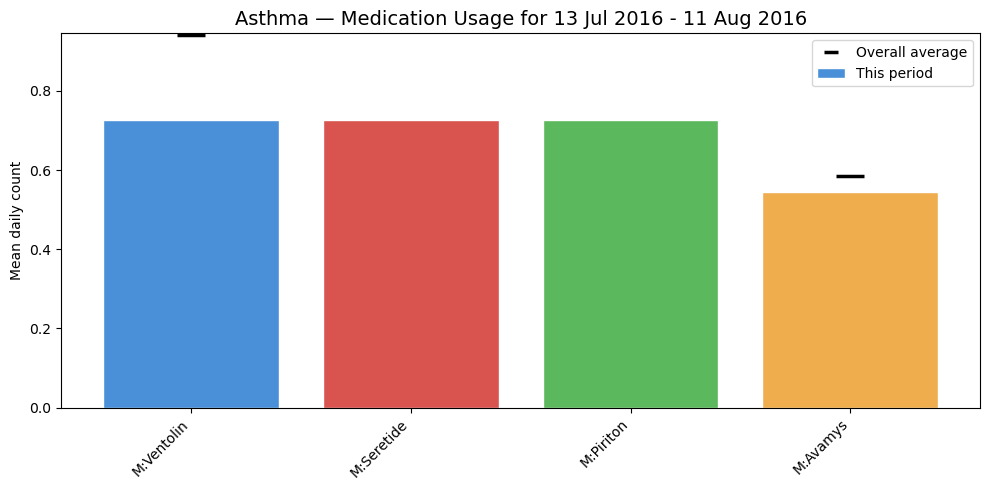


  WHAT YOU TRIED AND WHETHER IT HELPED:
  ──────────────────────────────────────────────────

    M:Ventolin (used on 6 of 11 days):

    M:Seretide (used on 6 of 11 days):

    M:Piriton (used on 6 of 11 days):

    M:Avamys (used on 6 of 11 days):


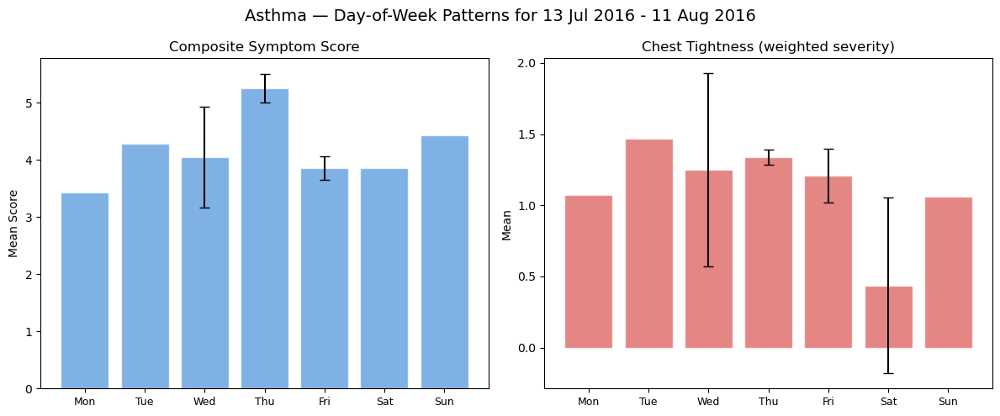


  Insufficient worst/best days for activity comparison (worst=4, best=1)

  Insufficient data for lag analysis in this period

  TRIGGERS OF CHEST TIGHTNESS (WEIGHTED SEVERITY):
    No significant triggers identified in this period

  RELIEVERS:
    No significant relievers identified in this period

  APPEARED TO HAVE NO SIGNIFICANT EFFECT ON SYMPTOMS:
    Gaming, Other, Sleep, Travel, Volunteering, M:Ventolin, M:Seretide, M:Piriton, M:Avamys
    (all p>0.3)

  WITH REGARD TO CHEST TIGHTNESS (WEIGHTED SEVERITY):
    Work appeared to have most effect in exacerbation (ρ=+0.540, p=0.0866)
    Social appeared to have most effect in relief (ρ=-0.476, p=0.1391)

  COMPARED TO PREVIOUS 30-DAY WINDOW (13 Jun – 12 Jul):
    Sleep Quality              prev=2.96  now=3.70  (+0.74, worse)
    Breathlessness             prev=3.31  now=4.50  (+1.19, worse)
    Cough                      prev=3.73  now=4.80  (+1.07, worse)
    Chest Tightness            prev=3.73  now=5.22  (+1.49, worse)
    Pain 

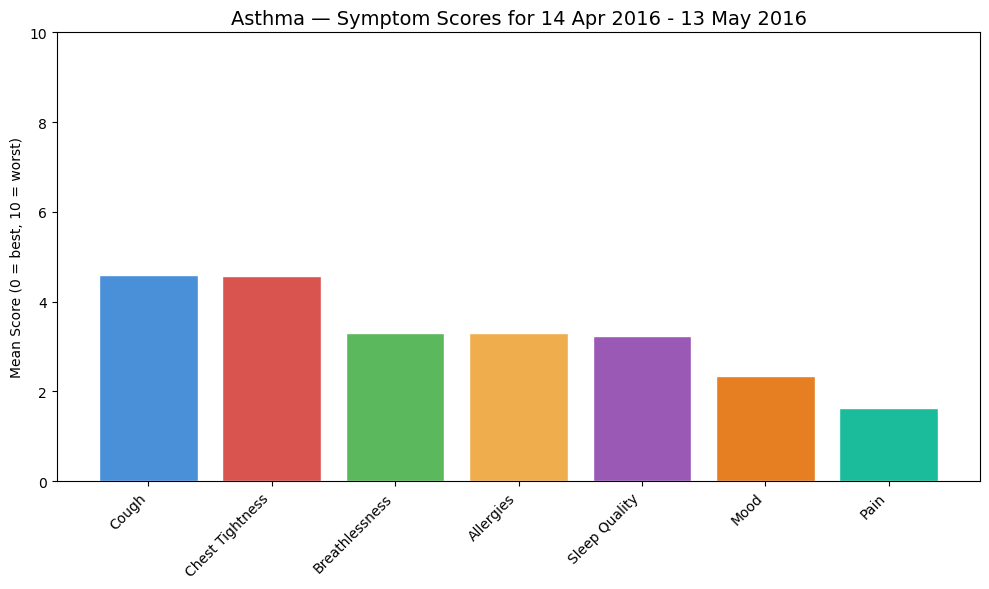

Symptoms with the highest scores in this period were Cough (4.6), Chest Tightness (4.6), and Breathlessness (3.3).


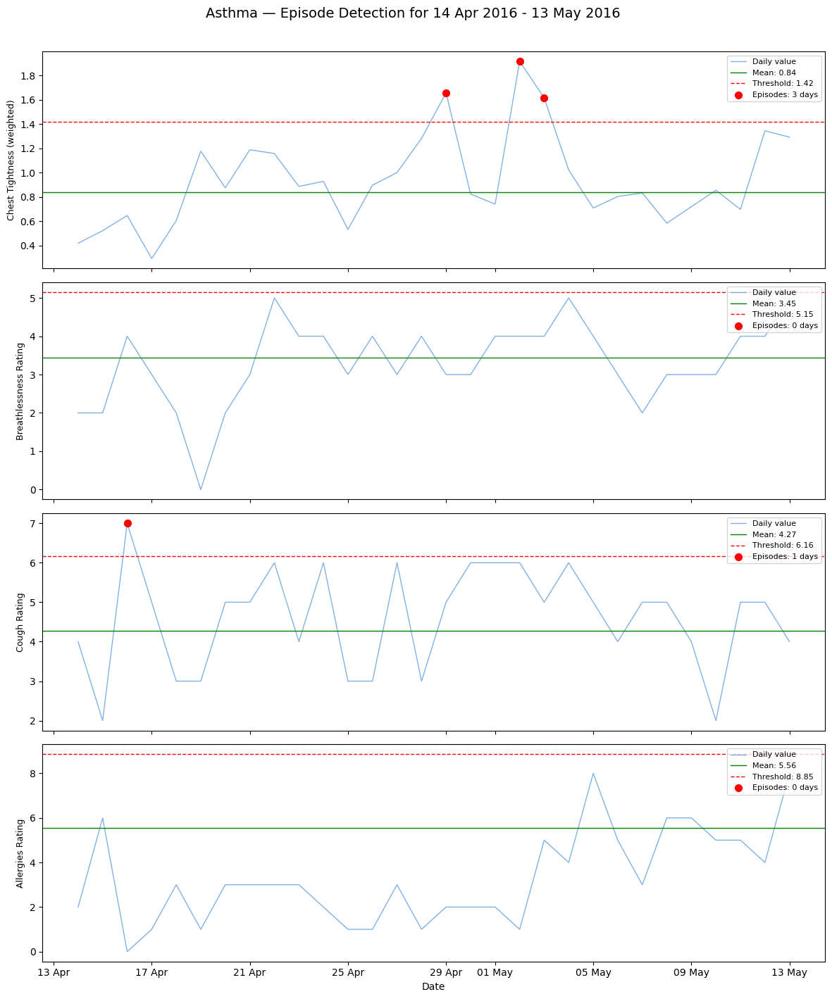

  Total episode days this month: 4

  FLARES OCCURRED ON: 16 Apr (Saturday), 29 Apr (Friday), 02 May (Monday), 03 May (Tuesday)
Worst day in this period: 05 May (composite 5.0/10)
Best day in this period:  19 Apr (composite 1.7/10)


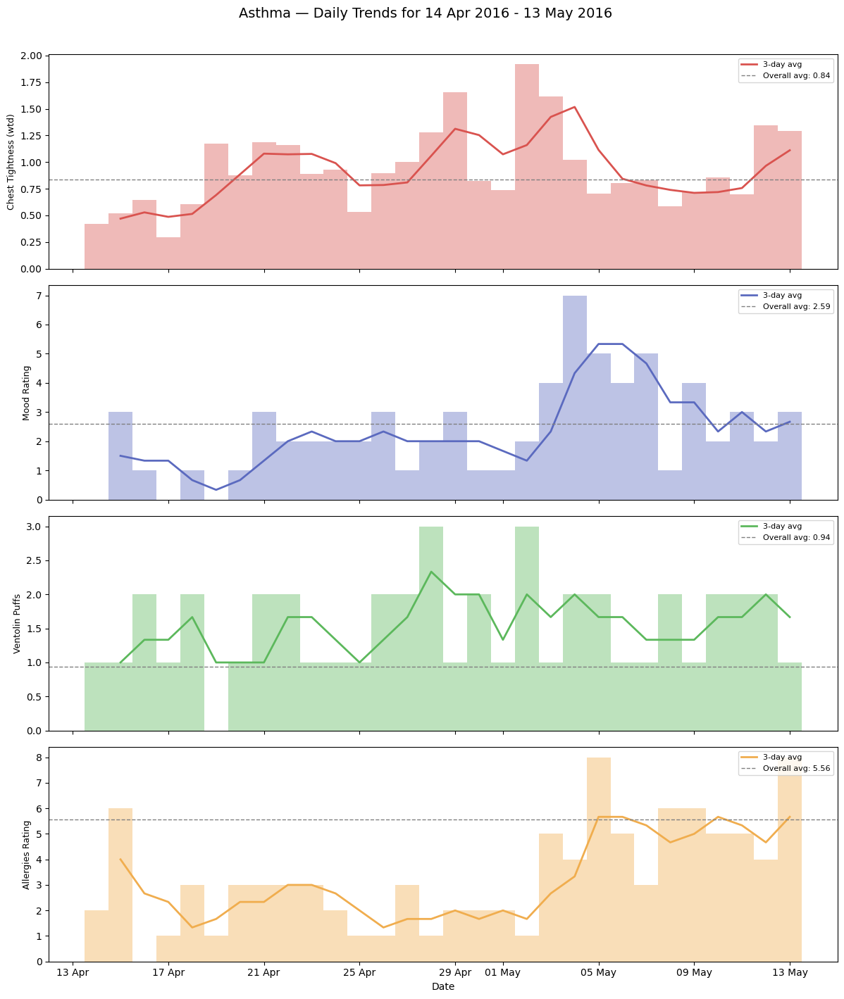

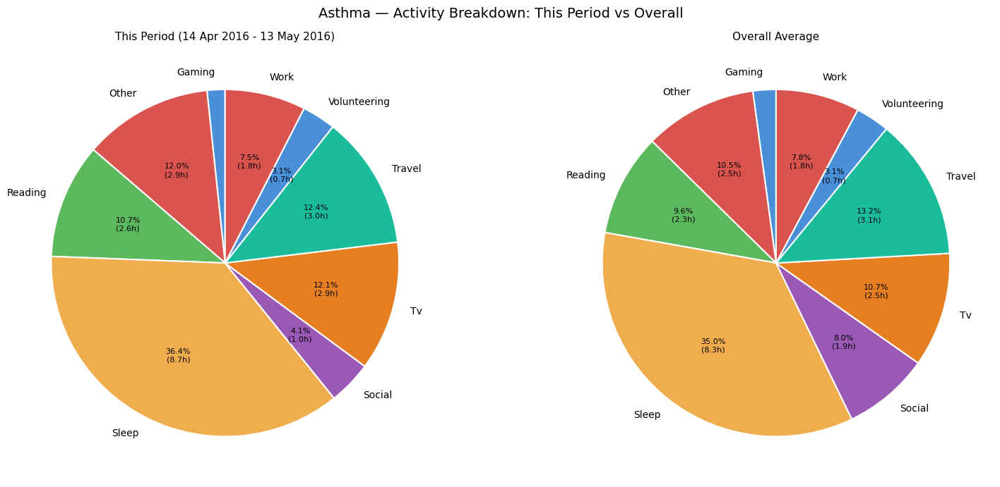

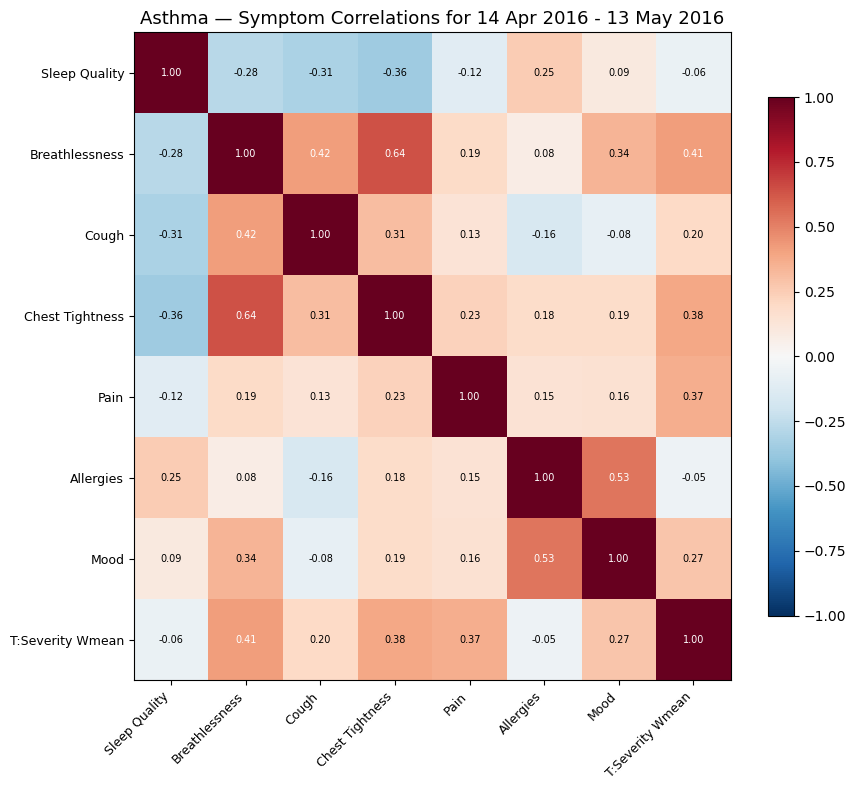


  STRONGEST SYMPTOM CORRELATIONS THIS PERIOD:
    Breathlessness       ↔ Chest Tightness       ρ=+0.638  (strongly move together)
    Allergies            ↔ Mood                  ρ=+0.533  (strongly move together)
    Breathlessness       ↔ Cough                 ρ=+0.416  (moderately move together)
    Breathlessness       ↔ T:Severity Wmean      ρ=+0.414  (moderately move together)
    Chest Tightness      ↔ T:Severity Wmean      ρ=+0.384  (moderately move together)

  NOTABLE CHANGES FROM OVERALL PATTERN:
    Allergies            ↔ Mood                  this period=+0.533  overall=+0.131  (stronger this period)
    Sleep Quality        ↔ Chest Tightness       this period=-0.358  overall=+0.066  (stronger this period)
    Sleep Quality        ↔ Cough                 this period=-0.313  overall=+0.132  (stronger this period)
    Sleep Quality        ↔ Breathlessness        this period=-0.279  overall=+0.067  (stronger this period)
    Sleep Quality        ↔ Allergies             this 

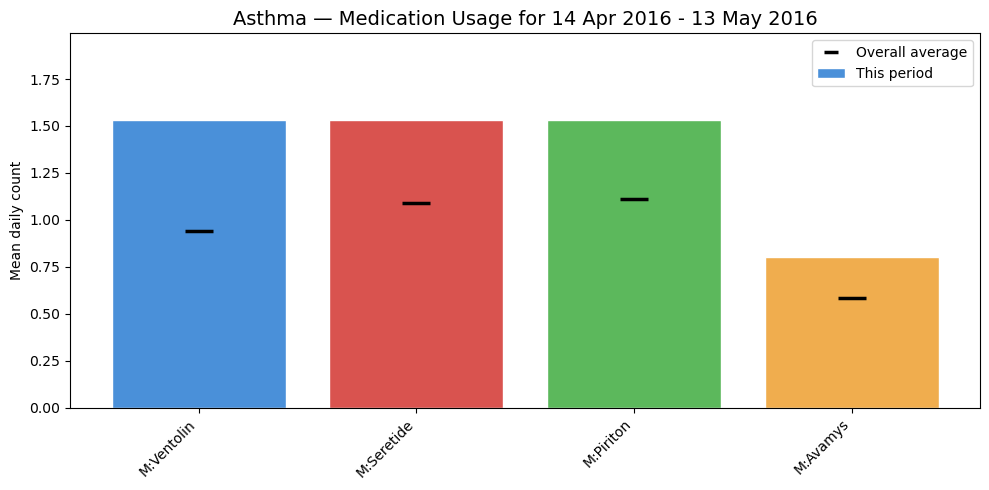


  WHAT YOU TRIED AND WHETHER IT HELPED:
  ──────────────────────────────────────────────────

    M:Ventolin: used on 29 of 30 days — taken too consistently to compare with/without. This is typical for routine preventers and means the medication's effect can't be isolated from daily data alone.

    M:Seretide: used on 29 of 30 days — taken too consistently to compare with/without. This is typical for routine preventers and means the medication's effect can't be isolated from daily data alone.

    M:Piriton: used on 28 of 30 days — taken too consistently to compare with/without. This is typical for routine preventers and means the medication's effect can't be isolated from daily data alone.

    M:Avamys (used on 24 of 30 days):
      Breathlessness         was higher on days you used it (3.5 vs 2.5) — but this likely means you reached for it on worse days, not that it made things worse.
      Chest Tightness        was higher on days you used it (4.9 vs 3.2) — but this likely means 

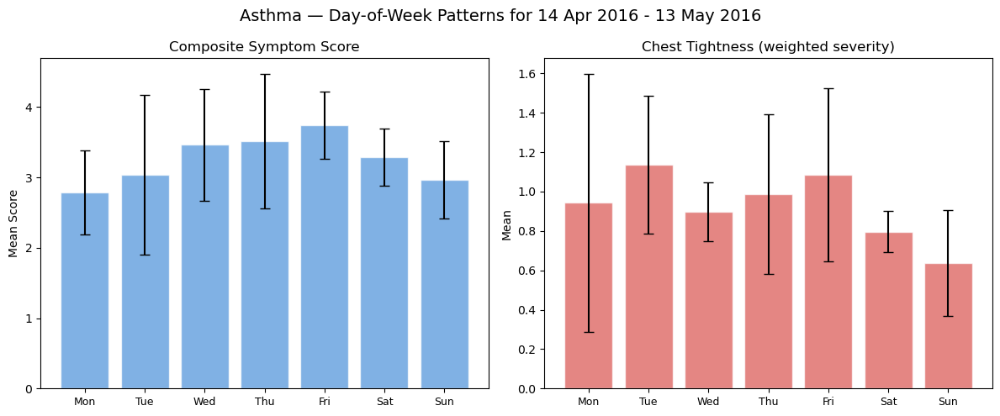

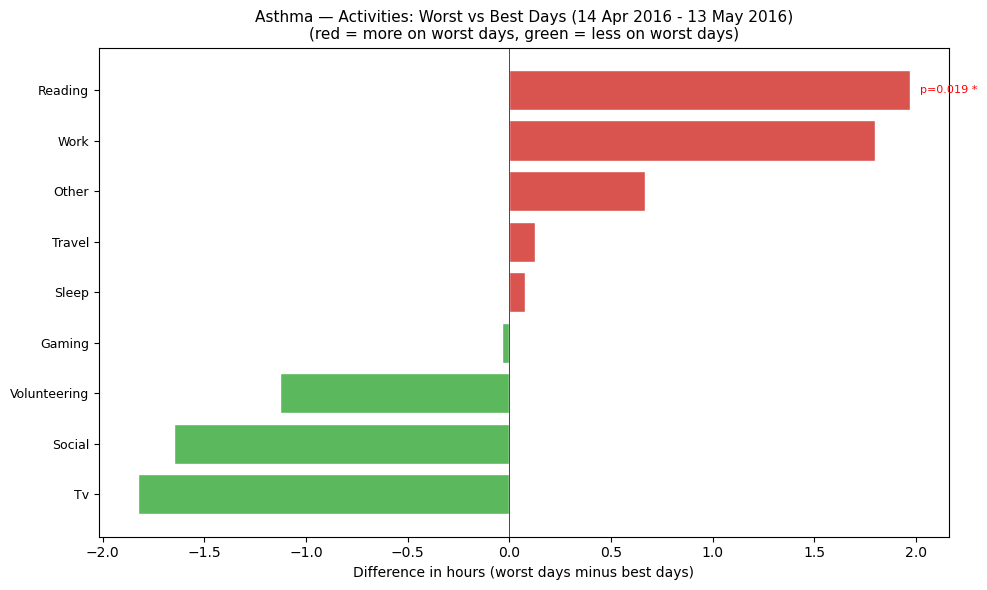


  ACTIVITIES ON WORST vs BEST DAYS:
  Activities associated with HIGHEST symptom scores:
    Reading               +2.0h on worst days  p=0.019 *
    Work                  +1.8h on worst days  p=0.321
    Other                 +0.7h on worst days  p=1.000
    Travel                +0.1h on worst days  p=0.569
  Activities associated with LOWEST symptom scores:
    Tv                    -1.8h on worst days  p=0.286
    Social                -1.6h on worst days  p=0.117
    Volunteering          -1.1h on worst days  p=0.508


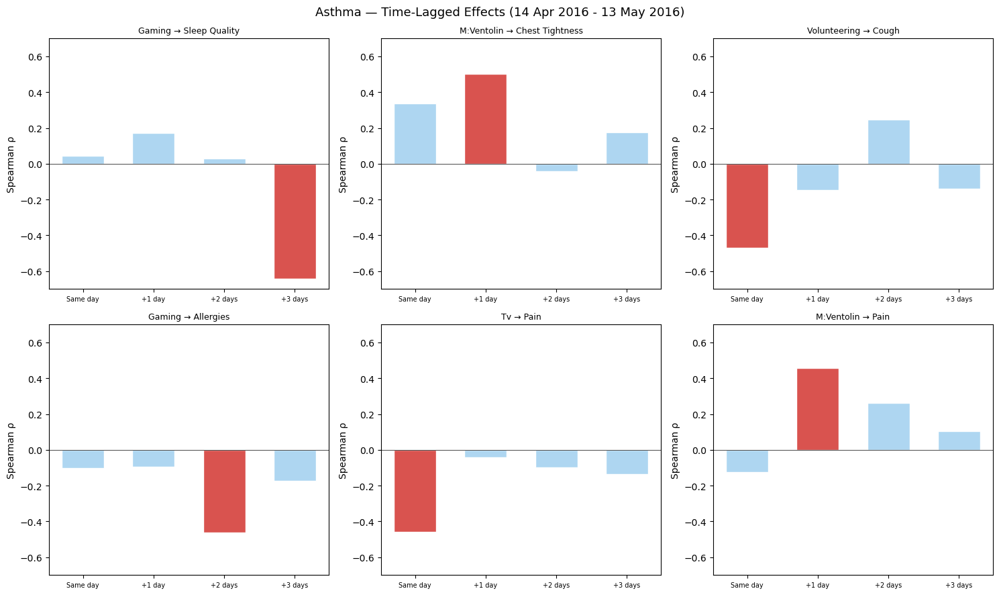


  TIME-LAGGED EFFECTS (strongest associations, p<0.1):
    Gaming               → Sleep Quality         ρ=-0.642  after 3 day(s)  (better) *
    M:Ventolin           → Chest Tightness       ρ=+0.501  after 1 day(s)  (worse) *
    Volunteering         → Cough                 ρ=-0.469  same-day  (better) *
    Gaming               → Allergies             ρ=-0.463  after 2 day(s)  (better) *
    Tv                   → Pain                  ρ=-0.459  same-day  (better) *
    M:Ventolin           → Pain                  ρ=+0.459  after 1 day(s)  (worse) *
    M:Avamys             → Chest Tightness       ρ=+0.446  same-day  (worse) *
    Tv                   → Allergies             ρ=-0.446  after 3 day(s)  (better) *
    Volunteering         → Mood                  ρ=-0.427  after 2 day(s)  (better) *
    Volunteering         → Pain                  ρ=-0.413  after 2 day(s)  (better) *
    Social               → Chest Tightness       ρ=+0.412  after 3 day(s)  (worse) *
    Tv              

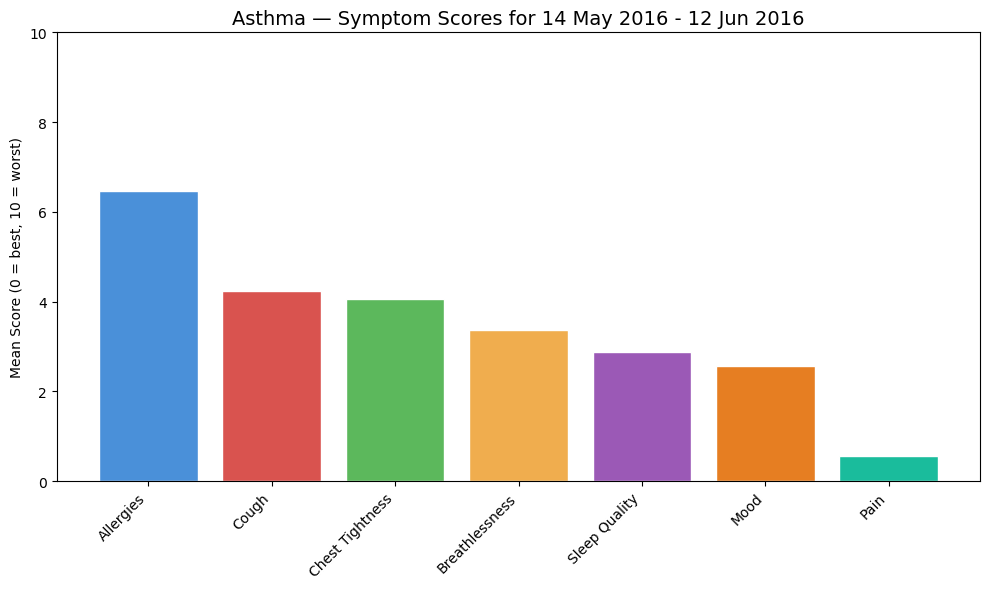

Symptoms with the highest scores in this period were Allergies (6.5), Cough (4.2), and Chest Tightness (4.1).


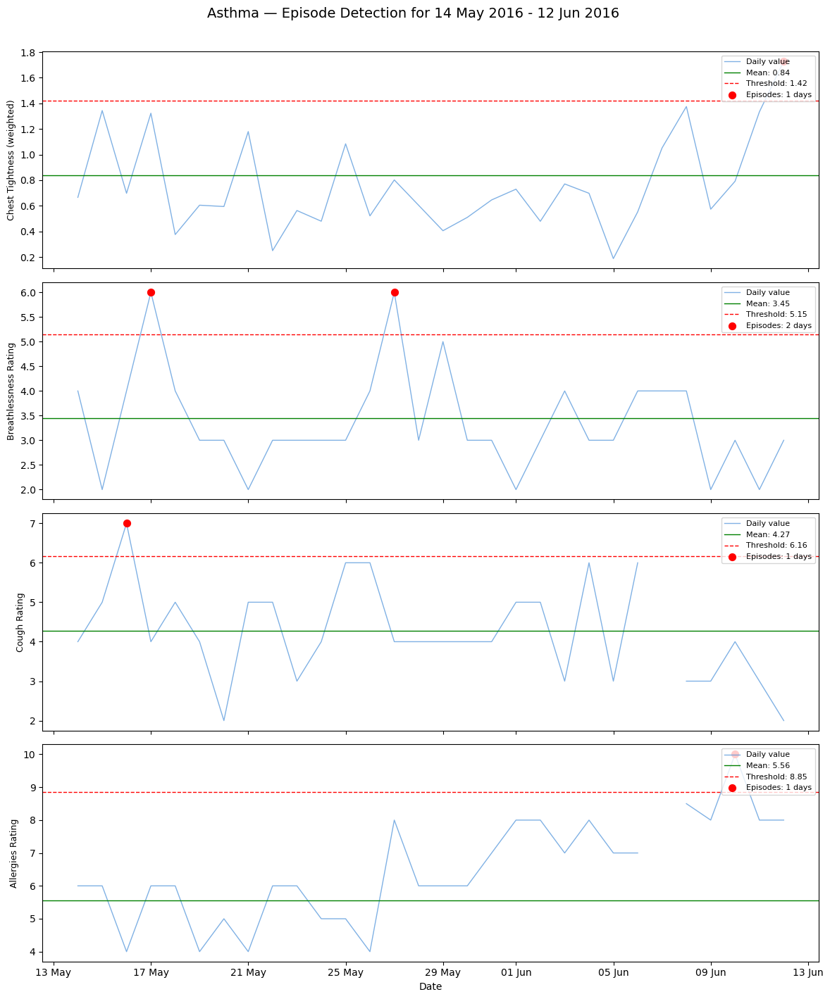

  Total episode days this month: 5

  FLARES OCCURRED ON: 16 May (Monday), 17 May (Tuesday), 27 May (Friday), 10 Jun (Friday), 12 Jun (Sunday)
Worst day in this period: 17 May (composite 5.0/10)
Best day in this period:  11 Jun (composite 2.3/10)


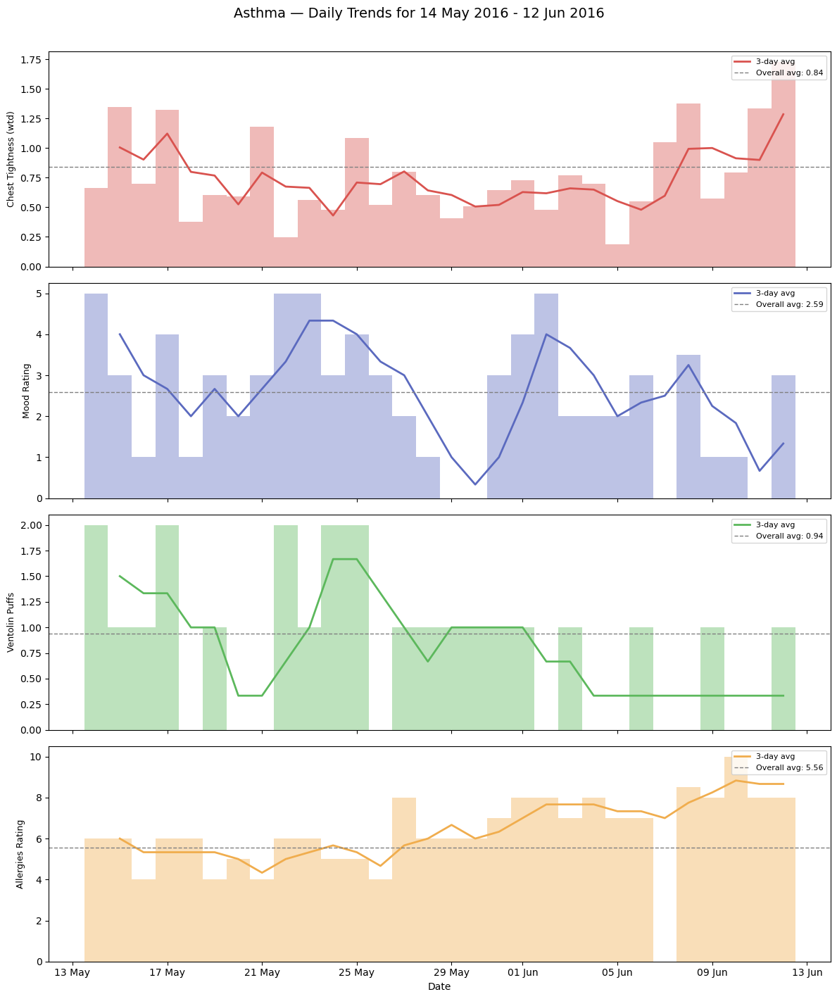

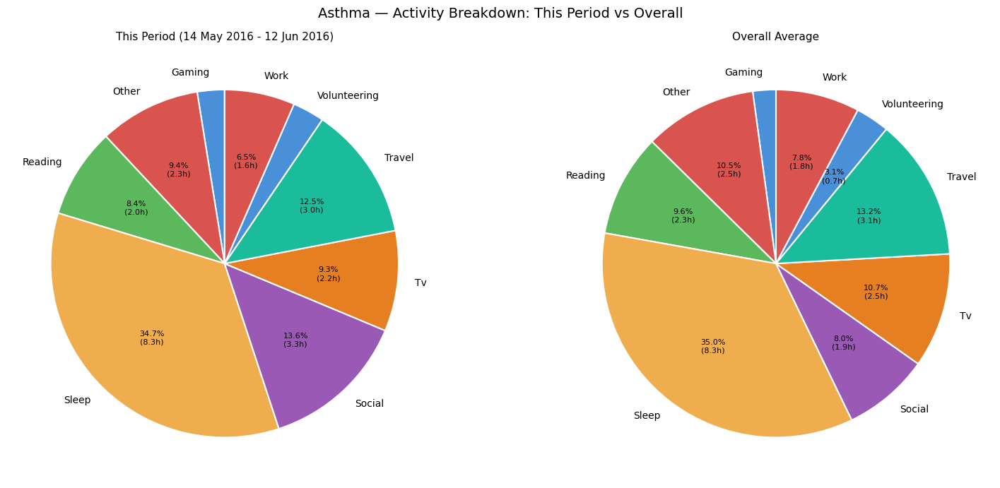

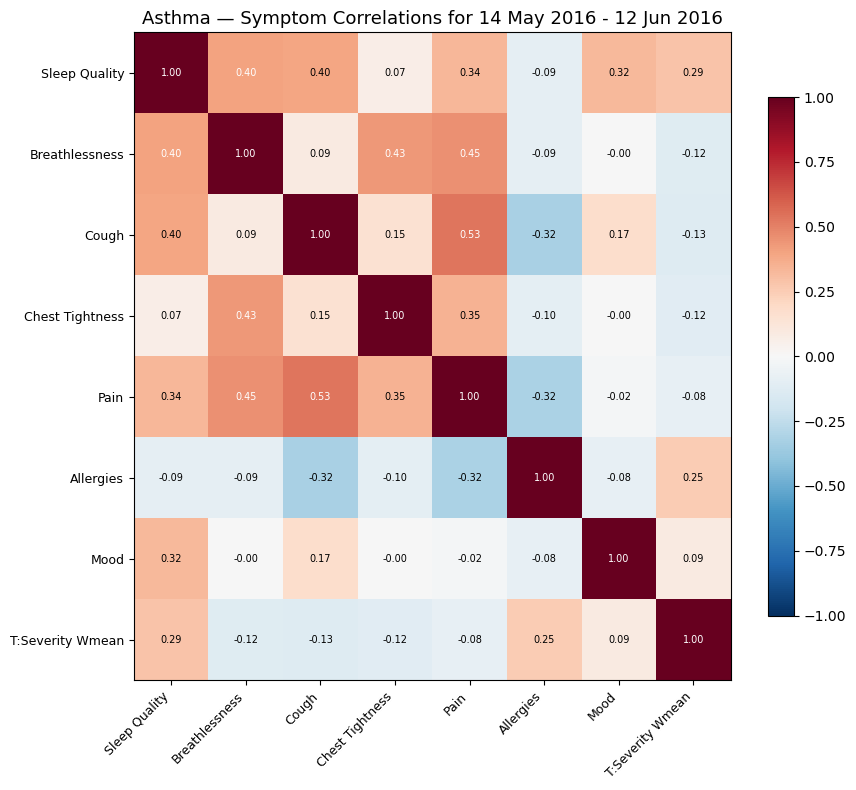


  STRONGEST SYMPTOM CORRELATIONS THIS PERIOD:
    Cough                ↔ Pain                  ρ=+0.532  (strongly move together)
    Breathlessness       ↔ Pain                  ρ=+0.454  (moderately move together)
    Breathlessness       ↔ Chest Tightness       ρ=+0.432  (moderately move together)
    Sleep Quality        ↔ Breathlessness        ρ=+0.403  (moderately move together)
    Sleep Quality        ↔ Cough                 ρ=+0.396  (moderately move together)

  NOTABLE CHANGES FROM OVERALL PATTERN:
    Cough                ↔ Pain                  this period=+0.532  overall=+0.082  (stronger this period)
    Sleep Quality        ↔ Breathlessness        this period=+0.403  overall=+0.067  (stronger this period)
    Sleep Quality        ↔ Cough                 this period=+0.396  overall=+0.132  (stronger this period)
    Pain                 ↔ Allergies             this period=-0.317  overall=+0.056  (stronger this period)
    Allergies            ↔ T:Severity Wmean      thi

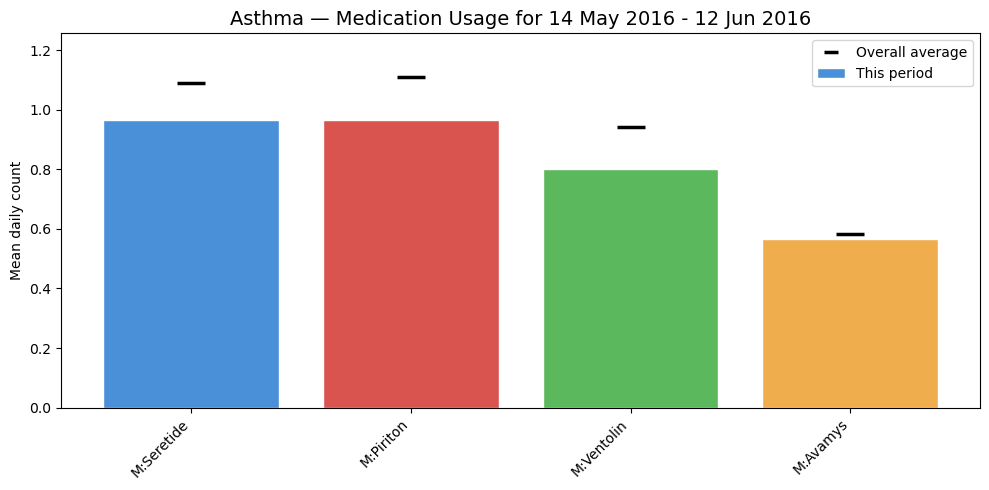


  WHAT YOU TRIED AND WHETHER IT HELPED:
  ──────────────────────────────────────────────────

    M:Ventolin (used on 19 of 30 days):
      Next-day Cough              was still elevated after use (4.6 vs 3.7)

    M:Seretide (used on 23 of 30 days):
      Allergies              was higher on days you used it (6.8 vs 5.2) — but this likely means you reached for it on worse days, not that it made things worse.

    M:Piriton (used on 23 of 30 days):
      Allergies              was higher on days you used it (6.8 vs 5.2) — but this likely means you reached for it on worse days, not that it made things worse.

    M:Avamys (used on 17 of 30 days):
      Sleep Quality          was higher on days you used it (3.4 vs 2.2) — but this likely means you reached for it on worse days, not that it made things worse.
      Allergies              was higher on days you used it (7.1 vs 5.5) — but this likely means you reached for it on worse days, not that it made things worse.
      Mood           

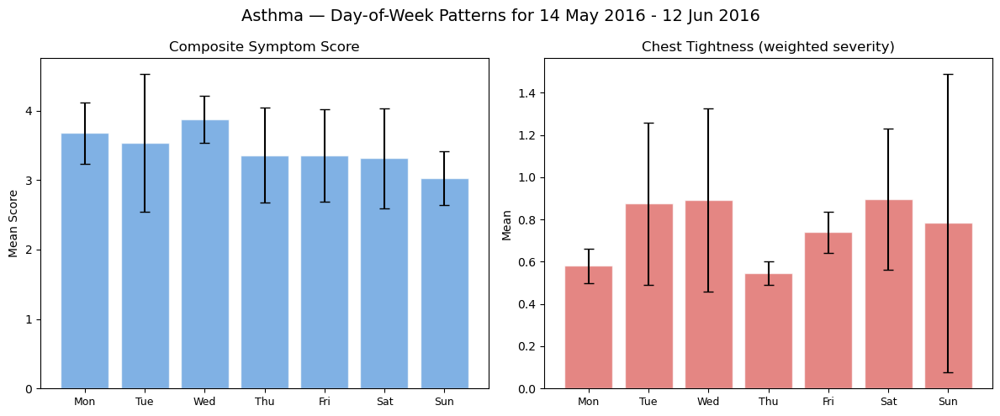

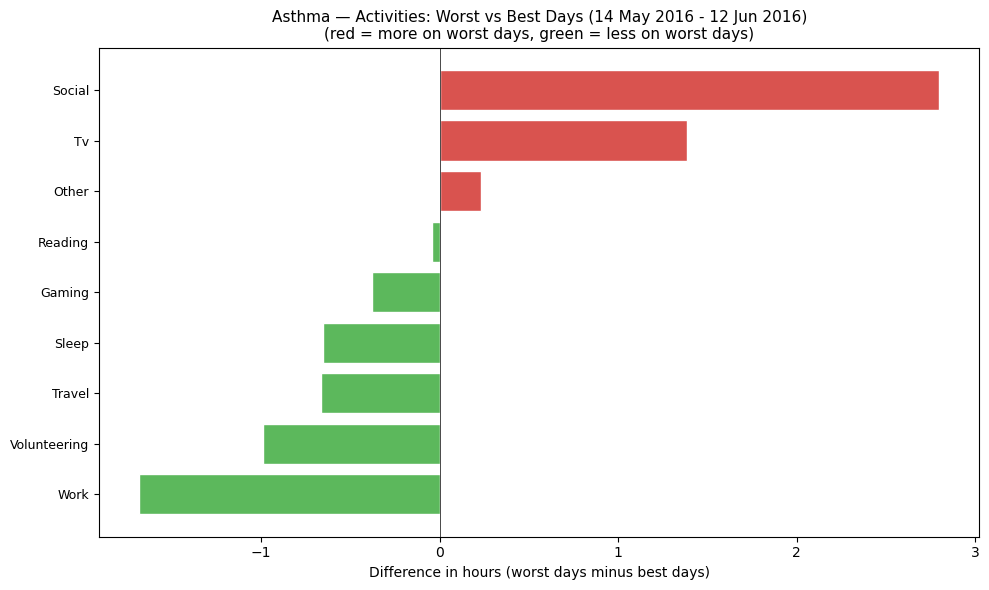


  ACTIVITIES ON WORST vs BEST DAYS:
  Activities associated with HIGHEST symptom scores:
    Social                +2.8h on worst days  p=0.525
    Tv                    +1.4h on worst days  p=0.538
    Other                 +0.2h on worst days  p=1.000
  Activities associated with LOWEST symptom scores:
    Work                  -1.7h on worst days  p=0.285
    Volunteering          -1.0h on worst days  p=0.356
    Travel                -0.7h on worst days  p=0.371
    Sleep                 -0.7h on worst days  p=0.390
    Gaming                -0.4h on worst days  p=0.600


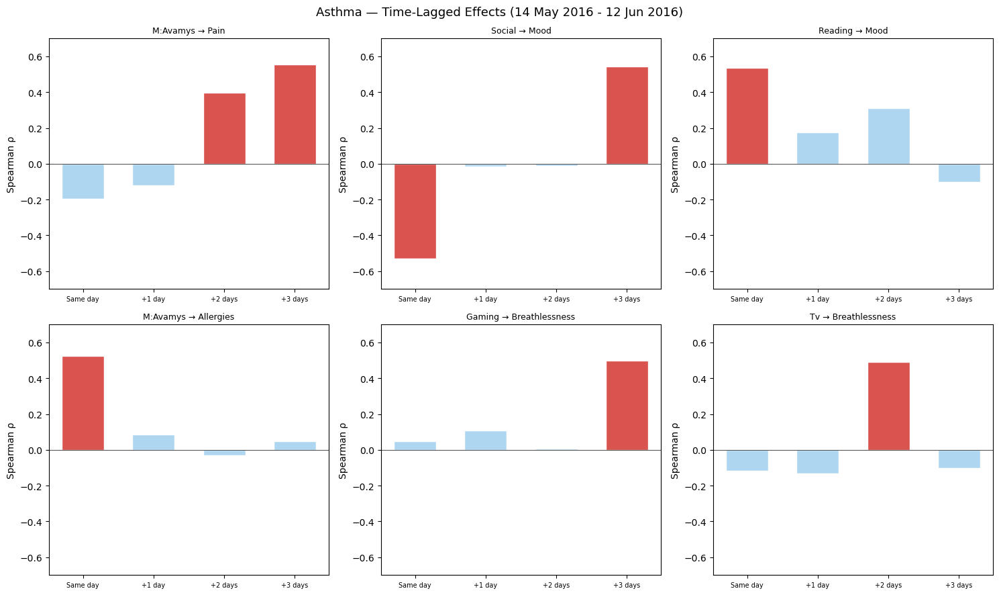


  TIME-LAGGED EFFECTS (strongest associations, p<0.1):
    M:Avamys             → Pain                  ρ=+0.554  after 3 day(s)  (worse) *
    Social               → Mood                  ρ=+0.543  after 3 day(s)  (worse) *
    Reading              → Mood                  ρ=+0.537  same-day  (worse) *
    M:Avamys             → Allergies             ρ=+0.524  same-day  (worse) *
    Gaming               → Breathlessness        ρ=+0.497  after 3 day(s)  (worse) *
    Tv                   → Breathlessness        ρ=+0.489  after 2 day(s)  (worse) *
    M:Piriton            → Mood                  ρ=+0.434  same-day  (worse) *
    M:Seretide           → Mood                  ρ=+0.434  same-day  (worse) *
    Gaming               → Pain                  ρ=+0.426  after 2 day(s)  (worse) *
    Reading              → Sleep Quality         ρ=+0.425  after 2 day(s)  (worse) *
    Social               → Sleep Quality         ρ=-0.412  after 2 day(s)  (better) *
    Tv                   → Mood 

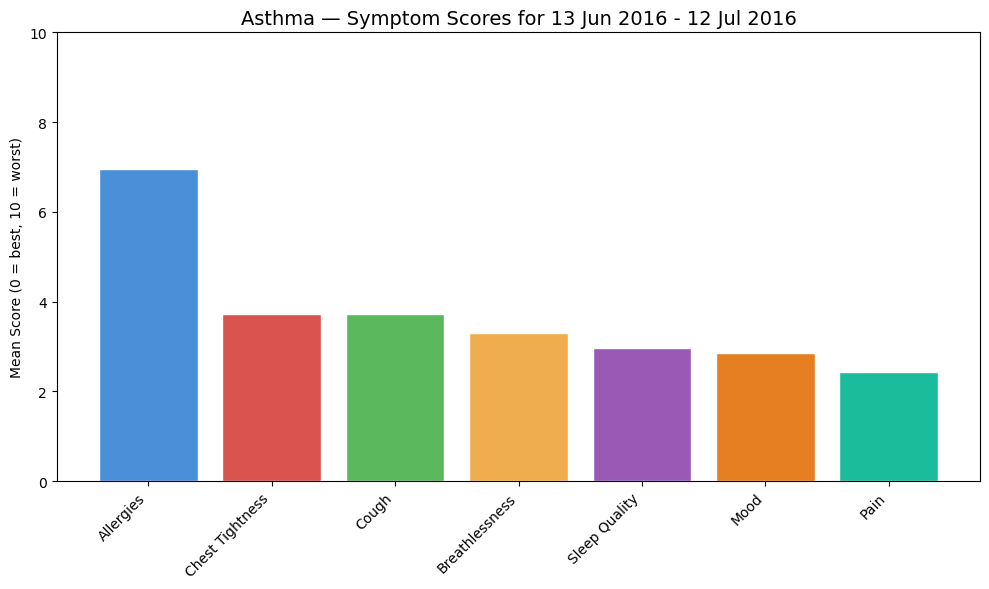

Symptoms with the highest scores in this period were Allergies (7.0), Chest Tightness (3.7), and Cough (3.7).


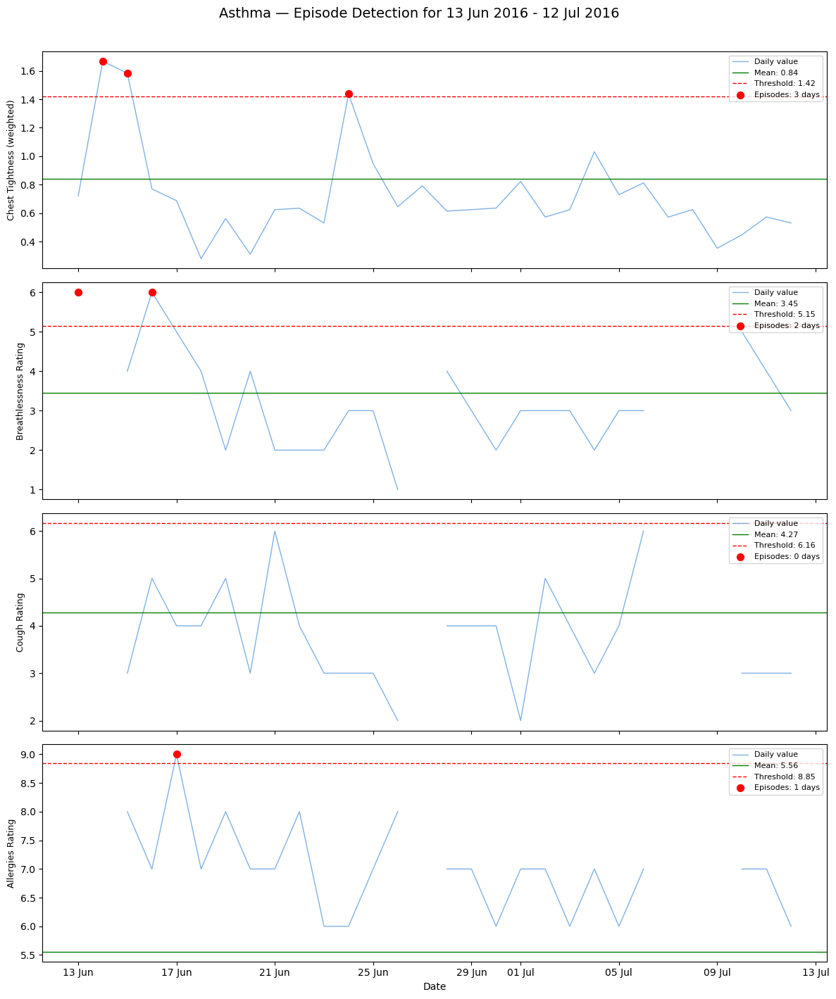

  Total episode days this month: 6

  FLARES OCCURRED ON: 13 Jun (Monday), 14 Jun (Tuesday), 15 Jun (Wednesday), 16 Jun (Thursday), 17 Jun (Friday), 24 Jun (Friday)
Worst day in this period: 10 Jul (composite 6.0/10)
Best day in this period:  23 Jun (composite 2.7/10)


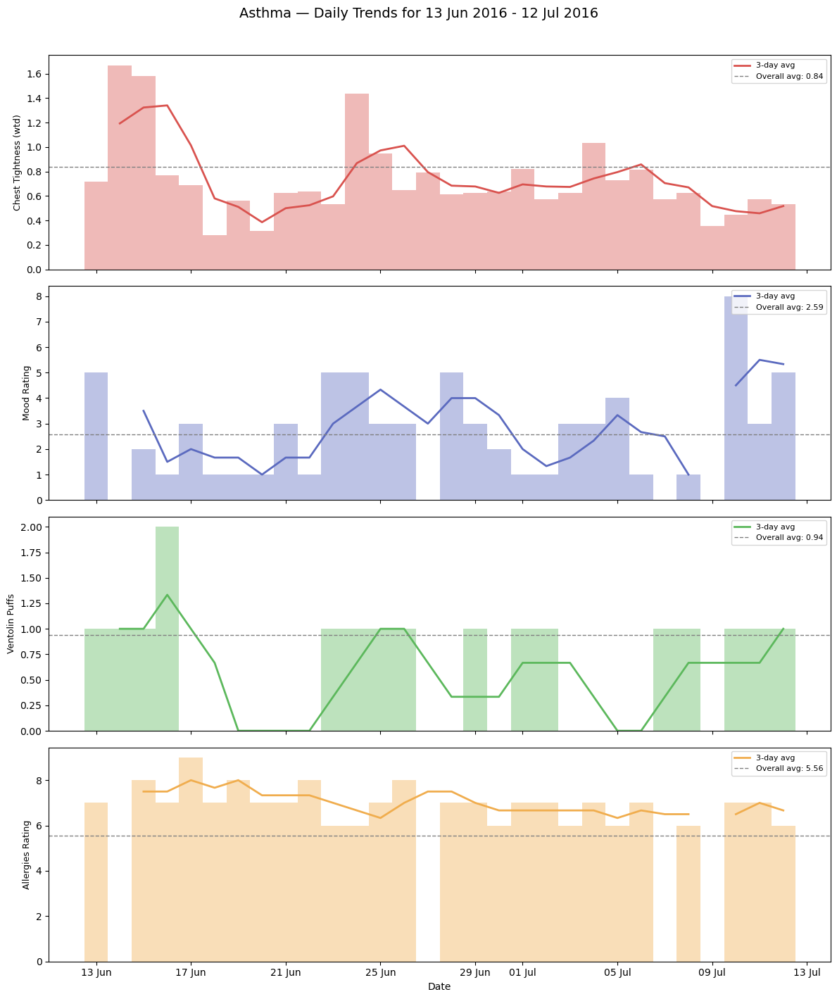

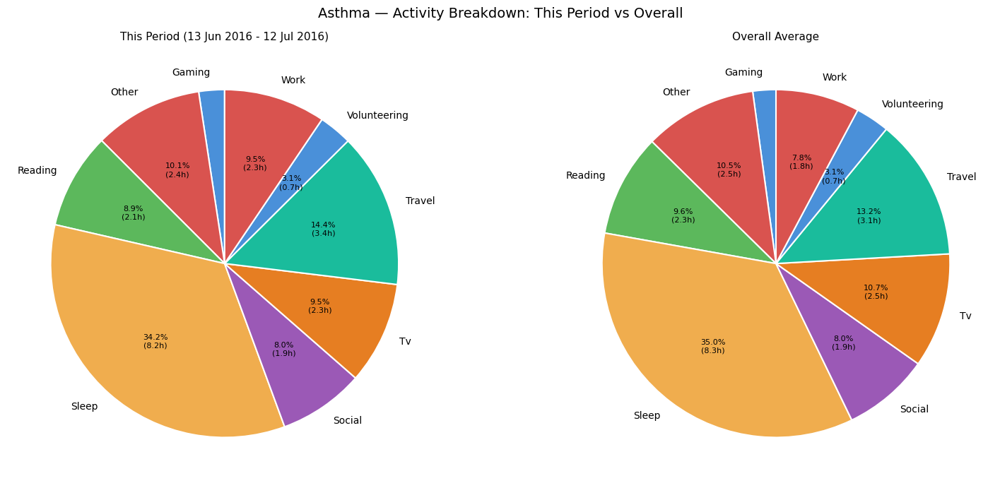

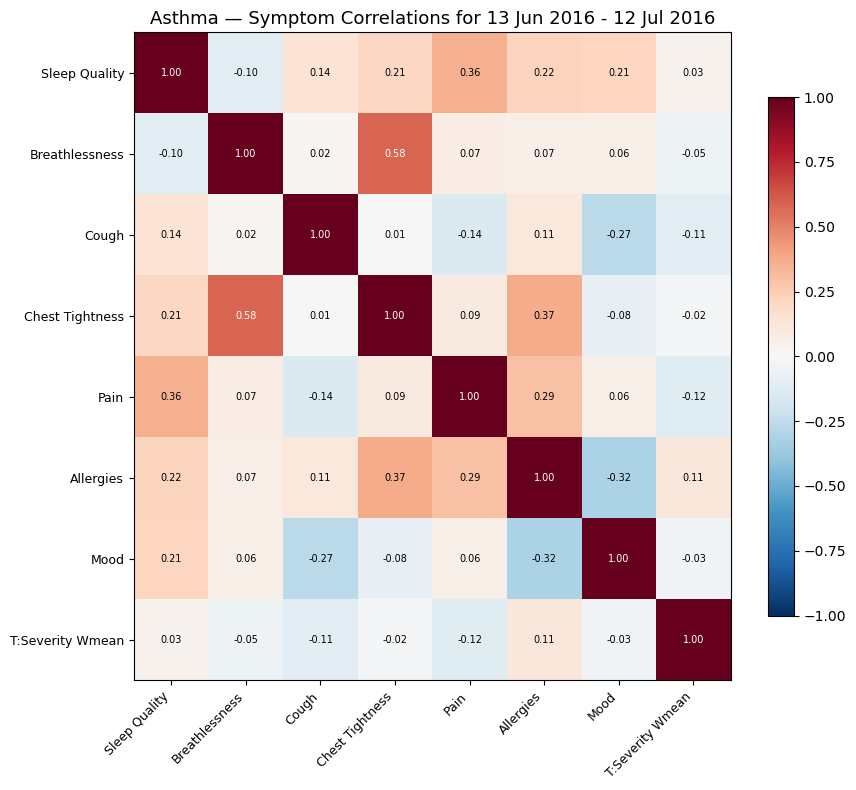


  STRONGEST SYMPTOM CORRELATIONS THIS PERIOD:
    Breathlessness       ↔ Chest Tightness       ρ=+0.582  (strongly move together)
    Chest Tightness      ↔ Allergies             ρ=+0.372  (moderately move together)
    Sleep Quality        ↔ Pain                  ρ=+0.358  (moderately move together)
    Allergies            ↔ Mood                  ρ=-0.319  (moderately move inversely)
    Pain                 ↔ Allergies             ρ=+0.290  (moderately move together)

  NOTABLE CHANGES FROM OVERALL PATTERN:
    Chest Tightness      ↔ Allergies             this period=+0.372  overall=-0.071  (stronger this period)
    Allergies            ↔ Mood                  this period=-0.319  overall=+0.131  (stronger this period)
    Sleep Quality        ↔ Allergies             this period=+0.222  overall=-0.037  (stronger this period)
    Cough                ↔ Allergies             this period=+0.109  overall=-0.283  (weaker this period)
    Breathlessness       ↔ T:Severity Wmean      this

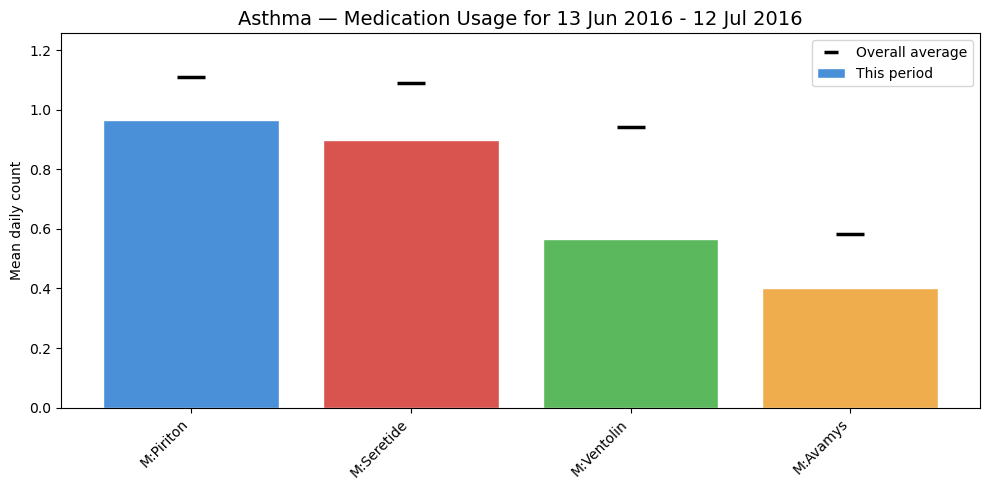


  WHAT YOU TRIED AND WHETHER IT HELPED:
  ──────────────────────────────────────────────────

    M:Ventolin (used on 16 of 30 days):
      Cough                  was lower on days you used it (3.3 vs 4.2, p=0.014) — this suggests it may have helped.

    M:Seretide (used on 23 of 30 days):

    M:Piriton (used on 24 of 30 days):

    M:Avamys (used on 12 of 30 days):
      Cough                  was lower on days you used it (3.4 vs 4.0, p=0.061) — this suggests it may have helped.


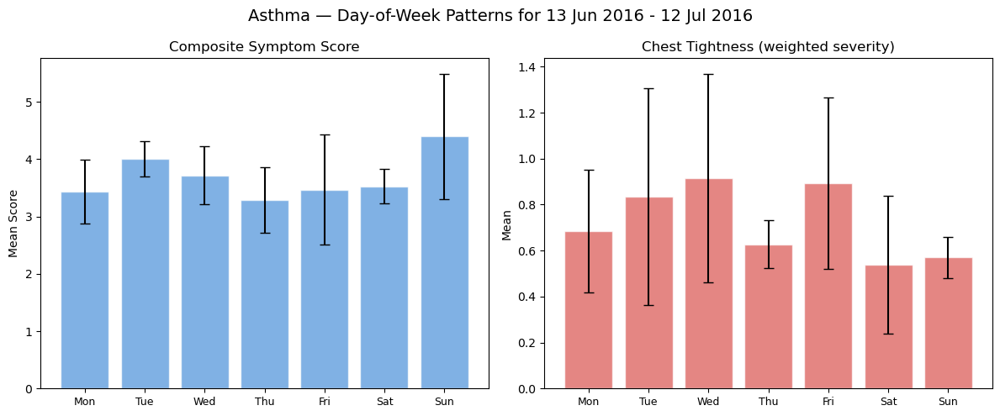

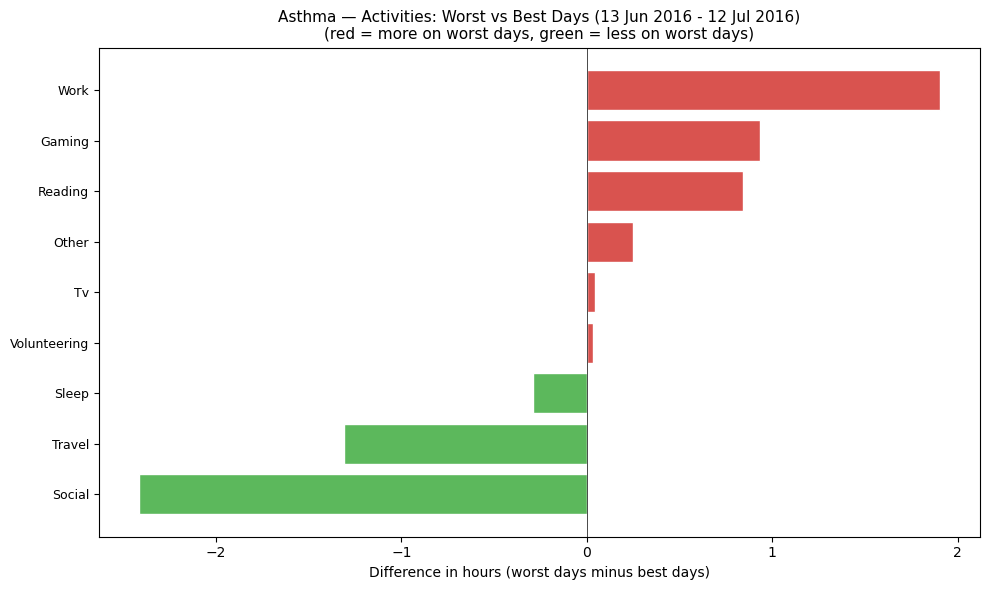


  ACTIVITIES ON WORST vs BEST DAYS:
  Activities associated with HIGHEST symptom scores:
    Work                  +1.9h on worst days  p=0.388
    Gaming                +0.9h on worst days  p=0.108
    Reading               +0.8h on worst days  p=0.273
    Other                 +0.3h on worst days  p=0.930
  Activities associated with LOWEST symptom scores:
    Social                -2.4h on worst days  p=0.158
    Travel                -1.3h on worst days  p=0.189
    Sleep                 -0.3h on worst days  p=0.662


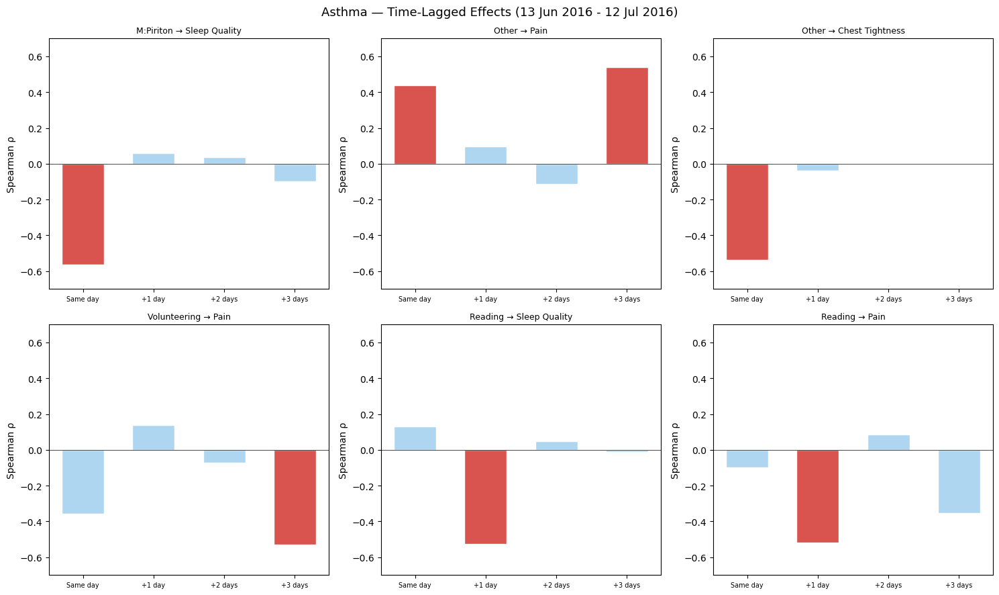


  TIME-LAGGED EFFECTS (strongest associations, p<0.1):
    M:Piriton            → Sleep Quality         ρ=-0.564  same-day  (better) *
    Other                → Pain                  ρ=+0.540  after 3 day(s)  (worse) *
    Other                → Chest Tightness       ρ=-0.536  same-day  (better) *
    Volunteering         → Pain                  ρ=-0.531  after 3 day(s)  (better) *
    Reading              → Sleep Quality         ρ=-0.527  after 1 day(s)  (better) *
    Reading              → Pain                  ρ=-0.520  after 1 day(s)  (better) *
    Sleep                → Mood                  ρ=-0.512  same-day  (better) *
    Gaming               → Pain                  ρ=-0.494  after 3 day(s)  (better) *
    M:Seretide           → Sleep Quality         ρ=-0.492  same-day  (better) *
    M:Ventolin           → Allergies             ρ=+0.488  after 3 day(s)  (worse) *
    Reading              → Mood                  ρ=-0.470  after 3 day(s)  (better) *
    Volunteering        

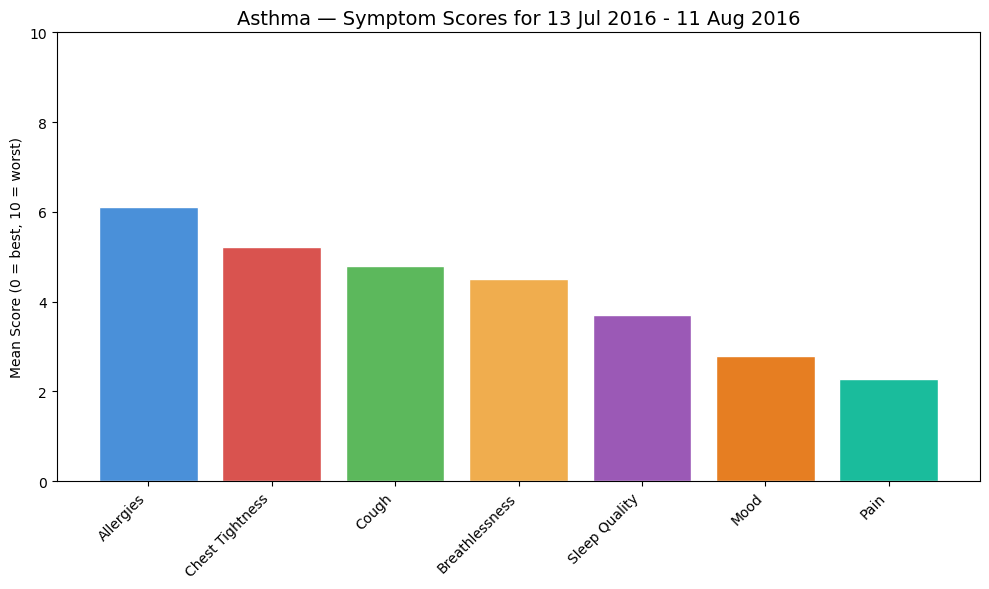

Symptoms with the highest scores in this period were Allergies (6.1), Chest Tightness (5.2), and Cough (4.8).

  Episode detection skipped — not enough data this period.


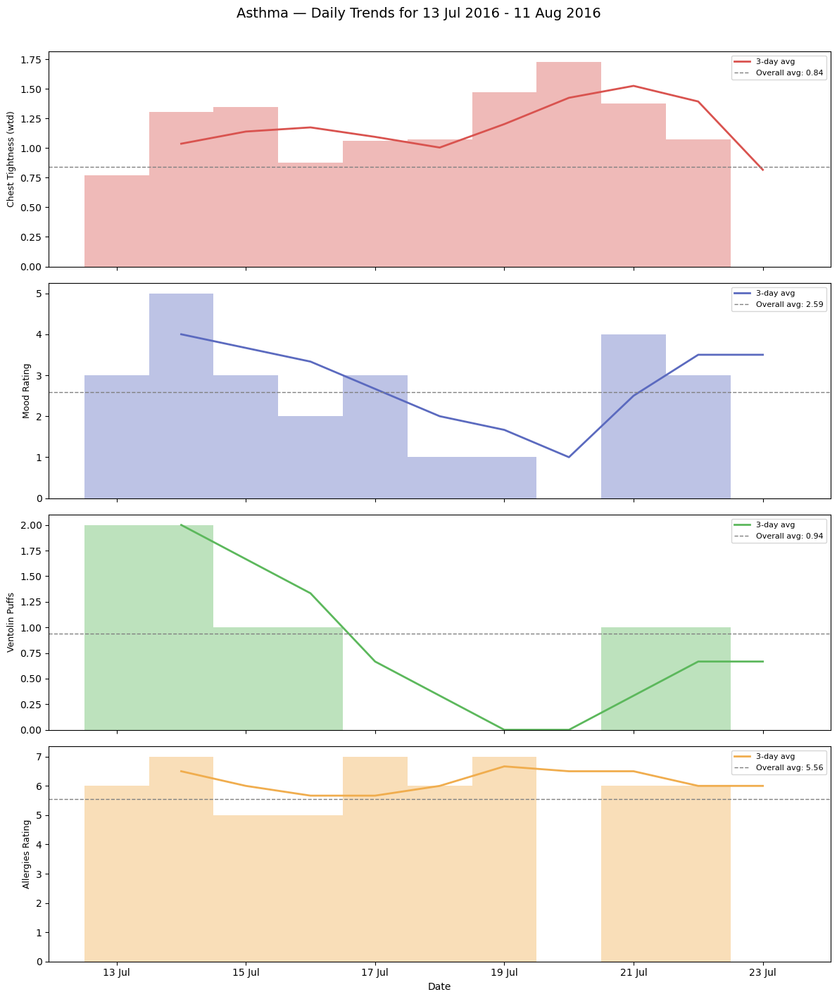

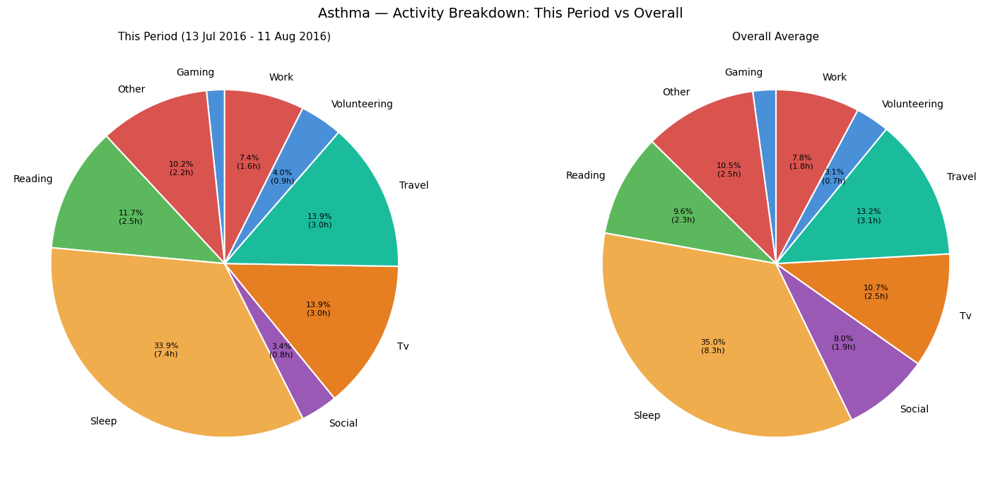

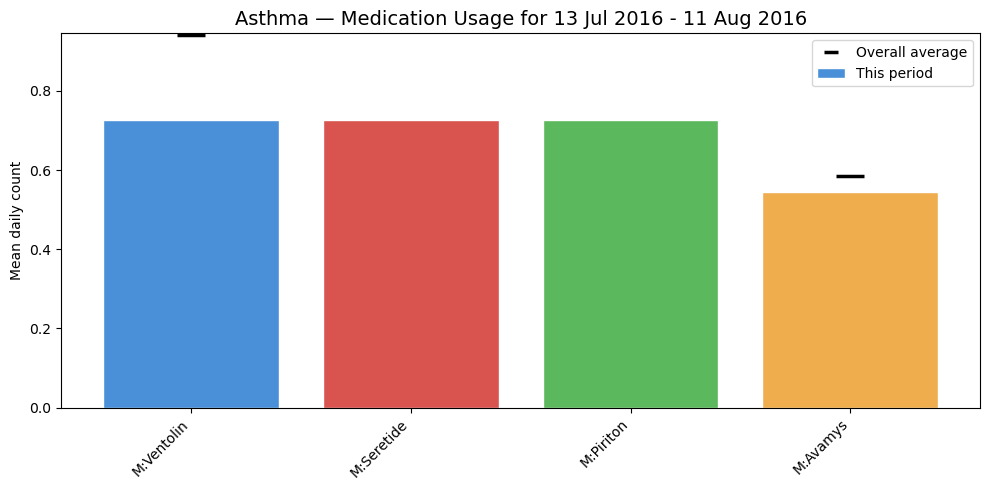


  WHAT YOU TRIED AND WHETHER IT HELPED:
  ──────────────────────────────────────────────────

    M:Ventolin (used on 6 of 11 days):

    M:Seretide (used on 6 of 11 days):

    M:Piriton (used on 6 of 11 days):

    M:Avamys (used on 6 of 11 days):


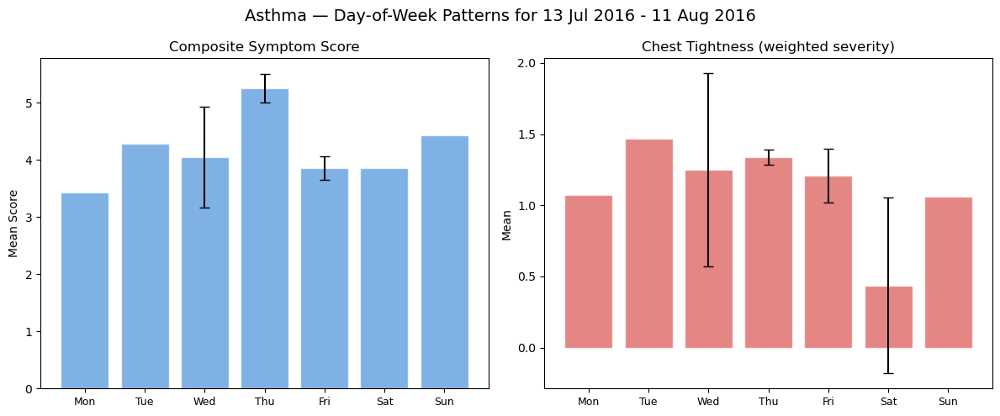


  Insufficient worst/best days for activity comparison (worst=4, best=1)

  Insufficient data for lag analysis in this period

  TRIGGERS OF CHEST TIGHTNESS (WEIGHTED SEVERITY):
    No significant triggers identified in this period

  RELIEVERS:
    No significant relievers identified in this period

  APPEARED TO HAVE NO SIGNIFICANT EFFECT ON SYMPTOMS:
    Gaming, Other, Sleep, Travel, Volunteering, M:Ventolin, M:Seretide, M:Piriton, M:Avamys
    (all p>0.3)

  WITH REGARD TO CHEST TIGHTNESS (WEIGHTED SEVERITY):
    Work appeared to have most effect in exacerbation (ρ=+0.540, p=0.0866)
    Social appeared to have most effect in relief (ρ=-0.476, p=0.1391)

  COMPARED TO PREVIOUS 30-DAY WINDOW (13 Jun – 12 Jul):
    Sleep Quality              prev=2.96  now=3.70  (+0.74, worse)
    Breathlessness             prev=3.31  now=4.50  (+1.19, worse)
    Cough                      prev=3.73  now=4.80  (+1.07, worse)
    Chest Tightness            prev=3.73  now=5.22  (+1.49, worse)
    Pain 

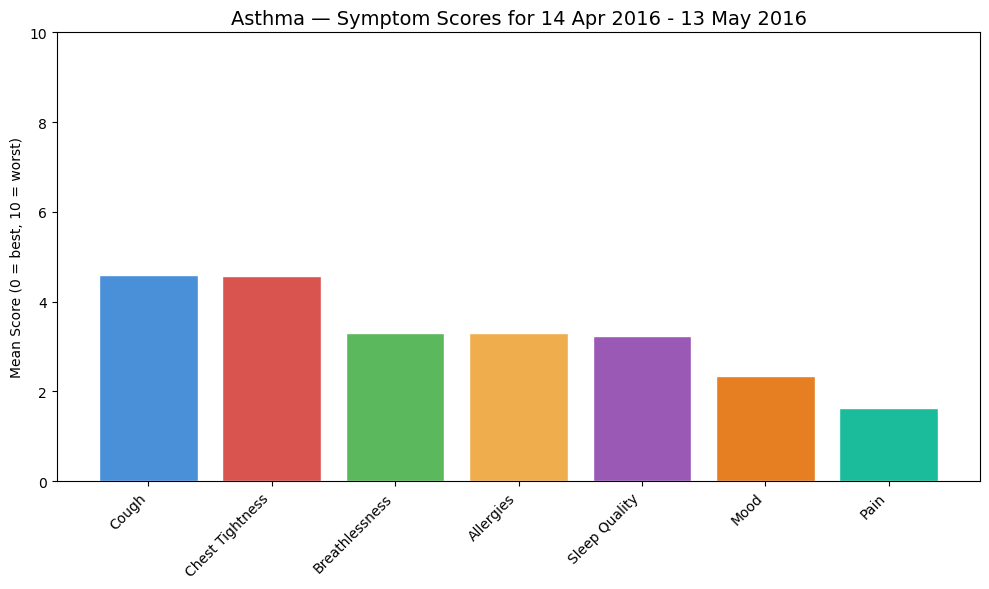

Symptoms with the highest scores in this period were Cough (4.6), Chest Tightness (4.6), and Breathlessness (3.3).


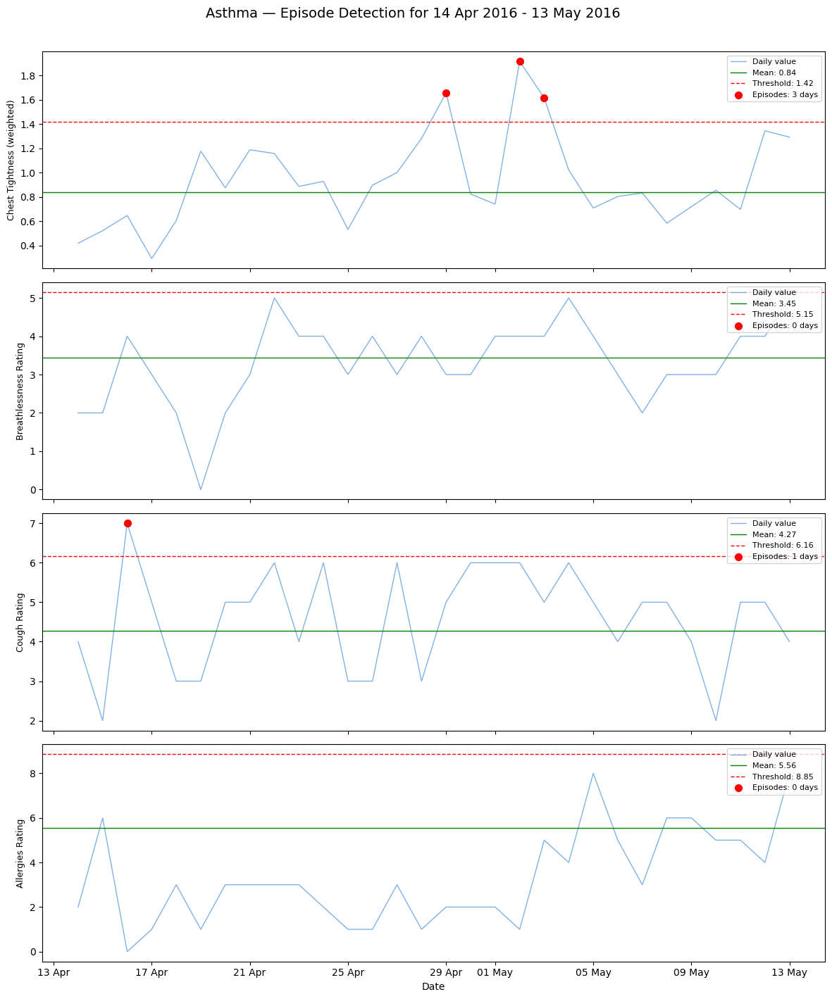

  Total episode days this month: 4

  FLARES OCCURRED ON: 16 Apr (Saturday), 29 Apr (Friday), 02 May (Monday), 03 May (Tuesday)
Worst day in this period: 05 May (composite 5.0/10)
Best day in this period:  19 Apr (composite 1.7/10)


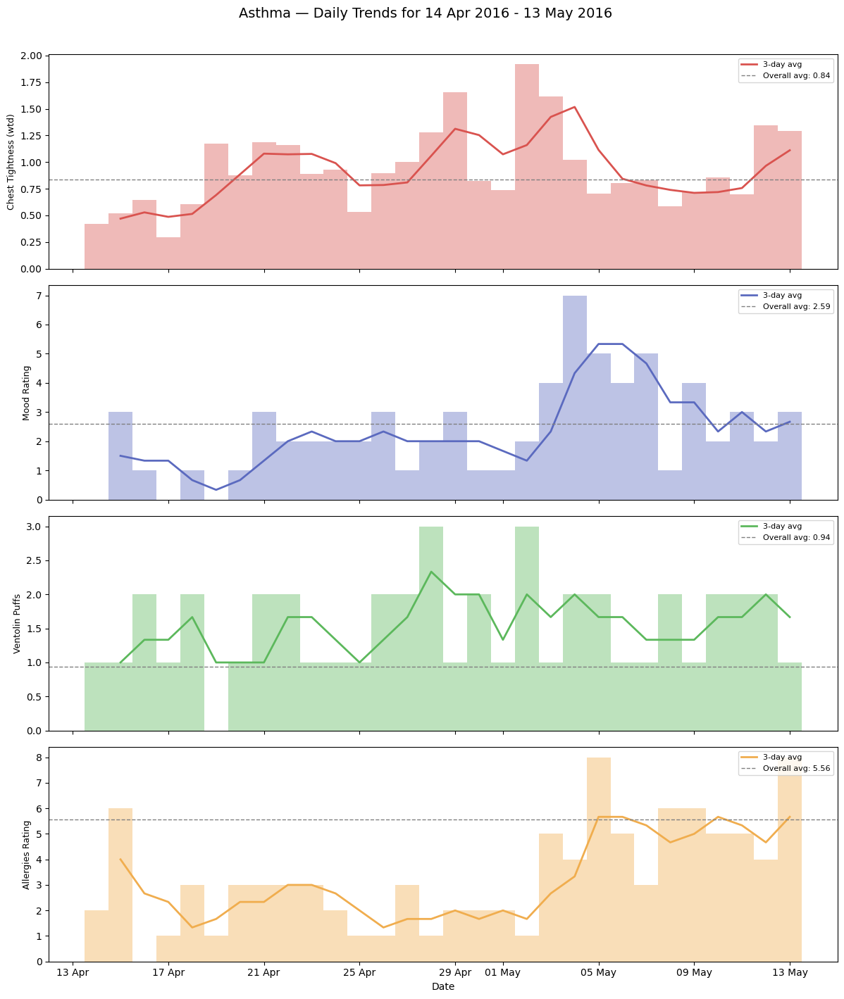

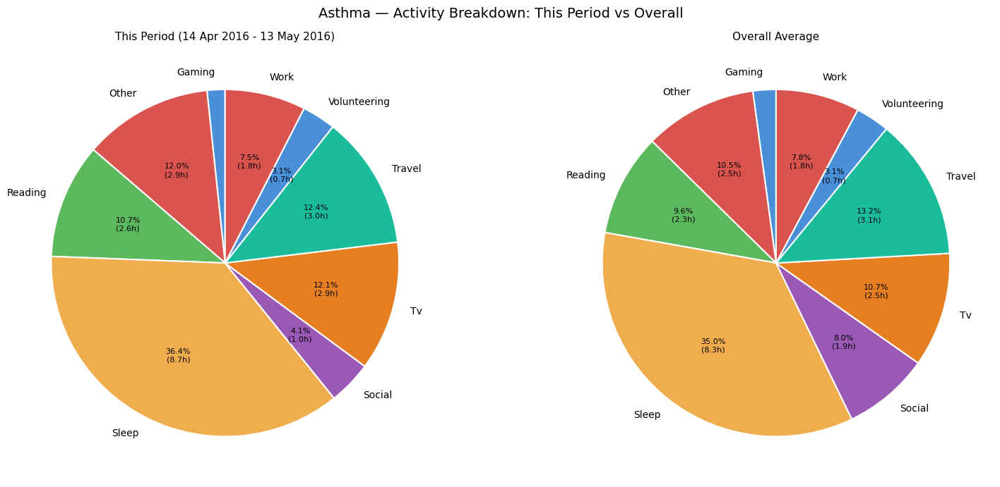

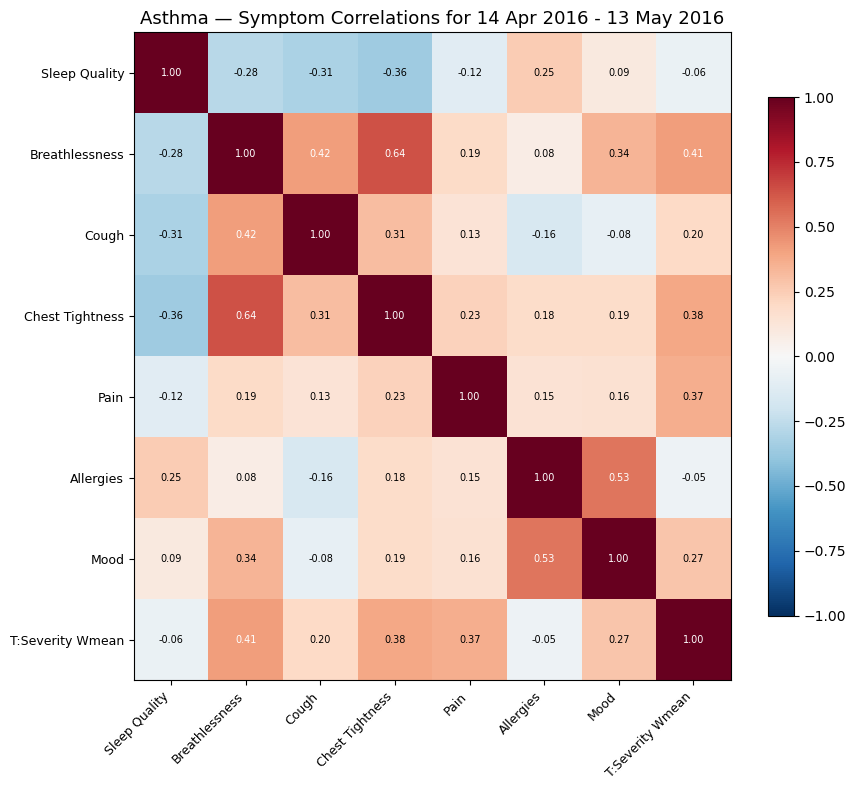


  STRONGEST SYMPTOM CORRELATIONS THIS PERIOD:
    Breathlessness       ↔ Chest Tightness       ρ=+0.638  (strongly move together)
    Allergies            ↔ Mood                  ρ=+0.533  (strongly move together)
    Breathlessness       ↔ Cough                 ρ=+0.416  (moderately move together)
    Breathlessness       ↔ T:Severity Wmean      ρ=+0.414  (moderately move together)
    Chest Tightness      ↔ T:Severity Wmean      ρ=+0.384  (moderately move together)

  NOTABLE CHANGES FROM OVERALL PATTERN:
    Allergies            ↔ Mood                  this period=+0.533  overall=+0.131  (stronger this period)
    Sleep Quality        ↔ Chest Tightness       this period=-0.358  overall=+0.066  (stronger this period)
    Sleep Quality        ↔ Cough                 this period=-0.313  overall=+0.132  (stronger this period)
    Sleep Quality        ↔ Breathlessness        this period=-0.279  overall=+0.067  (stronger this period)
    Sleep Quality        ↔ Allergies             this 

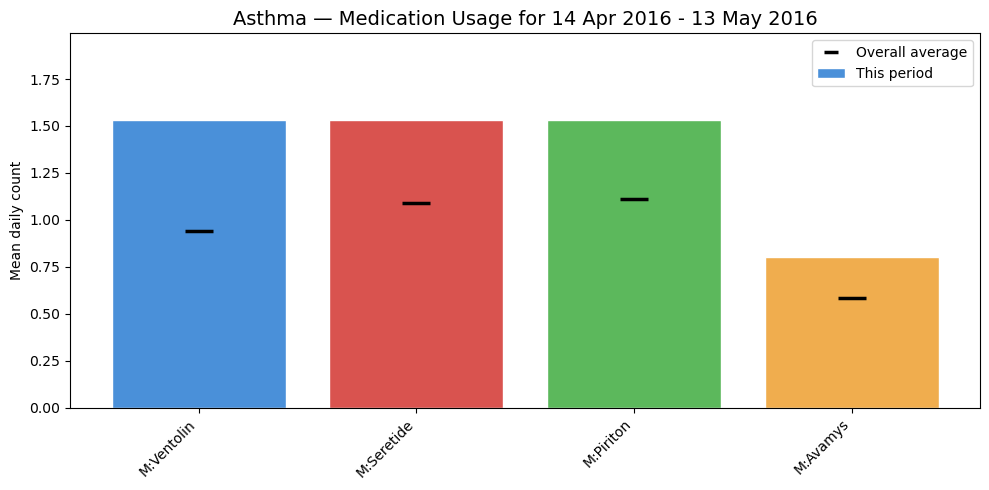


  WHAT YOU TRIED AND WHETHER IT HELPED:
  ──────────────────────────────────────────────────

    M:Ventolin: used on 29 of 30 days — taken too consistently to compare with/without. This is typical for routine preventers and means the medication's effect can't be isolated from daily data alone.

    M:Seretide: used on 29 of 30 days — taken too consistently to compare with/without. This is typical for routine preventers and means the medication's effect can't be isolated from daily data alone.

    M:Piriton: used on 28 of 30 days — taken too consistently to compare with/without. This is typical for routine preventers and means the medication's effect can't be isolated from daily data alone.

    M:Avamys (used on 24 of 30 days):
      Breathlessness         was higher on days you used it (3.5 vs 2.5) — but this likely means you reached for it on worse days, not that it made things worse.
      Chest Tightness        was higher on days you used it (4.9 vs 3.2) — but this likely means 

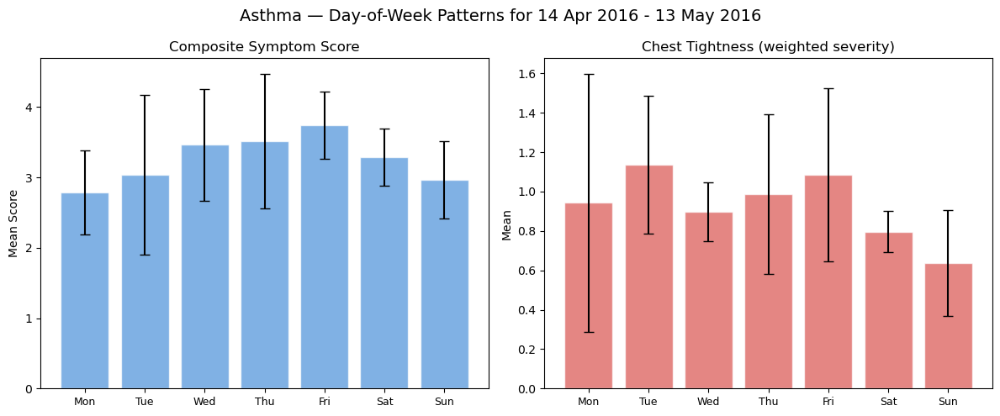

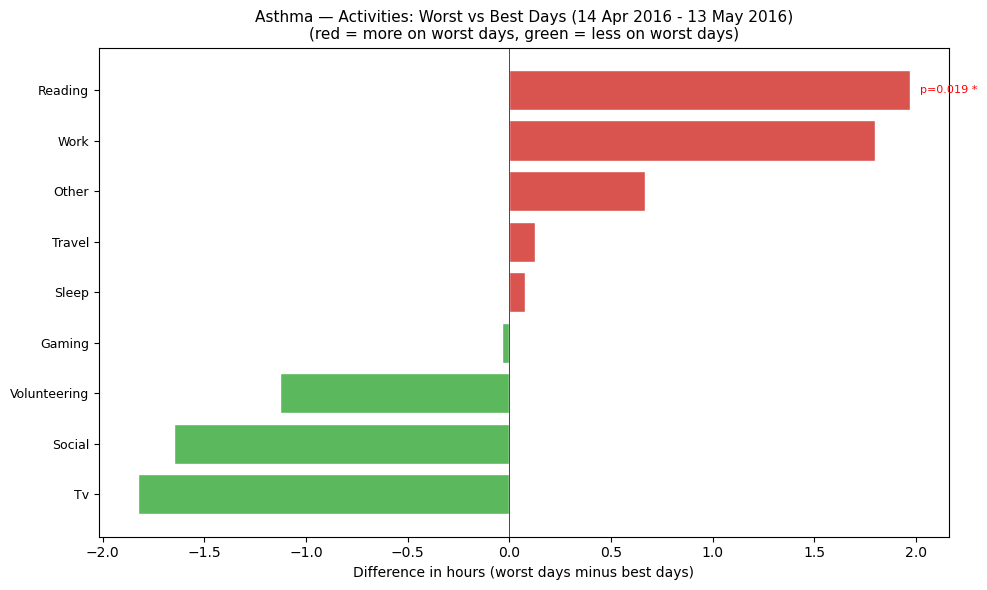


  ACTIVITIES ON WORST vs BEST DAYS:
  Activities associated with HIGHEST symptom scores:
    Reading               +2.0h on worst days  p=0.019 *
    Work                  +1.8h on worst days  p=0.321
    Other                 +0.7h on worst days  p=1.000
    Travel                +0.1h on worst days  p=0.569
  Activities associated with LOWEST symptom scores:
    Tv                    -1.8h on worst days  p=0.286
    Social                -1.6h on worst days  p=0.117
    Volunteering          -1.1h on worst days  p=0.508


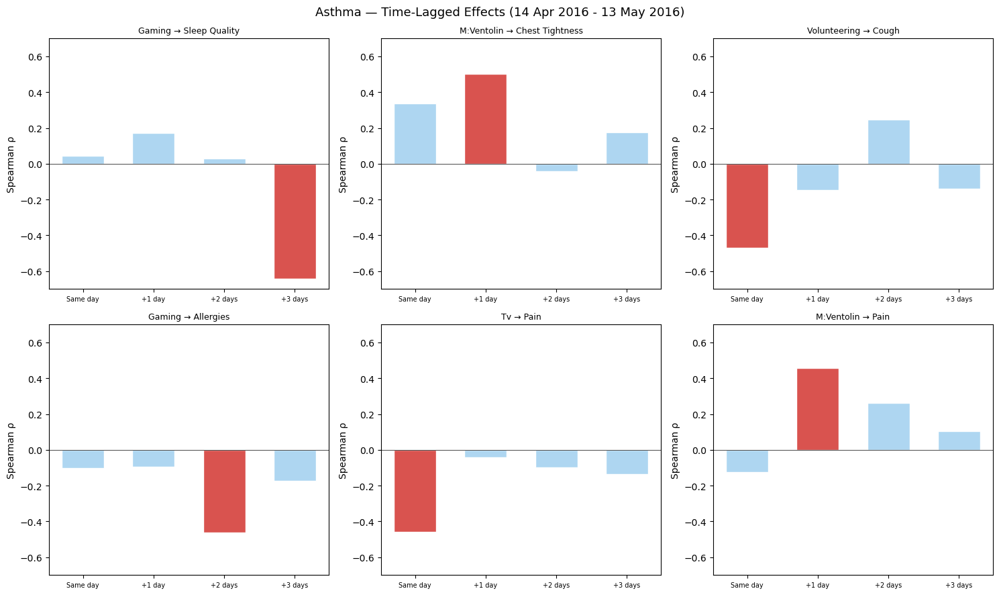


  TIME-LAGGED EFFECTS (strongest associations, p<0.1):
    Gaming               → Sleep Quality         ρ=-0.642  after 3 day(s)  (better) *
    M:Ventolin           → Chest Tightness       ρ=+0.501  after 1 day(s)  (worse) *
    Volunteering         → Cough                 ρ=-0.469  same-day  (better) *
    Gaming               → Allergies             ρ=-0.463  after 2 day(s)  (better) *
    Tv                   → Pain                  ρ=-0.459  same-day  (better) *
    M:Ventolin           → Pain                  ρ=+0.459  after 1 day(s)  (worse) *
    M:Avamys             → Chest Tightness       ρ=+0.446  same-day  (worse) *
    Tv                   → Allergies             ρ=-0.446  after 3 day(s)  (better) *
    Volunteering         → Mood                  ρ=-0.427  after 2 day(s)  (better) *
    Volunteering         → Pain                  ρ=-0.413  after 2 day(s)  (better) *
    Social               → Chest Tightness       ρ=+0.412  after 3 day(s)  (worse) *
    Tv              

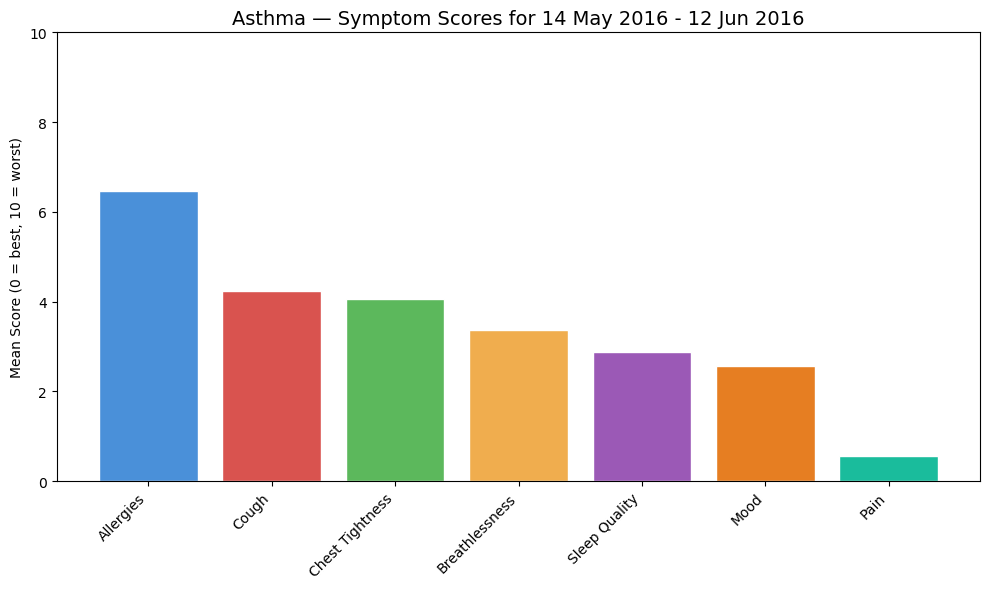

Symptoms with the highest scores in this period were Allergies (6.5), Cough (4.2), and Chest Tightness (4.1).


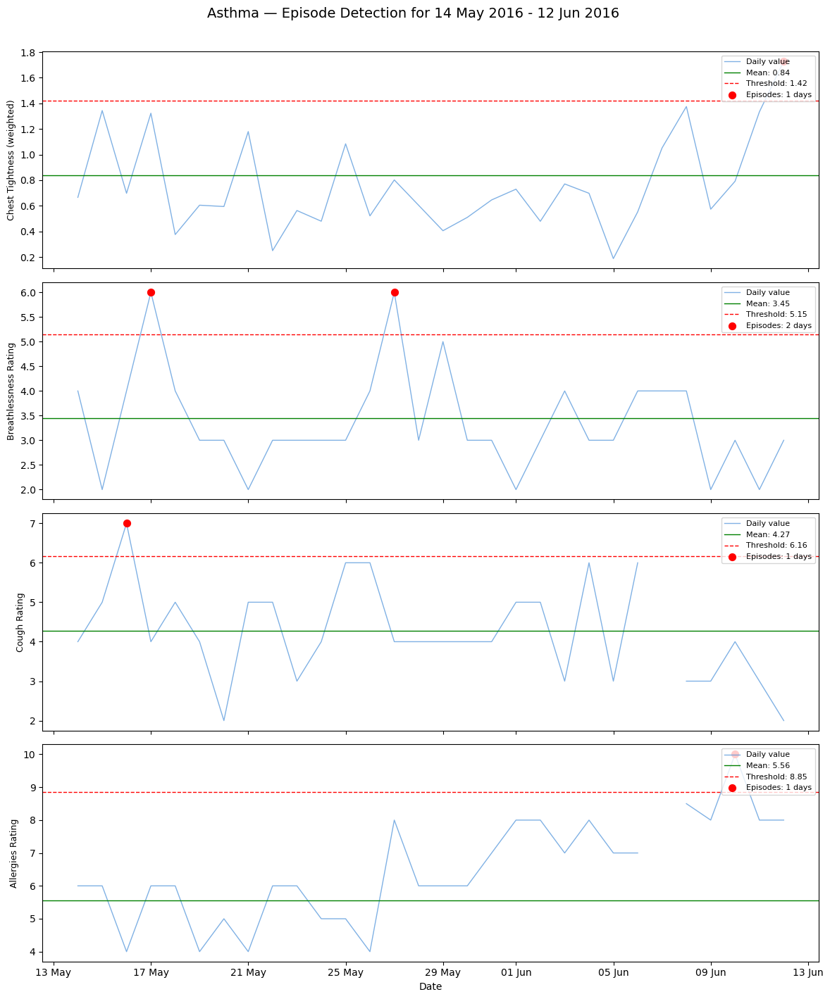

  Total episode days this month: 5

  FLARES OCCURRED ON: 16 May (Monday), 17 May (Tuesday), 27 May (Friday), 10 Jun (Friday), 12 Jun (Sunday)
Worst day in this period: 17 May (composite 5.0/10)
Best day in this period:  11 Jun (composite 2.3/10)


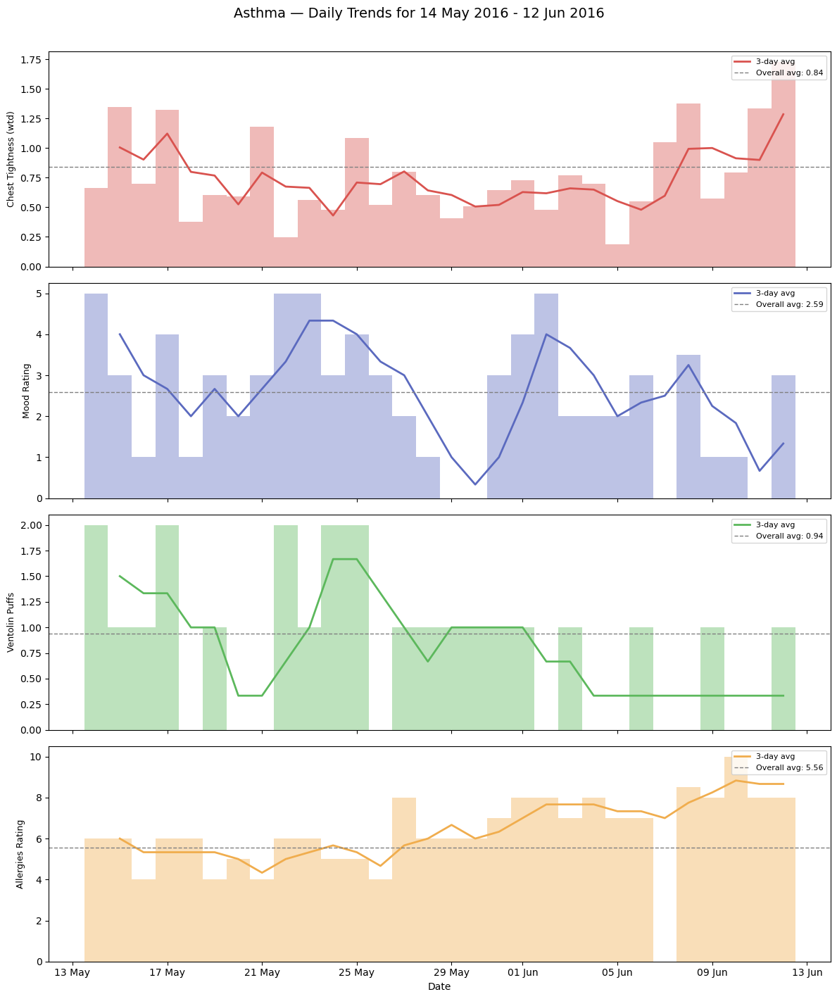

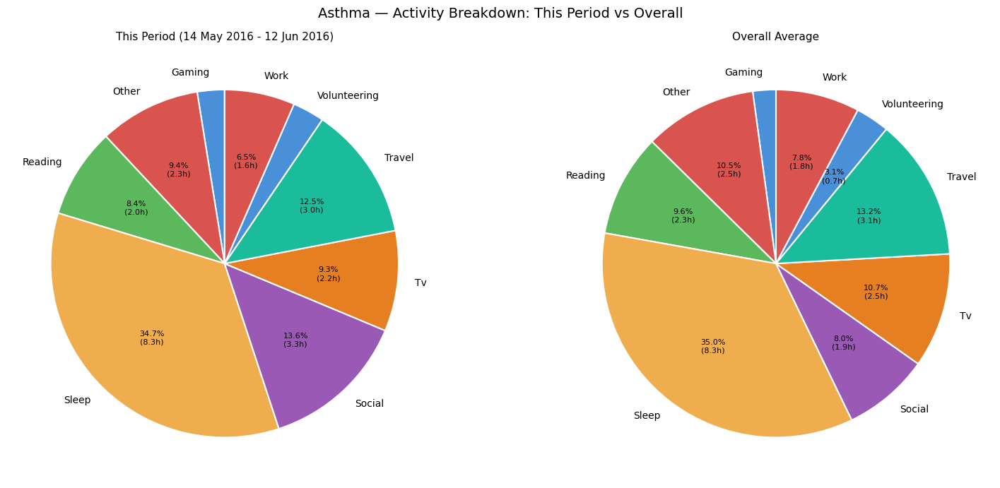

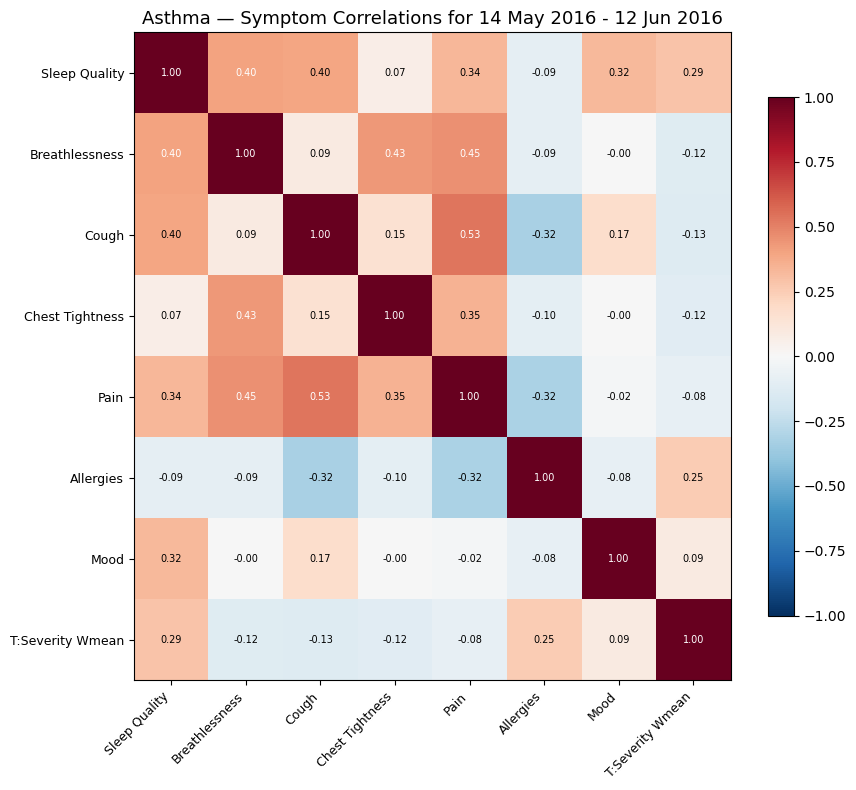


  STRONGEST SYMPTOM CORRELATIONS THIS PERIOD:
    Cough                ↔ Pain                  ρ=+0.532  (strongly move together)
    Breathlessness       ↔ Pain                  ρ=+0.454  (moderately move together)
    Breathlessness       ↔ Chest Tightness       ρ=+0.432  (moderately move together)
    Sleep Quality        ↔ Breathlessness        ρ=+0.403  (moderately move together)
    Sleep Quality        ↔ Cough                 ρ=+0.396  (moderately move together)

  NOTABLE CHANGES FROM OVERALL PATTERN:
    Cough                ↔ Pain                  this period=+0.532  overall=+0.082  (stronger this period)
    Sleep Quality        ↔ Breathlessness        this period=+0.403  overall=+0.067  (stronger this period)
    Sleep Quality        ↔ Cough                 this period=+0.396  overall=+0.132  (stronger this period)
    Pain                 ↔ Allergies             this period=-0.317  overall=+0.056  (stronger this period)
    Allergies            ↔ T:Severity Wmean      thi

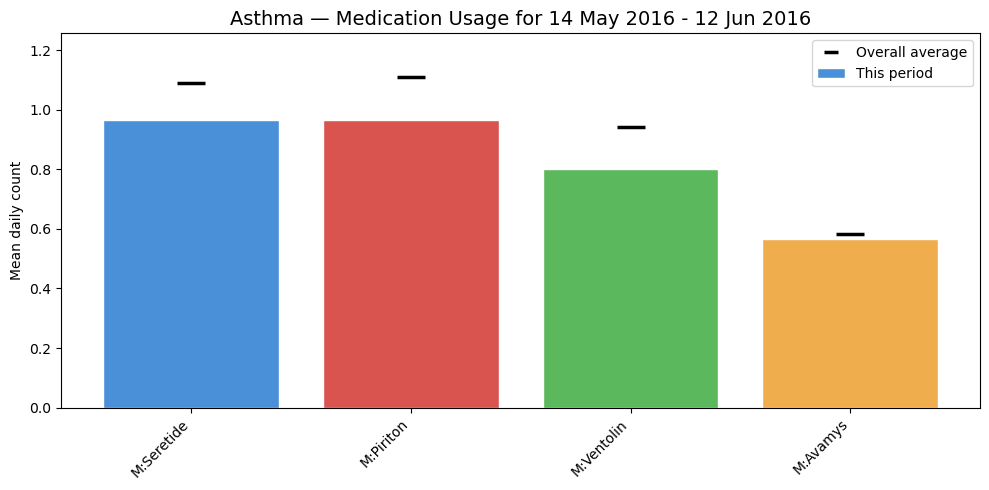


  WHAT YOU TRIED AND WHETHER IT HELPED:
  ──────────────────────────────────────────────────

    M:Ventolin (used on 19 of 30 days):
      Next-day Cough              was still elevated after use (4.6 vs 3.7)

    M:Seretide (used on 23 of 30 days):
      Allergies              was higher on days you used it (6.8 vs 5.2) — but this likely means you reached for it on worse days, not that it made things worse.

    M:Piriton (used on 23 of 30 days):
      Allergies              was higher on days you used it (6.8 vs 5.2) — but this likely means you reached for it on worse days, not that it made things worse.

    M:Avamys (used on 17 of 30 days):
      Sleep Quality          was higher on days you used it (3.4 vs 2.2) — but this likely means you reached for it on worse days, not that it made things worse.
      Allergies              was higher on days you used it (7.1 vs 5.5) — but this likely means you reached for it on worse days, not that it made things worse.
      Mood           

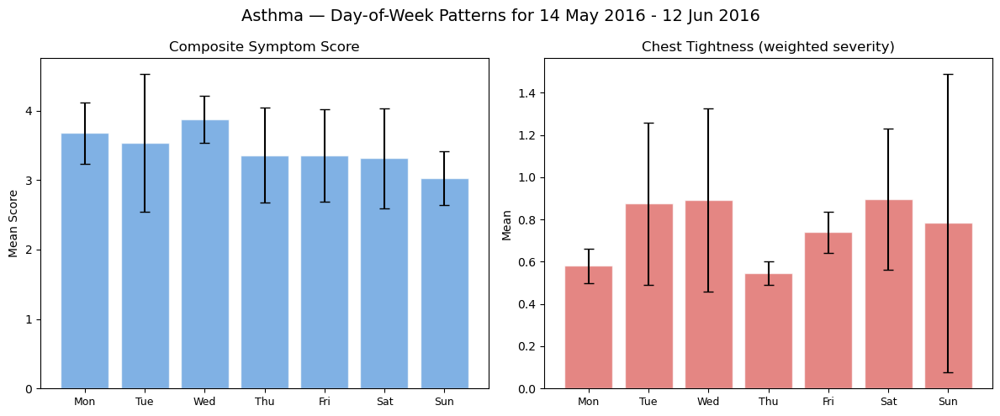

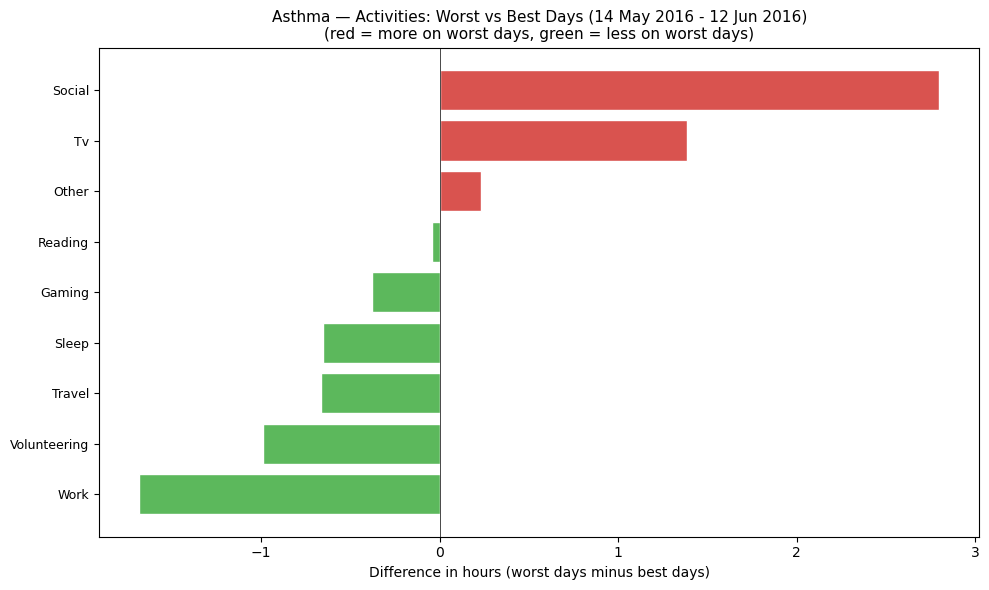


  ACTIVITIES ON WORST vs BEST DAYS:
  Activities associated with HIGHEST symptom scores:
    Social                +2.8h on worst days  p=0.525
    Tv                    +1.4h on worst days  p=0.538
    Other                 +0.2h on worst days  p=1.000
  Activities associated with LOWEST symptom scores:
    Work                  -1.7h on worst days  p=0.285
    Volunteering          -1.0h on worst days  p=0.356
    Travel                -0.7h on worst days  p=0.371
    Sleep                 -0.7h on worst days  p=0.390
    Gaming                -0.4h on worst days  p=0.600


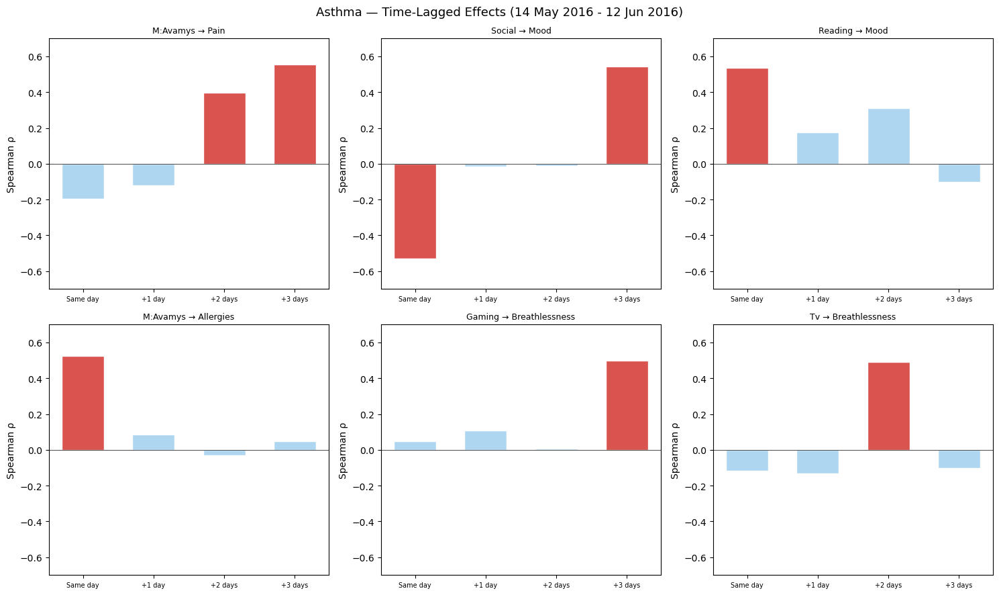


  TIME-LAGGED EFFECTS (strongest associations, p<0.1):
    M:Avamys             → Pain                  ρ=+0.554  after 3 day(s)  (worse) *
    Social               → Mood                  ρ=+0.543  after 3 day(s)  (worse) *
    Reading              → Mood                  ρ=+0.537  same-day  (worse) *
    M:Avamys             → Allergies             ρ=+0.524  same-day  (worse) *
    Gaming               → Breathlessness        ρ=+0.497  after 3 day(s)  (worse) *
    Tv                   → Breathlessness        ρ=+0.489  after 2 day(s)  (worse) *
    M:Piriton            → Mood                  ρ=+0.434  same-day  (worse) *
    M:Seretide           → Mood                  ρ=+0.434  same-day  (worse) *
    Gaming               → Pain                  ρ=+0.426  after 2 day(s)  (worse) *
    Reading              → Sleep Quality         ρ=+0.425  after 2 day(s)  (worse) *
    Social               → Sleep Quality         ρ=-0.412  after 2 day(s)  (better) *
    Tv                   → Mood 

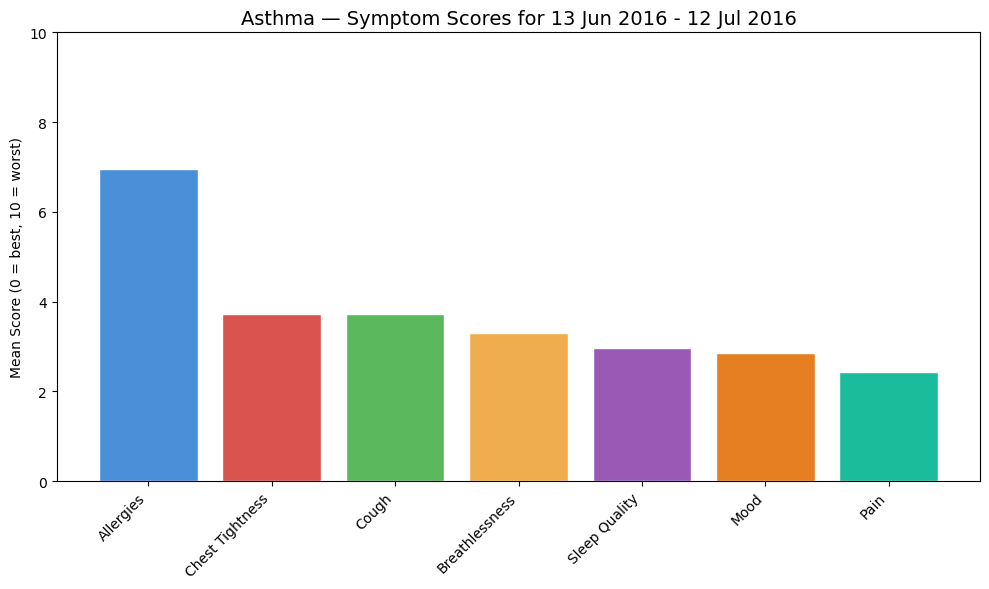

Symptoms with the highest scores in this period were Allergies (7.0), Chest Tightness (3.7), and Cough (3.7).


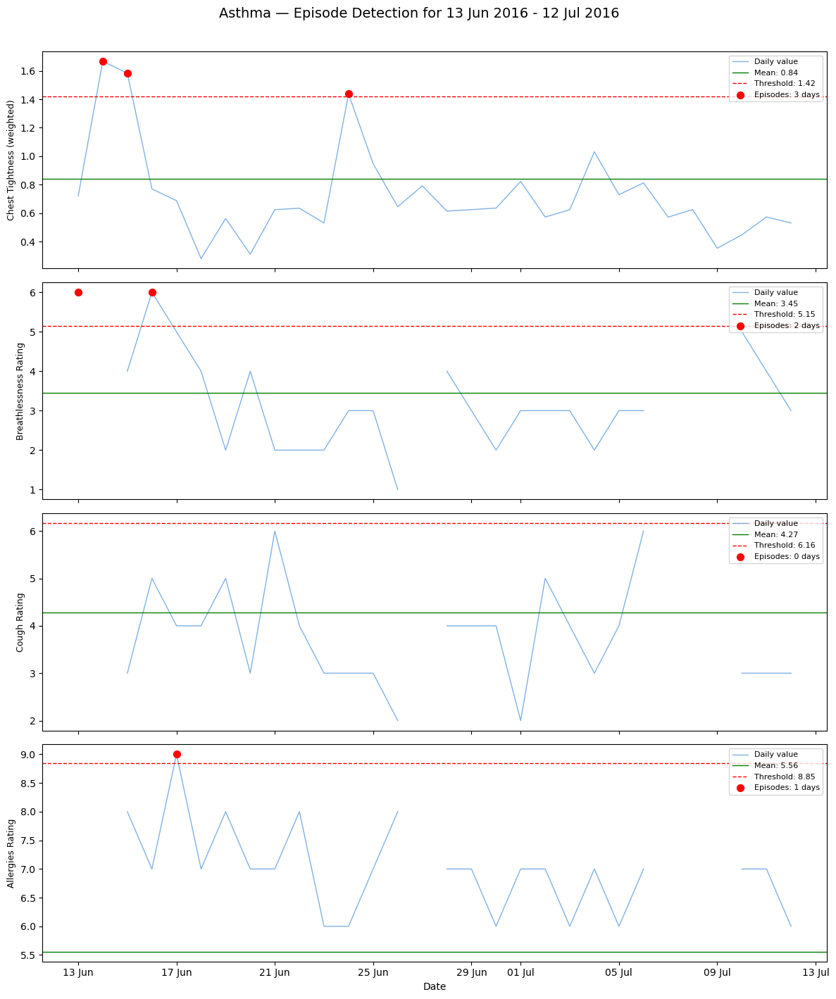

  Total episode days this month: 6

  FLARES OCCURRED ON: 13 Jun (Monday), 14 Jun (Tuesday), 15 Jun (Wednesday), 16 Jun (Thursday), 17 Jun (Friday), 24 Jun (Friday)
Worst day in this period: 10 Jul (composite 6.0/10)
Best day in this period:  23 Jun (composite 2.7/10)


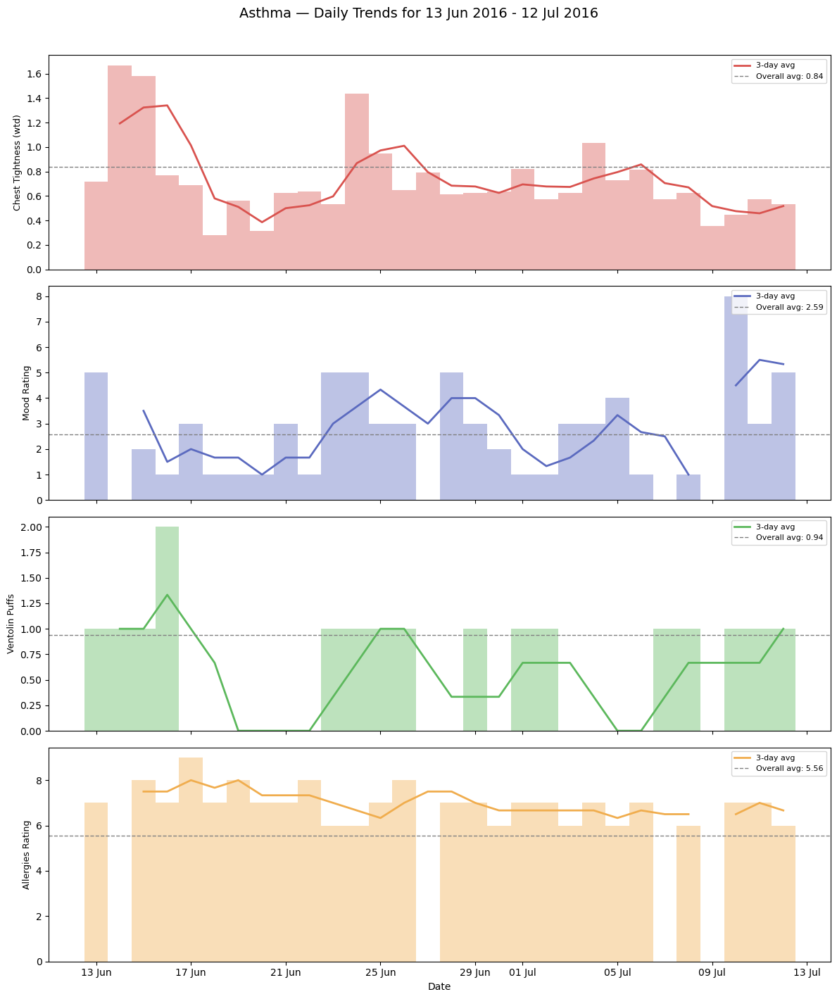

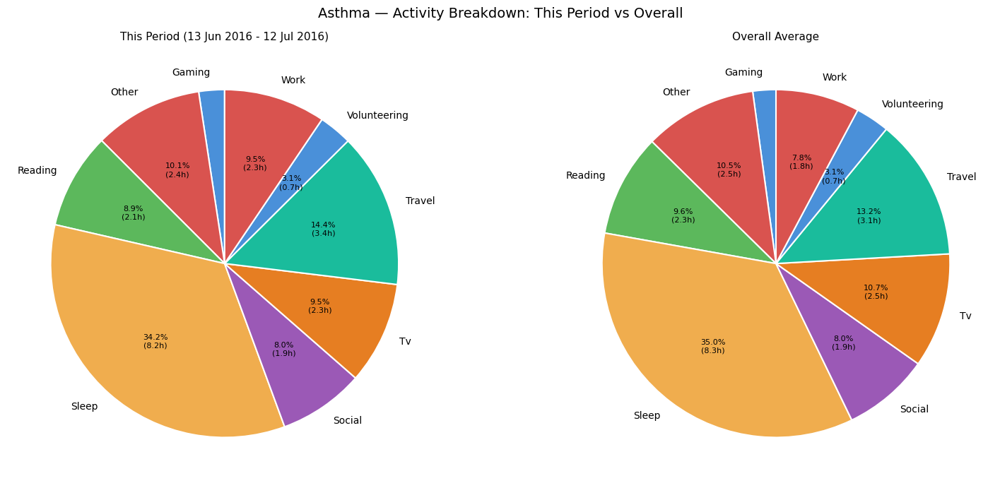

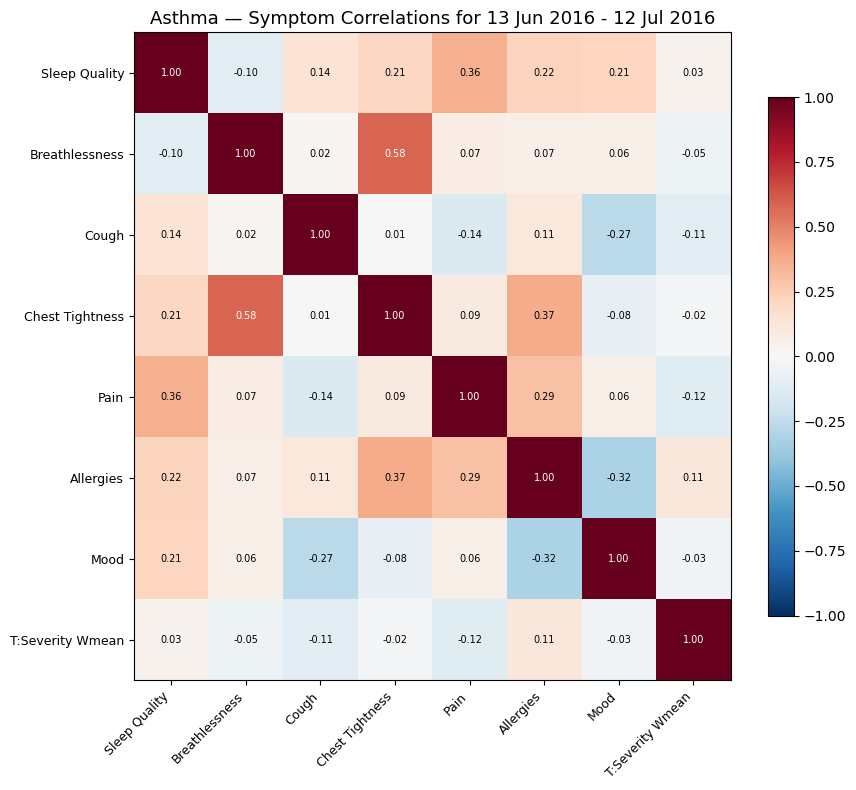


  STRONGEST SYMPTOM CORRELATIONS THIS PERIOD:
    Breathlessness       ↔ Chest Tightness       ρ=+0.582  (strongly move together)
    Chest Tightness      ↔ Allergies             ρ=+0.372  (moderately move together)
    Sleep Quality        ↔ Pain                  ρ=+0.358  (moderately move together)
    Allergies            ↔ Mood                  ρ=-0.319  (moderately move inversely)
    Pain                 ↔ Allergies             ρ=+0.290  (moderately move together)

  NOTABLE CHANGES FROM OVERALL PATTERN:
    Chest Tightness      ↔ Allergies             this period=+0.372  overall=-0.071  (stronger this period)
    Allergies            ↔ Mood                  this period=-0.319  overall=+0.131  (stronger this period)
    Sleep Quality        ↔ Allergies             this period=+0.222  overall=-0.037  (stronger this period)
    Cough                ↔ Allergies             this period=+0.109  overall=-0.283  (weaker this period)
    Breathlessness       ↔ T:Severity Wmean      this

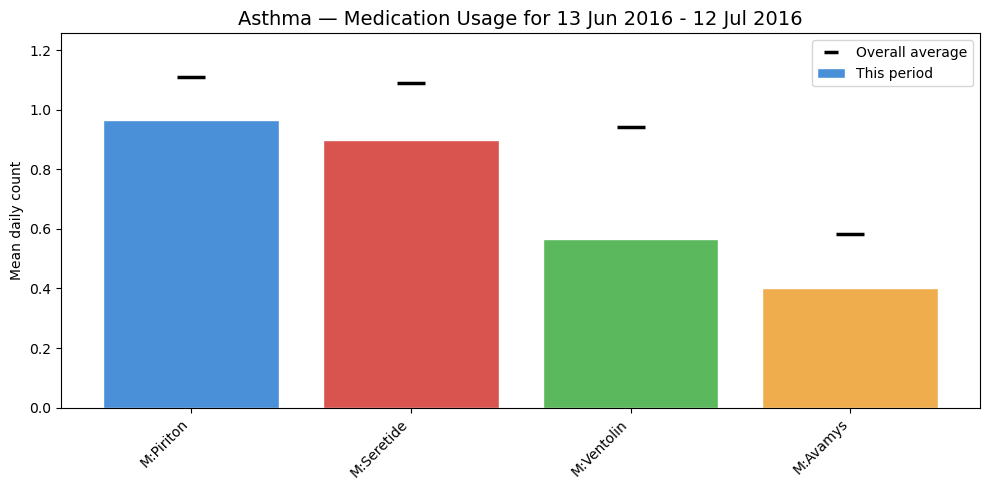


  WHAT YOU TRIED AND WHETHER IT HELPED:
  ──────────────────────────────────────────────────

    M:Ventolin (used on 16 of 30 days):
      Cough                  was lower on days you used it (3.3 vs 4.2, p=0.014) — this suggests it may have helped.

    M:Seretide (used on 23 of 30 days):

    M:Piriton (used on 24 of 30 days):

    M:Avamys (used on 12 of 30 days):
      Cough                  was lower on days you used it (3.4 vs 4.0, p=0.061) — this suggests it may have helped.


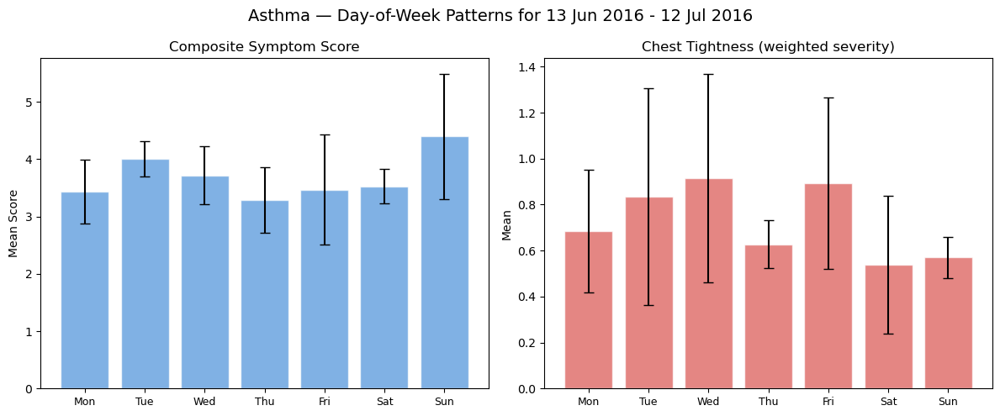

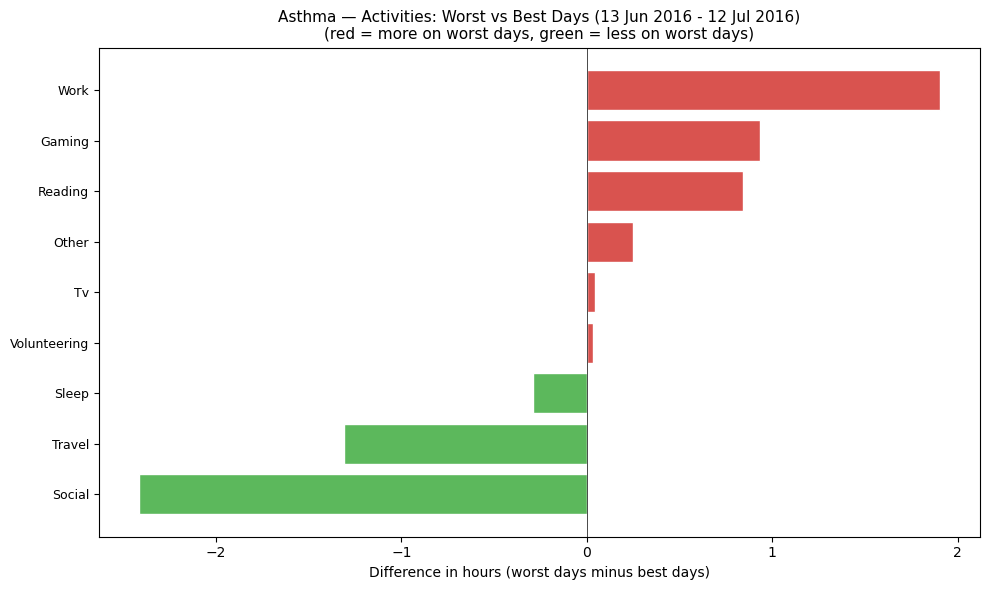


  ACTIVITIES ON WORST vs BEST DAYS:
  Activities associated with HIGHEST symptom scores:
    Work                  +1.9h on worst days  p=0.388
    Gaming                +0.9h on worst days  p=0.108
    Reading               +0.8h on worst days  p=0.273
    Other                 +0.3h on worst days  p=0.930
  Activities associated with LOWEST symptom scores:
    Social                -2.4h on worst days  p=0.158
    Travel                -1.3h on worst days  p=0.189
    Sleep                 -0.3h on worst days  p=0.662


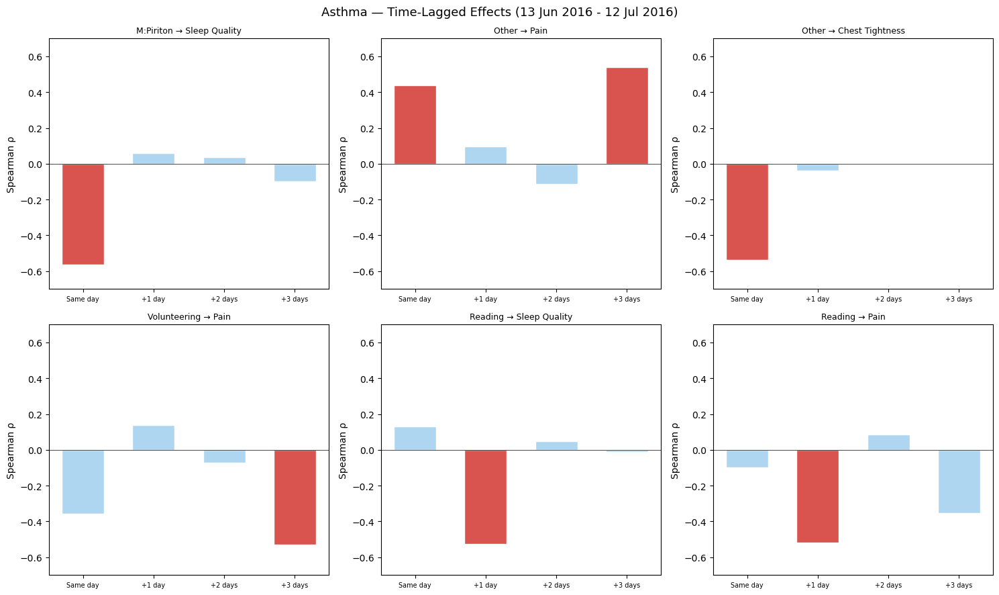


  TIME-LAGGED EFFECTS (strongest associations, p<0.1):
    M:Piriton            → Sleep Quality         ρ=-0.564  same-day  (better) *
    Other                → Pain                  ρ=+0.540  after 3 day(s)  (worse) *
    Other                → Chest Tightness       ρ=-0.536  same-day  (better) *
    Volunteering         → Pain                  ρ=-0.531  after 3 day(s)  (better) *
    Reading              → Sleep Quality         ρ=-0.527  after 1 day(s)  (better) *
    Reading              → Pain                  ρ=-0.520  after 1 day(s)  (better) *
    Sleep                → Mood                  ρ=-0.512  same-day  (better) *
    Gaming               → Pain                  ρ=-0.494  after 3 day(s)  (better) *
    M:Seretide           → Sleep Quality         ρ=-0.492  same-day  (better) *
    M:Ventolin           → Allergies             ρ=+0.488  after 3 day(s)  (worse) *
    Reading              → Mood                  ρ=-0.470  after 3 day(s)  (better) *
    Volunteering        

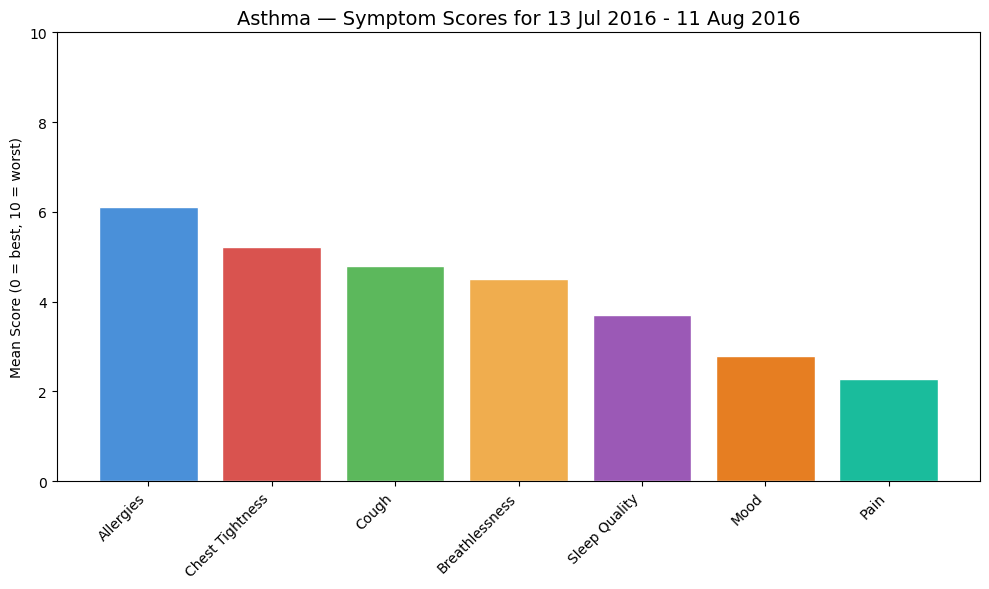

Symptoms with the highest scores in this period were Allergies (6.1), Chest Tightness (5.2), and Cough (4.8).

  Episode detection skipped — not enough data this period.


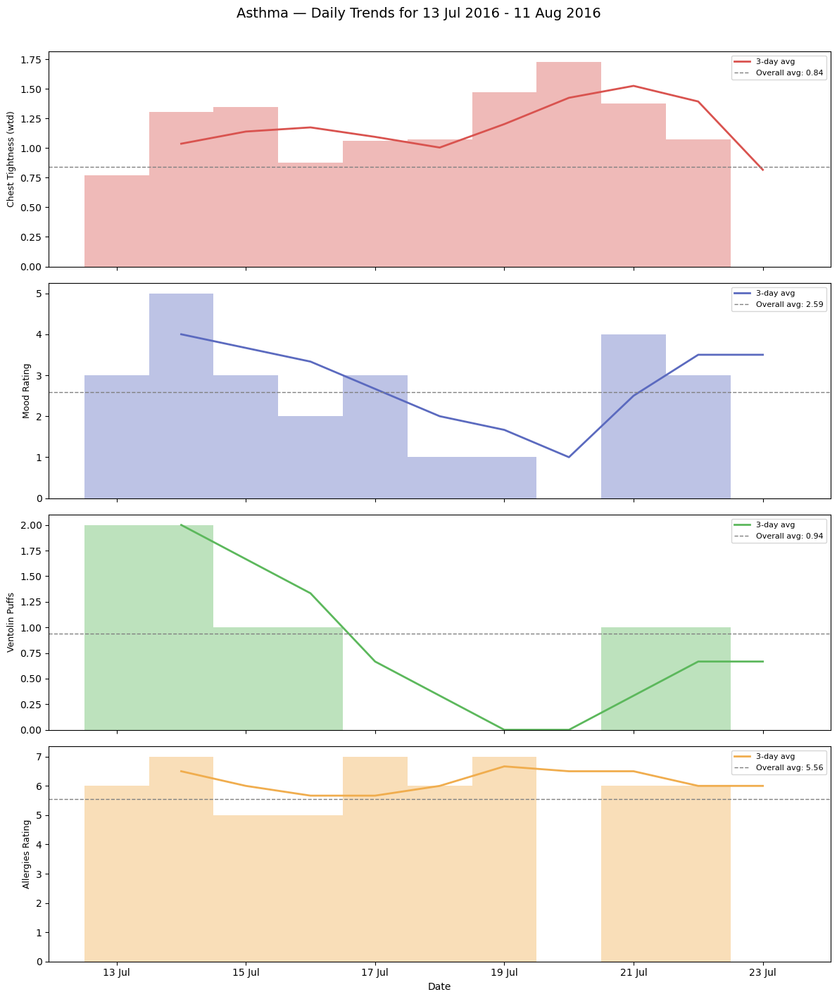

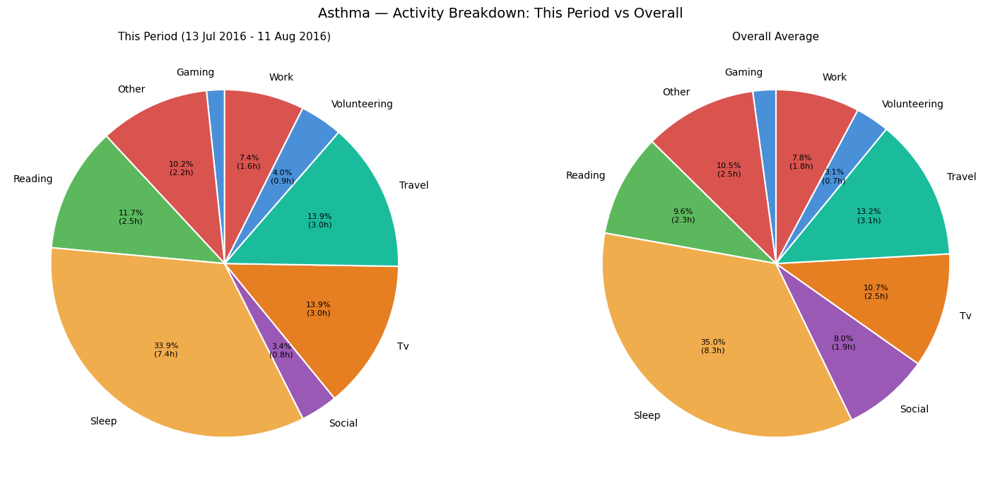

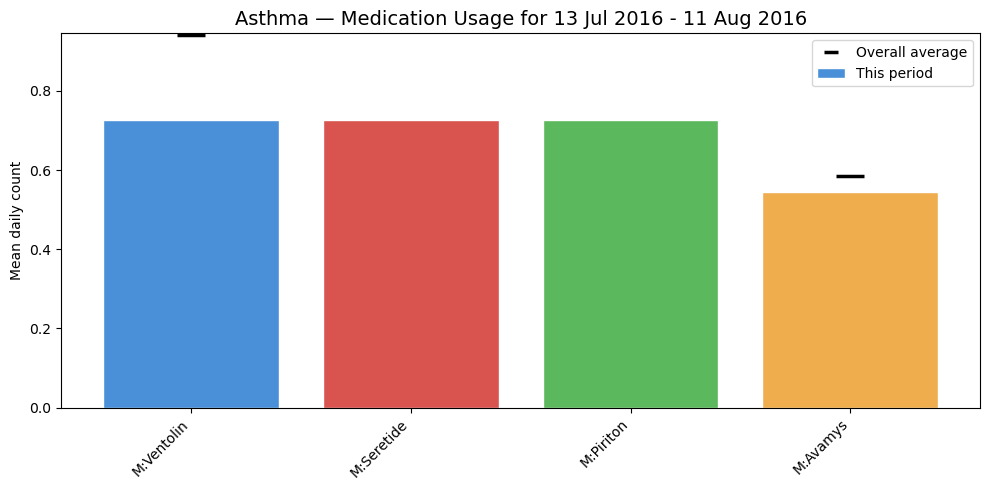


  WHAT YOU TRIED AND WHETHER IT HELPED:
  ──────────────────────────────────────────────────

    M:Ventolin (used on 6 of 11 days):

    M:Seretide (used on 6 of 11 days):

    M:Piriton (used on 6 of 11 days):

    M:Avamys (used on 6 of 11 days):


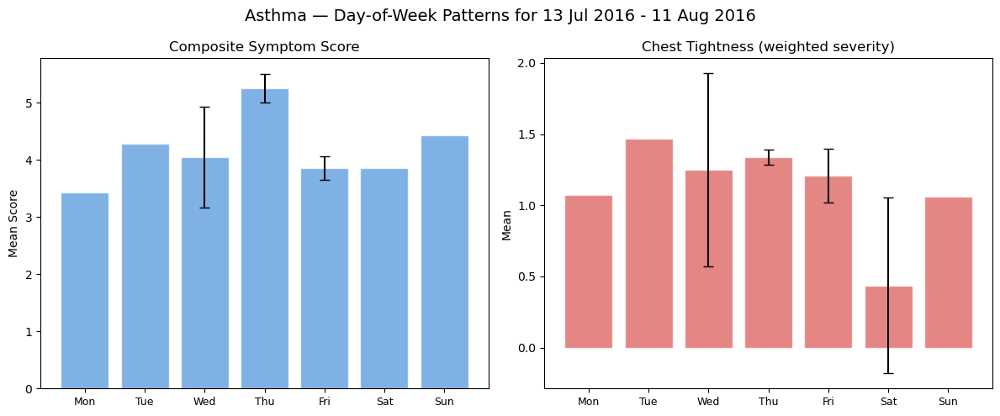


  Insufficient worst/best days for activity comparison (worst=4, best=1)

  Insufficient data for lag analysis in this period

  TRIGGERS OF CHEST TIGHTNESS (WEIGHTED SEVERITY):
    No significant triggers identified in this period

  RELIEVERS:
    No significant relievers identified in this period

  APPEARED TO HAVE NO SIGNIFICANT EFFECT ON SYMPTOMS:
    Gaming, Other, Sleep, Travel, Volunteering, M:Ventolin, M:Seretide, M:Piriton, M:Avamys
    (all p>0.3)

  WITH REGARD TO CHEST TIGHTNESS (WEIGHTED SEVERITY):
    Work appeared to have most effect in exacerbation (ρ=+0.540, p=0.0866)
    Social appeared to have most effect in relief (ρ=-0.476, p=0.1391)

  COMPARED TO PREVIOUS 30-DAY WINDOW (13 Jun – 12 Jul):
    Sleep Quality              prev=2.96  now=3.70  (+0.74, worse)
    Breathlessness             prev=3.31  now=4.50  (+1.19, worse)
    Cough                      prev=3.73  now=4.80  (+1.07, worse)
    Chest Tightness            prev=3.73  now=5.22  (+1.49, worse)
    Pain 

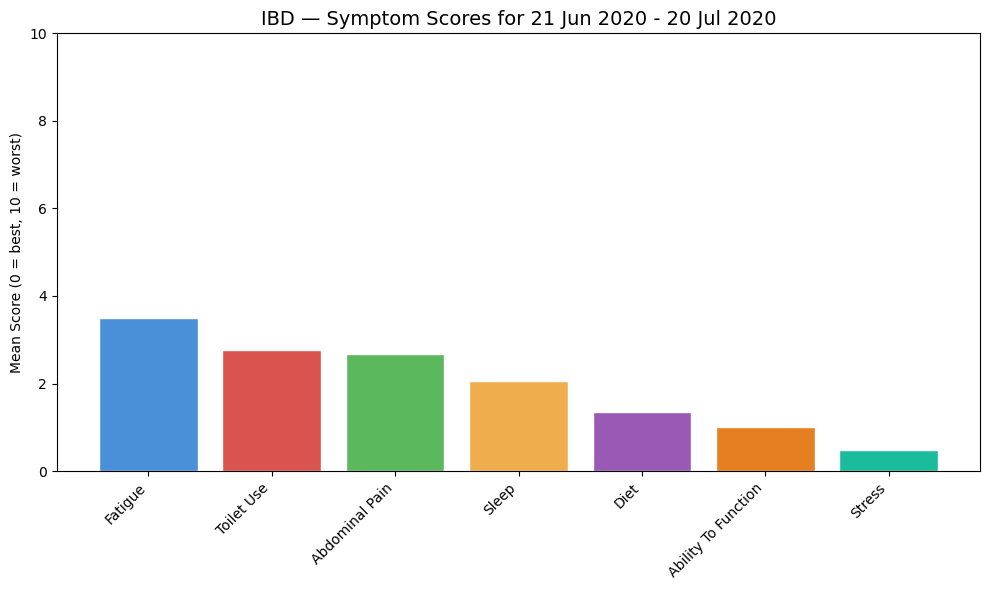

Symptoms with the highest scores in this period were Fatigue (3.5), Toilet Use (2.8), and Abdominal Pain (2.7).


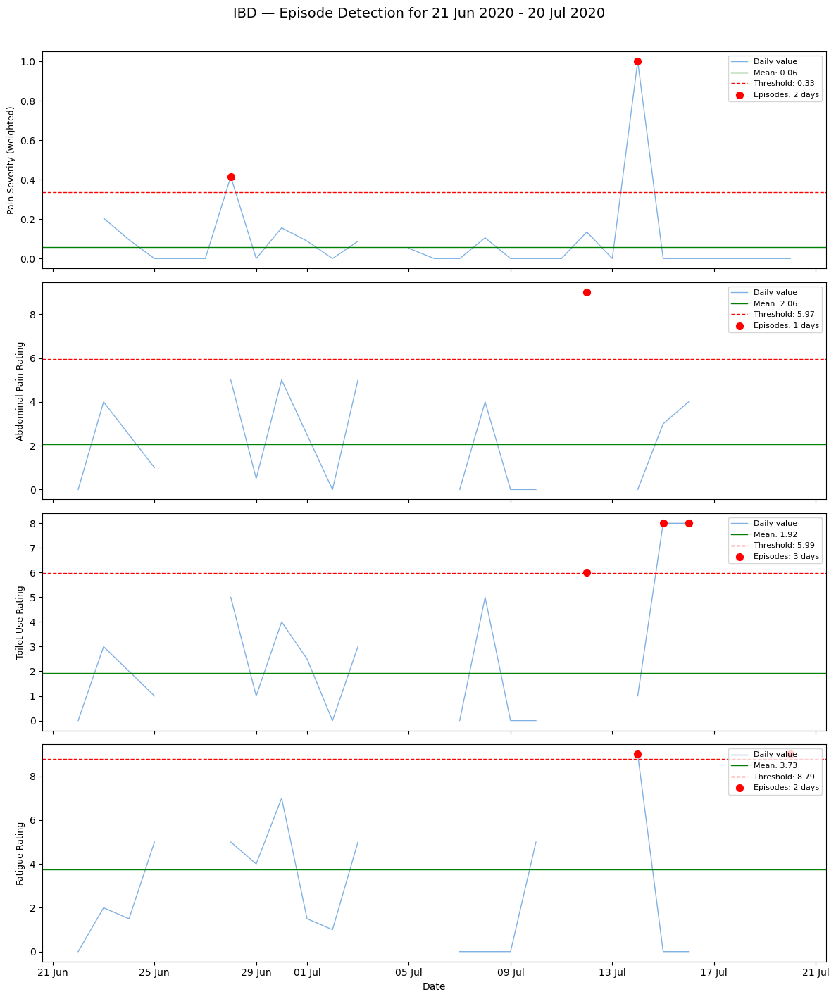

  Total episode days this month: 8

  FLARES OCCURRED ON: 28 Jun (Sunday), 12 Jul (Sunday), 14 Jul (Tuesday), 15 Jul (Wednesday), 16 Jul (Thursday), 20 Jul (Monday)
Worst day in this period: 12 Jul (composite 5.6/10)
Best day in this period:  22 Jun (composite 0.0/10)


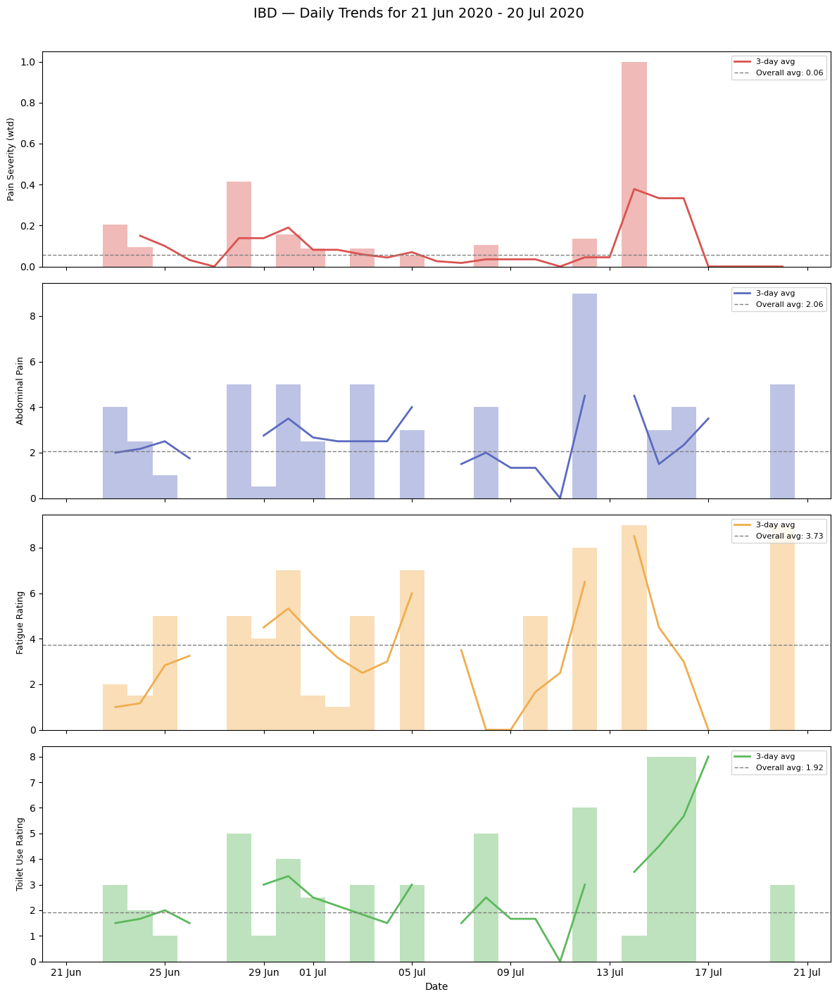

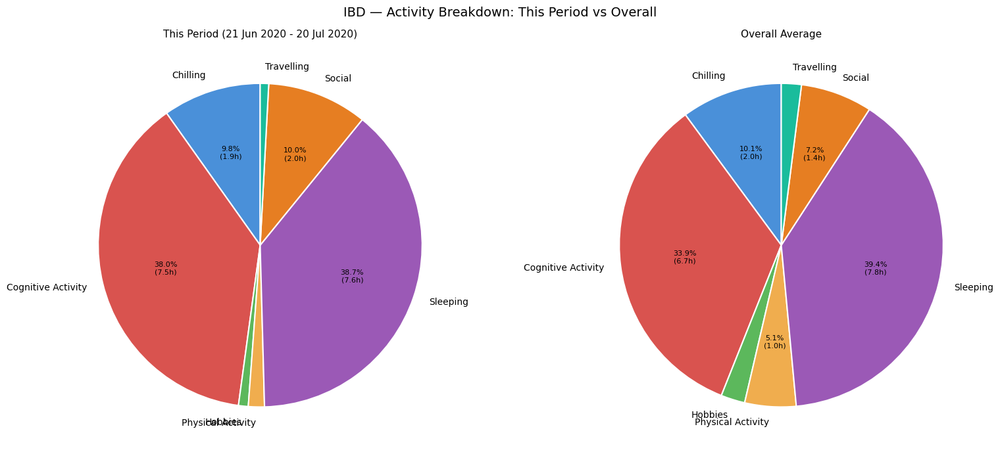

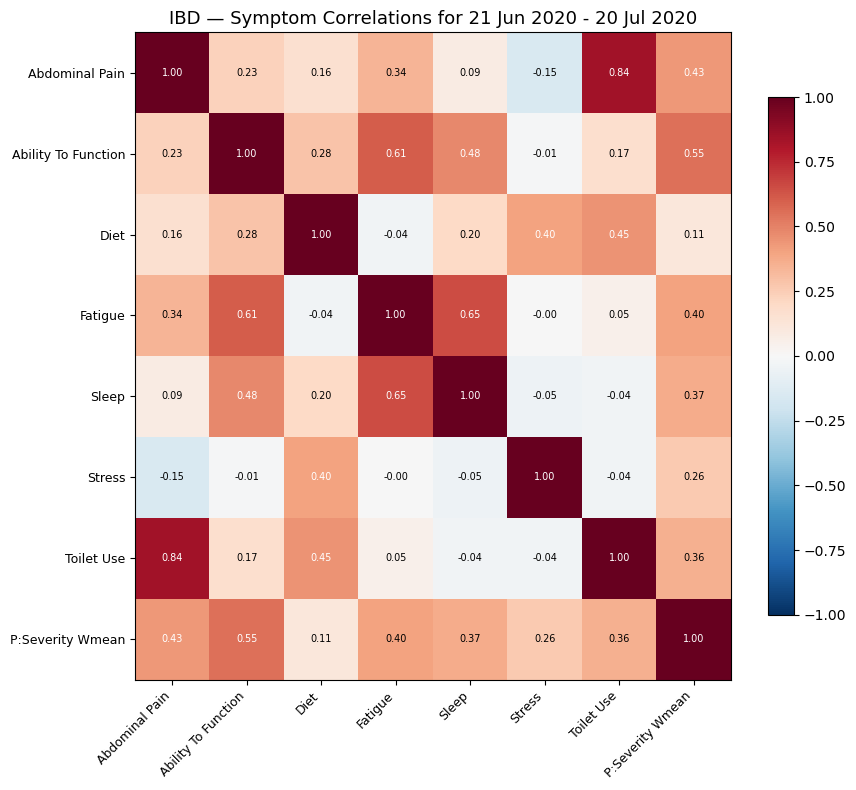


  STRONGEST SYMPTOM CORRELATIONS THIS PERIOD:
    Abdominal Pain       ↔ Toilet Use            ρ=+0.841  (strongly move together)
    Fatigue              ↔ Sleep                 ρ=+0.649  (strongly move together)
    Ability To Function  ↔ Fatigue               ρ=+0.605  (strongly move together)
    Ability To Function  ↔ P:Severity Wmean      ρ=+0.552  (strongly move together)
    Ability To Function  ↔ Sleep                 ρ=+0.482  (moderately move together)

  NOTABLE CHANGES FROM OVERALL PATTERN:
    Ability To Function  ↔ Sleep                 this period=+0.482  overall=+0.228  (stronger this period)
    Abdominal Pain       ↔ Stress                this period=-0.151  overall=+0.221  (weaker this period)
    Stress               ↔ Toilet Use            this period=-0.037  overall=+0.323  (weaker this period)
    Ability To Function  ↔ Stress                this period=-0.011  overall=+0.318  (weaker this period)


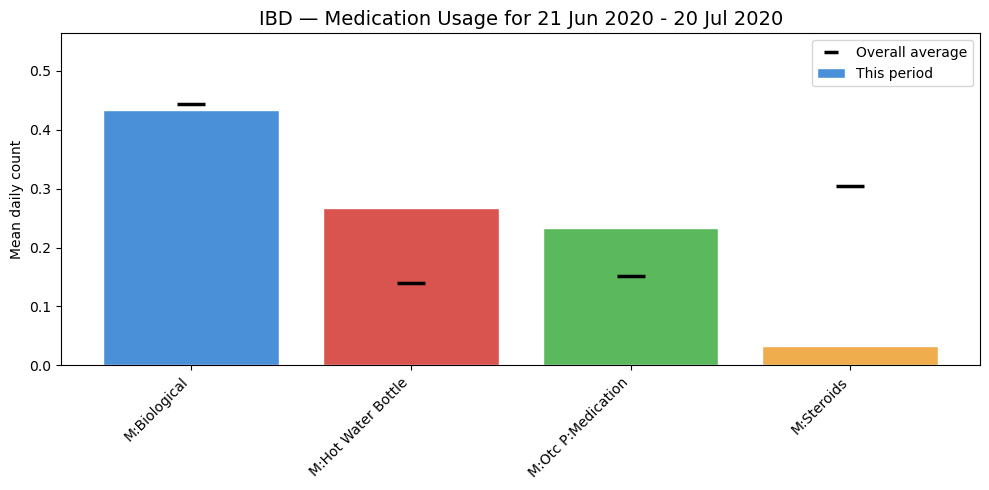


  WHAT YOU TRIED AND WHETHER IT HELPED:
  ──────────────────────────────────────────────────

    M:Biological (used on 12 of 30 days):

    M:Steroids: used on only 1 day(s) — not enough usage data to assess effectiveness yet. Keep logging when you use it.

    M:Otc P:Medication (used on 5 of 30 days):
      Ability To Function    was higher on days you used it (3.0 vs 0.5) — but this likely means you reached for it on worse days, not that it made things worse.
      P:Severity Wmean       was higher on days you used it (0.4 vs 0.0) — but this likely means you reached for it on worse days, not that it made things worse.

    M:Hot Water Bottle (used on 7 of 30 days):
      Abdominal Pain         was higher on days you used it (3.8 vs 2.2) — but this likely means you reached for it on worse days, not that it made things worse.
      P:Severity Wmean       was higher on days you used it (0.2 vs 0.1) — but this likely means you reached for it on worse days, not that it made things wors

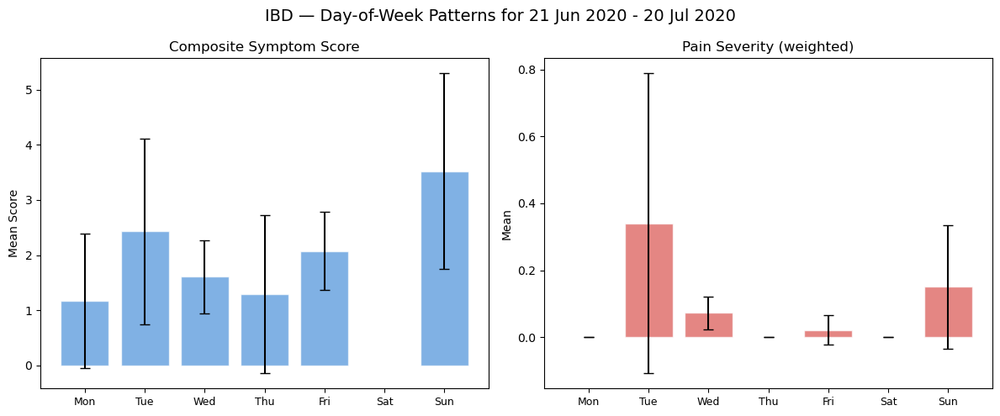

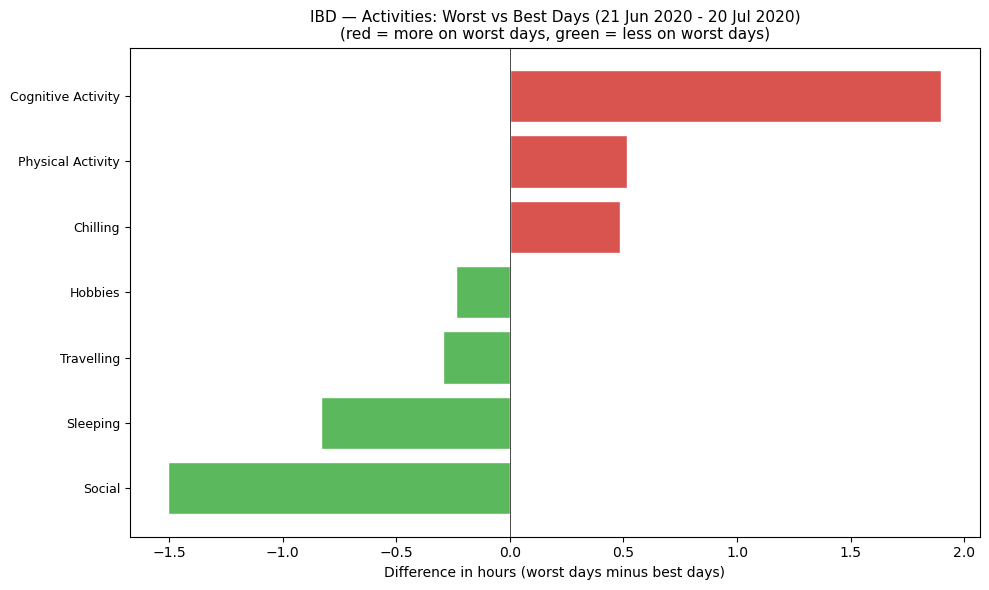


  ACTIVITIES ON WORST vs BEST DAYS:
  Activities associated with HIGHEST symptom scores:
    Cognitive Activity    +1.9h on worst days  p=0.382
    Physical Activity     +0.5h on worst days  p=0.053
    Chilling              +0.5h on worst days  p=0.424
  Activities associated with LOWEST symptom scores:
    Social                -1.5h on worst days  p=0.147
    Sleeping              -0.8h on worst days  p=0.356
    Travelling            -0.3h on worst days  p=0.389
    Hobbies               -0.2h on worst days  p=0.389


C:\Users\cbc15\AppData\Local\Temp\ipykernel_832\633054355.py:562: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = stats.spearmanr(valid["p"], valid["o"])
C:\Users\cbc15\AppData\Local\Temp\ipykernel_832\633054355.py:562: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = stats.spearmanr(valid["p"], valid["o"])
C:\Users\cbc15\AppData\Local\Temp\ipykernel_832\633054355.py:562: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = stats.spearmanr(valid["p"], valid["o"])
C:\Users\cbc15\AppData\Local\Temp\ipykernel_832\633054355.py:562: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = stats.spearmanr(valid["p"], valid["o"])
C:\Users\cbc15\AppData\Local\Temp\ipykernel_832\633054355.py:562: ConstantInputWarning: An input array is constant; the correlation coefficient is not defin

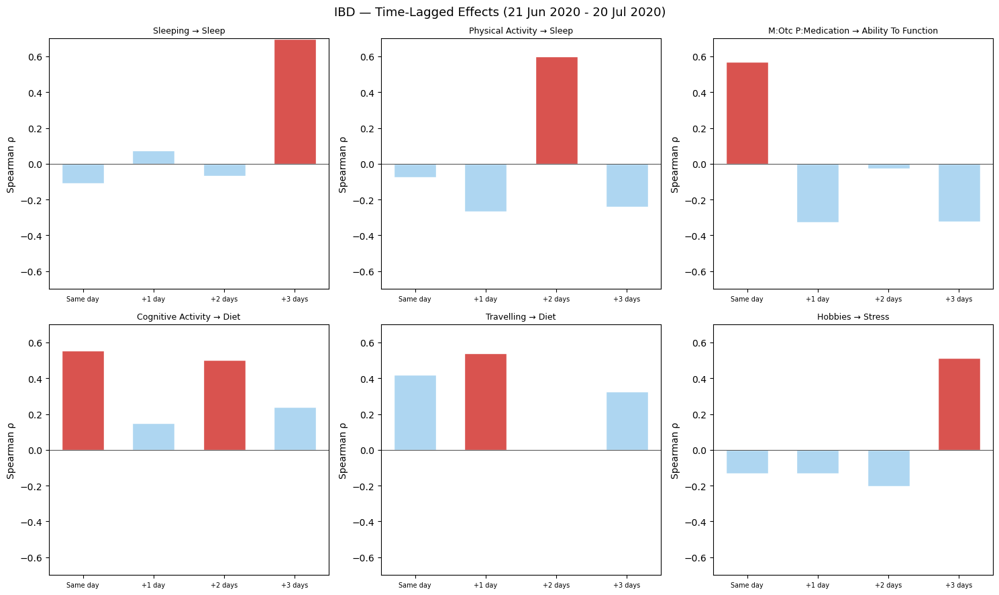


  TIME-LAGGED EFFECTS (strongest associations, p<0.1):
    Sleeping             → Sleep                 ρ=+0.696  after 3 day(s)  (worse) *
    Physical Activity    → Sleep                 ρ=+0.599  after 2 day(s)  (worse) *
    M:Otc P:Medication   → Ability To Function   ρ=+0.570  same-day  (worse) *
    Cognitive Activity   → Diet                  ρ=+0.555  same-day  (worse) *
    Travelling           → Diet                  ρ=+0.539  after 1 day(s)  (worse) *
    Hobbies              → Stress                ρ=+0.514  after 3 day(s)  (worse) *
    Travelling           → Stress                ρ=+0.514  after 3 day(s)  (worse) *
    Hobbies              → Ability To Function   ρ=+0.503  after 3 day(s)  (worse) *
    Travelling           → Ability To Function   ρ=+0.503  after 3 day(s)  (worse) *
    M:Steroids           → Stress                ρ=+0.500  after 2 day(s)  (worse) *
    Cognitive Activity   → Fatigue               ρ=+0.485  same-day  (worse) *
    Travelling           → 

C:\Users\cbc15\AppData\Local\Temp\ipykernel_832\633054355.py:648: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = stats.spearmanr(valid["x"], valid["y"])


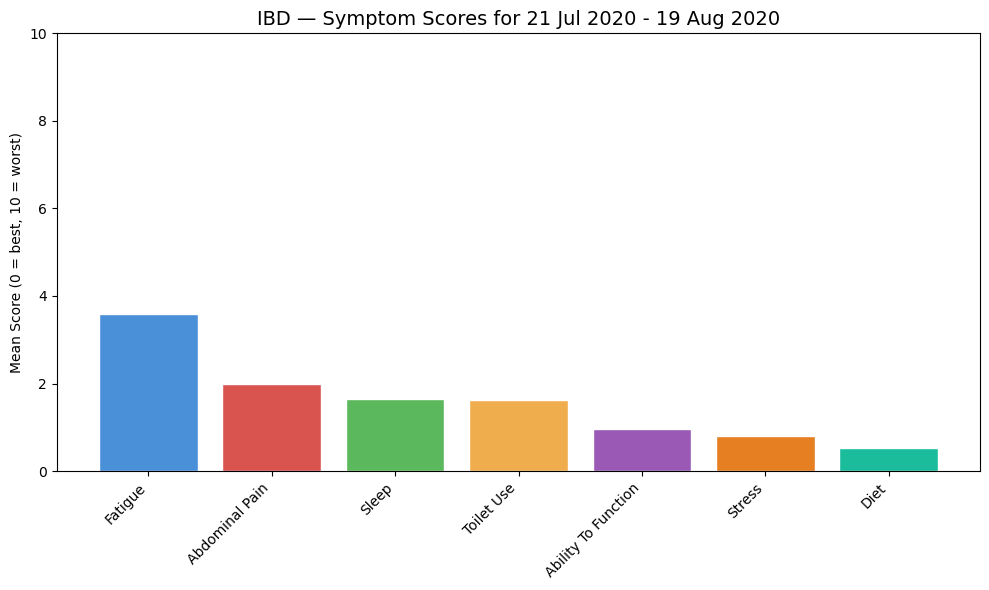

Symptoms with the highest scores in this period were Fatigue (3.6), Abdominal Pain (2.0), and Sleep (1.6).


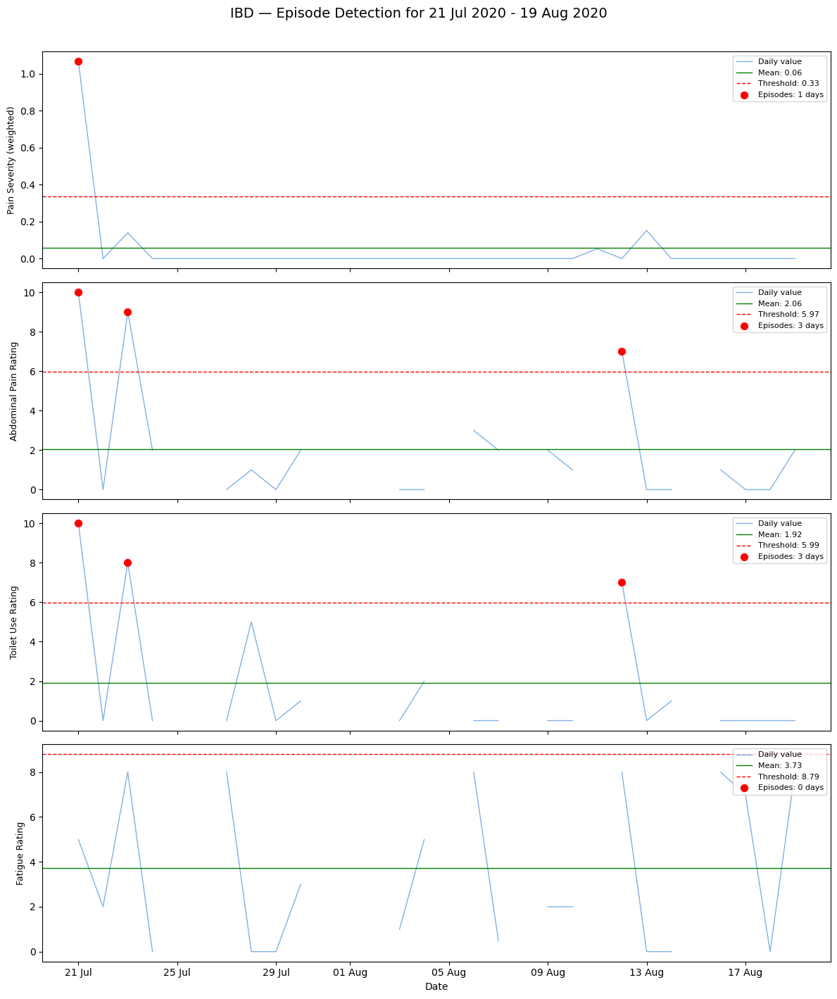

  Total episode days this month: 7

  FLARES OCCURRED ON: 21 Jul (Tuesday), 23 Jul (Thursday), 12 Aug (Wednesday)
Worst day in this period: 23 Jul (composite 7.7/10)
Best day in this period:  29 Jul (composite 0.0/10)


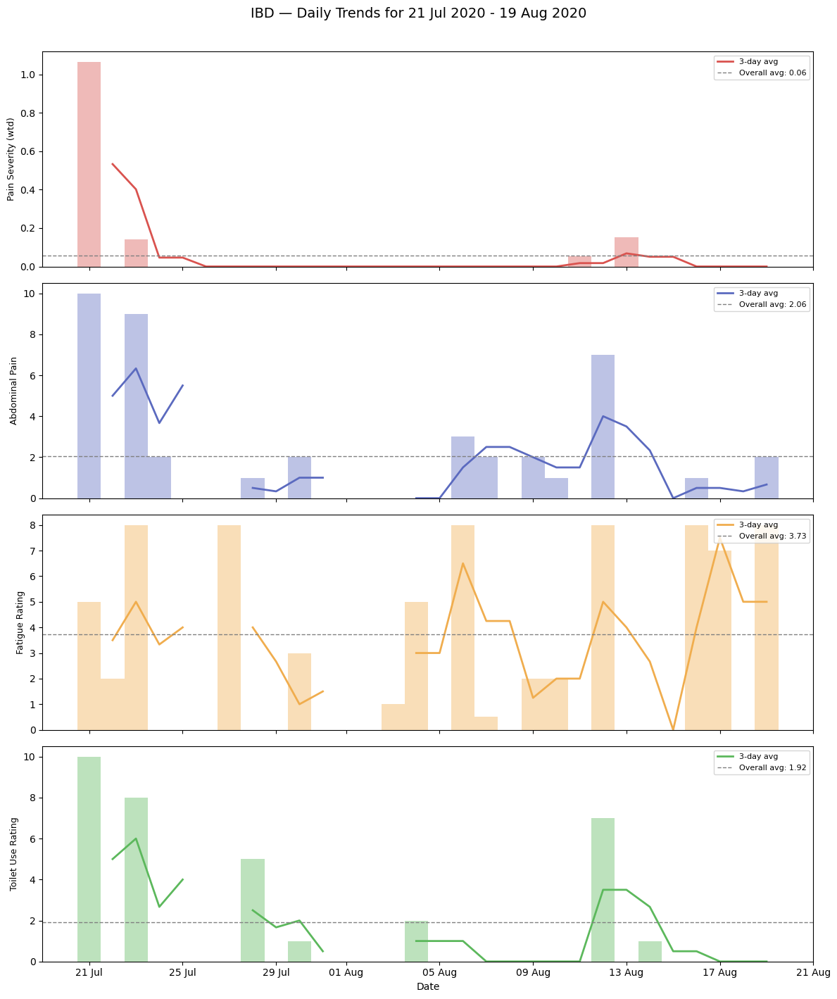

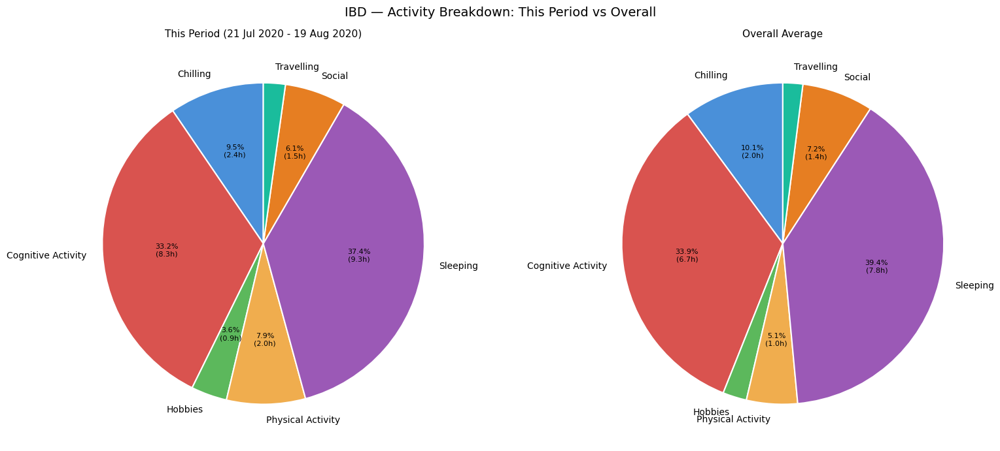

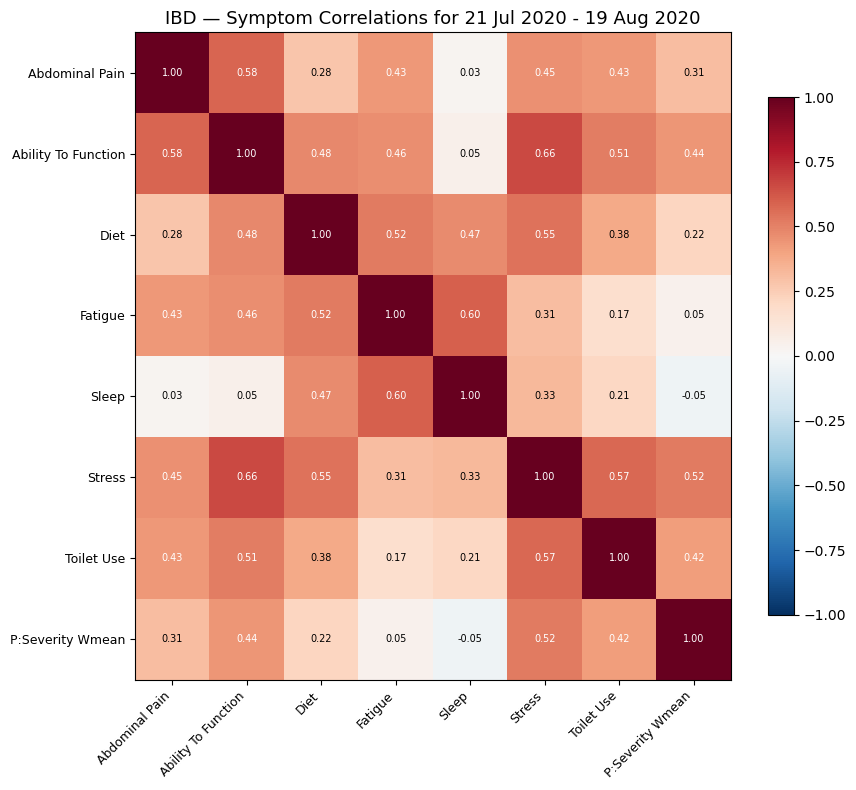


  STRONGEST SYMPTOM CORRELATIONS THIS PERIOD:
    Ability To Function  ↔ Stress                ρ=+0.664  (strongly move together)
    Fatigue              ↔ Sleep                 ρ=+0.595  (strongly move together)
    Abdominal Pain       ↔ Ability To Function   ρ=+0.582  (strongly move together)
    Stress               ↔ Toilet Use            ρ=+0.573  (strongly move together)
    Diet                 ↔ Stress                ρ=+0.546  (strongly move together)

  NOTABLE CHANGES FROM OVERALL PATTERN:
    Ability To Function  ↔ Stress                this period=+0.664  overall=+0.318  (stronger this period)
    Stress               ↔ P:Severity Wmean      this period=+0.518  overall=+0.241  (stronger this period)
    Diet                 ↔ Fatigue               this period=+0.517  overall=+0.169  (stronger this period)
    Abdominal Pain       ↔ Toilet Use            this period=+0.433  overall=+0.773  (weaker this period)
    Sleep                ↔ Stress                this period=+

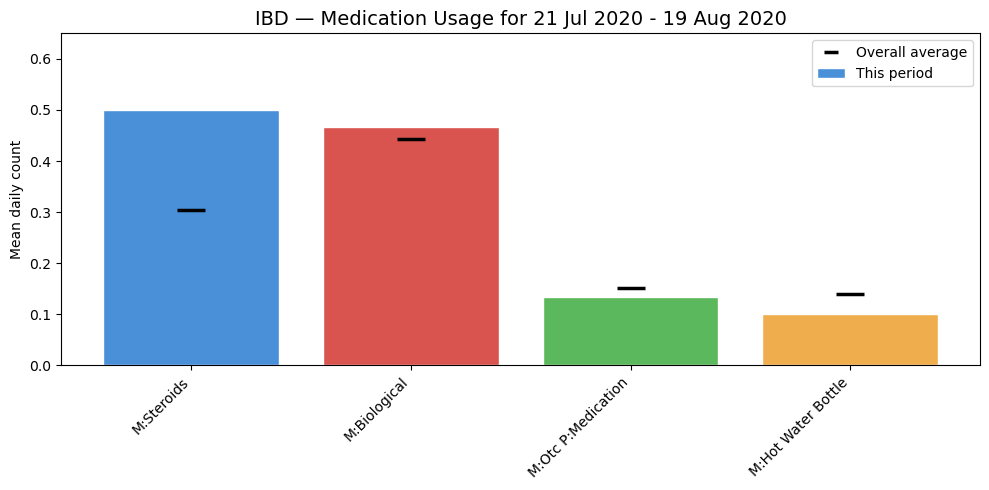


  WHAT YOU TRIED AND WHETHER IT HELPED:
  ──────────────────────────────────────────────────

    M:Biological (used on 14 of 30 days):
      Ability To Function    was higher on days you used it (1.4 vs 0.0) — but this likely means you reached for it on worse days, not that it made things worse.

    M:Steroids (used on 15 of 30 days):
      Next-day Ability To Function was better after using it (0.0 vs 1.6) — suggests a delayed benefit.
      Next-day Diet               was better after using it (0.0 vs 1.2) — suggests a delayed benefit.

    M:Otc P:Medication (used on 4 of 30 days):
      Abdominal Pain         was higher on days you used it (6.8 vs 0.9) — but this likely means you reached for it on worse days, not that it made things worse.
      Ability To Function    was higher on days you used it (4.5 vs 0.1) — but this likely means you reached for it on worse days, not that it made things worse.
      Diet                   was higher on days you used it (2.5 vs 0.1) — but th

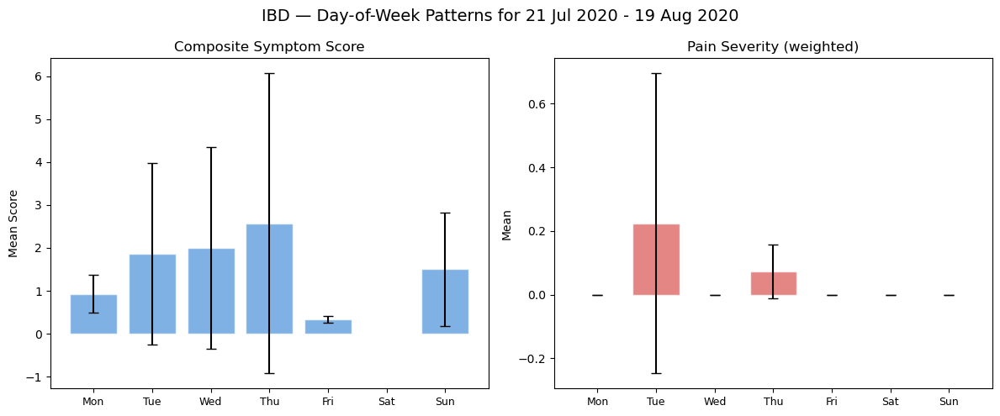

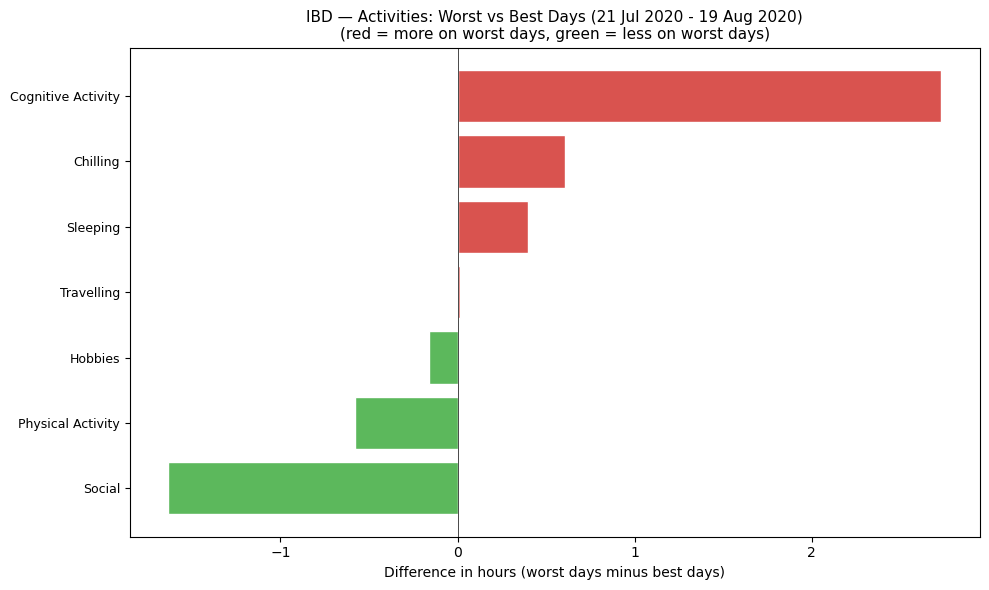


  ACTIVITIES ON WORST vs BEST DAYS:
  Activities associated with HIGHEST symptom scores:
    Cognitive Activity    +2.7h on worst days  p=0.405
    Chilling              +0.6h on worst days  p=0.405
    Sleeping              +0.4h on worst days  p=0.616
  Activities associated with LOWEST symptom scores:
    Social                -1.6h on worst days  p=0.189
    Physical Activity     -0.6h on worst days  p=0.188
    Hobbies               -0.2h on worst days  p=0.821


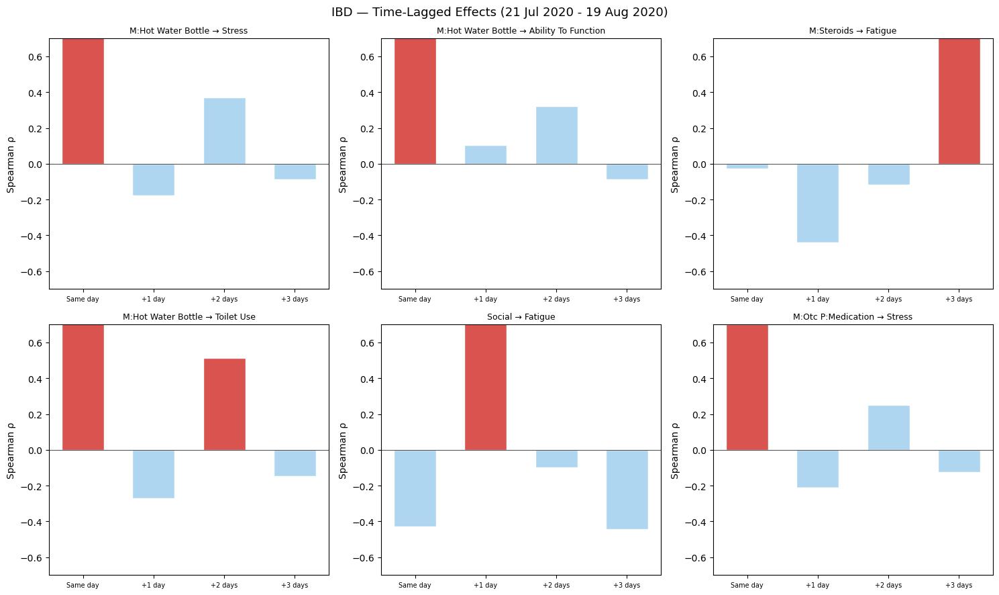


  TIME-LAGGED EFFECTS (strongest associations, p<0.1):
    M:Hot Water Bottle   → Stress                ρ=+0.855  same-day  (worse) *
    M:Hot Water Bottle   → Ability To Function   ρ=+0.812  same-day  (worse) *
    M:Steroids           → Fatigue               ρ=+0.772  after 3 day(s)  (worse) *
    M:Hot Water Bottle   → Toilet Use            ρ=+0.723  same-day  (worse) *
    Social               → Fatigue               ρ=+0.715  after 1 day(s)  (worse) *
    M:Otc P:Medication   → Stress                ρ=+0.703  same-day  (worse) *
    M:Otc P:Medication   → Ability To Function   ρ=+0.657  same-day  (worse) *
    Physical Activity    → Toilet Use            ρ=+0.647  after 1 day(s)  (worse) *
    M:Hot Water Bottle   → Abdominal Pain        ρ=+0.637  same-day  (worse) *
    M:Hot Water Bottle   → Diet                  ρ=+0.628  same-day  (worse) *
    Social               → Diet                  ρ=+0.595  after 1 day(s)  (worse) *
    M:Otc P:Medication   → Abdominal Pain        ρ=

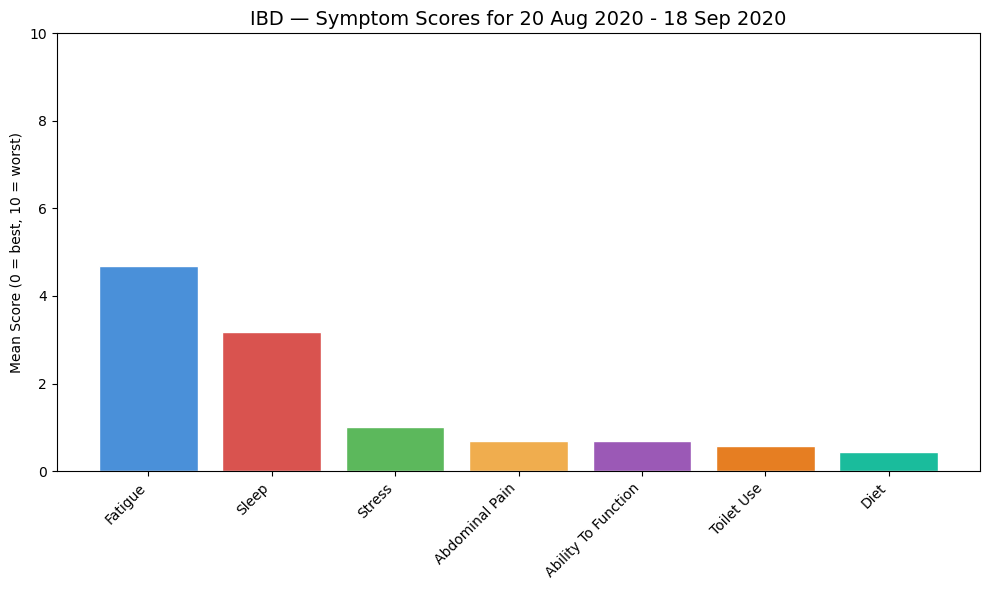

Symptoms with the highest scores in this period were Fatigue (4.7), Sleep (3.2), and Stress (1.0).

  Episode detection skipped — not enough data this period.


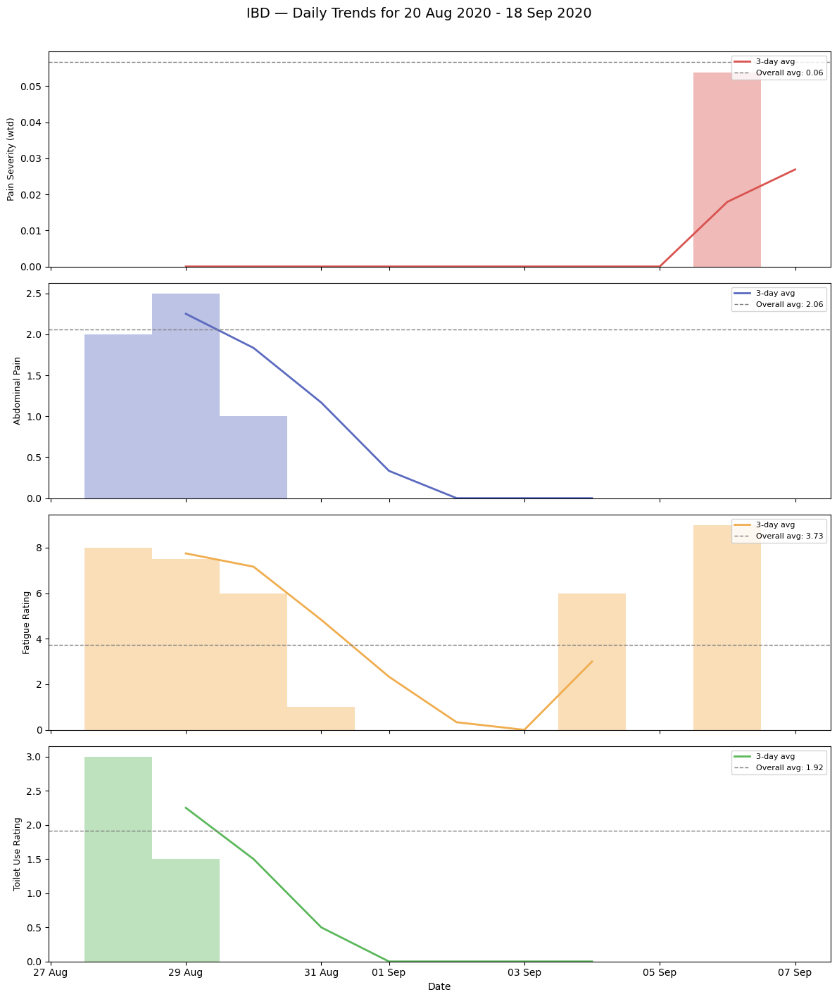

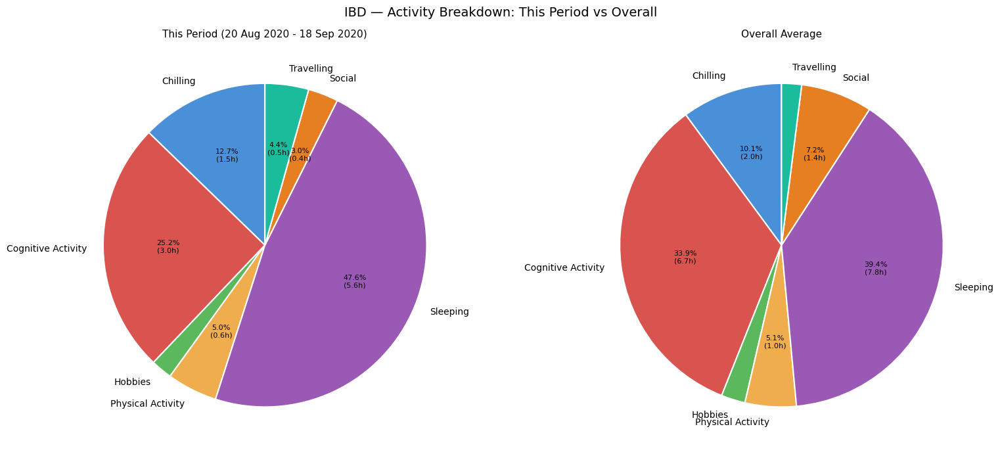

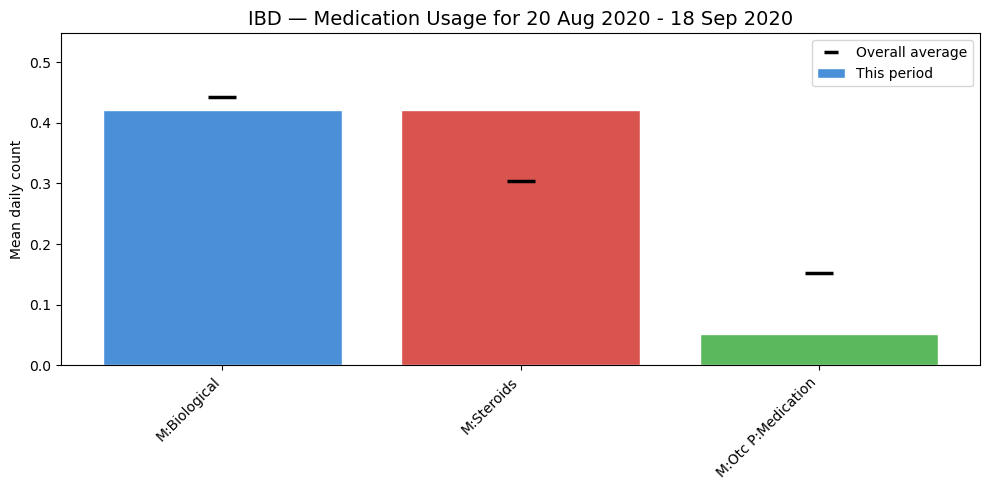


  WHAT YOU TRIED AND WHETHER IT HELPED:
  ──────────────────────────────────────────────────

    M:Biological (used on 8 of 19 days):

    M:Steroids (used on 8 of 19 days):

    M:Otc P:Medication: used on only 1 day(s) — not enough usage data to assess effectiveness yet. Keep logging when you use it.

  WHAT YOUR NOTES TELL US:
  ──────────────────────────────────────────────────
    You wrote 13 notes this period.
    • Mentioned 'fatigue' on 2 day(s)
    • Mentioned 'good day' on 2 day(s)
    • Mentioned 'abdominal pain' on 1 day(s)


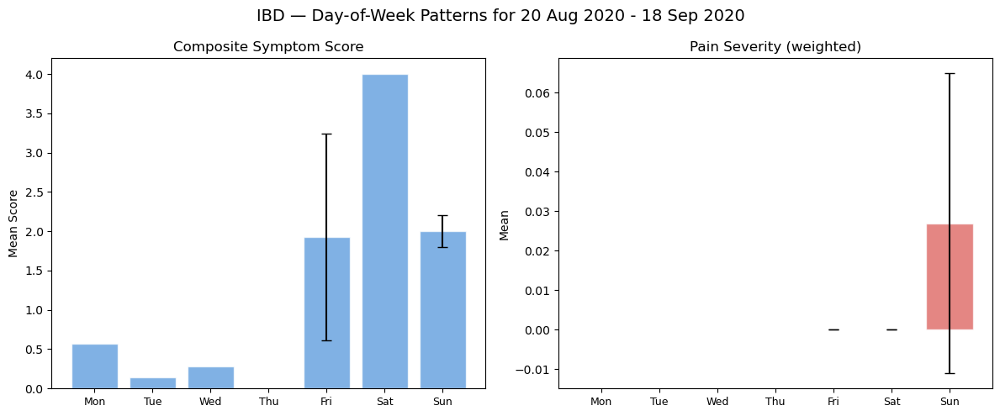


  Insufficient worst/best days for activity comparison (worst=0, best=9)

  Insufficient data for lag analysis in this period

  TRIGGERS OF PAIN SEVERITY (WEIGHTED):
    No significant triggers identified in this period

  RELIEVERS:
    No significant relievers identified in this period

  APPEARED TO HAVE NO SIGNIFICANT EFFECT ON SYMPTOMS:
    Cognitive Activity, Hobbies, Sleeping, M:Biological, M:Steroids, M:Otc P:Medication
    (all p>0.3)

  WITH REGARD TO PAIN SEVERITY (WEIGHTED):
    Travelling appeared to have most effect in exacerbation (ρ=+0.574, p=0.0829)

  COMPARED TO PREVIOUS 30-DAY WINDOW (21 Jul – 19 Aug):
    Abdominal Pain             prev=2.00  now=0.69  (-1.31, better)
    Ability To Function        prev=0.95  now=0.69  (-0.26, better)
    Diet                       prev=0.52  now=0.44  (-0.09, better)
    Fatigue                    prev=3.60  now=4.69  (+1.09, worse)
    Sleep                      prev=1.64  now=3.19  (+1.54, worse)
    Stress                    

C:\Users\cbc15\AppData\Local\Temp\ipykernel_832\633054355.py:648: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = stats.spearmanr(valid["x"], valid["y"])


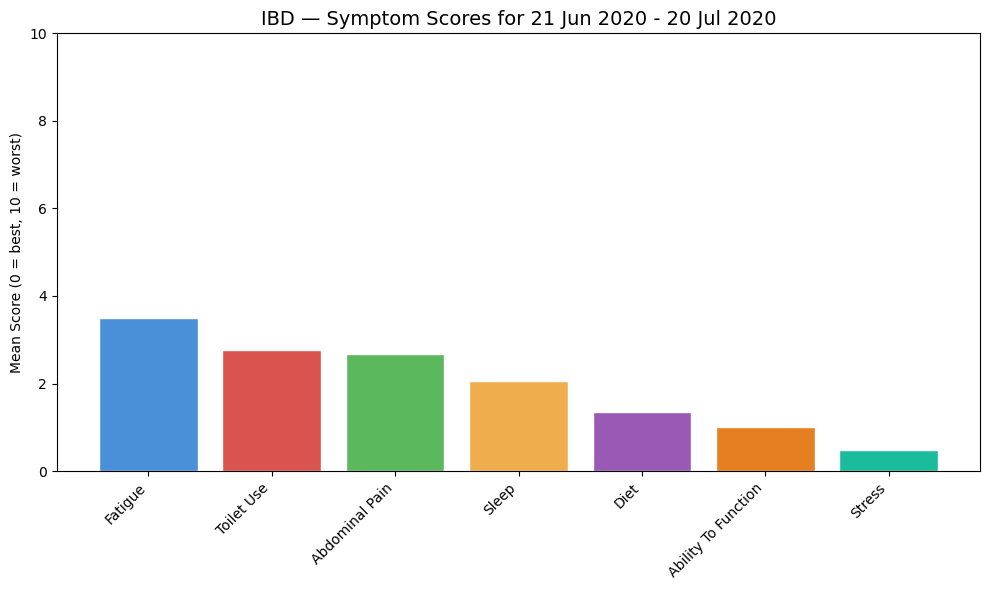

Symptoms with the highest scores in this period were Fatigue (3.5), Toilet Use (2.8), and Abdominal Pain (2.7).


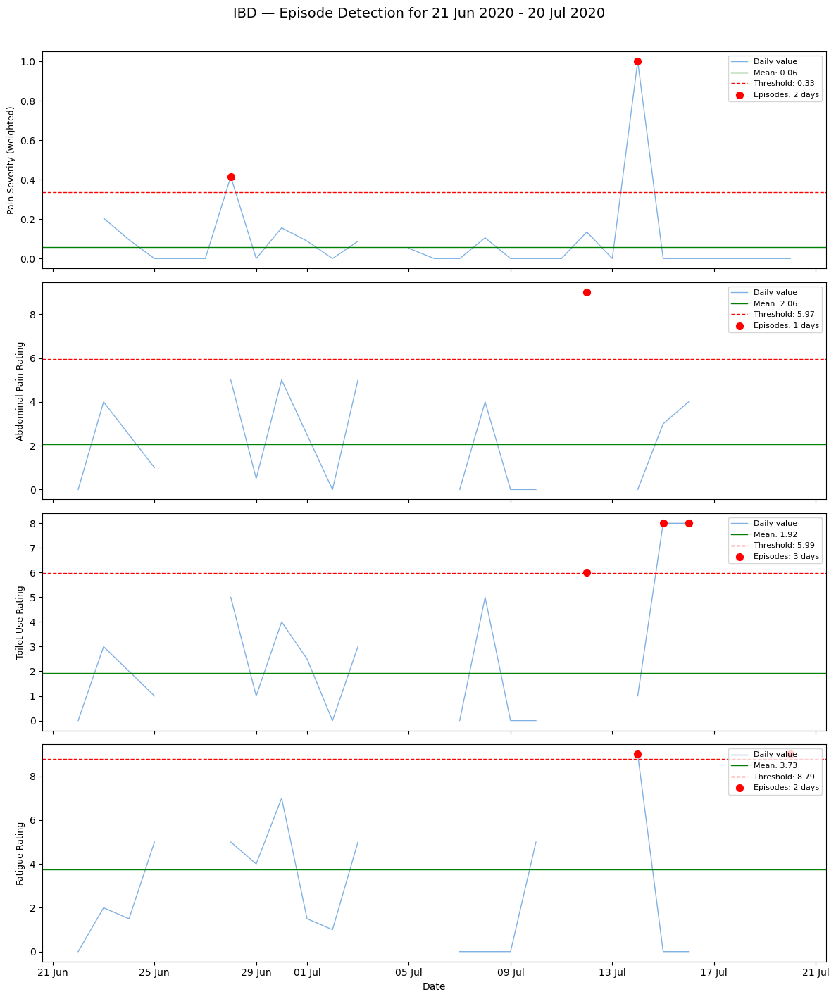

  Total episode days this month: 8

  FLARES OCCURRED ON: 28 Jun (Sunday), 12 Jul (Sunday), 14 Jul (Tuesday), 15 Jul (Wednesday), 16 Jul (Thursday), 20 Jul (Monday)
Worst day in this period: 12 Jul (composite 5.6/10)
Best day in this period:  22 Jun (composite 0.0/10)


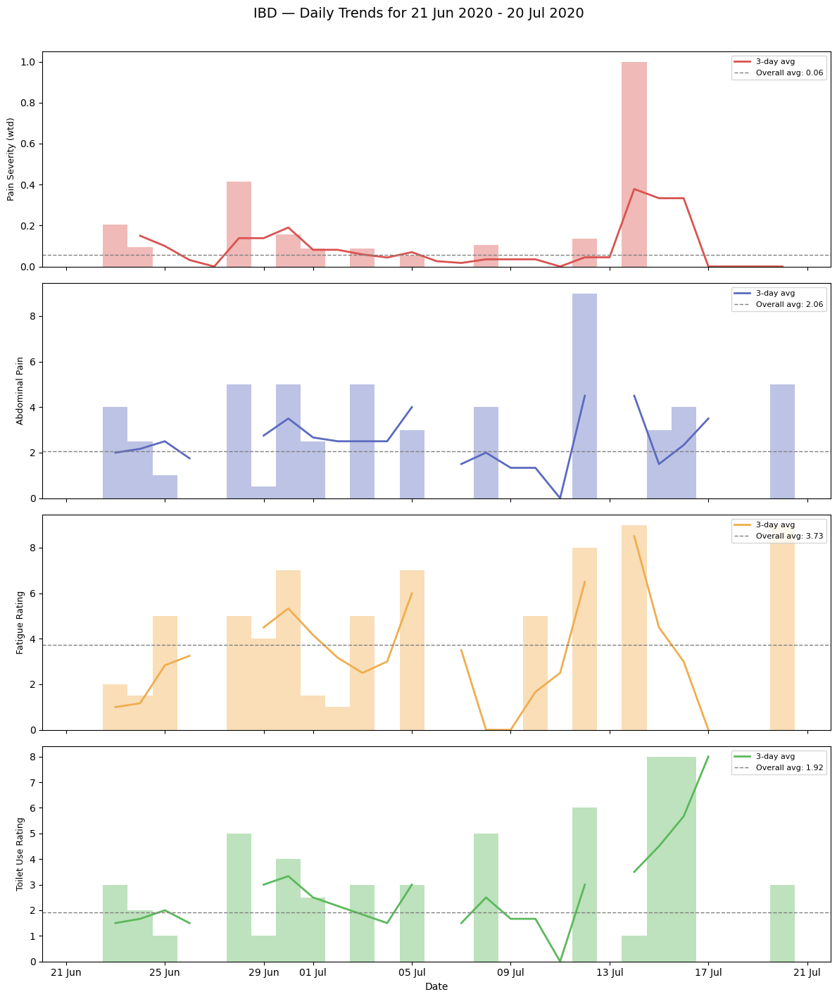

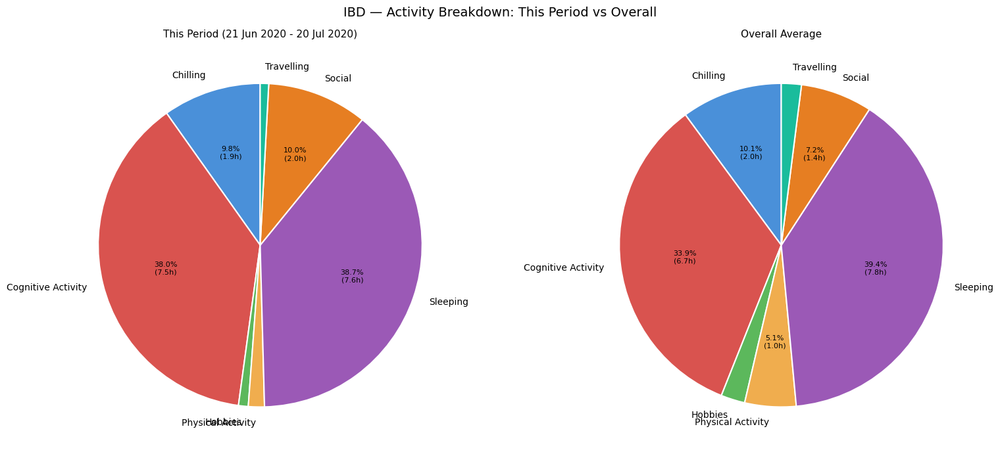

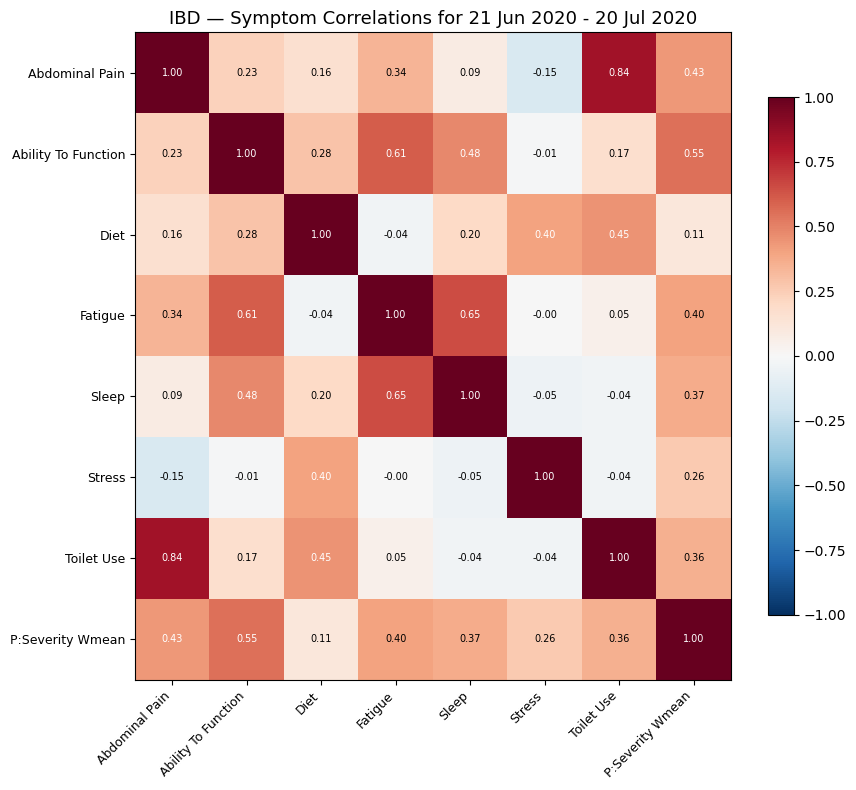


  STRONGEST SYMPTOM CORRELATIONS THIS PERIOD:
    Abdominal Pain       ↔ Toilet Use            ρ=+0.841  (strongly move together)
    Fatigue              ↔ Sleep                 ρ=+0.649  (strongly move together)
    Ability To Function  ↔ Fatigue               ρ=+0.605  (strongly move together)
    Ability To Function  ↔ P:Severity Wmean      ρ=+0.552  (strongly move together)
    Ability To Function  ↔ Sleep                 ρ=+0.482  (moderately move together)

  NOTABLE CHANGES FROM OVERALL PATTERN:
    Ability To Function  ↔ Sleep                 this period=+0.482  overall=+0.228  (stronger this period)
    Abdominal Pain       ↔ Stress                this period=-0.151  overall=+0.221  (weaker this period)
    Stress               ↔ Toilet Use            this period=-0.037  overall=+0.323  (weaker this period)
    Ability To Function  ↔ Stress                this period=-0.011  overall=+0.318  (weaker this period)


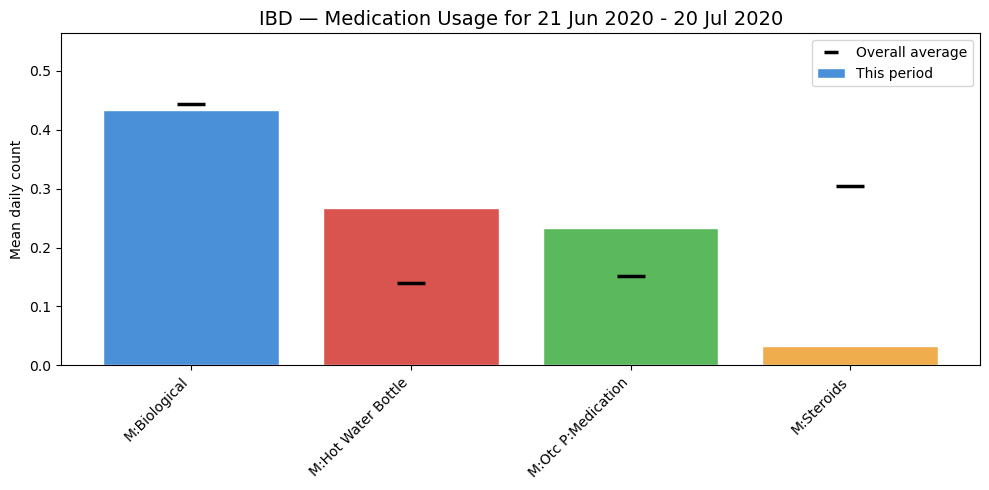


  WHAT YOU TRIED AND WHETHER IT HELPED:
  ──────────────────────────────────────────────────

    M:Biological (used on 12 of 30 days):

    M:Steroids: used on only 1 day(s) — not enough usage data to assess effectiveness yet. Keep logging when you use it.

    M:Otc P:Medication (used on 5 of 30 days):
      Ability To Function    was higher on days you used it (3.0 vs 0.5) — but this likely means you reached for it on worse days, not that it made things worse.
      P:Severity Wmean       was higher on days you used it (0.4 vs 0.0) — but this likely means you reached for it on worse days, not that it made things worse.

    M:Hot Water Bottle (used on 7 of 30 days):
      Abdominal Pain         was higher on days you used it (3.8 vs 2.2) — but this likely means you reached for it on worse days, not that it made things worse.
      P:Severity Wmean       was higher on days you used it (0.2 vs 0.1) — but this likely means you reached for it on worse days, not that it made things wors

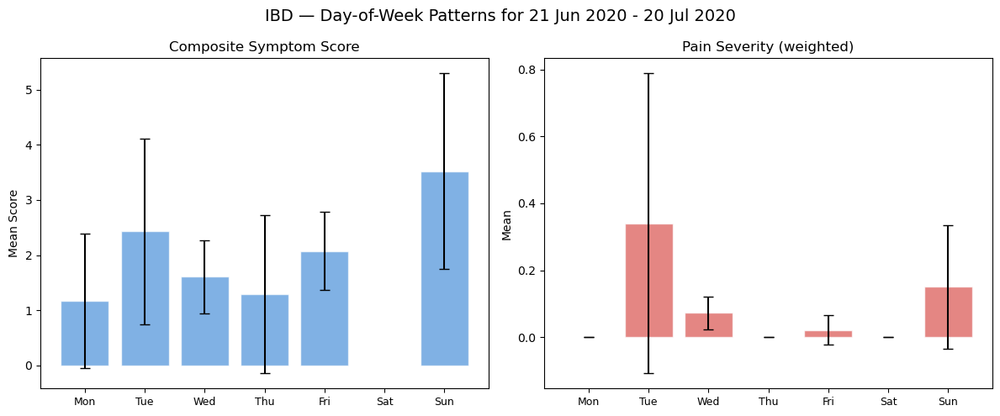

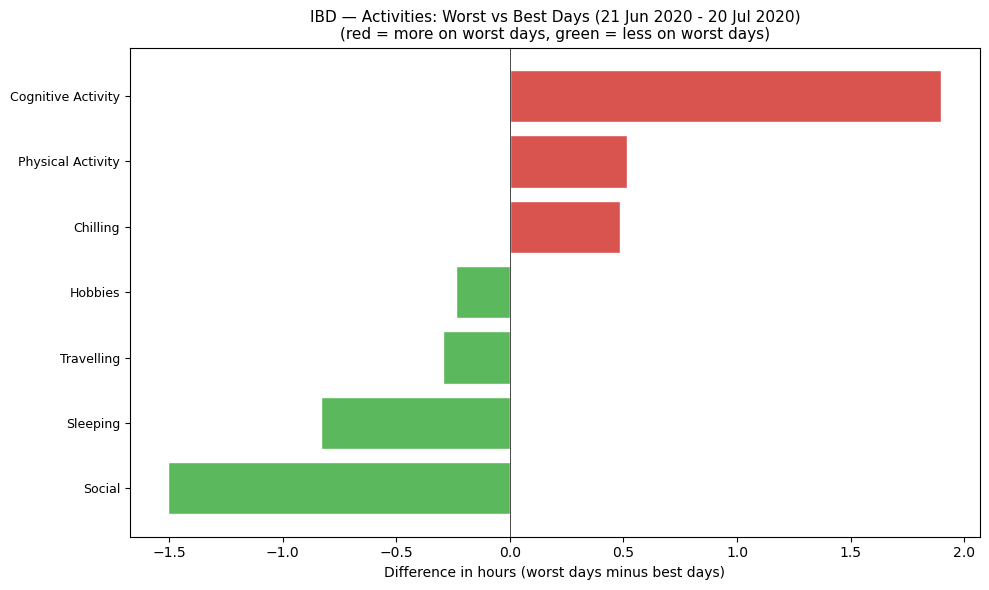


  ACTIVITIES ON WORST vs BEST DAYS:
  Activities associated with HIGHEST symptom scores:
    Cognitive Activity    +1.9h on worst days  p=0.382
    Physical Activity     +0.5h on worst days  p=0.053
    Chilling              +0.5h on worst days  p=0.424
  Activities associated with LOWEST symptom scores:
    Social                -1.5h on worst days  p=0.147
    Sleeping              -0.8h on worst days  p=0.356
    Travelling            -0.3h on worst days  p=0.389
    Hobbies               -0.2h on worst days  p=0.389


C:\Users\cbc15\AppData\Local\Temp\ipykernel_832\633054355.py:562: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = stats.spearmanr(valid["p"], valid["o"])
C:\Users\cbc15\AppData\Local\Temp\ipykernel_832\633054355.py:562: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = stats.spearmanr(valid["p"], valid["o"])
C:\Users\cbc15\AppData\Local\Temp\ipykernel_832\633054355.py:562: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = stats.spearmanr(valid["p"], valid["o"])
C:\Users\cbc15\AppData\Local\Temp\ipykernel_832\633054355.py:562: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = stats.spearmanr(valid["p"], valid["o"])
C:\Users\cbc15\AppData\Local\Temp\ipykernel_832\633054355.py:562: ConstantInputWarning: An input array is constant; the correlation coefficient is not defin

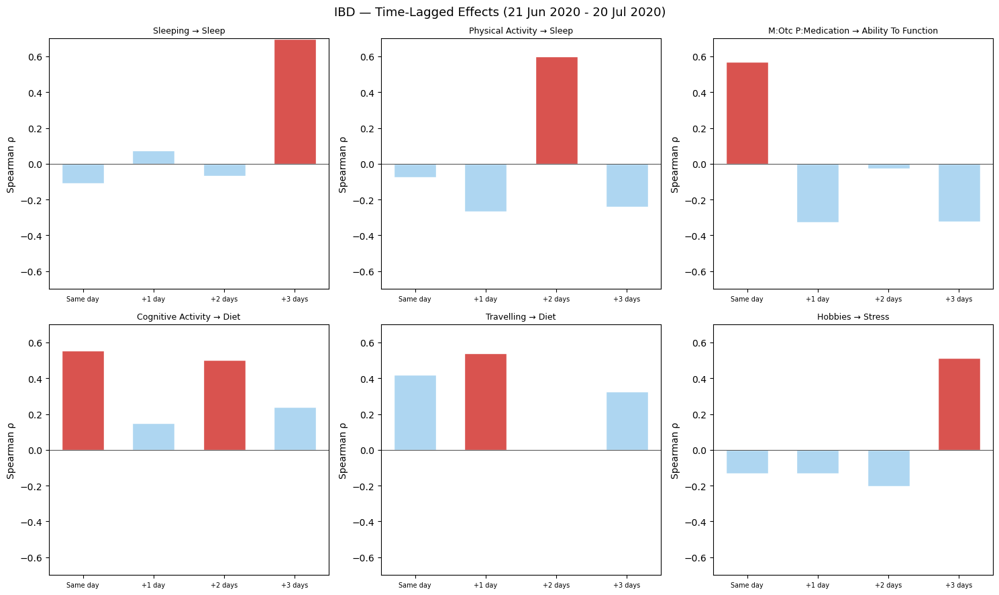


  TIME-LAGGED EFFECTS (strongest associations, p<0.1):
    Sleeping             → Sleep                 ρ=+0.696  after 3 day(s)  (worse) *
    Physical Activity    → Sleep                 ρ=+0.599  after 2 day(s)  (worse) *
    M:Otc P:Medication   → Ability To Function   ρ=+0.570  same-day  (worse) *
    Cognitive Activity   → Diet                  ρ=+0.555  same-day  (worse) *
    Travelling           → Diet                  ρ=+0.539  after 1 day(s)  (worse) *
    Hobbies              → Stress                ρ=+0.514  after 3 day(s)  (worse) *
    Travelling           → Stress                ρ=+0.514  after 3 day(s)  (worse) *
    Hobbies              → Ability To Function   ρ=+0.503  after 3 day(s)  (worse) *
    Travelling           → Ability To Function   ρ=+0.503  after 3 day(s)  (worse) *
    M:Steroids           → Stress                ρ=+0.500  after 2 day(s)  (worse) *
    Cognitive Activity   → Fatigue               ρ=+0.485  same-day  (worse) *
    Travelling           → 

C:\Users\cbc15\AppData\Local\Temp\ipykernel_832\633054355.py:648: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = stats.spearmanr(valid["x"], valid["y"])


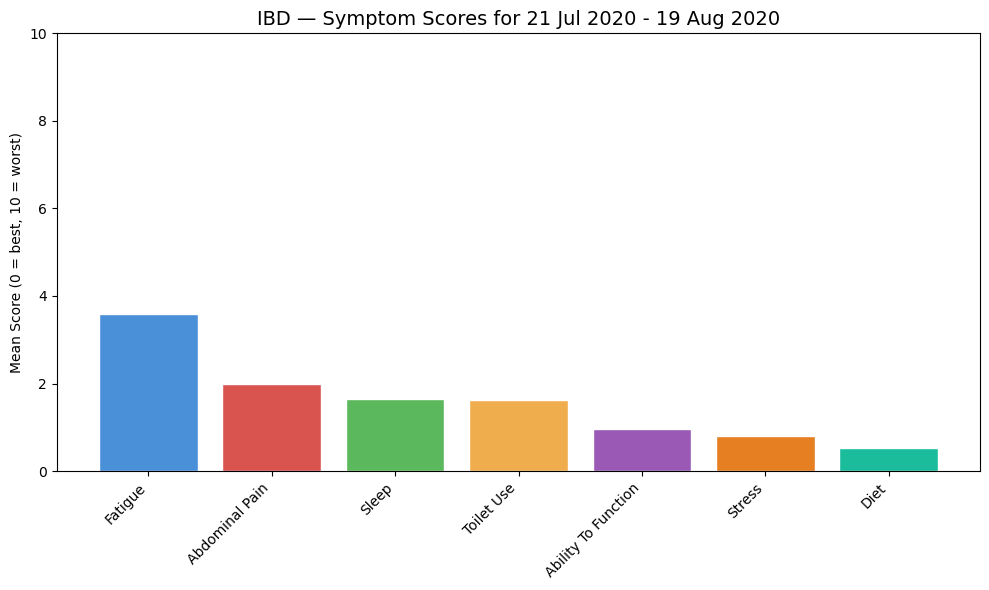

Symptoms with the highest scores in this period were Fatigue (3.6), Abdominal Pain (2.0), and Sleep (1.6).


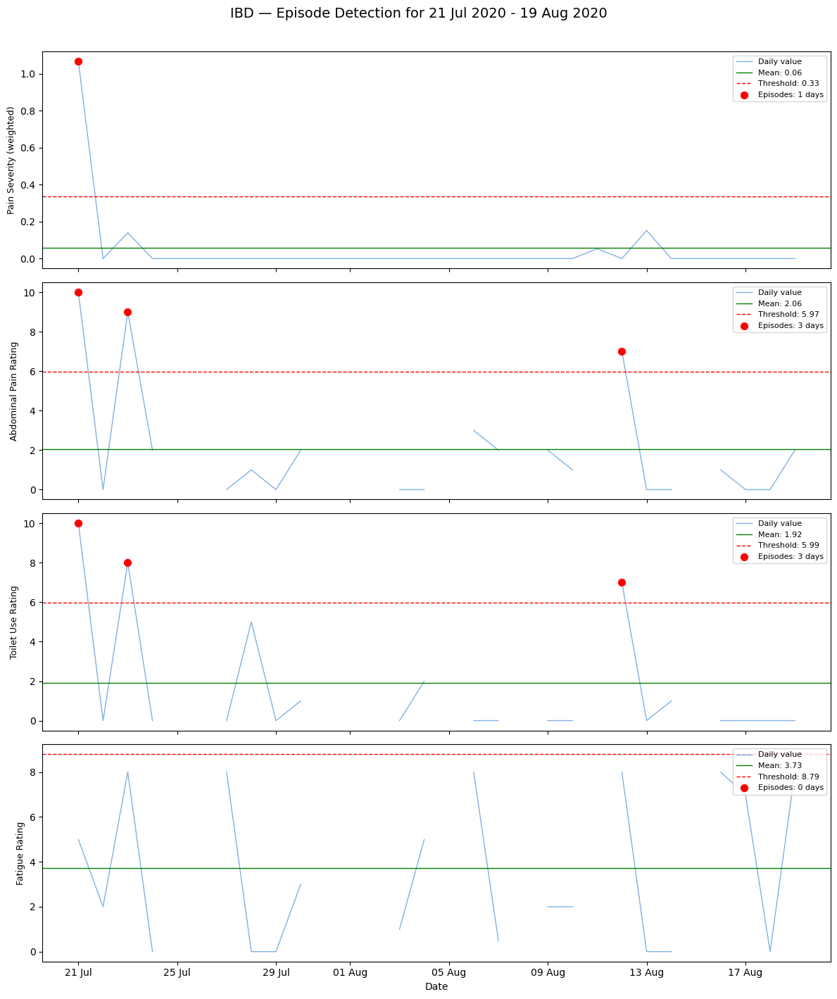

  Total episode days this month: 7

  FLARES OCCURRED ON: 21 Jul (Tuesday), 23 Jul (Thursday), 12 Aug (Wednesday)
Worst day in this period: 23 Jul (composite 7.7/10)
Best day in this period:  29 Jul (composite 0.0/10)


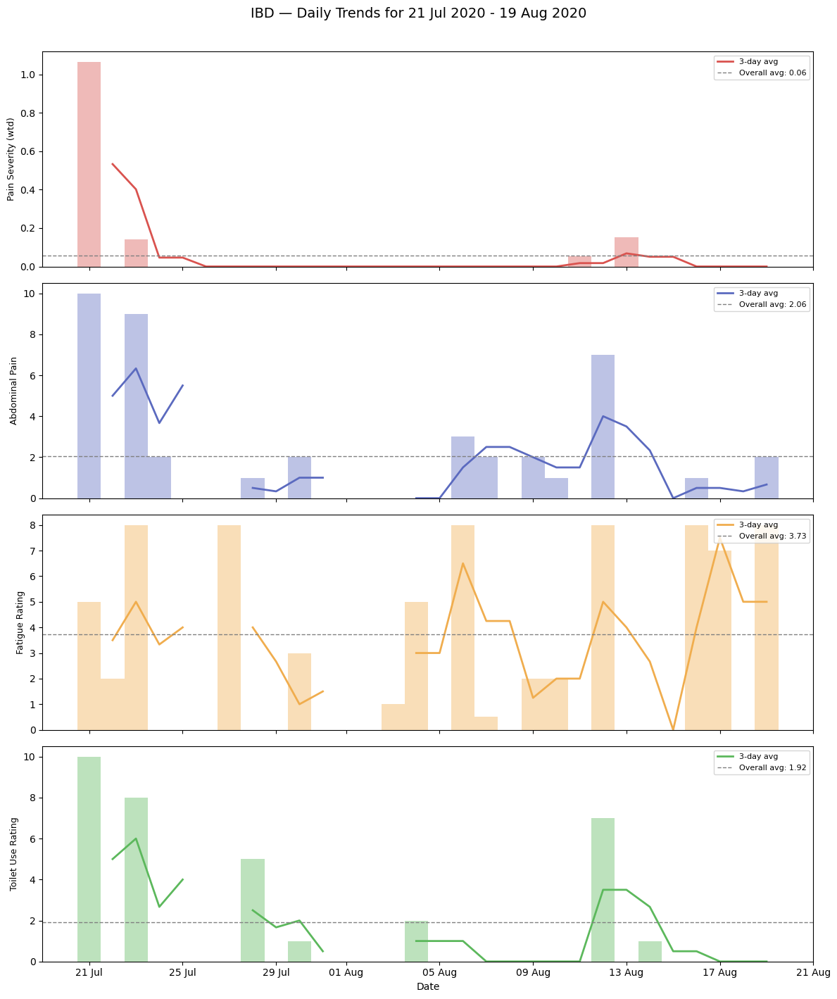

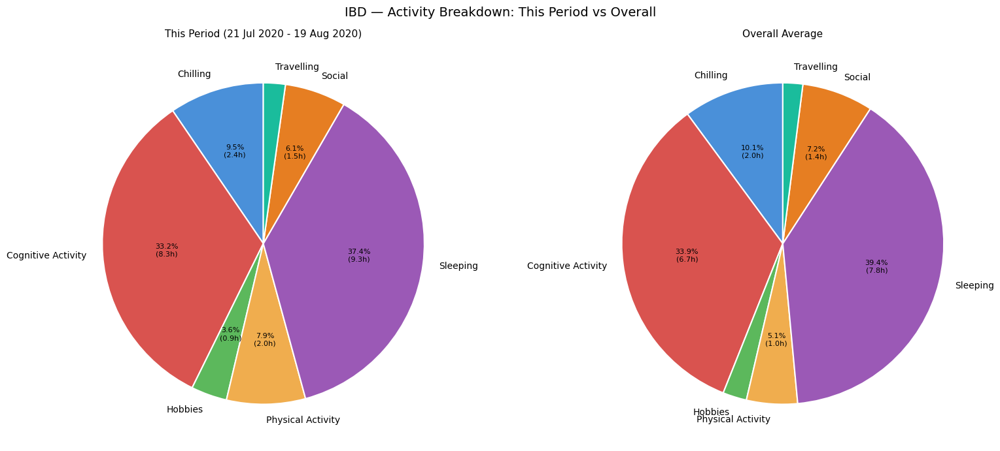

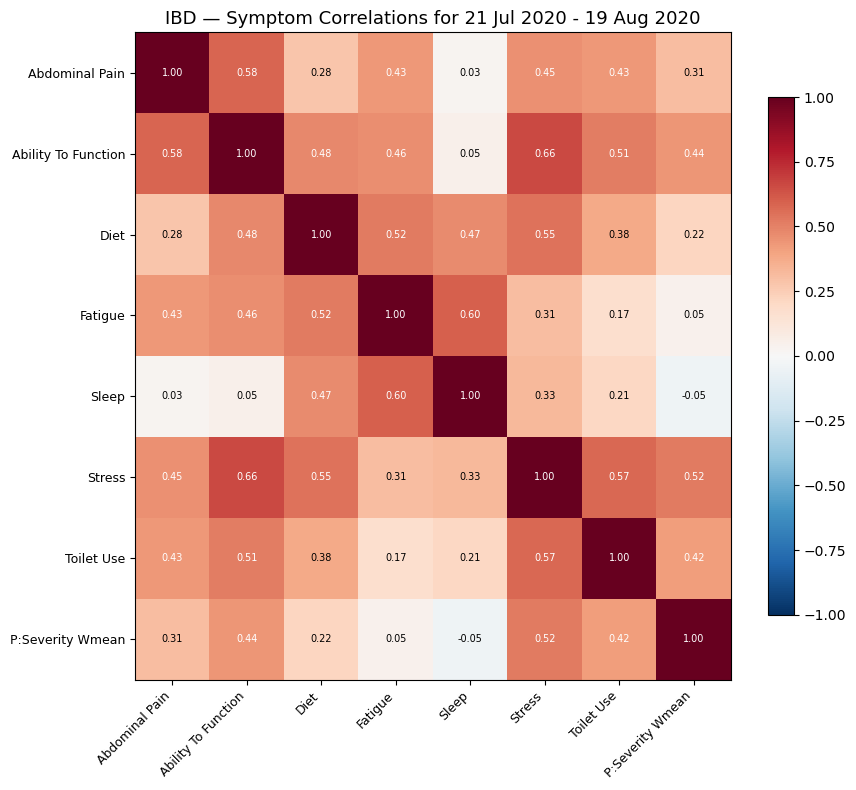


  STRONGEST SYMPTOM CORRELATIONS THIS PERIOD:
    Ability To Function  ↔ Stress                ρ=+0.664  (strongly move together)
    Fatigue              ↔ Sleep                 ρ=+0.595  (strongly move together)
    Abdominal Pain       ↔ Ability To Function   ρ=+0.582  (strongly move together)
    Stress               ↔ Toilet Use            ρ=+0.573  (strongly move together)
    Diet                 ↔ Stress                ρ=+0.546  (strongly move together)

  NOTABLE CHANGES FROM OVERALL PATTERN:
    Ability To Function  ↔ Stress                this period=+0.664  overall=+0.318  (stronger this period)
    Stress               ↔ P:Severity Wmean      this period=+0.518  overall=+0.241  (stronger this period)
    Diet                 ↔ Fatigue               this period=+0.517  overall=+0.169  (stronger this period)
    Abdominal Pain       ↔ Toilet Use            this period=+0.433  overall=+0.773  (weaker this period)
    Sleep                ↔ Stress                this period=+

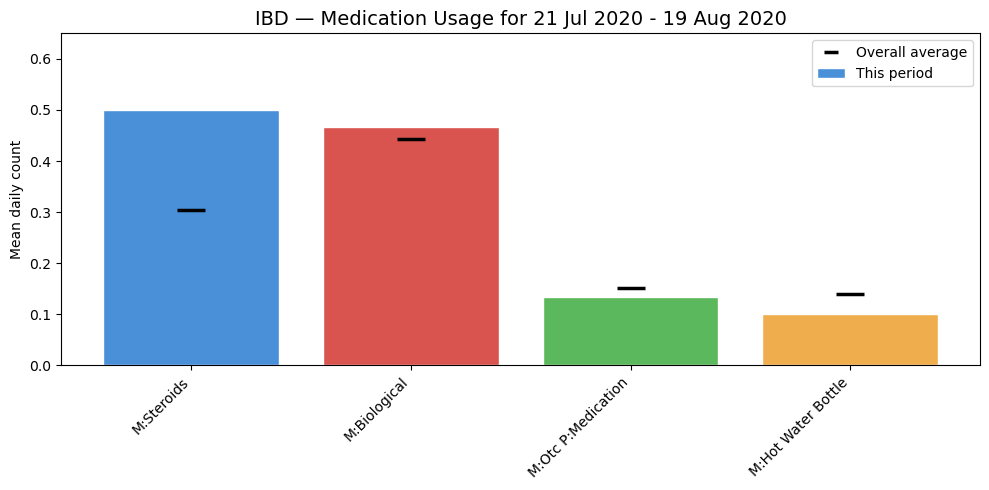


  WHAT YOU TRIED AND WHETHER IT HELPED:
  ──────────────────────────────────────────────────

    M:Biological (used on 14 of 30 days):
      Ability To Function    was higher on days you used it (1.4 vs 0.0) — but this likely means you reached for it on worse days, not that it made things worse.

    M:Steroids (used on 15 of 30 days):
      Next-day Ability To Function was better after using it (0.0 vs 1.6) — suggests a delayed benefit.
      Next-day Diet               was better after using it (0.0 vs 1.2) — suggests a delayed benefit.

    M:Otc P:Medication (used on 4 of 30 days):
      Abdominal Pain         was higher on days you used it (6.8 vs 0.9) — but this likely means you reached for it on worse days, not that it made things worse.
      Ability To Function    was higher on days you used it (4.5 vs 0.1) — but this likely means you reached for it on worse days, not that it made things worse.
      Diet                   was higher on days you used it (2.5 vs 0.1) — but th

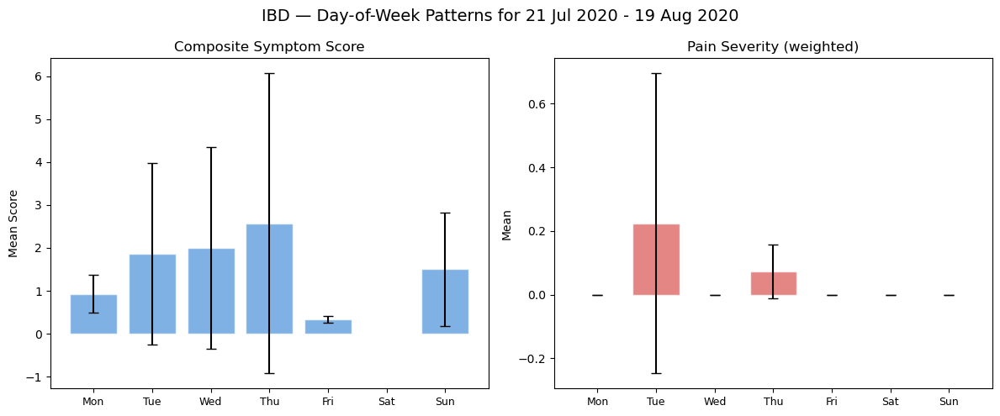

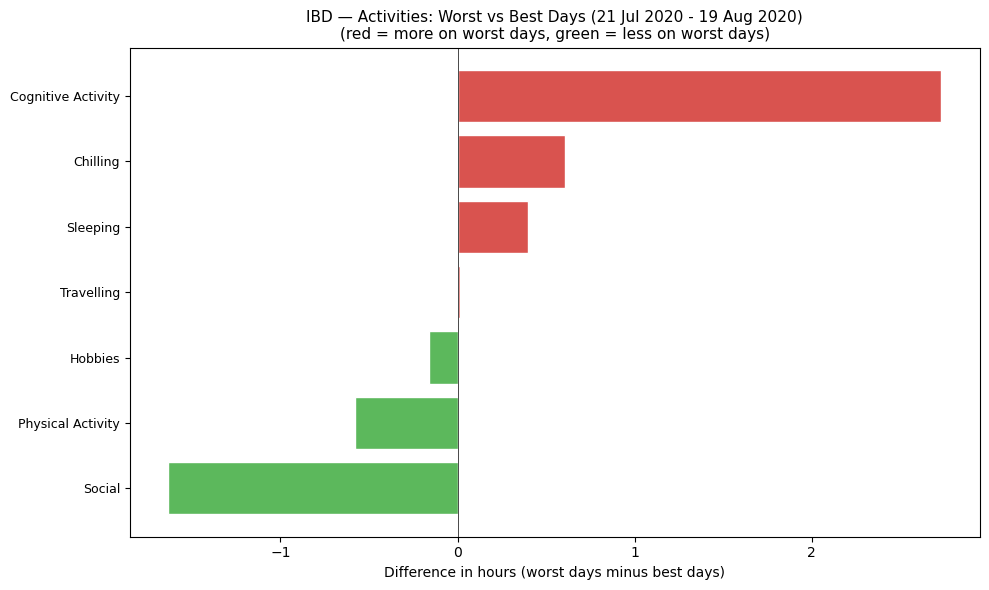


  ACTIVITIES ON WORST vs BEST DAYS:
  Activities associated with HIGHEST symptom scores:
    Cognitive Activity    +2.7h on worst days  p=0.405
    Chilling              +0.6h on worst days  p=0.405
    Sleeping              +0.4h on worst days  p=0.616
  Activities associated with LOWEST symptom scores:
    Social                -1.6h on worst days  p=0.189
    Physical Activity     -0.6h on worst days  p=0.188
    Hobbies               -0.2h on worst days  p=0.821


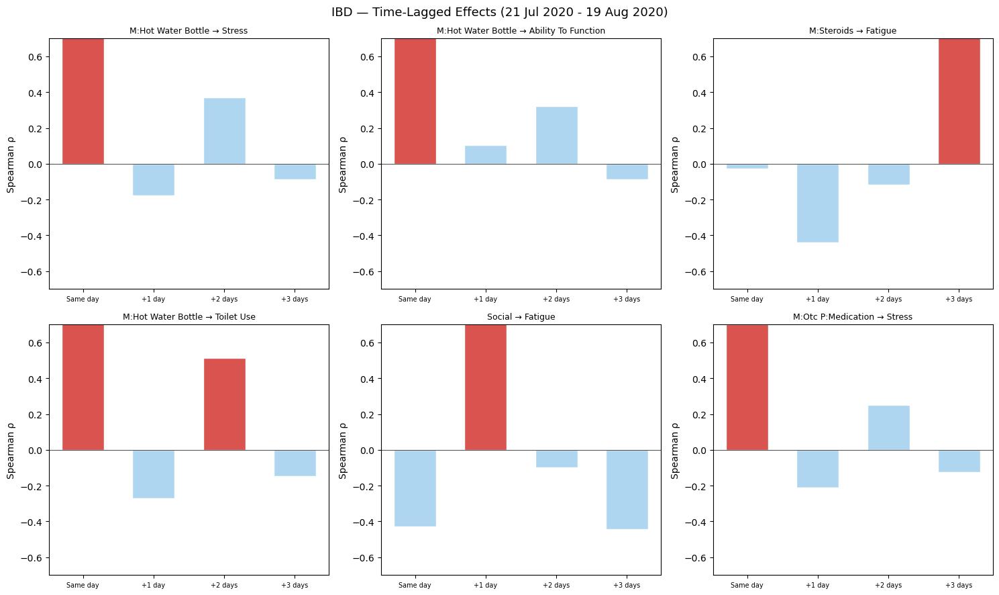


  TIME-LAGGED EFFECTS (strongest associations, p<0.1):
    M:Hot Water Bottle   → Stress                ρ=+0.855  same-day  (worse) *
    M:Hot Water Bottle   → Ability To Function   ρ=+0.812  same-day  (worse) *
    M:Steroids           → Fatigue               ρ=+0.772  after 3 day(s)  (worse) *
    M:Hot Water Bottle   → Toilet Use            ρ=+0.723  same-day  (worse) *
    Social               → Fatigue               ρ=+0.715  after 1 day(s)  (worse) *
    M:Otc P:Medication   → Stress                ρ=+0.703  same-day  (worse) *
    M:Otc P:Medication   → Ability To Function   ρ=+0.657  same-day  (worse) *
    Physical Activity    → Toilet Use            ρ=+0.647  after 1 day(s)  (worse) *
    M:Hot Water Bottle   → Abdominal Pain        ρ=+0.637  same-day  (worse) *
    M:Hot Water Bottle   → Diet                  ρ=+0.628  same-day  (worse) *
    Social               → Diet                  ρ=+0.595  after 1 day(s)  (worse) *
    M:Otc P:Medication   → Abdominal Pain        ρ=

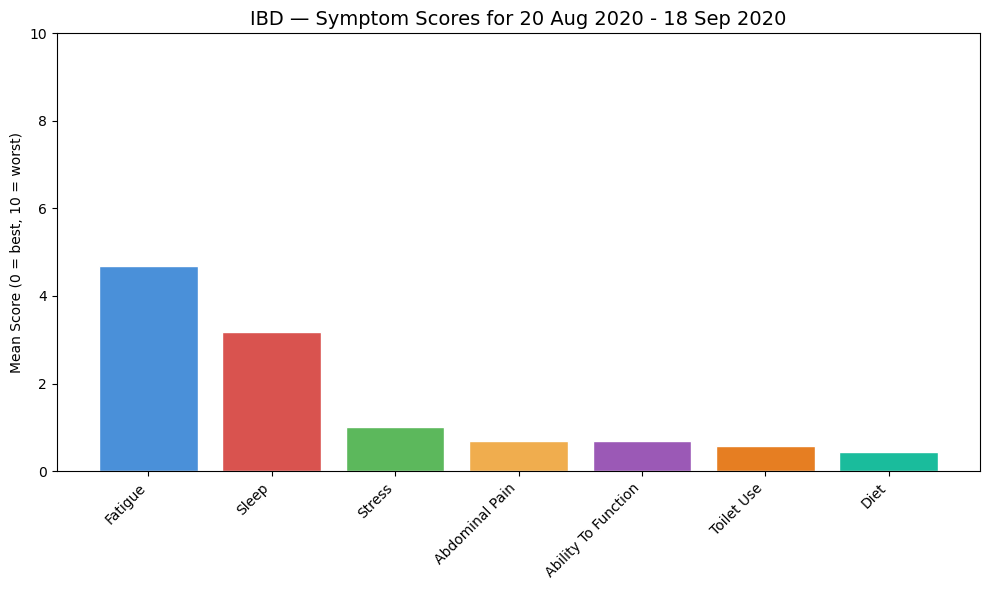

Symptoms with the highest scores in this period were Fatigue (4.7), Sleep (3.2), and Stress (1.0).

  Episode detection skipped — not enough data this period.


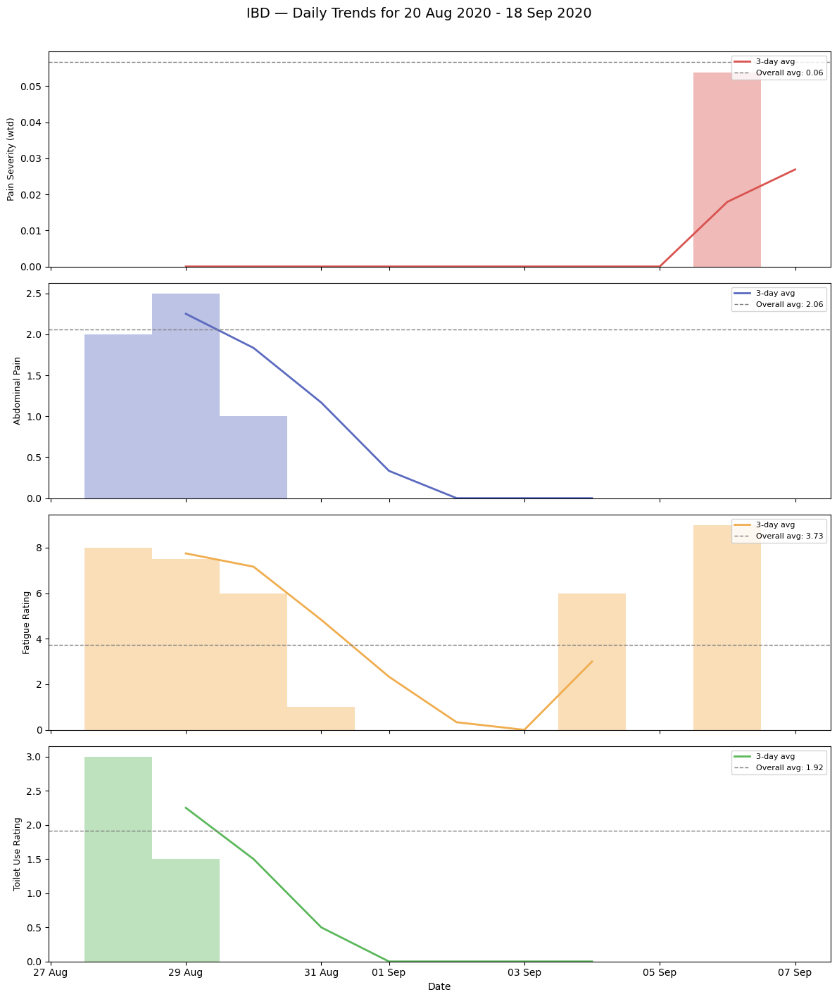

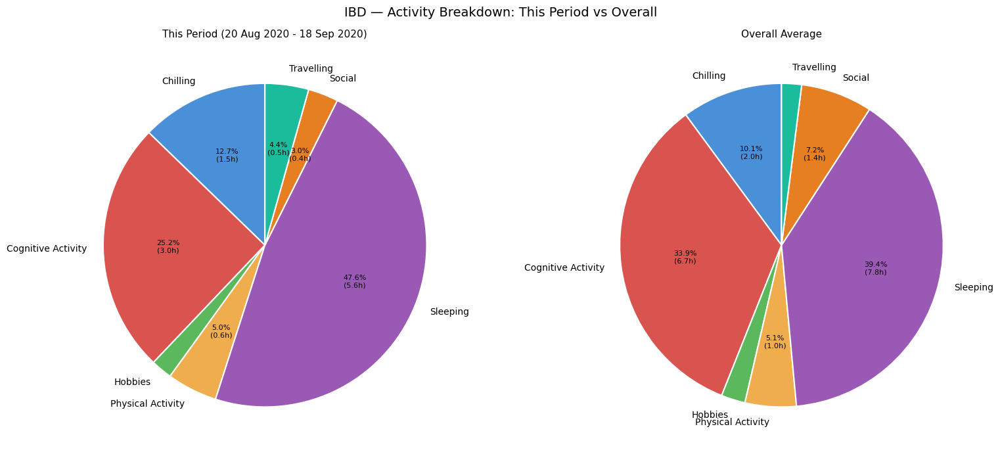

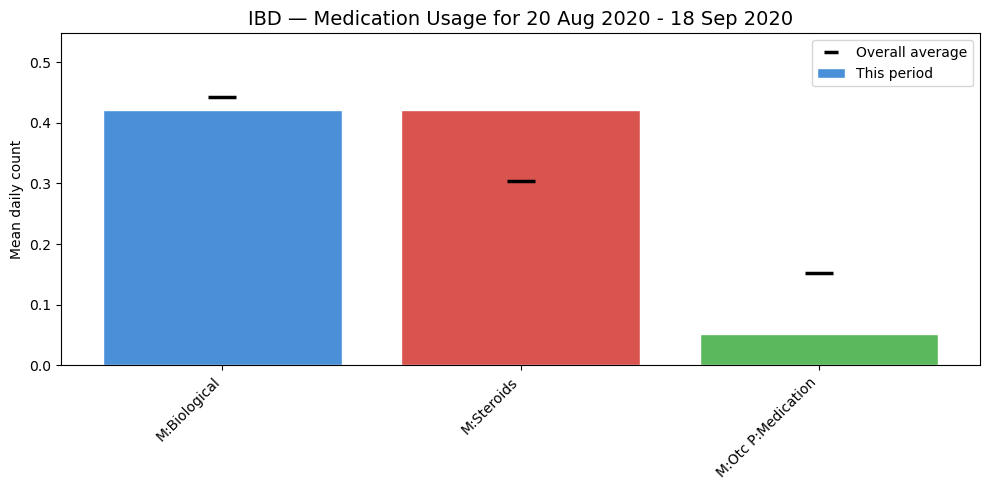


  WHAT YOU TRIED AND WHETHER IT HELPED:
  ──────────────────────────────────────────────────

    M:Biological (used on 8 of 19 days):

    M:Steroids (used on 8 of 19 days):

    M:Otc P:Medication: used on only 1 day(s) — not enough usage data to assess effectiveness yet. Keep logging when you use it.

  WHAT YOUR NOTES TELL US:
  ──────────────────────────────────────────────────
    You wrote 13 notes this period.
    • Mentioned 'fatigue' on 2 day(s)
    • Mentioned 'good day' on 2 day(s)
    • Mentioned 'abdominal pain' on 1 day(s)


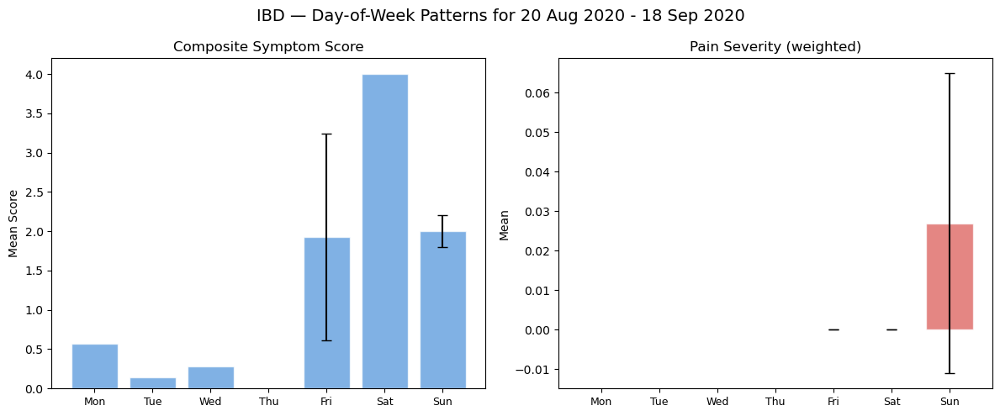


  Insufficient worst/best days for activity comparison (worst=0, best=9)

  Insufficient data for lag analysis in this period

  TRIGGERS OF PAIN SEVERITY (WEIGHTED):
    No significant triggers identified in this period

  RELIEVERS:
    No significant relievers identified in this period

  APPEARED TO HAVE NO SIGNIFICANT EFFECT ON SYMPTOMS:
    Cognitive Activity, Hobbies, Sleeping, M:Biological, M:Steroids, M:Otc P:Medication
    (all p>0.3)

  WITH REGARD TO PAIN SEVERITY (WEIGHTED):
    Travelling appeared to have most effect in exacerbation (ρ=+0.574, p=0.0829)

  COMPARED TO PREVIOUS 30-DAY WINDOW (21 Jul – 19 Aug):
    Abdominal Pain             prev=2.00  now=0.69  (-1.31, better)
    Ability To Function        prev=0.95  now=0.69  (-0.26, better)
    Diet                       prev=0.52  now=0.44  (-0.09, better)
    Fatigue                    prev=3.60  now=4.69  (+1.09, worse)
    Sleep                      prev=1.64  now=3.19  (+1.54, worse)
    Stress                    

C:\Users\cbc15\AppData\Local\Temp\ipykernel_832\633054355.py:648: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = stats.spearmanr(valid["x"], valid["y"])


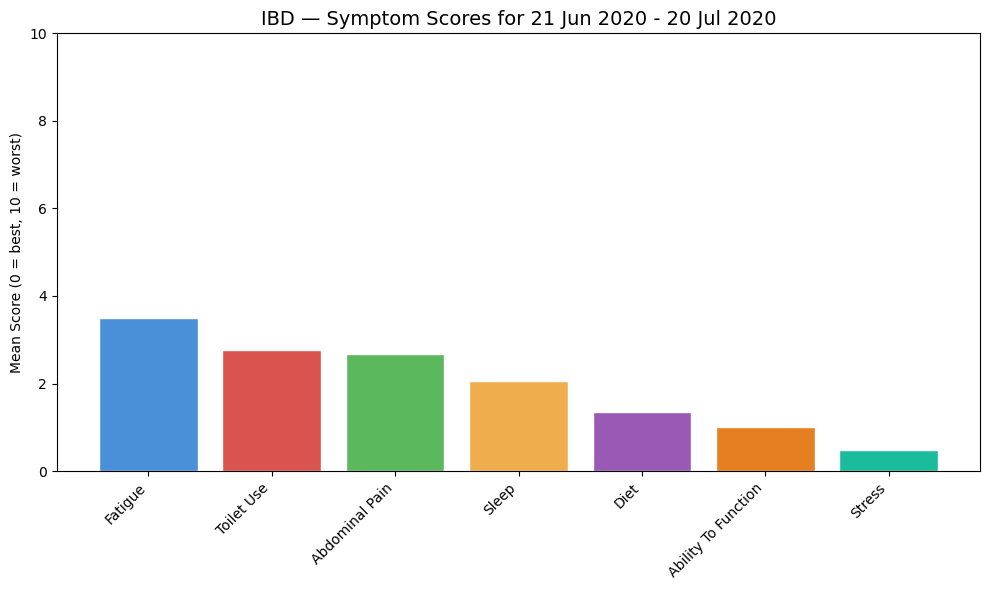

Symptoms with the highest scores in this period were Fatigue (3.5), Toilet Use (2.8), and Abdominal Pain (2.7).


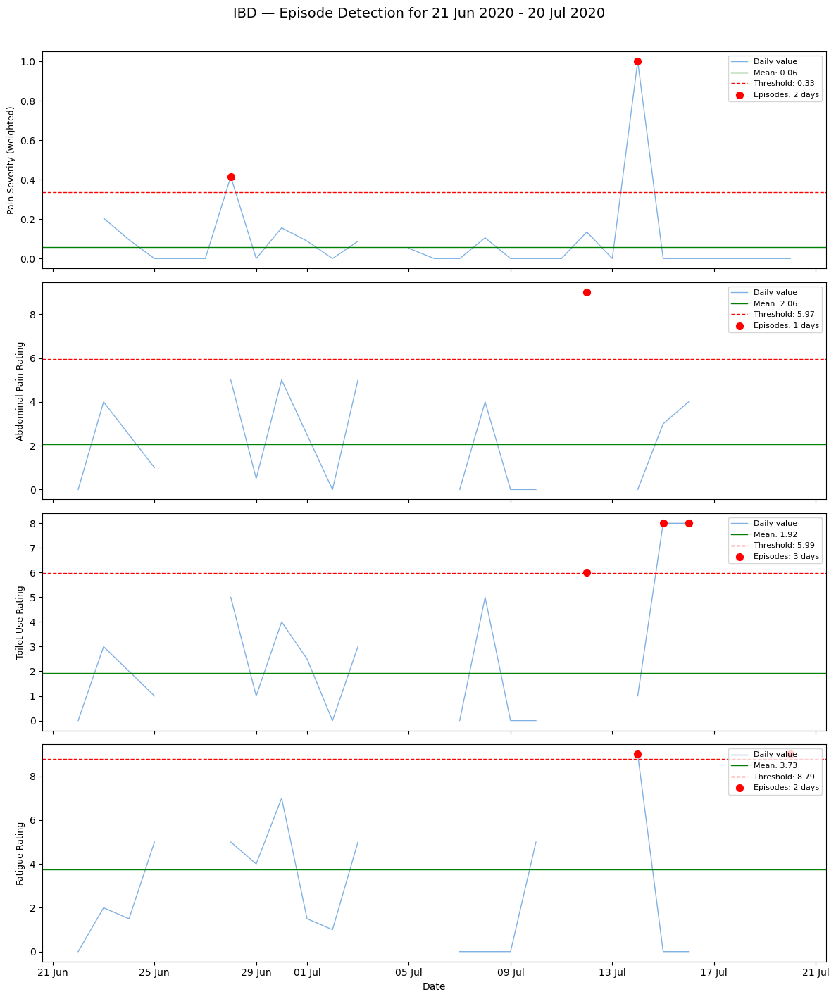

  Total episode days this month: 8

  FLARES OCCURRED ON: 28 Jun (Sunday), 12 Jul (Sunday), 14 Jul (Tuesday), 15 Jul (Wednesday), 16 Jul (Thursday), 20 Jul (Monday)
Worst day in this period: 12 Jul (composite 5.6/10)
Best day in this period:  22 Jun (composite 0.0/10)


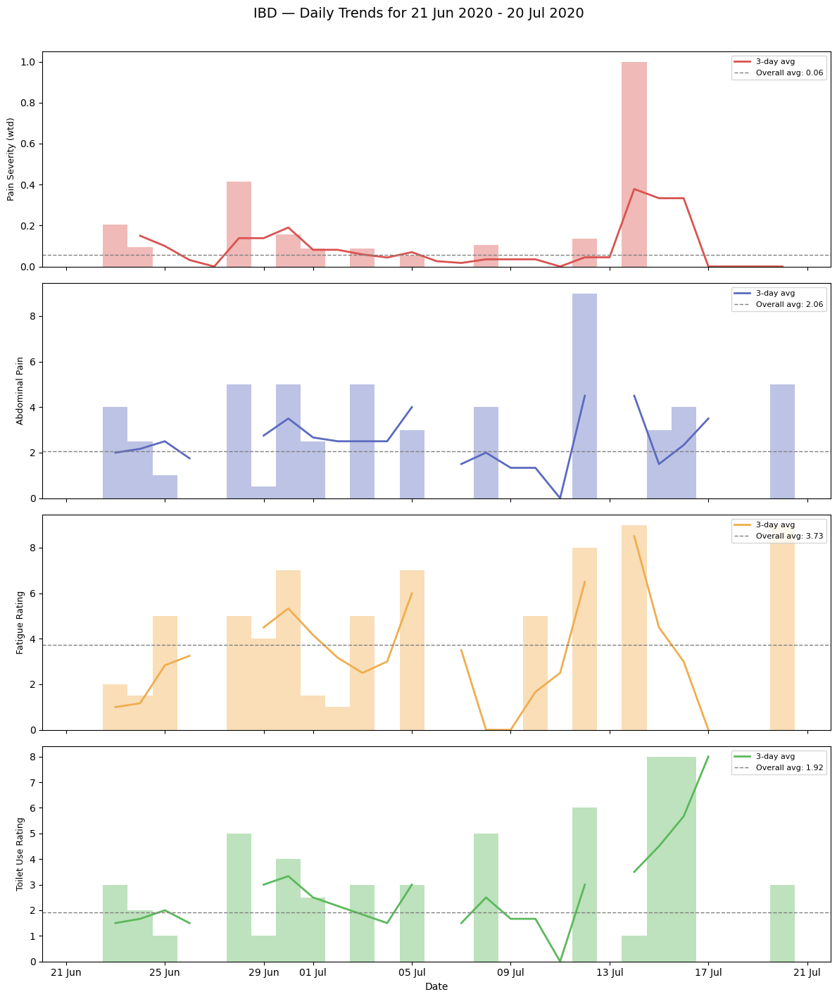

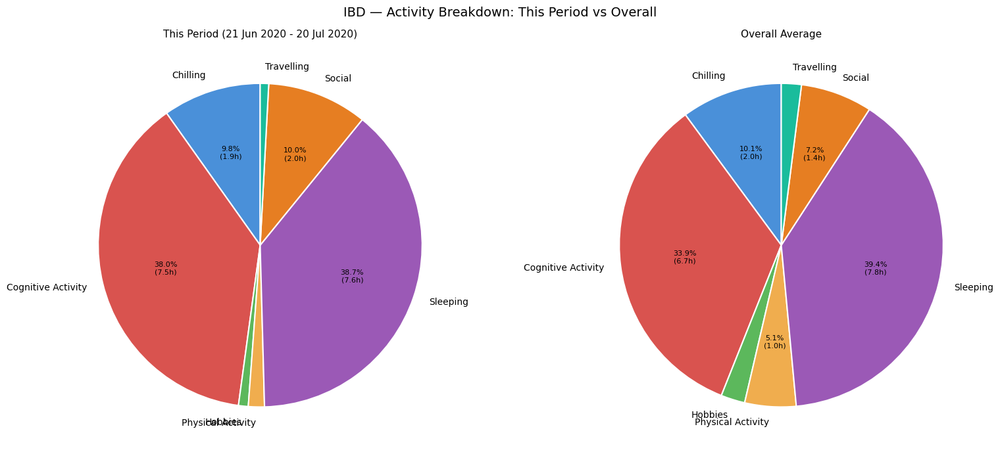

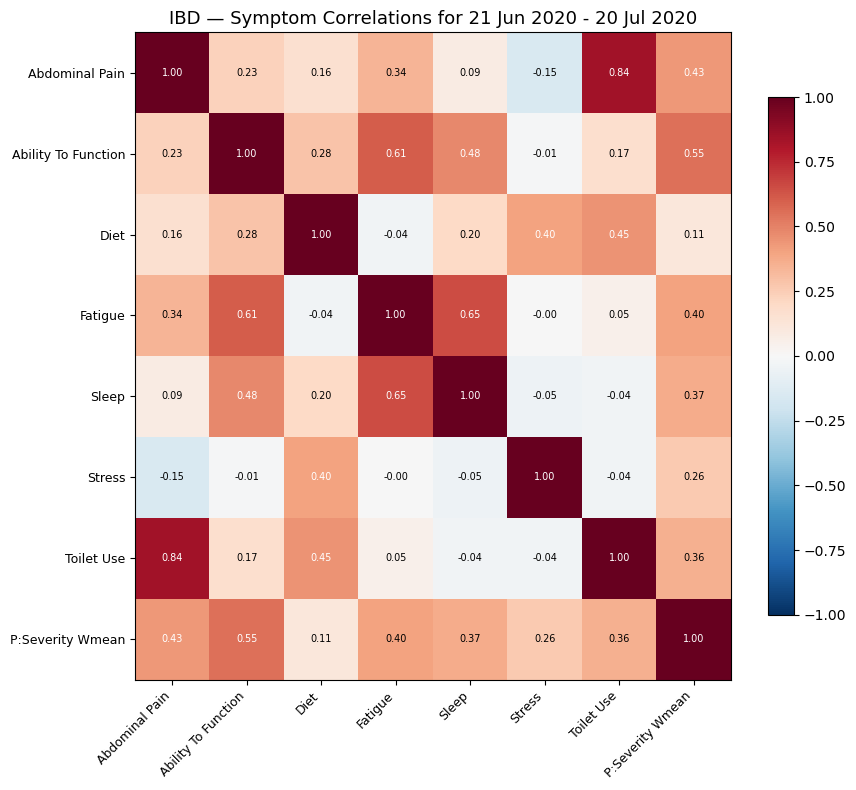


  STRONGEST SYMPTOM CORRELATIONS THIS PERIOD:
    Abdominal Pain       ↔ Toilet Use            ρ=+0.841  (strongly move together)
    Fatigue              ↔ Sleep                 ρ=+0.649  (strongly move together)
    Ability To Function  ↔ Fatigue               ρ=+0.605  (strongly move together)
    Ability To Function  ↔ P:Severity Wmean      ρ=+0.552  (strongly move together)
    Ability To Function  ↔ Sleep                 ρ=+0.482  (moderately move together)

  NOTABLE CHANGES FROM OVERALL PATTERN:
    Ability To Function  ↔ Sleep                 this period=+0.482  overall=+0.228  (stronger this period)
    Abdominal Pain       ↔ Stress                this period=-0.151  overall=+0.221  (weaker this period)
    Stress               ↔ Toilet Use            this period=-0.037  overall=+0.323  (weaker this period)
    Ability To Function  ↔ Stress                this period=-0.011  overall=+0.318  (weaker this period)


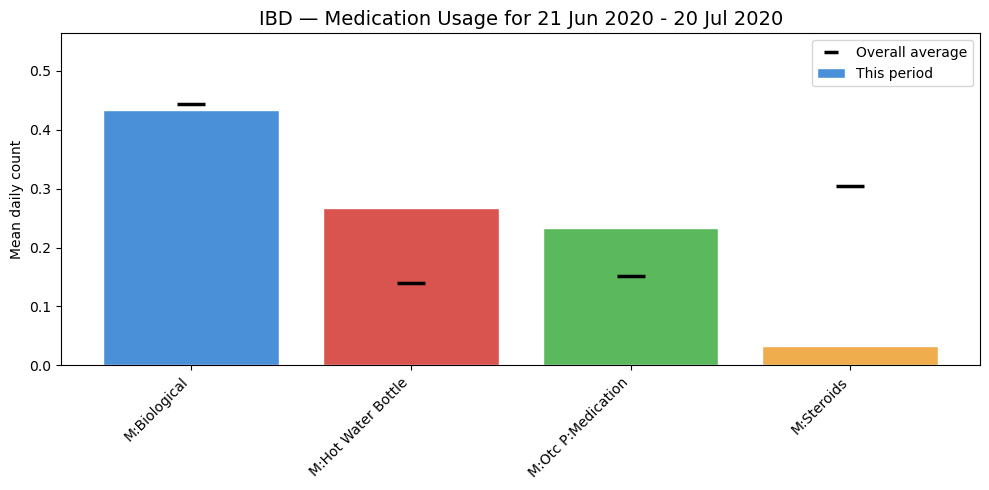


  WHAT YOU TRIED AND WHETHER IT HELPED:
  ──────────────────────────────────────────────────

    M:Biological (used on 12 of 30 days):

    M:Steroids: used on only 1 day(s) — not enough usage data to assess effectiveness yet. Keep logging when you use it.

    M:Otc P:Medication (used on 5 of 30 days):
      Ability To Function    was higher on days you used it (3.0 vs 0.5) — but this likely means you reached for it on worse days, not that it made things worse.
      P:Severity Wmean       was higher on days you used it (0.4 vs 0.0) — but this likely means you reached for it on worse days, not that it made things worse.

    M:Hot Water Bottle (used on 7 of 30 days):
      Abdominal Pain         was higher on days you used it (3.8 vs 2.2) — but this likely means you reached for it on worse days, not that it made things worse.
      P:Severity Wmean       was higher on days you used it (0.2 vs 0.1) — but this likely means you reached for it on worse days, not that it made things wors

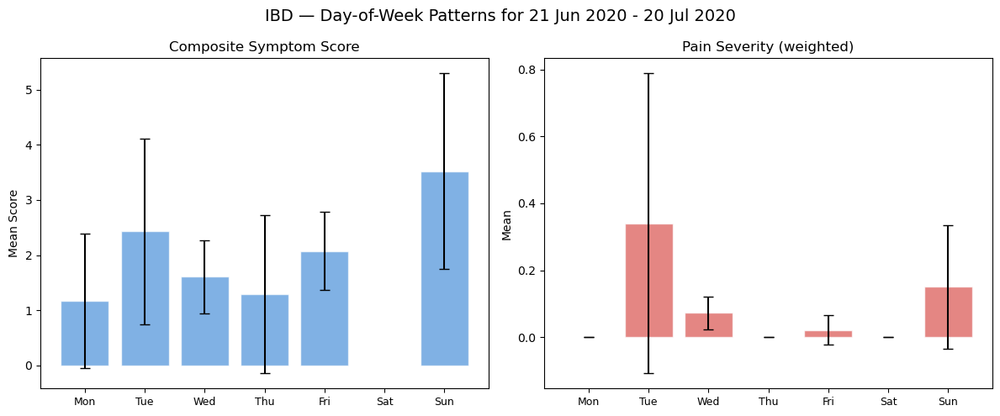

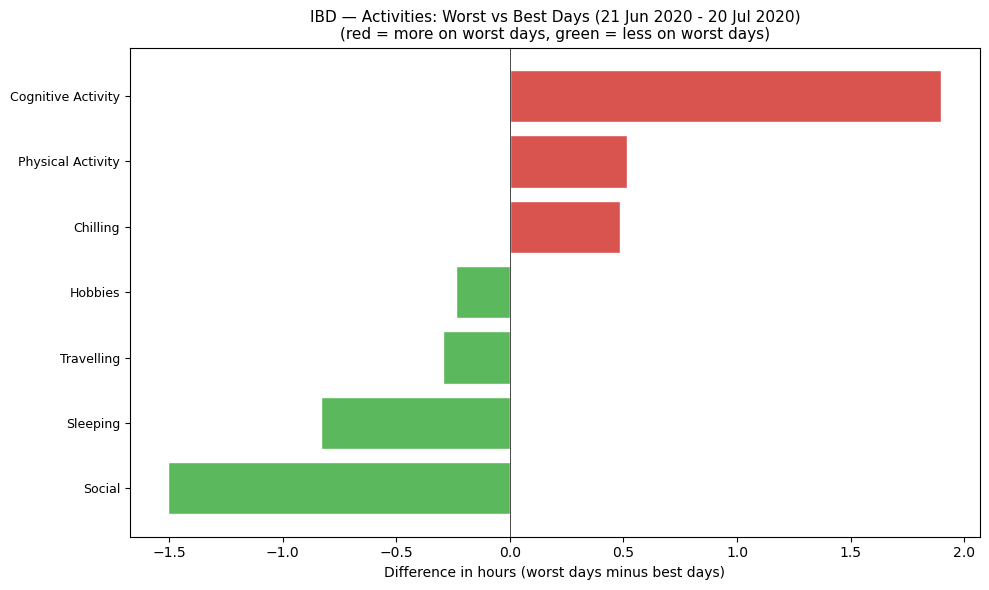


  ACTIVITIES ON WORST vs BEST DAYS:
  Activities associated with HIGHEST symptom scores:
    Cognitive Activity    +1.9h on worst days  p=0.382
    Physical Activity     +0.5h on worst days  p=0.053
    Chilling              +0.5h on worst days  p=0.424
  Activities associated with LOWEST symptom scores:
    Social                -1.5h on worst days  p=0.147
    Sleeping              -0.8h on worst days  p=0.356
    Travelling            -0.3h on worst days  p=0.389
    Hobbies               -0.2h on worst days  p=0.389


C:\Users\cbc15\AppData\Local\Temp\ipykernel_832\633054355.py:562: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = stats.spearmanr(valid["p"], valid["o"])
C:\Users\cbc15\AppData\Local\Temp\ipykernel_832\633054355.py:562: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = stats.spearmanr(valid["p"], valid["o"])
C:\Users\cbc15\AppData\Local\Temp\ipykernel_832\633054355.py:562: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = stats.spearmanr(valid["p"], valid["o"])
C:\Users\cbc15\AppData\Local\Temp\ipykernel_832\633054355.py:562: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = stats.spearmanr(valid["p"], valid["o"])
C:\Users\cbc15\AppData\Local\Temp\ipykernel_832\633054355.py:562: ConstantInputWarning: An input array is constant; the correlation coefficient is not defin

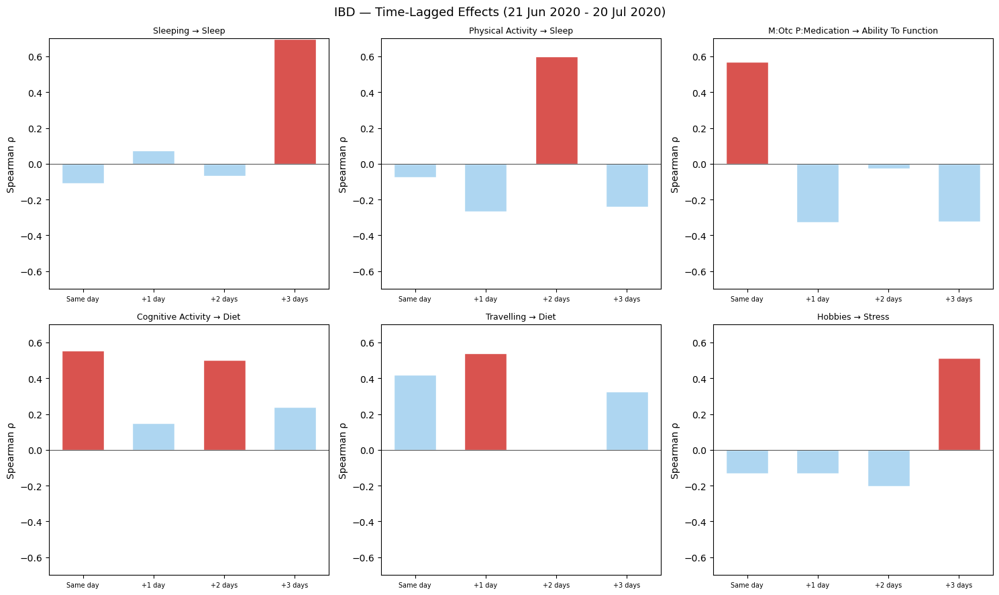


  TIME-LAGGED EFFECTS (strongest associations, p<0.1):
    Sleeping             → Sleep                 ρ=+0.696  after 3 day(s)  (worse) *
    Physical Activity    → Sleep                 ρ=+0.599  after 2 day(s)  (worse) *
    M:Otc P:Medication   → Ability To Function   ρ=+0.570  same-day  (worse) *
    Cognitive Activity   → Diet                  ρ=+0.555  same-day  (worse) *
    Travelling           → Diet                  ρ=+0.539  after 1 day(s)  (worse) *
    Hobbies              → Stress                ρ=+0.514  after 3 day(s)  (worse) *
    Travelling           → Stress                ρ=+0.514  after 3 day(s)  (worse) *
    Hobbies              → Ability To Function   ρ=+0.503  after 3 day(s)  (worse) *
    Travelling           → Ability To Function   ρ=+0.503  after 3 day(s)  (worse) *
    M:Steroids           → Stress                ρ=+0.500  after 2 day(s)  (worse) *
    Cognitive Activity   → Fatigue               ρ=+0.485  same-day  (worse) *
    Travelling           → 

C:\Users\cbc15\AppData\Local\Temp\ipykernel_832\633054355.py:648: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = stats.spearmanr(valid["x"], valid["y"])


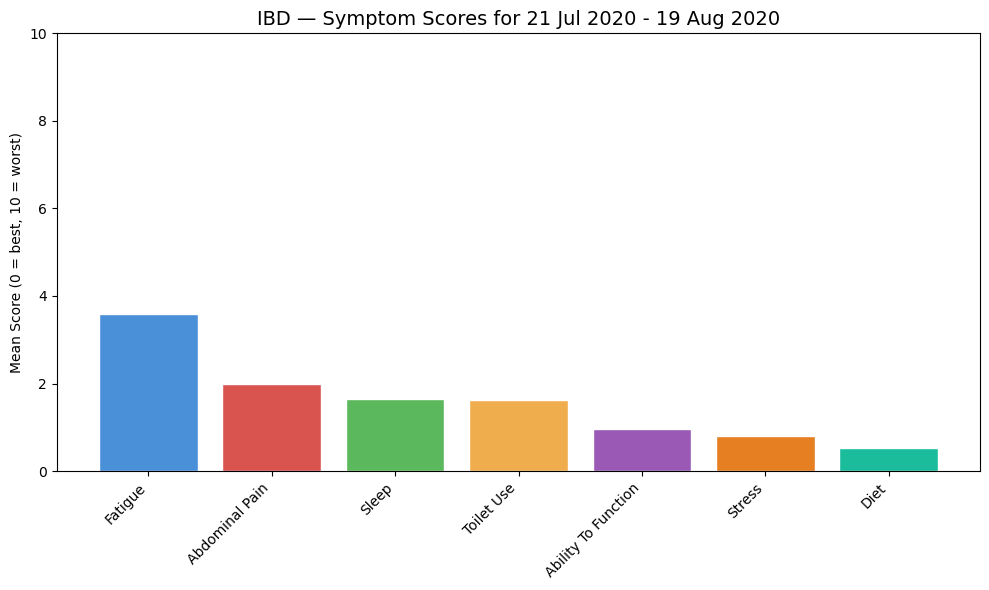

Symptoms with the highest scores in this period were Fatigue (3.6), Abdominal Pain (2.0), and Sleep (1.6).


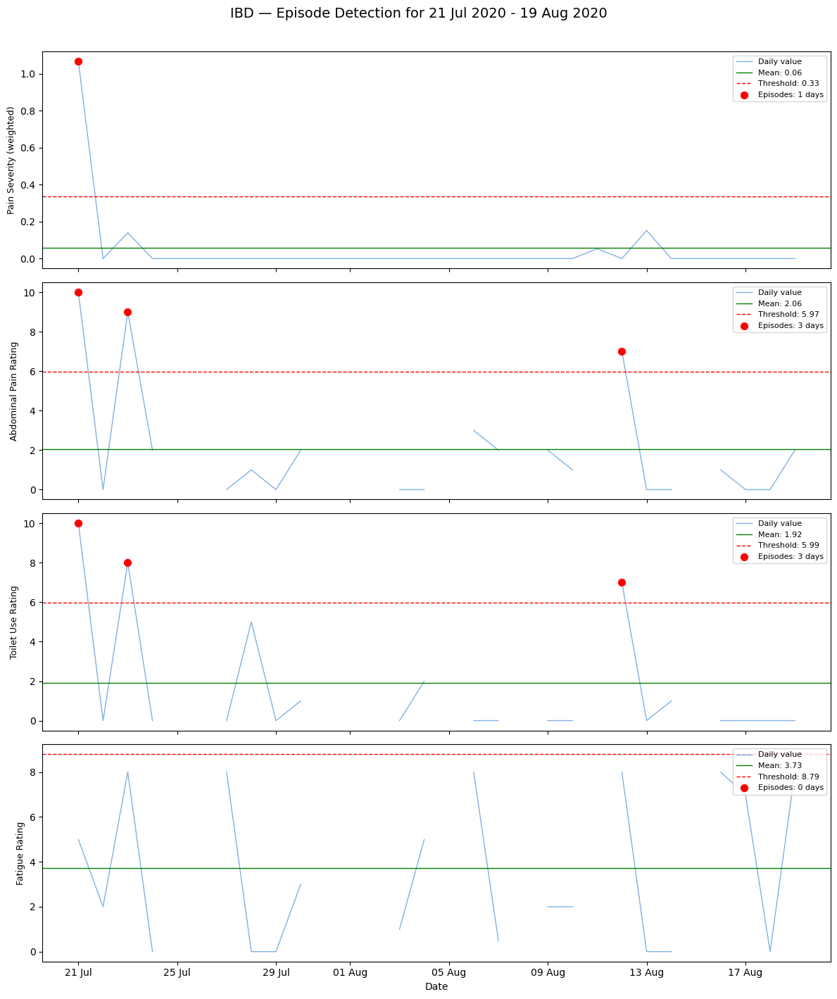

  Total episode days this month: 7

  FLARES OCCURRED ON: 21 Jul (Tuesday), 23 Jul (Thursday), 12 Aug (Wednesday)
Worst day in this period: 23 Jul (composite 7.7/10)
Best day in this period:  29 Jul (composite 0.0/10)


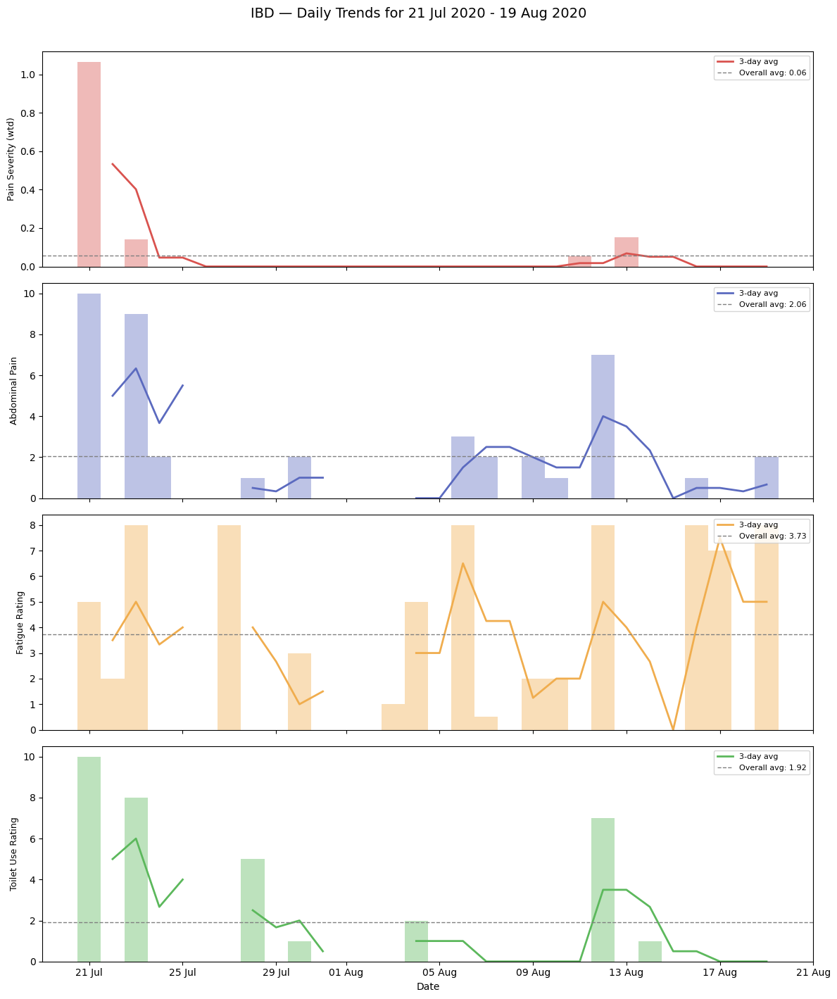

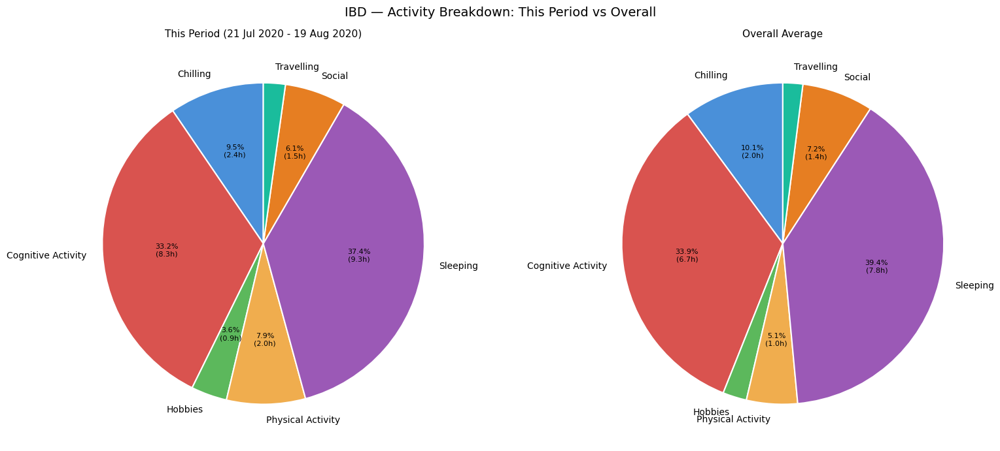

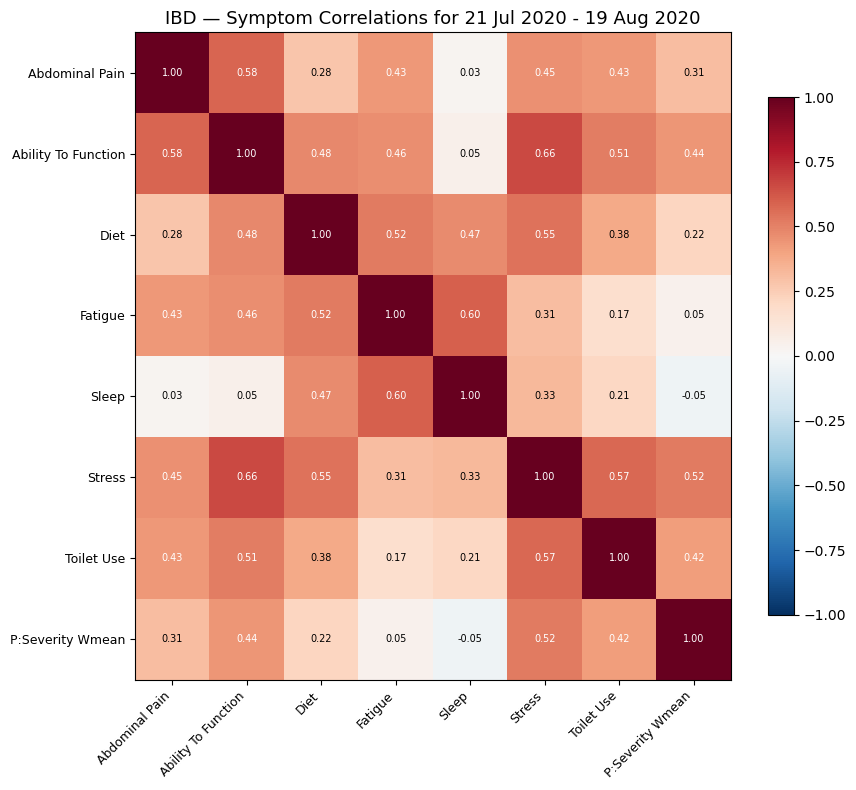


  STRONGEST SYMPTOM CORRELATIONS THIS PERIOD:
    Ability To Function  ↔ Stress                ρ=+0.664  (strongly move together)
    Fatigue              ↔ Sleep                 ρ=+0.595  (strongly move together)
    Abdominal Pain       ↔ Ability To Function   ρ=+0.582  (strongly move together)
    Stress               ↔ Toilet Use            ρ=+0.573  (strongly move together)
    Diet                 ↔ Stress                ρ=+0.546  (strongly move together)

  NOTABLE CHANGES FROM OVERALL PATTERN:
    Ability To Function  ↔ Stress                this period=+0.664  overall=+0.318  (stronger this period)
    Stress               ↔ P:Severity Wmean      this period=+0.518  overall=+0.241  (stronger this period)
    Diet                 ↔ Fatigue               this period=+0.517  overall=+0.169  (stronger this period)
    Abdominal Pain       ↔ Toilet Use            this period=+0.433  overall=+0.773  (weaker this period)
    Sleep                ↔ Stress                this period=+

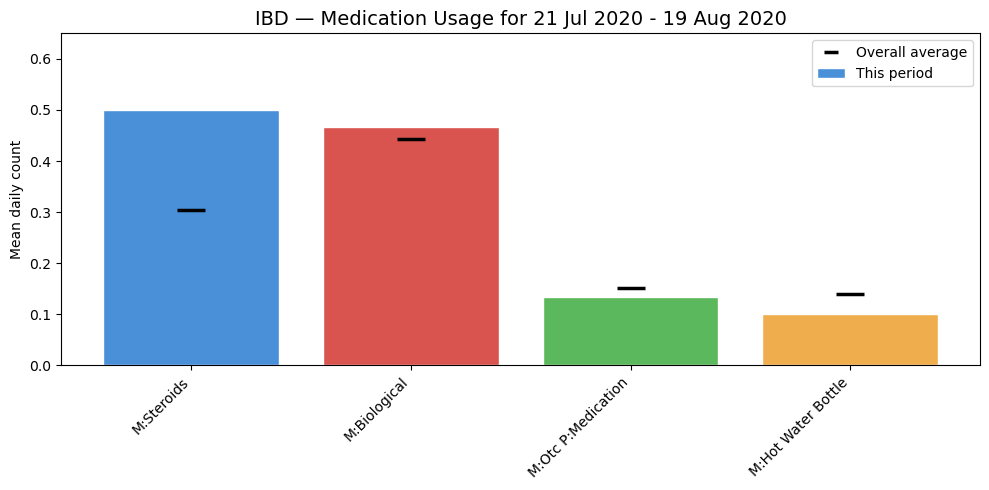


  WHAT YOU TRIED AND WHETHER IT HELPED:
  ──────────────────────────────────────────────────

    M:Biological (used on 14 of 30 days):
      Ability To Function    was higher on days you used it (1.4 vs 0.0) — but this likely means you reached for it on worse days, not that it made things worse.

    M:Steroids (used on 15 of 30 days):
      Next-day Ability To Function was better after using it (0.0 vs 1.6) — suggests a delayed benefit.
      Next-day Diet               was better after using it (0.0 vs 1.2) — suggests a delayed benefit.

    M:Otc P:Medication (used on 4 of 30 days):
      Abdominal Pain         was higher on days you used it (6.8 vs 0.9) — but this likely means you reached for it on worse days, not that it made things worse.
      Ability To Function    was higher on days you used it (4.5 vs 0.1) — but this likely means you reached for it on worse days, not that it made things worse.
      Diet                   was higher on days you used it (2.5 vs 0.1) — but th

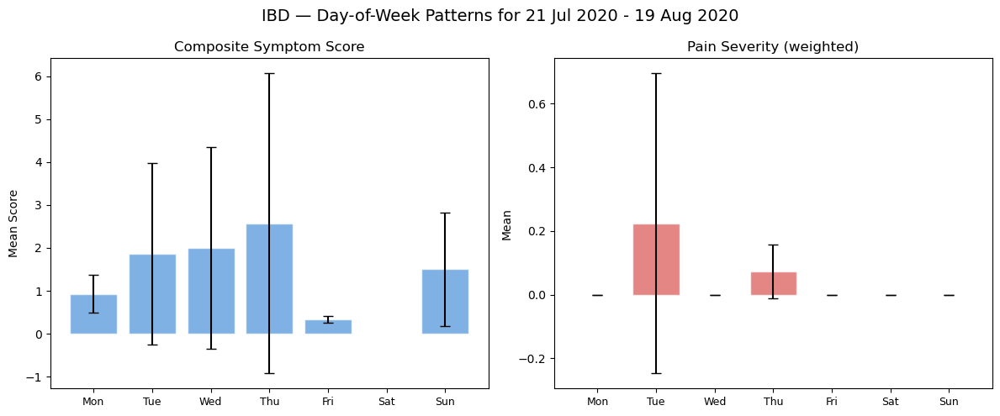

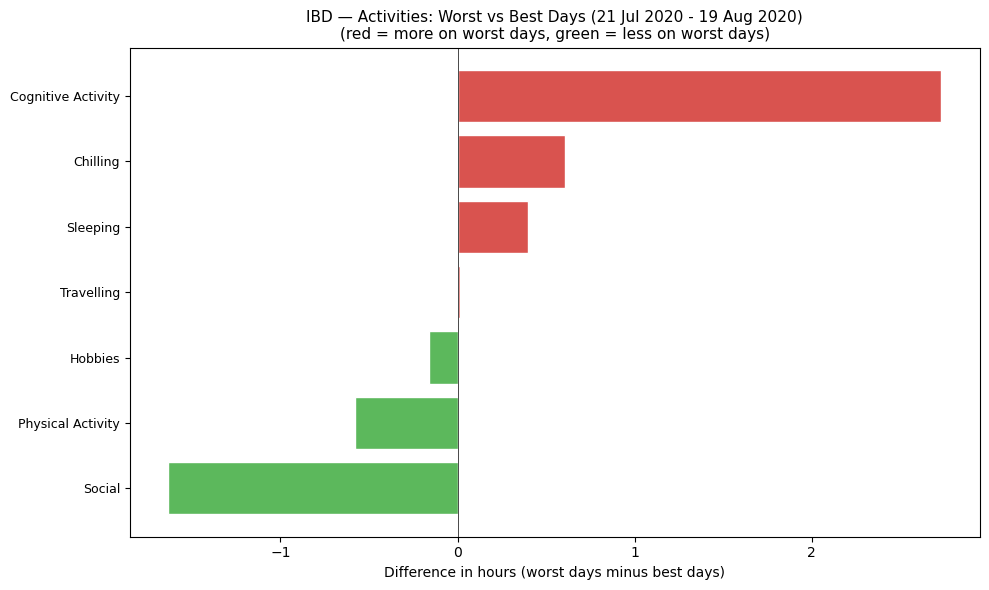


  ACTIVITIES ON WORST vs BEST DAYS:
  Activities associated with HIGHEST symptom scores:
    Cognitive Activity    +2.7h on worst days  p=0.405
    Chilling              +0.6h on worst days  p=0.405
    Sleeping              +0.4h on worst days  p=0.616
  Activities associated with LOWEST symptom scores:
    Social                -1.6h on worst days  p=0.189
    Physical Activity     -0.6h on worst days  p=0.188
    Hobbies               -0.2h on worst days  p=0.821


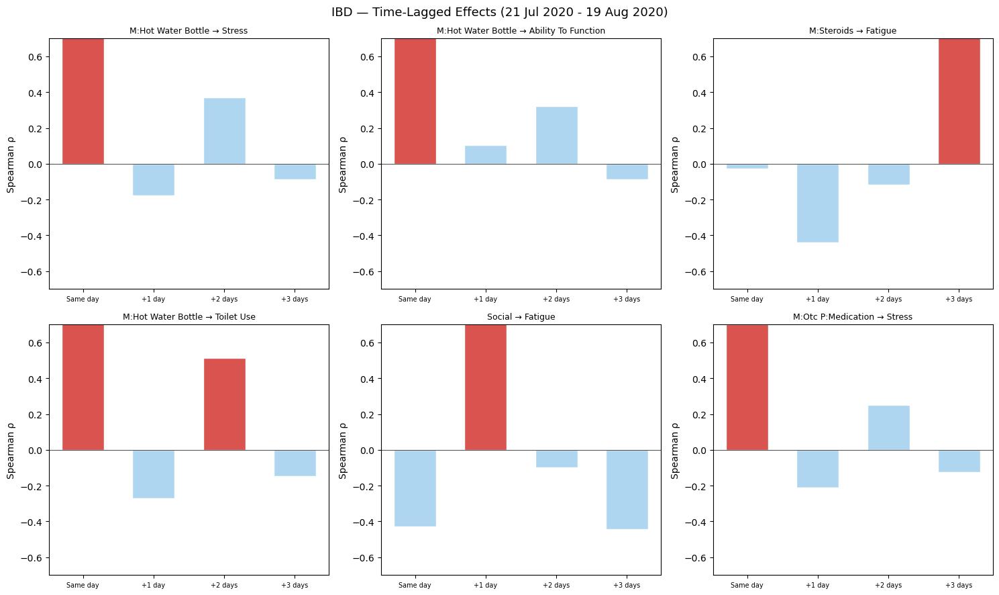


  TIME-LAGGED EFFECTS (strongest associations, p<0.1):
    M:Hot Water Bottle   → Stress                ρ=+0.855  same-day  (worse) *
    M:Hot Water Bottle   → Ability To Function   ρ=+0.812  same-day  (worse) *
    M:Steroids           → Fatigue               ρ=+0.772  after 3 day(s)  (worse) *
    M:Hot Water Bottle   → Toilet Use            ρ=+0.723  same-day  (worse) *
    Social               → Fatigue               ρ=+0.715  after 1 day(s)  (worse) *
    M:Otc P:Medication   → Stress                ρ=+0.703  same-day  (worse) *
    M:Otc P:Medication   → Ability To Function   ρ=+0.657  same-day  (worse) *
    Physical Activity    → Toilet Use            ρ=+0.647  after 1 day(s)  (worse) *
    M:Hot Water Bottle   → Abdominal Pain        ρ=+0.637  same-day  (worse) *
    M:Hot Water Bottle   → Diet                  ρ=+0.628  same-day  (worse) *
    Social               → Diet                  ρ=+0.595  after 1 day(s)  (worse) *
    M:Otc P:Medication   → Abdominal Pain        ρ=

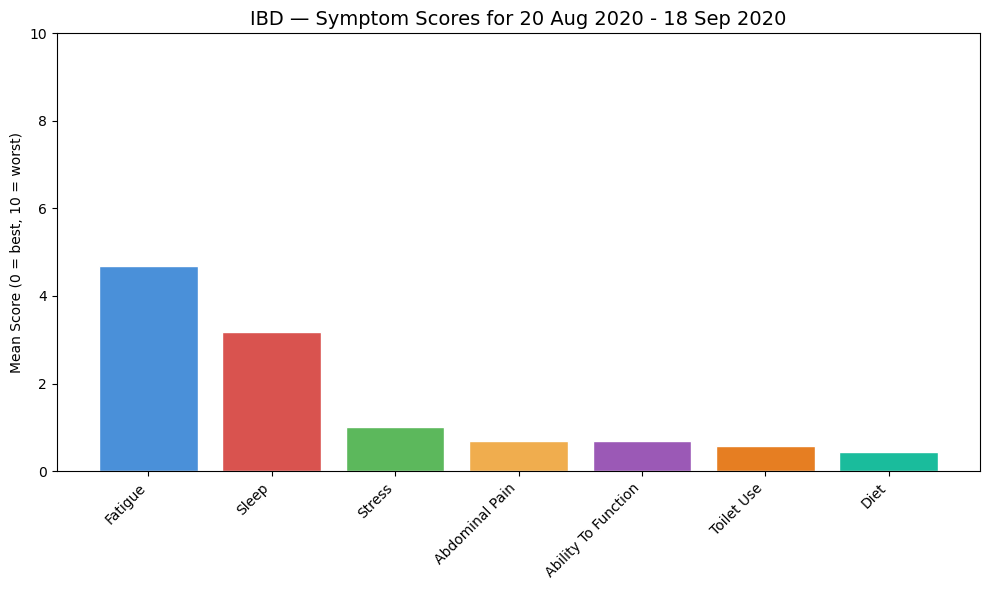

Symptoms with the highest scores in this period were Fatigue (4.7), Sleep (3.2), and Stress (1.0).

  Episode detection skipped — not enough data this period.


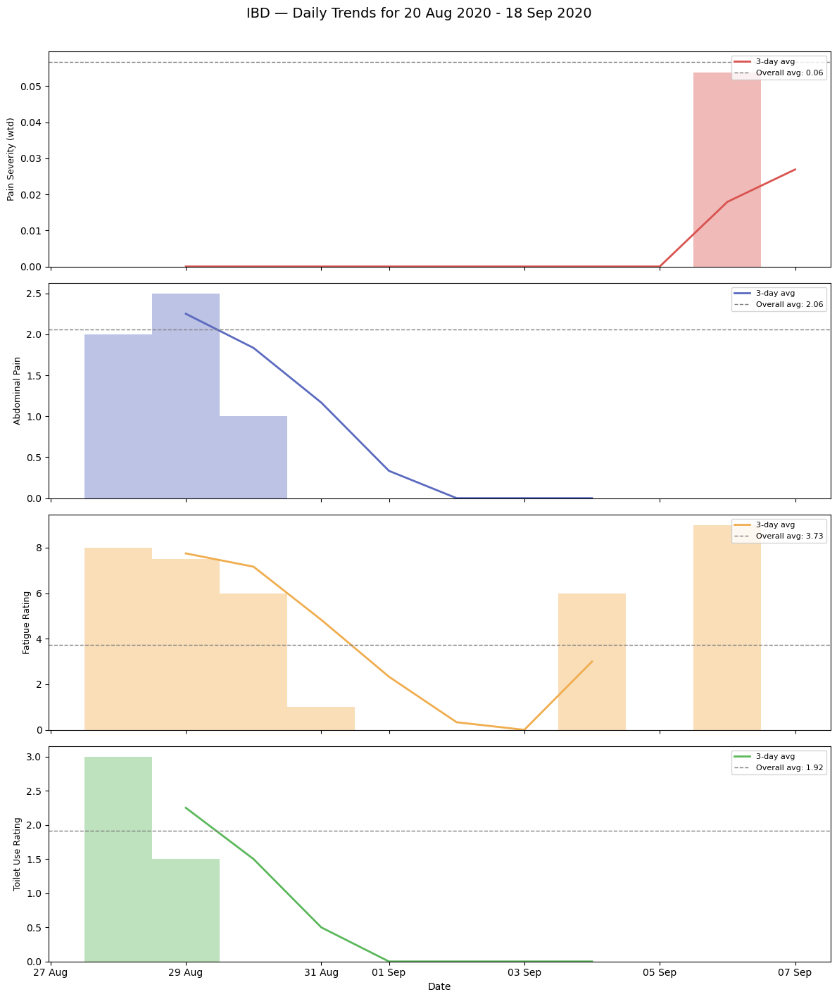

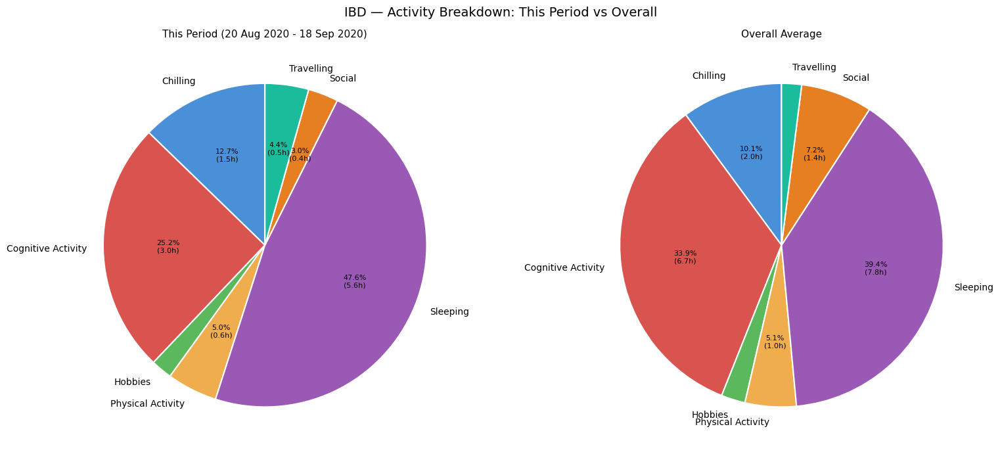

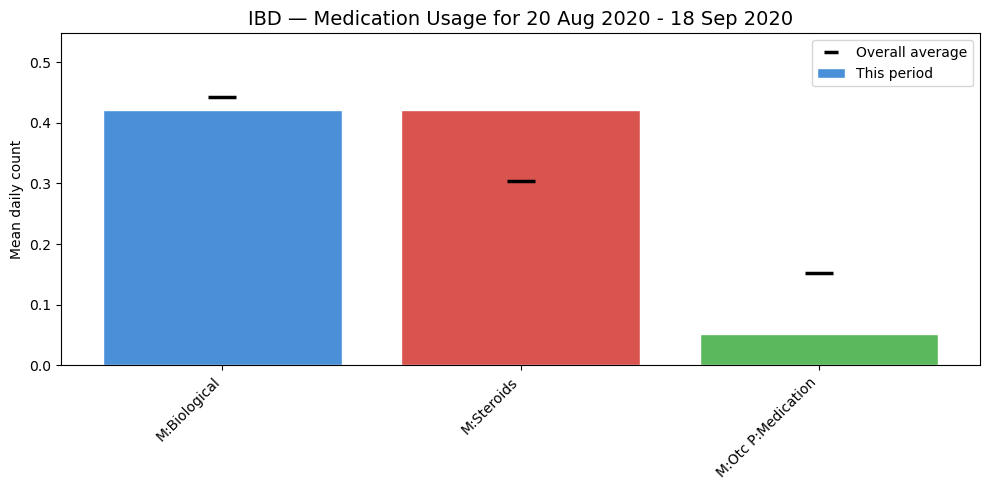


  WHAT YOU TRIED AND WHETHER IT HELPED:
  ──────────────────────────────────────────────────

    M:Biological (used on 8 of 19 days):

    M:Steroids (used on 8 of 19 days):

    M:Otc P:Medication: used on only 1 day(s) — not enough usage data to assess effectiveness yet. Keep logging when you use it.

  WHAT YOUR NOTES TELL US:
  ──────────────────────────────────────────────────
    You wrote 13 notes this period.
    • Mentioned 'fatigue' on 2 day(s)
    • Mentioned 'good day' on 2 day(s)
    • Mentioned 'abdominal pain' on 1 day(s)


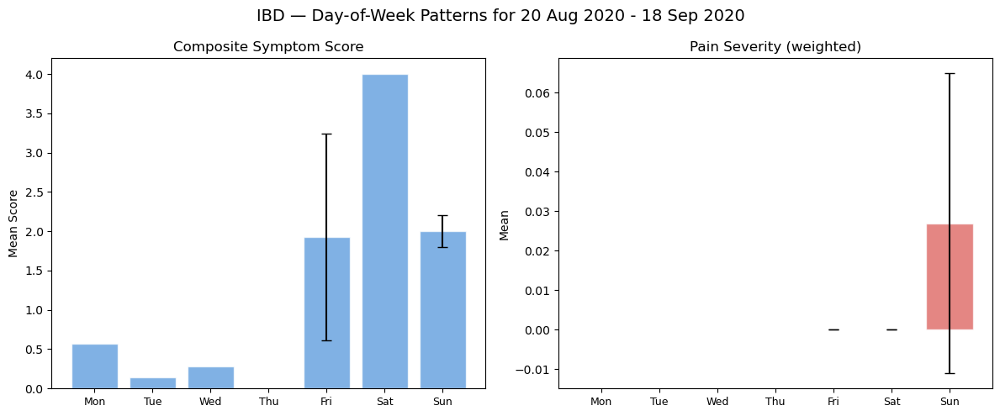


  Insufficient worst/best days for activity comparison (worst=0, best=9)

  Insufficient data for lag analysis in this period

  TRIGGERS OF PAIN SEVERITY (WEIGHTED):
    No significant triggers identified in this period

  RELIEVERS:
    No significant relievers identified in this period

  APPEARED TO HAVE NO SIGNIFICANT EFFECT ON SYMPTOMS:
    Cognitive Activity, Hobbies, Sleeping, M:Biological, M:Steroids, M:Otc P:Medication
    (all p>0.3)

  WITH REGARD TO PAIN SEVERITY (WEIGHTED):
    Travelling appeared to have most effect in exacerbation (ρ=+0.574, p=0.0829)

  COMPARED TO PREVIOUS 30-DAY WINDOW (21 Jul – 19 Aug):
    Abdominal Pain             prev=2.00  now=0.69  (-1.31, better)
    Ability To Function        prev=0.95  now=0.69  (-0.26, better)
    Diet                       prev=0.52  now=0.44  (-0.09, better)
    Fatigue                    prev=3.60  now=4.69  (+1.09, worse)
    Sleep                      prev=1.64  now=3.19  (+1.54, worse)
    Stress                    

C:\Users\cbc15\AppData\Local\Temp\ipykernel_832\633054355.py:648: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = stats.spearmanr(valid["x"], valid["y"])


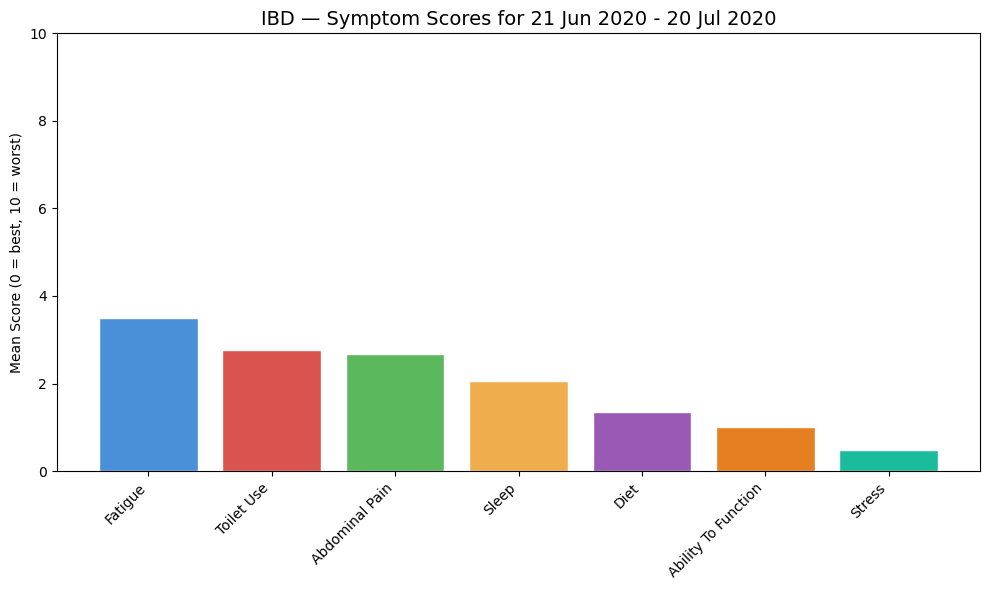

Symptoms with the highest scores in this period were Fatigue (3.5), Toilet Use (2.8), and Abdominal Pain (2.7).


KeyboardInterrupt: 

In [24]:
# RUN
# =========================================================================
if __name__ == "__main__":
    asthma = pd.read_csv("outputs/tiyga_daily_master.csv", parse_dates=["date"])
    ibd = pd.read_csv("outputs/ibd_daily_master.csv", parse_dates=["date"])

    print("\n\n>>> ASTHMA MONTHLY REPORTS <<<\n")
    generate_all_reports(asthma, ASTHMA_CONFIG, output_dir="outputs/asthma_monthly")

    print("\n\n>>> IBD MONTHLY REPORTS <<<\n")
    generate_all_reports(ibd, IBD_CONFIG, output_dir="outputs/ibd_monthly")